# ステージ3: サンプル処理（eptA oligo metatranscriptome）

FastQC/MultiQC → fastp → Bowtie2 → featureCounts → Salmon

過去プロジェクト（`230313_T19_33mix_metatranscriptome/1_trimmomatic_R.ipynb`、
`240704_T19_28strains_genome_hifiasm_metatranscriptome/3_2_featureCounts_R.ipynb`）と
同じ書き方（R、`list.files` → `seq_list` の data.frame、`system2()` 直書き）に沿う。

| 過去 | 今回 | 理由 |
|---|---|---|
| trimmomatic | **fastp** | CLAUDE.md §7。アダプター明示・poly-G 自動判定 |
| STAR | **Bowtie2** | CLAUDE.md §7。細菌にスプライシングは無い |
| `Rsubread::featureCounts` 3通り | **2通り**（按分 / ユニークのみ） | 株別 unique 率がステージ4のQC項目（CLAUDE.md §7） |

**検体**: W群 6（W1–W6）/ K群 5（K1–K4, K6。K5 は欠番）。150 bp PE、MGI/DNBSEQ、Azenta。

**進め方（(c) 案）**: fastp と FastQC/MultiQC までを11検体で流し、
Bowtie2 以降は W1 だけで試してから全検体に展開する。

## セル1: ライブラリ

In [1]:
library(dplyr)
library(tidyverse)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ readr     2.1.5
✔ ggplot2   3.5.1     ✔ stringr   1.6.0
✔ lubridate 1.9.4     ✔ tibble    3.3.1
✔ purrr     1.1.0     ✔ tidyr     1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## セル2: パスを置く

過去notebookと同じく、使うパスを先にまとめて変数にしておく。

- 生データは `/mnt/ext_hdd1`（使用率90%）にあるので、**出力はすべて `/mnt/scratch` 側に書く**
- リファレンスはステージ2（`3_build_reference.ipynb`）で作ったものを使う

In [41]:
# 生データ（Azenta からダウンロードしたもの。読むだけ）
path_seq = '/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine'

# 解析の作業ディレクトリ（中間ファイルが大きいので scratch 側）
path = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'

# notebook と小さい表を置く場所（git 管理側）
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'

# ステージ2 で作ったリファレンス
path_index = file.path(path, 'ref/bt2/oligo_eptA')      # bowtie2 index の prefix
path_gtf   = file.path(path, 'ref/oligo_eptA.gtf')      # 統合GTF（記録用。親CDSを含む）
path_gtf_count = file.path(path, 'ref/oligo_eptA_count.gtf')  # featureCounts 用（セル10 で作る）
path_salmonindex = file.path(path, 'ref/salmon')        # salmon index

# ステージ3 の出力先
path_trim    = file.path(path, 'trim')        # fastp の出力
path_fastqc  = file.path(path, 'fastqc')      # FastQC / MultiQC
path_bam     = file.path(path, 'bam')         # bowtie2 → samtools
path_count   = file.path(path, 'featureCounts')
path_salmon  = file.path(path, 'salmon_quant')
path_log     = file.path(path, 'logs')

for (d in c(path_trim, path_fastqc, path_bam, path_count, path_salmon, path_log)) {
    if(!dir.exists(d)) dir.create(d, recursive=TRUE)
}

# 外部ツール（notebook からは conda activate が効かないので絶対パスで叩く）
metatx  = '/home/tanoue/miniforge3/envs/metatx/bin'
fastp   = file.path(metatx, 'fastp')
fastqc  = file.path(metatx, 'fastqc')
multiqc = file.path(metatx, 'multiqc')
bowtie2 = file.path(metatx, 'bowtie2')
samtools= file.path(metatx, 'samtools')
salmon  = file.path(metatx, 'salmon')

nthreads = 32

# 確認
for (p in c(path_seq, path_index, path_gtf, path_salmonindex)) {
    cat(sprintf('%-80s %s\n', p, ifelse(file.exists(p) | dir.exists(p) |
        file.exists(paste0(p, '.1.bt2')), 'OK', '!! 無い')))
}

/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/bt2/oligo_eptA OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/oligo_eptA.gtf OK
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/salmon OK


## セル3: fq.gz ファイルを取得

過去notebook（`1_trimmomatic_R.ipynb` セル2）と同じく `list.files` で集める。
拡張子が `.fastq.gz` ではなく **`.fq.gz`**（MGI/Azenta の命名）。

In [3]:
# fq.gzファイルを取得
seq <- list.files(path_seq, pattern="\\.fq.gz$", recursive=T, full.names=T)
seq

[1] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K1-LJJ17560_L1_1.fq.gz"
 [2] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K1-LJJ17560_L1_2.fq.gz"
 [3] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K2-LJJ17561_L0_1.fq.gz"
 [4] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K2-LJJ17561_L0_2.fq.gz"
 [5] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K3-LJJ17562_L1_1.fq.gz"
 [6] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K3-LJJ17562_L1_2.fq.gz"
 [7] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K4-LJJ17563_L1_1.fq.gz"
 [8] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K4-LJJ17563_L1_2.fq.gz"
 [9] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K6-LJJ17565_L1_1.fq.gz"
[10] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K6-LJJ17565_L1_2.fq.gz"
[11] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W1-LJJ17554_L1_1.fq.gz"
[12] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W1-LJJ17554_L1_2.fq.gz"
[13] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W2-LJJ17555_L1_1.fq.gz"
[14] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W2-LJJ17555_L1_2.fq.gz"
[15] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W3-LJJ17556_L1_1.fq.gz"
[16] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W3-LJJ17556_L1_2.fq.gz"
[17] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W4-LJJ17557_L1_1.fq.gz"
[18] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W4-LJJ17557_L1_2.fq.gz"
[19] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W5-LJJ17558_L1_1.fq.gz"
[20] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W5-LJJ17558_L1_2.fq.gz"
[21] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W6-LJJ17559_L1_1.fq.gz"
[22] "/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W6-LJJ17559_L1_2.fq.gz"

## セル4: sampleごとに Fwd / Rev / name を1行にする

過去notebook（`1_trimmomatic_R.ipynb` セル3）と同じ作り。
`seq_list` が以降のループの基準になる。

ファイル名は `W1-LJJ17560_L1_1.fq.gz` の形なので、`"-"` の前（`W1`、`K1` など）を取り出し、
**接頭辞 `eptA` を付けて sample name にする**（`eptAW1`、`eptAK1` …）。

過去notebookは `str_split(Fwd$seq, "[/_]")` の8番目という**パスの階層に依存した位置指定**
だったが、今回はパスの深さが違うので `basename()` してから分割する。

群（W = eptA野生型 / K = eptA変異型）・ファイルサイズ・レーンも入れておく。
**K2 だけレーンが `L0`** で他は `L1`。深度やQCに差が出ていないかを後で確認する。

In [5]:
# sampleごとにfwd,rev,nameを1行にする
df_seq = as.data.frame(seq) %>% arrange(seq)          # dataframeへ変換
Fwd = df_seq %>% filter(grepl('_1.fq.gz', seq))       # R1が含まれるものをFwdへ
Rev = df_seq %>% filter(grepl('_2.fq.gz', seq))       # R2が含まれるものをRevへ

# ファイル名は W1-LJJ17560_L1_1.fq.gz の形。"-"の前（W1, K1 など）を取り出し、
# 接頭辞 eptA を付けて sample name にする（eptAW1, eptAK1 ...）
name = sapply(str_split(basename(Fwd$seq), "[-]"), `[`, 1)
name = paste0("eptA", name)

seq_list <- data.frame(Fwd, Rev, name)
colnames(seq_list) <- c('Fwd','Rev','name')

# 群（W=eptA野生型 / K=eptA変異型）とファイルサイズも入れておく
seq_list = seq_list %>%
    mutate(group    = ifelse(grepl('eptAW', name), 'WT', 'KO'),
           Fwd_GB   = round(file.size(Fwd)/1e9, 2),
           Rev_GB   = round(file.size(Rev)/1e9, 2),
           lane     = sapply(str_split(basename(Fwd), "[_]"), `[`, 2))

seq_list

Fwd,Rev,name,group,Fwd_GB,Rev_GB,lane
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K1-LJJ17560_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K1-LJJ17560_L1_2.fq.gz,eptAK1,KO,3.93,4.27,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K2-LJJ17561_L0_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K2-LJJ17561_L0_2.fq.gz,eptAK2,KO,3.09,3.34,L0
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K3-LJJ17562_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K3-LJJ17562_L1_2.fq.gz,eptAK3,KO,6.20,6.81,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K4-LJJ17563_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K4-LJJ17563_L1_2.fq.gz,eptAK4,KO,3.98,4.41,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K6-LJJ17565_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/K6-LJJ17565_L1_2.fq.gz,eptAK6,KO,3.08,3.35,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W1-LJJ17554_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W1-LJJ17554_L1_2.fq.gz,eptAW1,WT,3.87,4.24,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W2-LJJ17555_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W2-LJJ17555_L1_2.fq.gz,eptAW2,WT,3.58,3.92,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W3-LJJ17556_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W3-LJJ17556_L1_2.fq.gz,eptAW3,WT,3.00,3.30,L1
/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W4-LJJ17557_L1_1.fq.gz,/mnt/ext_hdd1/261013_eptAoligo_2wfeces_rnaseq/N2632465_60-1378878319_20261009122123/combine/W4-LJJ17557_L1_2.fq.gz,eptAW4,WT,3.61,3.98,L1


---
# FastQC / MultiQC（生データ）

**トリミングより先に生データの状態を見る**（CLAUDE.md §7 ステージ3 は
「FastQC/MultiQC → fastp」の順）。

fastp の JSON にも before/after の統計は入るが、メタトランスクリプトームで見たいのは
次の2つで、これらは fastp では十分に見えない。

| 見たいもの | 何が分かるか |
|---|---|
| **overrepresented sequences** | **rRNA の残存配列が直接見える。** 過去データでは rRNA が assigned read の 37〜56% を占めた（CLAUDE.md §6-3）。マッピング前に察知できる |
| **per-base sequence content** | ランダムプライマー由来の **5'端バイアス**（メタトランスクリプトームで頻出） |

## セル5: FastQC / MultiQC のバージョン確認

In [8]:
# FastQC と MultiQC のバージョン確認
system2(fastqc,  args = '--version', stdout = TRUE, stderr = TRUE)
system2(multiqc, args = '--version', stdout = TRUE, stderr = TRUE)

[1] "FastQC v0.13.0"

[1] "multiqc, version 1.35"

## セル6: FastQC（生データ）

**22ファイル・82 GB で 30〜60分かかる。**

FastQC は複数ファイルを引数に取れるので、**ループは使わず `seq_list$Fwd` と
`seq_list$Rev` を1本のベクタにまとめて一度に渡す**。
`--threads 11` でファイル数分並列にする。

**既にできている分は除いてから渡す。** FastQC は入力 `K1-LJJ17560_L1_1.fq.gz` から
`K1-LJJ17560_L1_1_fastqc.zip` を作るので、その有無で判定する。
途中で止まっても（接続が切れても）上から流し直せる。

In [23]:
# FastQC（生データ。22ファイル・82GB で 30〜60分）
# trim 前に生データの状態を見ておく。メタトランスクリプトームで見たいのは
#   ・overrepresented sequences  → rRNA の残存配列が直接見える
#   ・per-base sequence content  → ランダムプライマー由来の5'端バイアス
# の2つ。これらは fastp の JSON では十分に見えない

path_fastqc_raw = file.path(path_fastqc, 'raw')
if(!dir.exists(path_fastqc_raw)) dir.create(path_fastqc_raw, recursive=TRUE)

# seq_list の Fwd と Rev を1本のベクタにまとめて、まとめて渡す
#   （FastQC は複数ファイルを引数に取れるので、ループは使わない）
fq_raw = c(seq_list$Fwd, seq_list$Rev)
length(fq_raw)

# 既にできている分は除く（途中で止めても流し直せるように）
#   FastQC は入力 K1-LJJ17560_L1_1.fq.gz から K1-LJJ17560_L1_1_fastqc.zip を作る
zip_expected = paste0(sub("\\.fq\\.gz$", "", basename(fq_raw)), "_fastqc.zip")
zip_done     = list.files(path_fastqc_raw, pattern="_fastqc\\.zip$")
fq_todo      = fq_raw[!(zip_expected %in% zip_done)]

cat(sprintf("入力 %d ファイル / 済み %d / これから %d\n",
            length(fq_raw), sum(zip_expected %in% zip_done), length(fq_todo)))

Sys.time()

if (length(fq_todo) == 0) {
    cat("すべて完了済みなので FastQC は実行しません\n")
} else {
    system2(fastqc, args = c('--outdir', path_fastqc_raw,
                             '--threads', 11,      # ファイル数分並列にする
                             '--quiet',
                             fq_todo),
            stdout = TRUE, stderr = TRUE)
}

Sys.time()

# できたレポートを確認
list.files(path_fastqc_raw, pattern="\\.zip$")

[1] 22

入力 22 ファイル / 済み 22 / これから 0


[1] "2026-10-20 23:45:25 JST"

すべて完了済みなので FastQC は実行しません


[1] "2026-10-20 23:45:25 JST"

[1] "K1-LJJ17560_L1_1_fastqc.zip" "K1-LJJ17560_L1_2_fastqc.zip"
 [3] "K2-LJJ17561_L0_1_fastqc.zip" "K2-LJJ17561_L0_2_fastqc.zip"
 [5] "K3-LJJ17562_L1_1_fastqc.zip" "K3-LJJ17562_L1_2_fastqc.zip"
 [7] "K4-LJJ17563_L1_1_fastqc.zip" "K4-LJJ17563_L1_2_fastqc.zip"
 [9] "K6-LJJ17565_L1_1_fastqc.zip" "K6-LJJ17565_L1_2_fastqc.zip"
[11] "W1-LJJ17554_L1_1_fastqc.zip" "W1-LJJ17554_L1_2_fastqc.zip"
[13] "W2-LJJ17555_L1_1_fastqc.zip" "W2-LJJ17555_L1_2_fastqc.zip"
[15] "W3-LJJ17556_L1_1_fastqc.zip" "W3-LJJ17556_L1_2_fastqc.zip"
[17] "W4-LJJ17557_L1_1_fastqc.zip" "W4-LJJ17557_L1_2_fastqc.zip"
[19] "W5-LJJ17558_L1_1_fastqc.zip" "W5-LJJ17558_L1_2_fastqc.zip"
[21] "W6-LJJ17559_L1_1_fastqc.zip" "W6-LJJ17559_L1_2_fastqc.zip"

## セル7: MultiQC（生データ）

11検体分の FastQC を1枚の HTML にまとめる。
`fastqc/raw/multiqc_raw.html` をブラウザで開いて確認する。

MultiQC は HTML の他に、**解析用のテキストを `multiqc_raw_data/` に書き出す**。
HTML は目で見る用、テキストは数値で判断する用。セル7-2 以降でこれを R に読み込んで表にする。

**HTML で見るべき点**
- Sequence Counts — 検体間の深度の差
- Per Base Sequence Quality — Q30 が後半で落ちていないか
- **Overrepresented Sequences — rRNA 由来の配列が上位に来ていないか**
- **Per Base Sequence Content — 最初の10〜15 bp で4塩基の比率が偏っていないか**
- Adapter Content — アダプターの残存量（fastp 前なので残っているのが正常）

In [24]:
# MultiQC（生データの FastQC をまとめる）
# MultiQC はログを大量に吐くので、戻り値を log に受けて要点（INFO 行）だけ出す。
# 色コード（\033[...m）が混ざるので外してから表示する
log = system2(multiqc, args = c(path_fastqc_raw,
                                '--outdir', path_fastqc_raw,
                                '--filename', 'multiqc_raw',
                                '--force'),
              stdout = TRUE, stderr = TRUE)

cat(gsub("\033\\[[0-9;]*m", "", grep("INFO", log, value = TRUE)), sep = "\n")

# 生成物の確認。multiqc_raw.html をブラウザで開いて目でも見る
list.files(path_fastqc_raw, pattern = "multiqc")

[1] "multiqc_raw_data" "multiqc_raw.html"

## セル7-2: QC値を検体ごとの表にする

`multiqc_raw_data/` のテキストを読んで、1枚の data.frame にまとめる。
読むのは3つのファイル。

| ファイル | 取る値 |
|---|---|
| `multiqc_fastqc.txt` | 深度（Total Sequences）、GC%、重複率 |
| `fastqc_overrepresented_sequences_plot.txt` | overrepresented sequences の割合 |
| `fastqc_per_base_sequence_quality_plot.txt` | サイクルごとの平均クオリティ |

**`total_deduplicated_percentage` は「重複を除いたら何%残るか」**なので、
100 から引いて重複率（`dup_pct`）にする。

クオリティの値は `"(150, 38.996)"` という**文字列**で入っている（位置, 平均Q の組）。
カンマの後ろの数値だけ取り出して、検体ごとに全サイクルの平均（`Q_mean`）と
最低（`Q_min`）にする。

**出てくる表の列**

| 列 | 中身 |
|---|---|
| `name` / `group` | 検体名（`eptAW1` …）と群（`WT` / `KO`） |
| `read` | `R1` / `R2` |
| `reads_M` | 深度（M read pairs） |
| `GC_pct` | GC含量（%） |
| `Q_mean` / `Q_min` | 全サイクルの平均Q / 最低サイクルのQ |
| `dup_pct` | 重複率（`100 - total_deduplicated_percentage`） |
| `ov_pct` | overrepresented sequences の割合（上位1本 + 残りの合計） |

FastQC のファイル名（`K1-LJJ17560_L1_1`）から `"-"` の前を取って `eptA` を付け、
`seq_list` の `name` と突き合わせて群も入れる。

In [25]:
# ── 検体ごとのQC値を1枚の表にする ──────────────────────────────
# MultiQC は HTML の他に、解析用のテキストを multiqc_raw_data/ に書き出している。
# それを読んで数値の表にする（HTML を目で見るより、後の判断に使いやすい）
path_mqc_data = file.path(path_fastqc_raw, 'multiqc_raw_data')

# 深度・GC・重複率。total_deduplicated_percentage は「重複を除いたら何%残るか」なので
# 100 から引いて重複率にする
qc = read.table(file.path(path_mqc_data, 'multiqc_fastqc.txt'),
                sep="\t", header=TRUE, check.names=FALSE, quote="")

# overrepresented sequences の割合（上位1本 + 残りの合計）は別ファイル
ov = read.table(file.path(path_mqc_data, 'fastqc_overrepresented_sequences_plot.txt'),
                sep="\t", header=TRUE, check.names=FALSE, quote="")
colnames(ov) = c('Sample', 'ov_top_pct', 'ov_rest_pct')

# サイクルごとの平均クオリティ。値が "(150, 38.996)" という文字列なので
# カンマの後ろの数値（= その位置の平均Q）だけ取り出す
pbq = read.table(file.path(path_mqc_data, 'fastqc_per_base_sequence_quality_plot.txt'),
                 sep="\t", header=TRUE, check.names=FALSE, quote="")
pbq = pbq %>%
    pivot_longer(-Sample, names_to="i", values_to="v") %>%
    mutate(qual = as.numeric(str_match(v, ",\\s*([0-9.]+)\\)")[,2])) %>%
    group_by(Sample) %>%
    summarise(Q_mean = round(mean(qual), 1), Q_min = round(min(qual), 1))

# FastQC のファイル名（K1-LJJ17560_L1_1）から sample name（eptAK1）と R1/R2 を作る
qc = qc %>%
    left_join(ov,  by="Sample") %>%
    left_join(pbq, by="Sample") %>%
    mutate(name = paste0("eptA", sapply(str_split(Sample, "[-]"), `[`, 1)),
           read = ifelse(grepl("_1$", Sample), "R1", "R2"),
           reads_M = round(`Total Sequences`/1e6, 1),
           dup_pct = round(100 - total_deduplicated_percentage, 1),
           ov_pct  = round(ov_top_pct + ov_rest_pct, 1)) %>%
    left_join(seq_list %>% dplyr::select(name, group), by="name") %>%
    dplyr::select(name, group, read, reads_M, GC_pct = `%GC`, Q_mean, Q_min, dup_pct, ov_pct) %>%
    arrange(name, read)

qc

name,group,read,reads_M,GC_pct,Q_mean,Q_min,dup_pct,ov_pct
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAK1,KO,R1,59.3,47,39.3,39.0,84.6,16.4
eptAK1,KO,R2,59.3,47,39.4,38.9,89.7,17.1
eptAK2,KO,R1,46.3,48,39.3,38.9,81.3,15.3
eptAK2,KO,R2,46.3,48,39.4,38.9,85.7,16.7
eptAK3,KO,R1,90.8,47,39.3,39.0,82.7,10.2
eptAK3,KO,R2,90.8,46,39.4,38.9,88.2,9.6
eptAK4,KO,R1,58.1,47,39.4,39.0,81.0,10.3
eptAK4,KO,R2,58.1,47,39.4,38.8,86.7,9.8
eptAK6,KO,R1,44.6,48,39.3,39.0,80.2,12.2


## セル7-3: pass / warn / fail を項目ごとに数える

`multiqc_fastqc.txt` の後半10列が FastQC 各項目の判定（`pass` / `warn` / `fail`）。
22ファイル（11検体 × R1/R2）分を項目ごとに集計して、
**どの項目が引っかかっているのか**を見る。

メタトランスクリプトームでは **fail が出て当然の項目がある**（GC content、
duplication、overrepresented）。それ以外の項目が fail していないかを確認するのが目的。

In [26]:
# ── FastQC の pass / warn / fail を項目ごとに数える ────────────
# multiqc_fastqc.txt の後半10列が FastQC 11項目（Basic Statistics 以下）の判定。
# 22ファイル（11検体 × R1/R2）分を項目ごとに集計する
st = read.table(file.path(path_mqc_data, 'multiqc_fastqc.txt'),
                sep="\t", header=TRUE, check.names=FALSE, quote="") %>%
    dplyr::select(Sample, basic_statistics:adapter_content) %>%
    pivot_longer(-Sample, names_to="項目", values_to="判定")

st %>%
    group_by(項目, 判定) %>% tally() %>%
    pivot_wider(names_from=判定, values_from=n, values_fill=0) %>%
    dplyr::select(項目, any_of(c('pass','warn','fail'))) %>%
    as.data.frame()

項目,pass,warn,fail
<chr>,<int>,<int>,<int>
adapter_content,1,21,0
basic_statistics,22,0,0
overrepresented_sequences,0,5,17
per_base_n_content,22,0,0
per_base_sequence_content,0,10,12
per_base_sequence_quality,22,0,0
per_sequence_gc_content,0,0,22
per_sequence_quality_scores,22,0,0
sequence_duplication_levels,0,0,22


## セル7-4: overrepresented sequences の上位配列

`fastqc_top_overrepresented_sequences_table.txt` に、全検体を通した上位配列が入っている。

**`検出された検体数` が 11（= 全検体）なら、検体ごとの汚染ではなく
全検体に共通する高発現の単一遺伝子座** — つまり rRNA を疑う。
逆に一部の検体だけに出る配列なら、その検体固有の問題（アダプター二量体、
コンタミ）を疑う。

In [27]:
# ── overrepresented sequences の上位を見る（rRNA の確認）──────
# 全11検体で共通して出る配列（Reports = 11）なら、検体ごとの汚染ではなく
# 高発現の単一遺伝子座 = rRNA を疑う
ovseq = read.table(file.path(path_mqc_data, 'fastqc_top_overrepresented_sequences_table.txt'),
                   sep="\t", header=TRUE, check.names=FALSE, quote="")
colnames(ovseq) = c('配列', '検出された検体数', 'read数', '全readに対する%')

ovseq %>%
    arrange(desc(read数)) %>%
    mutate(read数 = format(read数, big.mark=","),
           `全readに対する%` = round(`全readに対する%`, 3)) %>%
    head(10)

,配列,検出された検体数,read数,全readに対する%
,<chr>,<int>,<chr>,<dbl>
1,CTGGATTTGACAGCGGGCAGAAATGGTAAGTAAGCATGCAGTGCGTCGTT,11,"12,588,564",1.028
2,GAAATGGTAAGTAAGCATGCAGTGCGTCGTTGATTTGCACTTTAATCTCA,11,"7,922,440",0.647
3,GGAAATCATAAGCTTTCTACATGCTTATCTTTGCCTAAATTTTCGTGCAG,11,"5,625,760",0.460
4,CCCGATTTGACTGCACCACTTTATCGGAATGCTTCGGAGCAACAGCTTCC,11,"5,330,018",0.435
5,GCCGGGTTCTGTTCTTCTGTTTCTGAAAAAGCCTAATTAGGAATTATCCA,11,"5,063,421",0.414
6,GCCTTATCCTCTAAATTTTCACCCGCGCCACGAGGCTGACACGAACTATC,11,"4,430,880",0.362
7,CTAAATTTTCACCCGCGCCACGAGGCTGACACGAACTATCCCCGATTTGA,11,"4,288,988",0.350
8,CTAAATTTTCGTGCAGCGGCAGAACCAAAGCCATCAACCGTTGCCTTATC,11,"3,197,151",0.261
9,CCCCGATTTGACTGCACCACTTTATCGGAATGCTTCGGAGCAACAGCTTC,11,"2,912,650",0.238


### 考察: 生データのQC（セル7-2〜7-4 の結果）

結論から言うと、**11検体すべて fastp の既定設定で進めて問題ない。**
FastQC の fail はすべてメタトランスクリプトームで出て当然の項目に限られていた。

#### 1. 深度 — 設計どおり

43.6M（eptAW3）〜90.8M（eptAK3）read pairs。**2.1倍の開き**がある（CLAUDE.md §1 記載と一致）。
CLAUDE.md §7 の要求は「rRNA残存50%を前提に mRNA換算 40〜60M read/sample」なので、
総read数としては全検体が下限を満たしている。ただし **rRNA の実残存率が50%を大きく超えると
最小の W3・K6（44M前後）は mRNA が 20M read台に落ちる**。
実際の rRNA 率はマッピング後（ステージ4）に確定するので、そこで再評価する。

深度差そのものは DESeq2 が size factor で吸収するため、DE解析上の問題にはならない。

#### 2. クオリティ — 問題なし

全サイクルの平均Qが 39.3〜39.4、**最低のサイクルでも 38.7**。
150 bp の最後まで落ちていない（MGI/DNBSEQ らしい値）。
`per_base_sequence_quality` と `per_sequence_quality_scores` は 22/22 ファイルで pass。
→ **品質トリムを強める必要はない**（fastp 既定のままでよい）。

#### 3. GC含量 — fail だが想定どおり

46〜48%。`per_sequence_gc_content` が 22/22 で **fail** だが、これは
FastQC が「単一ゲノムの正規分布」を期待しているため。
4株混合（Bth 42〜43%、Bun 46%、Odo 42%）＋ rRNA の高発現で分布が多峰になるのは必然。
**異常ではない。**

同じ理由で `per_base_sequence_content` も fail 12 / warn 10。
ランダムプライマー由来の5'端バイアスが出ているが、fastp で削る必要はない
（Bowtie2 はローカルアラインメントではなくend-to-endで使うが、
5'端の数塩基のバイアスはミスマッチにならずQ値も高いので影響しない）。

#### 4. 重複率 80〜90% — 想定どおり。だから重複除去をしない

R1 が 80.2〜84.6%、R2 が 84.6〜89.7%。`sequence_duplication_levels` は 22/22 で fail。

これは **RNA-seq では正常**。rRNA と高発現遺伝子が同じ配列を正当に大量に生むため、
深度が上がるほど重複率も上がる。
**CLAUDE.md §6-5 が「重複除去（Picard MarkDuplicates 等）をしない」と決めている理由がこれ。**
ここで重複除去を入れると、高発現遺伝子の発現量だけが人為的に潰れる。

#### 5. overrepresented sequences — rRNA が見えている

| 検体 | overrepresented の割合（R1/R2） |
|---|---|
| eptAK1 | 16.4 / 17.1% |
| eptAW6 | 16.4 / 17.2% |
| eptAK2 | 15.3 / 16.7% |
| 他8検体 | 8.6 〜 12.2% |

上位10配列は**すべて「検出された検体数 = 11」**、つまり全検体に共通。
検体固有の汚染やアダプター二量体ではなく、**高発現の単一遺伝子座 = rRNA 由来**と判断できる。
最上位の1本だけで全readの 1.03% を占める。

注意: **この 8.6〜17.2% は rRNA の実残存率ではない。** FastQC の overrepresented は
「全体の 0.1% を超える完全一致配列」しか数えないので、1塩基でも違う rRNA 断片は
この集計から漏れる。CLAUDE.md §6-3 の過去データ（rRNA が assigned read の 37〜56%）
との比較は、ステージ4でマッピング結果を見てから行う。

K1・K2・W6 の3検体で他より5ポイント高いのは、**rRNA除去（Ribo-Zero等）の効率差**を
示唆する。この3検体は mRNA 換算の実効深度が他より低い可能性があるので、
ステージ4の rRNA 率で必ず確認する。

#### 6. アダプター — fastp で除く

`adapter_content` は warn 21 / pass 1。fastp 前なので残っているのが正常。
セル9の fastp で `--adapter_sequence` / `--adapter_sequence_r2` を明示して除く。

#### まとめ: fastp の設定判断

| 検討した項目 | 判断 |
|---|---|
| 品質トリムを強める | **不要**（Q_min 38.7。既定のまま） |
| 最短長 | `--length_required 50`（CLAUDE.md §7 のまま） |
| 5'端のトリム | **不要**（per_base_sequence_content の偏りは影響しない） |
| 重複除去 | **しない**（CLAUDE.md §6-5） |
| rRNA のin silico除去 | ここではしない。マッピング後に rRNA 遺伝子のカウントを除外する方針（CLAUDE.md §6-3） |

→ **セル9（fastp）は書いてある設定のまま11検体に流す。**

---
# fastp（時間かかる）

過去notebook（`1_trimmomatic_R.ipynb`）では trimmomatic を使っていたが、
CLAUDE.md §7 に従って **fastp** に変える。

| 項目 | trimmomatic（過去） | fastp（今回） |
|---|---|---|
| アダプター | `ILLUMINACLIP:adapter_illumina.txt:2:30:10` | `--adapter_sequence` / `--adapter_sequence_r2` で明示 |
| 品質トリム | `SLIDINGWINDOW:4:20 LEADING:20 TRAILING:20` | 既定のまま（指定しない） |
| 最短長 | `MINLEN:30` | `--length_required 50`（CLAUDE.md §7） |
| poly-G | なし | 自動判定（指定しない） |
| レポート | なし | **JSON / HTML を検体ごとに出力**（セル7でQC表にする） |

## セル8: fastp のバージョン確認

過去notebook（セル6）の `system2(trimmomatic, args='-version')` と同じ。

In [28]:
# fastp のバージョン確認（過去notebookの trimmomatic -version と同じ）
system2(fastp, args = '--version', stdout = TRUE, stderr = TRUE)

[1] "fastp 1.4.0"

## セル9: fastp を実行

過去notebook（セル7）の trimmomatic ループと同じ形。
**出力名も踏襲して `_forward_cleaned.fq.gz` / `_reverse_cleaned.fq.gz`** にする
（後のセルで `grepl('forward', ...)` で拾えるようにするため。
過去notebook `2_index_STAR_...` のセル33-34 が同じやり方）。

### アダプターは「3'端だけ」除去する

ライブラリの分子は**両端にアダプターが付いている**が、**5'側は読まれないので除去する対象がない。**

アダプターはシーケンス用プライマーが結合する足場でもあり、シーケンスはそのプライマーの
3'端から先に伸びる。つまり **読み始めの1塩基目はインサート（cDNA）の1塩基目**になる。

```
  [P5]-[i5]-[Read1プライマー結合部位] - インサート(cDNA) - [Read2プライマー結合部位]-[i7]-[P7]
  |<------- 読まれない（足場）------>|                   |<--- 150bp以内に到達すると
                                     ^                        読み込んでしまう部分 --->|
                                     1塩基目はここ
                                     （= インサートの先頭）

  Read 1 :                           ====================>
  Read 2 :                                      <====================
```

| 位置 | 読まれるか | 除去 |
|---|---|---|
| **5'側** | プライマーの足場なので配列として出力されない | **不要** |
| **3'側** | インサートが 150 bp より短いと読み切って到達する | **これがセル9-2 の `adapter_pct`（7.7〜11.9%）** |

FastQC の Adapter Content モジュールが 3'端だけを見ているのも同じ理由。

**実データでの確認**（eptAK1 の R1、先頭100万リード）

| 検査 | 該当リード数 |
|---|---|
| 先頭が `AGATCGGAAGAGC`（3'側アダプターの頭） | **0 本** |
| 先頭が `ACACTCTTTCCCTACACGACGCTCTTCCGATCT`（Read1 プライマー配列） | **0 本** |
| 先頭が `AAGTCGGAGGCCAAGCGGTC`（MGI アダプター） | **0 本** |
| 比較: `AGATCGGAAGAGC` をリード中に含む | 74,405 本（7.4%） |

先頭10塩基の内訳も `CTAAATTTTC` / `GGAAATCATA` / `GCCTTATCCT` … と生物由来の配列で
（セル7-4 の overrepresented 上位配列 = rRNA の頭と同じ）、アダプターは一切ない。
**5'端にはゼロ、3'端には7.4%** という非対称がはっきり出ている。

**混同しやすい点**: セル7-3 で `per_base_sequence_content` が fail / warn になっていた
**5'端 10〜15 bp の塩基組成の偏りは、アダプターではない。**
逆転写のランダムヘキサマーが結合しやすい配列に偏ることによるもので、cDNA そのものの配列
（アダプターと違い生物由来なのでマッピングできる）。
だからセル7-2 の考察で「5'端のトリムは不要」と判断している。

### 指定したアダプター配列について

生リードのヘッダは `@ML150031534L1C001R02800002517/1` で、
これは **MGI/DNBSEQ の命名**（CLAUDE.md §1 の記載どおり）。
一方 fastp に渡しているのは **Illumina TruSeq のアダプター配列**で、これは矛盾ではない。
プラットフォームが DNBSEQ でも、ライブラリが Illumina 互換アダプターで作られていれば
読まれる配列は TruSeq になる。**「DNBSEQ だから MGI のアダプターを指定すべき」ではない。**
実際に指定が当たっていたかはセル9-2 の `adapter_pct` と、
JSON の `adapter_cutting$read1_adapter_counts` で確認できる（セル9-4 のあとの考察に記載）。

既にできている検体は飛ばすので、途中で止めても上から流し直せる。

**11検体で合計82 GB。1〜2時間かかる。**
`--thread` は 16 にしている（fastp は gzip の読み書きが律速なので、
それ以上スレッドを増やしても速くならない）。

In [29]:
# fastp（11検体で合計82GB。1〜2時間かかる）
# 過去notebookの trimmomatic ループと同じ形。出力名も踏襲して
# _forward_cleaned.fq.gz / _reverse_cleaned.fq.gz にする
# （後のセルで grepl('forward', ...) で拾えるようにするため）

Sys.time()

for (i in 1:nrow(seq_list)) {
    out_fwd  = paste0(path_trim, "/", seq_list[i, 'name'], "_forward_cleaned.fq.gz")
    out_rev  = paste0(path_trim, "/", seq_list[i, 'name'], "_reverse_cleaned.fq.gz")
    out_json = paste0(path_trim, "/", seq_list[i, 'name'], "_fastp.json")
    out_html = paste0(path_trim, "/", seq_list[i, 'name'], "_fastp.html")

    # 既にできているものは飛ばす（途中で止めても上から流し直せるように）
    if (file.exists(out_fwd) & file.exists(out_rev) & file.exists(out_json)) {
        cat(sprintf("[スキップ] %s\n", seq_list[i, 'name']))
        next
    }

    cat(sprintf("[%s] %s を処理中...\n", format(Sys.time(), "%H:%M:%S"), seq_list[i, 'name']))

    system2(fastp, args = c('-i', seq_list[i, 'Fwd'], '-I', seq_list[i, 'Rev'],
                            '-o', out_fwd, '-O', out_rev,
                            # CLAUDE.md §1 のアダプター配列を明示する
                            #   P7 read1 / P5 read2。MGI でも配列は Illumina と同じ
                            '--adapter_sequence',    'AGATCGGAAGAGCACACGTCTGAACTCCAGTCA',
                            '--adapter_sequence_r2', 'AGATCGGAAGAGCGTCGTGTAGGGAAAGAGTGT',
                            '--length_required', 50,          # CLAUDE.md §7
                            '--json', out_json, '--html', out_html,
                            '--thread', 16),                  # fastp の上限は16
             stdout = TRUE, stderr = TRUE)
}

Sys.time()

[1] "2026-10-20 23:56:57 JST"

[スキップ] eptAK1
[スキップ] eptAK2
[スキップ] eptAK3
[スキップ] eptAK4
[スキップ] eptAK6
[スキップ] eptAW1
[スキップ] eptAW2
[スキップ] eptAW3
[スキップ] eptAW4
[スキップ] eptAW5
[スキップ] eptAW6


[1] "2026-10-20 23:56:57 JST"

## セル9-2: fastp の結果を表にする

fastp は検体ごとに JSON と HTML を出している。**HTML は目で見る用、JSON は数値を取る用。**
JSON から主要な数値を取り出して1枚の表にする。

注意: **JSON の `total_reads` は R1+R2 の合計本数**（ペア数ではない）。
2で割ってペア数にする。割合の計算（`keep_pct` など）は分母・分子ともリード本数なので
そのままでよい。

| 列 | 中身 |
|---|---|
| `before_Mp` / `after_Mp` | trim前 / trim後の深度（M read pairs） |
| `keep_pct` | 残存率（trim後 / trim前） |
| `lowQ_pct` | 品質で除去されたリードの割合 |
| `short_pct` | 50 bp 未満になって除去されたリードの割合 |
| `adapter_pct` | **末端にアダプター配列が見つかって削られたリードの割合**（全リード = R1+R2 に対する%） |
| `len1` / `len2` | trim後の平均リード長（R1 / R2） |
| `q30_pct` | trim後の Q30 率 |
| `完了` | JSON に `command` と `duplication` があるか = fastp が最後まで到達したか |

`adapter_pct` は「断片がアダプターまで読み切られたリードの割合」なので、
**インサートが 150 bp より短かった断片の割合**とほぼ同じ意味。品質の問題ではない。
fastp の PE モードはペアのオーバーラップを見て R1/R2 を同時に削るので、
この値は「ペアの何%」としてもほぼそのまま読める。

In [30]:
# ── fastp の結果を検体ごとの表にする ──────────────────────────
# fastp は検体ごとに JSON を書いている（HTML は目で見る用、JSON は数値を取る用）。
# そこから主要な数値を取り出して1枚の表にする
library(jsonlite)

fastp_qc = data.frame()
for (i in 1:nrow(seq_list)) {
    j = fromJSON(paste0(path_trim, "/", seq_list[i, 'name'], "_fastp.json"))

    # JSON の total_reads は R1+R2 の合計本数。2で割ってペア数にする
    before = j$summary$before_filtering
    after  = j$summary$after_filtering

    fastp_qc = rbind(fastp_qc, data.frame(
        name        = seq_list[i, 'name'],
        group       = seq_list[i, 'group'],
        before_Mp   = round(before$total_reads / 2 / 1e6, 1),
        after_Mp    = round(after$total_reads  / 2 / 1e6, 1),
        keep_pct    = round(100 * after$total_reads / before$total_reads, 2),
        lowQ_pct    = round(100 * j$filtering_result$low_quality_reads / before$total_reads, 2),
        short_pct   = round(100 * j$filtering_result$too_short_reads   / before$total_reads, 2),
        adapter_pct = round(100 * j$adapter_cutting$adapter_trimmed_reads / before$total_reads, 2),
        len1        = after$read1_mean_length,
        len2        = after$read2_mean_length,
        q30_pct     = round(100 * after$q30_rate, 1),
        # command と duplication が入っていれば fastp は最後まで到達している
        # （fastp は全出力を閉じた後に JSON を書くため）
        完了        = !is.null(j$command) & !is.null(j$duplication$rate)
    ))
}

fastp_qc


Attaching package: ‘jsonlite’


The following object is masked from ‘package:purrr’:

    flatten




name,group,before_Mp,after_Mp,keep_pct,lowQ_pct,short_pct,adapter_pct,len1,len2,q30_pct,完了
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<lgl>
eptAK1,KO,59.3,59.2,99.80,0,0.11,10.62,147,147,97.0,TRUE
eptAK2,KO,46.3,46.2,99.67,0,0.17,8.10,147,147,97.0,TRUE
eptAK3,KO,90.8,90.6,99.82,0,0.09,8.62,147,147,96.9,TRUE
eptAK4,KO,58.1,58.0,99.80,0,0.11,8.93,147,147,96.9,TRUE
eptAK6,KO,44.6,44.3,99.35,0,0.21,11.92,146,146,97.0,TRUE
eptAW1,WT,56.0,55.9,99.78,0,0.09,9.06,147,147,96.7,TRUE
eptAW2,WT,51.9,51.7,99.56,0,0.08,9.80,147,147,96.8,TRUE
eptAW3,WT,43.6,43.5,99.79,0,0.11,10.86,147,147,96.9,TRUE
eptAW4,WT,52.1,52.0,99.76,0,0.15,7.69,148,148,96.8,TRUE


## セル9-3: 検算 — trim前の深度が生データと一致するか

fastp が入力を途中で読み落としていないかの確認。
**セル7-2 の `qc`（生データ FastQC）の深度と、セル9-2 の `before_Mp` を突き合わせる。**

`qc` は R1/R2 の2行に分かれているので R1 だけ取る（ペア数なので R1 = R2）。
差が全検体 0 なら、生データを1ペアも取りこぼさずに読んでいる。

In [31]:
# ── 検算: trim前の read 数が生データの深度と一致するか ─────────
# fastp が入力を途中で読み落としていないかの確認。
# セル7-2 の qc（生データ FastQC）は R1/R2 の2行に分かれているので、R1 だけ取る
chk = qc %>% filter(read == 'R1') %>% dplyr::select(name, raw_Mp = reads_M) %>%
    left_join(fastp_qc %>% dplyr::select(name, before_Mp), by = 'name') %>%
    mutate(差 = round(before_Mp - raw_Mp, 2))

chk
cat(sprintf("\n一致しない検体: %d 件\n", sum(chk$差 != 0)))

name,raw_Mp,before_Mp,差
<chr>,<dbl>,<dbl>,<dbl>
eptAK1,59.3,59.3,0
eptAK2,46.3,46.3,0
eptAK3,90.8,90.8,0
eptAK4,58.1,58.1,0
eptAK6,44.6,44.6,0
eptAW1,56.0,56.0,0
eptAW2,51.9,51.9,0
eptAW3,43.6,43.6,0
eptAW4,52.1,52.1,0



一致しない検体: 0 件


## セル9-4: 出力 fq.gz が途中で切れていないか

JSON があれば fastp は正常終了しているが、**出力ファイル自体が壊れていないかは別に確かめる**
（接続が切れた・ディスクが詰まった等で尻尾が欠ける場合がある）。

`pigz -t` は中身を全部展開して gzip として壊れていないか確かめるだけのコマンド。
**計 65 GB あり、直列だと45分かかる**ので `parallel::mclapply` で11ファイルずつ同時に走らせる
（**それでも10分程度かかる**）。終了ステータスが 0 なら正常。

In [32]:
# ── 出力 fq.gz が途中で切れていないか（gzip 整合性チェック）────
# pigz -t は中身を全部展開して壊れていないか確かめるだけのコマンド。
# 計 65 GB を直列でやると45分かかるので、11ファイルずつ同時に走らせる
#   mclapply は各ファイルの終了ステータス（0 なら正常）を返す
library(parallel)
pigz = '/usr/bin/pigz'

fq_trim = list.files(path_trim, pattern = "_cleaned\\.fq\\.gz$", full.names = TRUE)
length(fq_trim)

Sys.time()
st = mclapply(fq_trim, function(f) system2(pigz, args = c('-t', f)), mc.cores = 11)
Sys.time()

gz_chk = data.frame(file = basename(fq_trim), status = unlist(st)) %>%
    mutate(判定 = ifelse(status == 0, 'OK', 'NG'))

gz_chk
cat(sprintf("\nNG: %d 件 / %d ファイル\n", sum(gz_chk$判定 == 'NG'), nrow(gz_chk)))

[1] 22

[1] "2026-10-21 00:47:00 JST"

[1] "2026-10-21 00:50:05 JST"

file,status,判定
<chr>,<int>,<chr>
eptAK1_forward_cleaned.fq.gz,0,OK
eptAK1_reverse_cleaned.fq.gz,0,OK
eptAK2_forward_cleaned.fq.gz,0,OK
eptAK2_reverse_cleaned.fq.gz,0,OK
eptAK3_forward_cleaned.fq.gz,0,OK
eptAK3_reverse_cleaned.fq.gz,0,OK
eptAK4_forward_cleaned.fq.gz,0,OK
eptAK4_reverse_cleaned.fq.gz,0,OK
eptAK6_forward_cleaned.fq.gz,0,OK



NG: 0 件 / 22 ファイル


## セル9-5: アダプターの削り残しチェック

fastp は「12,600,569本を削った」と報告するが、**削り残しがゼロかは fastp 自身では分からない**
（自己申告）。生データと trim 後に同じ検査を当てて、独立に確認する。

検査する配列は **`AGATCGGAAGAGC`**。これは Illumina アダプターの R1/R2 共通部分。

```
R1 側アダプター: AGATCGGAAGAGC + ACACGTCTGAACTCCAGTCA ...
R2 側アダプター: AGATCGGAAGAGC + GTCGTGTAGGGAAAGAGTGT ...
                 ^^^^^^^^^^^^^ ここまで共通、以降で分かれる
```

先頭13塩基が共通なので、**この1パターンで R1・R2 両方の読み込みを拾える**
（FastQC が "Illumina Universal Adapter" と呼んでいるのと同じ配列）。
なお先頭の `A` はアダプター本体ではなく、**dA-tailing でインサートの3'端に付いた A**。
インサート → A → アダプター、という並びになる。

各ファイルの先頭100万リードを見る。**22ファイル × 生/trim後 = 44回の読み出しで2分程度。**

**trim後の FastQC/MultiQC は実施しない。** fastp の HTML に per-base quality・
per-base sequence content・リード長分布・GC・重複率の before/after が入っており、
**fastp が自己証明できないのはアダプターの残存だけ**なので、ここを狙い撃ちで確認すれば足りる
（overrepresented sequences は rRNA 由来で trim では減らないため、見ても判断が変わらない）。

In [34]:
# ── アダプターの削り残しチェック ──────────────────────────────
# AGATCGGAAGAGC は Illumina アダプターの R1/R2 共通部分
#   R1側: AGATCGGAAGAGC + ACACGTCTGAACTCCAGTCA ...
#   R2側: AGATCGGAAGAGC + GTCGTGTAGGGAAAGAGTGT ...
# 先頭13塩基が共通なので、この1パターンで両方の読み込みを拾える
# （FastQC が "Illumina Universal Adapter" と呼んでいるのと同じ配列）。
# 先頭の A はアダプター本体ではなく dA-tailing で付いた A。
#
# fastp は「何本削った」と報告するが、削り残しがゼロかは自己申告では分からない。
# 生データと trim 後の同じ検査を並べて、独立に確認する

adapter = 'AGATCGGAAGAGC'
nreads  = 1000000L            # 各ファイルの先頭から検査するリード数

Sys.time()
adapter_chk = data.frame()
for (i in 1:nrow(seq_list)) {
    for (side in c('Fwd', 'Rev')) {

        raw_fq  = seq_list[i, side]
        trim_fq = paste0(path_trim, "/", seq_list[i, 'name'],
                         ifelse(side == 'Fwd', "_forward_cleaned.fq.gz", "_reverse_cleaned.fq.gz"))

        # zcat → 先頭 nreads 本分（1リード4行）→ 配列行だけ（4行ごとの2行目）
        # → adapter を含む行を数える
        #   パイプが必要なので system() に文字列で渡す。
        #   grep -c は0件のとき終了ステータス1を返して R が警告を出すので || true を付ける
        cmd_raw  = paste0("zcat ", raw_fq,  " | head -n ", sprintf("%d", nreads * 4L),
                          " | awk 'NR%4==2' | grep -c ", adapter, " || true")
        cmd_trim = paste0("zcat ", trim_fq, " | head -n ", sprintf("%d", nreads * 4L),
                          " | awk 'NR%4==2' | grep -c ", adapter, " || true")

        n_raw  = as.integer(system(cmd_raw,  intern = TRUE))
        n_trim = as.integer(system(cmd_trim, intern = TRUE))

        adapter_chk = rbind(adapter_chk, data.frame(
            name           = seq_list[i, 'name'],
            group          = seq_list[i, 'group'],
            read           = ifelse(side == 'Fwd', 'R1', 'R2'),
            pre_trim_本    = n_raw,
            pre_trim_pct   = round(100 * n_raw  / nreads, 3),
            post_trim_本   = n_trim,
            post_trim_pct  = round(100 * n_trim / nreads, 3)
        ))
    }
}
Sys.time()

adapter_chk %>% arrange(name, read)

[1] "2026-10-21 10:49:17 JST"

[1] "2026-10-21 10:51:01 JST"

name,group,read,pre_trim_本,pre_trim_pct,post_trim_本,post_trim_pct
<chr>,<chr>,<chr>,<int>,<dbl>,<int>,<dbl>
eptAK1,KO,R1,74405,7.440,5,0.000
eptAK1,KO,R2,74800,7.480,7,0.001
eptAK2,KO,R1,57834,5.783,5,0.000
eptAK2,KO,R2,58095,5.810,3,0.000
eptAK3,KO,R1,60010,6.001,4,0.000
eptAK3,KO,R2,60304,6.030,7,0.001
eptAK4,KO,R1,62035,6.204,7,0.001
eptAK4,KO,R2,62991,6.299,5,0.000
eptAK6,KO,R1,82078,8.208,12,0.001


### 考察: fastp の結果（セル9-2〜9-4 の結果）

結論: **11検体すべて正常に trim できている。このまま Bowtie2 に進んでよい。**

#### 1. 残存率 99.35〜99.82% — ほとんど捨てていない

品質での除去は **全検体 0.00%**、50 bp 未満での除去も **0.21% 以下**。
生データのクオリティが高かったこと（セル7-2 で全サイクルの平均Q ≥ 38.7、
`per_base_sequence_quality` が 22/22 pass）と整合する。

trim後の Q30 は 96.7〜97.0%、平均リード長は 150 → **146〜148 bp**。
→ **fastp の既定設定で過不足なし。** 品質トリムを強める理由はない。

#### 2. アダプター除去 7.69〜11.92% — 想定どおり、かつ指定が当たっていた

これは「断片が 150 bp より短く、シーケンサーがアダプターまで読み切ったリード」の割合。
RNA-seq ライブラリでは普通の値で、品質の問題ではない。

指定したアダプター配列が正しかったことは、JSON の
`adapter_cutting$read1_adapter_counts` で確認できる。実際にマッチした配列は

```
R1: AGATCGGAAGAGCACACGTCTGAACTCCAGTCA + CATTGTGA ...
R2: AGATCGGAAGAGCGTCGTGTAGGGAAAGAGTGT + GTATGCCTT ...
                                       ↑ ここから先はサンプルインデックス
```

で、**セル9で渡した Illumina TruSeq アダプターがそのまま出ている**
（指定が外れていれば `others` ばかりになる）。
R1 側 6,313,025 本・R2 側 6,287,183 本でほぼ同数 = ペア単位で削られている（eptAK1 の例）。
削られた塩基は 353,626,353 bp、削られたリード1本あたり平均 28.1 bp。

前述のとおりプラットフォームは DNBSEQ だが、ライブラリは Illumina 互換アダプター。
**この組み合わせで正しい。**

#### 3. 深度 — trim の前後で実質変わらない

trim後は 43.5M（eptAW3）〜90.6M（eptAK3）read pairs。
CLAUDE.md §7 の「mRNA換算 40〜60M read/sample」に対して、**rRNA の実残存率次第**で
最小の W3・K6 が足りなくなる可能性は生データのときと同じ（セル7-2 の考察 1. 参照）。
ステージ4で rRNA 率を確定してから再評価する。

#### 4. 完了・整合性の確認（4重でチェックした）

| 確認したこと | 方法 | 結果 |
|---|---|---|
| 入力を取りこぼしていない | セル9-3。生データ FastQC の深度と `before_Mp` の突き合わせ | **差 0、全11検体一致** |
| fastp が最後まで到達した | JSON に `command` と `duplication` があるか（fastp は全出力を閉じた後に JSON を書く） | **11/11 `完了 = TRUE`** |
| 出力 fq.gz が切れていない | セル9-4。`pigz -t` で全展開 | **22/22 OK、NG 0件** |
| アダプターの削り残しが無い | セル9-5。`AGATCGGAAGAGC` の残存を生データと比較 | **5.8〜7.5% → 0.000〜0.001%** |

→ ステージ3の fastp は完了。**次はセル10 以降（Bowtie2 → samtools → featureCounts → Salmon）**を、
方針どおり eptAW1 の1検体だけで試す。

なお **fastp 後の FastQC/MultiQC は実施しない。** fastp の HTML に per-base quality・
per-base sequence content・リード長分布・GC・重複率の before/after が入っており、
生データ側で見るべき点（overrepresented sequences と per-base sequence content）も
セル7-2〜7-4 で確認済み。**fastp が自己証明できないのはアダプターの残存だけ**なので、
それをセル9-5 で狙い撃ちで確認する。

### 考察: アダプターの削り残し（セル9-5 の結果）

**実質的に削り切れている。ただし残った数本は「偶然の一致」ではなく、本物のアダプターだった。**

生データでは全検体 **5.2〜8.2%** のリードが `AGATCGGAAGAGC` を含んでいたが、
trim 後は **100万リード中 1〜12本（0.000〜0.001%）** まで落ちた。3〜4桁の減少。

#### 残った数本は何か（4検体・27本を調べた）

残存リードを取り出してアダプター33 bp（`AGATCGGAAGAGCACACGTCTGAACTCCAGTCA`）と
1塩基ずつ比べると、内訳はこうなっていた。

| 内訳 | 本数 | 中身 |
|---|---|---|
| **アダプター内部に indel がある** | **23 / 27** | 1塩基の挿入か欠失。例 `ACACGT`**`T`**`CTGAACT`（挿入）、`CTGA`**`-`**`CTCCAGTCA`（欠失） |
| アダプター完全一致だが読みが続く | 3 / 27 | 一致位置が4〜5塩基目。インサートが 3〜4 bp しかない**アダプター二量体** |
| 置換が多数（5箇所） | 1 / 27 | 品質の悪いリード |

**つまり偶然ではない。** 実際、参照ゲノム（細菌4株 + pME008、計 22,892,547 bp）を検索しても
`AGATCGGAAGAGC` とその相補鎖は **順鎖0箇所 / 逆鎖0箇所**で、生物由来ではあり得ない。

#### なぜ fastp が削り残したか

| 型 | 理由 |
|---|---|
| indel 型（23本） | **fastp のアダプター照合は置換を許容するが indel を許容しない。** 1塩基ずれると以降が総崩れになって照合が失敗する。DNBSEQ は Illumina と比べて indel 型のエラーが出やすく、この内訳と整合する |
| アダプター二量体（3本） | 読みが「アダプター33 bp → インデックス → P7 → フローセル配列 → 反対側のアダプター」と**指定した33 bp より先まで続いている**。fastp はアダプターがリード末端にある（＝アダプター以降に何も無い）前提で照合するため、末尾まで一致せず失敗する |

#### 影響は無い

- 頻度は **100万リードに1〜12本（0.0005〜0.001%）**
- アダプター配列は参照ゲノムに存在しない（上記0箇所）ので、**Bowtie2 の end-to-end では
  アラインできず unmapped になって落ちる**。カウントには入らない
- 対策（アダプター配列をもっと長く指定する、indel を許す別ツールを使う）を入れる価値はない

→ **アダプター処理は完了。セル10 以降（Bowtie2）に進んでよい。**

#### 補足: 生データの検出率と `adapter_pct` のずれ

セル9-5 の生データ検出率（5.2〜8.2%）はセル9-2 の `adapter_pct`（7.7〜11.9%）より低い。
**この検査は13塩基すべての完全一致しか数えないが、fastp は末端の部分一致
（アダプターの頭が数塩基だけ読まれた場合）も検出して削る**ため。矛盾ではない。

---
# カウント用リファレンスの準備

## セル10: featureCounts 用のGTFを作る

**これをやらないと eptA のカウントが全部ゼロになる。**

元の `ref/oligo_eptA.gtf`（ステージ2 の成果物）には、eptA の **親CDS** と
**分割feature** が両方入っていて、座標が完全に重なっている。

```
BT_RS09185           2,274,992-2,276,695   ← 親CDS
BT_RS09185_retained  2,274,992-2,276,061   ┐
BT_RS09185_deleted   2,276,062-2,276,565   │ 親の中に全部入っている
BT_RS09185_retained  2,276,566-2,276,695   ┘
```

featureCounts は `-O` を付けないと、**異なる `gene_id` の feature に重なるリードを
`Unassigned_Ambiguity` で捨てる。** つまりこのままでは親も分割も全部ゼロになる。
GTF の `exclude_from_DE` 属性は集計後のフラグなので、カウント段階では効かない。

**元のGTFは記録として残し、派生ファイル `ref/oligo_eptA_count.gtf` を作る**
（claude.ai の提案は元ファイルを上書きする形だったが、ステージ2 の成果物を壊さない方を採る）。

除くのは次の5行。

| gene_id | 理由 |
|---|---|
| `BT_RS09185` | eptA 親CDS（Bth_VPI） |
| `CE91St8_20540` | eptA 親CDS（Bth_St8） |
| `NQ510_RS14730` | eptA 親CDS（Bun_8492） |
| `CE91St23_40970` | eptA 親CDS（Odo_St23） |
| `CE91St8_20540_retained` | **15 bp しかない。** 隣の `CE91St8_20530`（2,841,992-2,843,188）と 14 bp 重なる。St8 は eptA 全長KOなので `_retained` 自体が不要 |
| `pME008_From_p2126` | **SnapGene の由来ラベル**（biotype=`other`）。TnsA/TnsB/TnsC/TniQ を丸ごと包む |
| `pME008_From_p2127` | 同上。Cas8 と **1,923 bp**、Cas7 と 1,059 bp、Cas6 と 600 bp、`CAST_spacer` と 32 bp 重なる |
| `pME008_From_pQexp` | 同上。traJ を包む |
| `pME008_pVAL_1` | 同上。ermF を包む |
| `pME008_pBluescript_II_SK` | 同上。bla と Ori_e_coli を包む |

**pME008 の5行は eptA と同じ型の問題。** これらは「この断片は p2126 由来」という
**来歴のメモ**で転写産物ではないのに、CDS を丸ごと包んでいる。
残すと **pME008 の CDS 11個（TnsA/TnsB/TnsC/TniQ/Cas8/Cas7/Cas6/traJ/ermF/Ori_e_coli/bla）が
全部 `Unassigned_Ambiguity` でゼロになる。**
CLAUDE.md §7 ステージ4 の「pME008 由来リードの割合（群ごと）」が測れなくなるので除く。

同じ `biotype="other"` でも **`P1` / `CAST_spacer` / `Terminator` / `PcfxA` は残す。**
上の5行を除けば何とも重ならなくなり、`CAST_spacer` は群の判別子そのものだから。

**注意点**: 属性列から `gene_id` を取り出すとき、**先頭に `^` で錨を打つ**。
分割featureの属性には `parent_gene_id "BT_RS09185"` も入っているので、
錨なしだと `.*` が貪欲に効いて親IDを拾い、**分割featureまで誤って除去してしまう**
（実際にシェルで検算したとき、この罠を踏んで9行多く消えた）。

In [48]:
# ── featureCounts 用のGTFを作る ────────────────────────────────
# 元の oligo_eptA.gtf には eptA の「親CDS」と「分割feature」が両方入っていて、
# 座標が完全に重なっている。例（Bth_VPI）:
#   BT_RS09185           2,274,992-2,276,695   ← 親
#   BT_RS09185_retained  2,274,992-2,276,061   ┐
#   BT_RS09185_deleted   2,276,062-2,276,565   │ 親の中に全部入っている
#   BT_RS09185_retained  2,276,566-2,276,695   ┘
#
# featureCounts は -O を付けないと「異なる gene_id に重なるリード」を
# Unassigned_Ambiguity で捨てる。このままだと eptA 領域は親も分割も全部ゼロになる。
# GTF の exclude_from_DE 属性は集計後のフラグなので、カウント段階では効かない。
#
# 元のGTFは記録として残し、親4行を除いたカウント専用GTFを別ファイルで作る。
# CE91St8_20540_retained（15 bp）も除く。隣の CE91St8_20530（2,841,992-2,843,188）と
# 14 bp 重なっており、15 bp しかないので残しても意味のあるカウントにならない
# （St8 は eptA 全長KOなので _retained 自体が不要）

gtf_in  = file.path(path, 'ref/oligo_eptA.gtf')
gtf_out = file.path(path, 'ref/oligo_eptA_count.gtf')

# GTF は9列のタブ区切り。属性列（9列目）に " と # が入るので quote と comment.char を無効にする
gtf = read.table(gtf_in, sep="\t", header=FALSE, quote="", comment.char="",
                 stringsAsFactors=FALSE)
colnames(gtf) = c('contig','source','feature','start','end','score','strand','frame','attr')

# 属性列は必ず gene_id から始まるので、先頭に錨を打って取り出す
#   （錨なしだと .* が貪欲に効いて後ろの parent_gene_id を拾ってしまう）
gtf$gene_id = str_match(gtf$attr, '^gene_id "([^"]+)"')[,2]

drop_ids = c('BT_RS09185', 'CE91St8_20540', 'NQ510_RS14730', 'CE91St23_40970',  # eptA 親CDS
             'CE91St8_20540_retained',                                          # 15 bp
             # pME008 の SnapGene 由来ラベル（biotype="other"）。
             # 「この断片は p2126 由来」という来歴メモで転写産物ではないのに、
             # CDS を丸ごと包んでいる（例: From_p2127 は Cas8 と 1,923 bp 重なる）。
             # 残すと pME008 の CDS 11個が全部 Unassigned_Ambiguity でゼロになる。
             # 同じ biotype="other" でも P1 / CAST_spacer / Terminator / PcfxA は
             # 何とも重ならず、CAST_spacer は群の判別子なので残す
             'pME008_From_p2126', 'pME008_From_p2127', 'pME008_From_pQexp',
             'pME008_pVAL_1', 'pME008_pBluescript_II_SK')

gtf_count = gtf %>% filter(!(gene_id %in% drop_ids))

cat(sprintf("元のGTF    : %6d 行 / gene_id %6d 個\n",
            nrow(gtf), length(unique(gtf$gene_id))))
for (g in drop_ids) cat(sprintf("  除去 %-24s %d 行\n", g, sum(gtf$gene_id == g)))
cat(sprintf("カウント用 : %6d 行 / gene_id %6d 個\n",
            nrow(gtf_count), length(unique(gtf_count$gene_id))))

# gene_id 列は作業用なので落としてから書き出す（9列に戻す）
write.table(gtf_count %>% dplyr::select(-gene_id), gtf_out,
            sep="\t", quote=FALSE, row.names=FALSE, col.names=FALSE)

cat(sprintf("\n書き出し: %s (%.1f MB)\n", gtf_out, file.size(gtf_out)/1e6))

元のGTF    :  18258 行 / gene_id  18255 個
  除去 BT_RS09185               1 行
  除去 CE91St8_20540            1 行
  除去 NQ510_RS14730            1 行
  除去 CE91St23_40970           1 行
  除去 CE91St8_20540_retained   1 行
  除去 pME008_From_p2126        1 行
  除去 pME008_From_p2127        1 行
  除去 pME008_From_pQexp        1 行
  除去 pME008_pVAL_1            1 行
  除去 pME008_pBluescript_II_SK 1 行
カウント用 :  18248 行 / gene_id  18245 個

書き出し: /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/ref/oligo_eptA_count.gtf (10.3 MB)


## セル10-2: 検算 — 重なりが解消できたか

featureCounts が捨てるのは「**異なる `gene_id`** の feature に重なるリード」。
同じ `gene_id` の複数行（`_retained` の2区間など）はメタfeatureとして統合されるので問題ない。

2つ確認する。

1. **eptA の分割feature に重なる別 `gene_id` が残っていないか** — 総当たりで見る
2. **ゲノム全体で隣接featureの重なりが何件あるか** — 規模の把握。細菌では隣接CDSが
   stop-start を共有する 4 bp 重なりが普通にあるので、これはゼロにはならない

In [36]:
# ── 検算: 重なりが解消できたか ─────────────────────────────────
# featureCounts が捨てるのは「異なる gene_id の feature に重なるリード」。
# 同じ gene_id の複数行（_retained の2区間など）はメタfeatureとして統合されるので問題ない

# (1) eptA の4領域で gene_id 違いの重なりが残っていないか総当たりで見る
eptA_region = gtf_count %>%
    filter(grepl('_retained$|_deleted$|_5p$|_3p$', gene_id)) %>%
    dplyr::select(contig, start, end, gene_id, strand)

nb = data.frame()
for (i in 1:nrow(eptA_region)) {
    # 同じ contig で、その feature と重なる全featureを拾う（自分自身は除く）
    hit = gtf_count %>%
        filter(contig == eptA_region[i,'contig'],
               start  <= eptA_region[i,'end'],
               end    >= eptA_region[i,'start'],
               gene_id != eptA_region[i,'gene_id'])
    if (nrow(hit) > 0) nb = rbind(nb, data.frame(
        eptA_feature = eptA_region[i,'gene_id'],
        相手         = hit$gene_id,
        重なり_bp    = pmin(hit$end, eptA_region[i,'end']) - pmax(hit$start, eptA_region[i,'start']) + 1))
}
cat(sprintf("eptA feature に重なる別 gene_id: %d 件\n", nrow(nb)))
if (nrow(nb) > 0) print(nb)

# (2) ゲノム全体で隣接featureの重なりが何件残っているか（規模の把握）
#     細菌では隣接CDSが stop-start を共有する 4 bp 重なりが普通にあり、これはゼロにならない
ov = gtf_count %>%
    arrange(contig, start) %>%
    group_by(contig) %>%
    mutate(prev_end = lag(end), prev_gene = lag(gene_id)) %>%
    ungroup() %>%
    filter(!is.na(prev_end), start <= prev_end, gene_id != prev_gene) %>%
    mutate(重なり_bp = pmin(end, prev_end) - start + 1)

cat(sprintf("\nゲノム全体の隣接重なり: %d 組（中央値 %d bp、最大 %d bp）\n",
            nrow(ov), median(ov$重なり_bp), max(ov$重なり_bp)))
ov %>% mutate(区分 = cut(重なり_bp, c(0,5,20,50,100,Inf),
                         labels=c('1-5bp','6-20bp','21-50bp','51-100bp','>100bp'))) %>%
    group_by(区分) %>% tally() %>% as.data.frame()

eptA feature に重なる別 gene_id: 3 件
            eptA_feature           相手 重なり_bp
1    BT_RS09185_retained     BT_RS09190        14
2 NQ510_RS14730_retained  NQ510_RS14725        14
3      CE91St23_40970_5p CE91St23_40980        56

ゲノム全体の隣接重なり: 1705 組（中央値 4 bp、最大 1923 bp）


区分,n
<fct>,<int>
1-5bp,916
6-20bp,525
21-50bp,195
51-100bp,51
>100bp,18


### 考察: カウント用GTF（セル10・10-2 の結果）

**eptA と pME008 の致命的な重なりは解消した。** 18,258 行 → **18,248 行**、`gene_id` 18,255 個 → **18,245 個**。
元ファイルと差分を取ると、意図した10行だけが消えてバイト単位で一致していた。

#### 残っている重なり3件 — 2件は無害、1件は注意

| eptA feature | 相手 | 重なり | feature 長 | 影響 |
|---|---|---|---|---|
| `BT_RS09185_retained` | `BT_RS09190` | 14 bp | 1,200 bp | **無視できる**（1.2%） |
| `NQ510_RS14730_retained` | `NQ510_RS14725` | 14 bp | 1,126 bp | **無視できる**（1.2%） |
| `CE91St23_40970_5p` | `CE91St23_40980` | **56 bp** | **337 bp** | **要注意。feature の 17%** |

これは eptA 遺伝子そのものが隣のCDSと重なっている（細菌では普通の構造）分で、
親CDSの時点から存在していたもの。削ると隣の遺伝子を壊すので**そのまま残す**。

**Odo の `_5p` だけは注意が要る。** 337 bp のうち 56 bp（17%）が ambiguous になるので、
featureCounts の値は実際より低く出る。`_5p` は「両群で転写される」ことの確認に使う
feature なので（CLAUDE.md §4）、**ゼロでないことの確認には使えるが、絶対値は信用しない。**
ステージ4では featureCounts ではなく **BAM のカバレッジを直接見る**ことにする。

#### pME008 — 同じ型の問題が隠れていた（セル13-3 で発見）

eptA の親CDSと同じ構造の問題が pME008 にもあった。
SnapGene の**由来ラベル5つ**（`From_p2126` / `From_p2127` / `From_pQexp` / `pVAL_1` /
`pBluescript_II_SK`、すべて `biotype="other"`）が CDS を丸ごと包んでいた。

| 由来ラベル | 包んでいた CDS | 最大の重なり |
|---|---|---|
| `From_p2126` | TnsA / TnsB / TnsC / TniQ | 1,812 bp（TnsB） |
| `From_p2127` | Cas8 / Cas7 / Cas6 / `CAST_spacer` | **1,923 bp（Cas8）** |
| `From_pQexp` | traJ | 372 bp |
| `pVAL_1` | ermF | 801 bp |
| `pBluescript_II_SK` | bla / Ori_e_coli | 861 bp（bla） |

残していたら **pME008 の CDS 11個が全部ゼロ**になっていた。
除去後、**pME008 内の `gene_id` 違いの重なりは 0 組**（feature 17個）。

#### ゲノム全体の重なり — 1,705 組。これはゼロにできない

| 重なりの大きさ | 組数 |
|---|---|
| 1-5 bp | 916 |
| 6-20 bp | 525 |
| 21-50 bp | 195 |
| 51-100 bp | 51 |
| >100 bp | 18 |

中央値 4 bp、最大 1,923 bp。**4 bp が最多なのは、隣接CDSが停止コドンと開始コドンを
共有する（`ATGA` 型）**細菌ゲノムに普通にある構造のため。
重なりが小さいので、そこに落ちるリードは全CDSリードのごく一部にとどまる。
実際の `Unassigned_Ambiguity` の割合はセル15（featureCounts）のサマリで確認する。

**>100 bp の重なりは全部で24組あったが、そのうち12組が上記の pME008 由来ラベル**だった。
除去後に残る12組は細菌染色体上の 101〜120 bp の CDS–CDS 重なりで、
これは本物の遺伝子の重なりなのでそのまま残す。
**もし DE で引っかかってきたら個別に確認する**
（オーバーラップの大きい遺伝子対は、どちらに割り当てられたか分からないため）。

#### 補足: 欠失境界をまたぐリード

`_retained` と `_deleted` は隣接しているので座標の重なりは無いが、
**境界をまたぐリードペアは両方の feature に重なるため ambiguous で捨てられる。**

- W群: 境界は参照どおりなので、リードは存在するが捨てられる
- K群: 欠失接合部は参照に存在しないのでマップされない

どちらも `_retained` を数%目減りさせるが、**方向は両群で同じ**なので
W群 vs K群の比較（`_retained` での DE）の結論は変わらない見込み。
ステージ4で `_retained` のカバレッジを両群で並べて確認する。

## セル10-3: eptA の変異位置を CDS 座標で出し直す

`refqc/eptA_mutation_spec.tsv` の `cds_pos_of_mutation` は、**WT断片の座標系で「+鎖」を
仮定して**計算されている。ところが **Bth_VPI と Odo_St23 の eptA は − 鎖**。
−鎖では CDS の1塩基目がゲノム座標の大きい側なので、数字が合わない。

```
Bth_VPI: CDS 2,274,992-2,276,695（−鎖、1,704 bp）
         欠失 2,276,062-2,276,565
         → CDS 位置 = 2,276,695 − ゲノム座標 + 1
            2,276,565 → 131    2,276,062 → 634      ∴ 131..634（504 bp）
         （+鎖と誤認すると 873..1376 になる）
```

**断片ではなく、検算済みのゲノム座標（統合GTF）から計算し直す。** 手で数字を打ち替えるのでなく
計算させるので、他の株のずれも同時に見つかる。

| 取るもの | どの行から |
|---|---|
| CDS の範囲と鎖 | 親CDSの行（`BT_RS09185` など） |
| 変異区間のゲノム座標 | `_deleted` の行（欠失3株）/ `_5p` の行（Odo の挿入点） |

セル10 で作った `gtf`（元のGTF全体）をそのまま使う。親CDSの行はカウント用GTFでは
除いたが、**元のGTFには残してあるのでここで使える**。

In [37]:
# ── eptA の変異位置を CDS 座標で出し直す ───────────────────────
# refqc/eptA_mutation_spec.tsv の cds_pos_of_mutation は、WT断片の座標系で
# 「+鎖」を仮定して計算されている。ところが Bth_VPI と Odo_St23 の eptA は − 鎖。
# − 鎖では CDS の1塩基目がゲノム座標の大きい側なので、数字が合わない。
#   Bth_VPI: 873..1376（+鎖と誤認）→ 正しくは 131..634
#
# ここでは断片ではなく、検算済みのゲノム座標（統合GTF）から計算し直す。
#   CDS の範囲と鎖    : 親CDSの行（BT_RS09185 など）
#   変異区間のゲノム座標: _deleted の行（欠失3株）、_5p の行（Odo の挿入）

if (!exists('gtf')) {      # セル10 を飛ばした場合でも動くように読み込む
    gtf = read.table(file.path(path, 'ref/oligo_eptA.gtf'), sep="\t", header=FALSE,
                     quote="", comment.char="", stringsAsFactors=FALSE)
    colnames(gtf) = c('contig','source','feature','start','end','score','strand','frame','attr')
    gtf$gene_id = str_match(gtf$attr, '^gene_id "([^"]+)"')[,2]
}

eptA_parent = c(Bth_VPI='BT_RS09185', Bth_St8='CE91St8_20540',
                Bun_8492='NQ510_RS14730', Odo_St23='CE91St23_40970')

eptA_cds = data.frame()
for (s in names(eptA_parent)) {
    cds = gtf %>% filter(gene_id == eptA_parent[s])                       # 親CDS（1行）
    mut = gtf %>% filter(gene_id == paste0(eptA_parent[s], '_deleted'))   # 欠失区間
    typ = 'deletion'
    if (nrow(mut) == 0) {                                                 # Odo は挿入
        mut = gtf %>% filter(gene_id == paste0(eptA_parent[s], '_5p'))
        typ = 'insertion'
    }

    # ゲノム座標 → CDS 座標。+鎖は CDS開始を1、−鎖は CDS終端を1として数える
    if (cds$strand == '+') {
        p1 = mut$start - cds$start + 1
        p2 = mut$end   - cds$start + 1
    } else {
        p1 = cds$end - mut$end   + 1
        p2 = cds$end - mut$start + 1
    }

    if (typ == 'insertion') {
        # _5p は CDS の 1..n。挿入点はその直後
        cds_pos = sprintf("%d の直後", max(p1, p2))
        codon   = sprintf("codon %d", ceiling(max(p1, p2) / 3))
    } else {
        cds_pos = sprintf("%d..%d", min(p1, p2), max(p1, p2))
        codon   = sprintf("codon %d-%d", ceiling(min(p1,p2)/3), ceiling(max(p1,p2)/3))
    }

    eptA_cds = rbind(eptA_cds, data.frame(
        strain        = s,
        locus_tag     = eptA_parent[s],
        contig        = cds$contig,
        cds_start     = cds$start,
        cds_end       = cds$end,
        cds_strand    = cds$strand,
        cds_len       = cds$end - cds$start + 1,
        mut_type      = typ,
        mut_start     = min(mut$start),
        mut_end       = max(mut$end),
        cds_pos       = cds_pos,
        codon         = codon,
        row.names     = NULL))
}

eptA_cds

strain,locus_tag,contig,cds_start,cds_end,cds_strand,cds_len,mut_type,mut_start,mut_end,cds_pos,codon
<chr>,<chr>,<chr>,<int>,<int>,<chr>,<dbl>,<chr>,<int>,<int>,<chr>,<chr>
Bth_VPI,BT_RS09185,Bth_VPI~NC_004663.1,2274992,2276695,-,1704,deletion,2276062,2276565,131..634,codon 44-212
Bth_St8,CE91St8_20540,Bth_St8~BQNN01000001.1,2843175,2844878,+,1704,deletion,2843190,2844878,16..1704,codon 6-568
Bun_8492,NQ510_RS14730,Bun_8492~NZ_CP102263.1,3642227,3643927,+,1701,deletion,3642426,3643000,200..774,codon 67-258
Odo_St23,CE91St23_40970,Odo_St23~BQOE01000001.1,5080080,5081840,-,1761,insertion,5081504,5081840,337 の直後,codon 113


## セル10-4: 旧 spec と突き合わせる

どこが変わるかを記録に残し、新しい表を `refqc/eptA_cds_coordinates.tsv` に書き出す。
**旧ファイル `eptA_mutation_spec.tsv` は記録として残す**（断片の座標や
microhomology など、ここには無い情報が入っているため）。

以降ステージ4・5で CDS 座標を使うときは、**新しい `eptA_cds_coordinates.tsv` を見る。**

In [38]:
# ── 旧 spec の値と突き合わせて、どこが変わるかを残す ───────────
spec = read.table(file.path(path_project, 'refqc/eptA_mutation_spec.tsv'),
                  sep="\t", header=TRUE, quote="", comment.char="", stringsAsFactors=FALSE)

cmp = eptA_cds %>%
    dplyr::select(strain, cds_strand, cds_len, 新_cds_pos = cds_pos, codon) %>%
    left_join(spec %>% dplyr::select(strain, 旧_strand = strand, 旧_cds_len = cds_len,
                                     旧_cds_pos = cds_pos_of_mutation, del_bp, ins_bp),
              by = 'strain') %>%
    # 文字列の書式が違うだけの差を拾わないように、数字だけ取り出して比べる
    #   例 Odo: 「337 の直後」と「CDS 337 位の直後」はどちらも 337 で同じ
    mutate(一致 = ifelse(gsub("[^0-9.]", "", 新_cds_pos) == gsub("[^0-9.]", "", 旧_cds_pos),
                         'OK', '→ 要修正'))

cmp

# 新しい表を書き出す（旧ファイルは記録として残す）
out_tsv = file.path(path_project, 'refqc/eptA_cds_coordinates.tsv')
write.table(eptA_cds, out_tsv, sep="\t", quote=FALSE, row.names=FALSE)
cat(sprintf("\n書き出し: %s\n", out_tsv))

strain,cds_strand,cds_len,新_cds_pos,codon,旧_strand,旧_cds_len,旧_cds_pos,del_bp,ins_bp,一致
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<chr>
Bth_VPI,-,1704,131..634,codon 44-212,+,1506,873..1376,504,0,→ 要修正
Bth_St8,+,1704,16..1704,codon 6-568,+,1704,16..1705,1690,0,→ 要修正
Bun_8492,+,1701,200..774,codon 67-258,+,1701,200..774,575,0,OK
Odo_St23,-,1761,337 の直後,codon 113,-,1761,CDS 337 位の直後,0,1445,OK



書き出し: /home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/refqc/eptA_cds_coordinates.tsv


### 考察: eptA の CDS 座標（セル10-3・10-4 の結果）

| 株 | 鎖 | CDS長 | 新 CDS位置 | codon | 旧 CDS位置 | 判定 |
|---|---|---|---|---|---|---|
| Bth_VPI | **−** | 1,704 | **131..634** | **44-212** | 873..1376 | **要修正** |
| Bth_St8 | + | 1,704 | **16..1704** | 6-568 | 16..1705 | **要修正（1 bp）** |
| Bun_8492 | + | 1,701 | 200..774 | 67-258 | 200..774 | OK |
| Odo_St23 | − | 1,761 | 337 の直後 | 113 | CDS 337 位の直後 | OK |

#### Bth_VPI — claude.ai の指摘どおり

873..1376 → **131..634（codon 44-212）**。−鎖を+鎖と誤認していたため。

#### Bth_St8 — 1 bp のずれには理由があった

旧 `16..1705` に対して新 `16..1704`。**これは単純なミスではない。**

旧 spec の断片座標を見ると `mut_frag_start 1199` / `mut_frag_end 2888` に対して
`cds_frag_end 2887`。つまり **欠失はCDSの3'端を 1 bp 越えている。**

```
欠失の全長          : 1,690 bp（= del_bp。これは正しい）
うち CDS 内にある分: 1,689 bp（CDS 16..1704）
CDS の外（下流）     :     1 bp
```

したがって **`del_bp 1690` はそのまま正しく、`cds_pos_of_mutation` を CDS の枠に収めると
`16..1704`** になる。GTF の `_deleted` feature（2,843,190-2,844,878 = 1,689 bp）も
CDS 内の分を指しているので整合している。残存は CDS 1..15 の 15 bp で、
15 + 1,689 = 1,704 = CDS長 と辻褄が合う。

#### Odo_St23 — 書式だけの違い

「337 の直後」と「CDS 337 位の直後」は同じ内容。数字だけ取り出して比較しているので OK 判定。

#### 4株の変異位置が揃っているか

| 株 | 変異の位置（codon） | CDS全体に対して | 作製 | 変異法 |
|---|---|---|---|---|
| Bth_VPI | 44-212 の欠失 | 568 codon 中の **N末端側 8-37%** | Xiaoxi | 二重交叉 |
| Bth_St8 | 6-568 の欠失 | **ほぼ全長**（全長KO） | 田之上 | 二重交叉 |
| Bun_8492 | 67-258 の欠失 | 567 codon 中の **N末端側 12-46%** | Xiaoxi | 二重交叉 |
| Odo_St23 | codon 113 の直後に挿入 | 587 codon 中の **19% の位置** | 田之上 | CAST |

**Bth_VPI・Bun_8492・Odo_St23 の3株は、どれも CDS の N末端側 1/5〜1/2 を壊している。**

注目すべきは、**この3株が作製者も変異法も異なるのに同じ領域に揃っている**点。
Bth_VPI と Bun_8492 は Xiaoxi さんの二重交叉による欠失、Odo_St23 は田之上の CAST による挿入。
それぞれ独立に設計されていて、結果として lipid A phosphoethanolamine transferase の
N末端側（触媒ドメインより上流）に収束している。
Bth_St8 だけは同じ二重交叉でもほぼ全長を落としている（全長KO）。

※ claude.ai が挙げた「Bun 注釈ドメイン codon 70-202」は SnapGene の
"phospho domain" 注釈をCDS座標に直したもので、**欠失区間そのものとは別の話。**
欠失区間は codon 67-258 で、注釈ドメイン（70-202）を完全に含んでいる。
−鎖が正しいことの裏付けとしては、**作製者も変異法も違う3株（Bth_VPI 44-212、
Bun 67-258、Odo codon 113）がどれもN末端側に揃う**という点で十分。
+鎖と誤認すると Bth_VPI だけ 291-459（中央〜C末端側）になって、この一致が崩れる。

---
# strandedness の確認

## セル11: ライブラリの鎖特異性をデータで確かめる

このライブラリは **reverse-stranded（dUTP法）** のはずで、CLAUDE.md §7 も `-s 2` と決めている。
ただし**それはキット情報からの推定で、データでは確かめていない。**

```
                    遺伝子（+鎖にコードされている）
    ゲノム  ─────────────────────────────────────→
    転写産物          ─────────────────→
    R2                ──→                 R2 は転写産物と同じ向き（sense）
    R1                            ←──     R1 は逆向き（antisense）
```

**間違えると致命的。**

| 設定 | 真の答えが reverse のとき |
|---|---|
| `-s 2`（reverse） | 正しくカウント |
| `-s 0`（unstranded） | 両鎖を数えるので antisense のノイズと隣接遺伝子の混入が入る |
| **`-s 1`（forward と誤認）** | **sense をほぼ全部捨てて antisense だけ数える。カウントが真値の数%に落ちて結論が壊れる** |

11検体分の featureCounts を回す前に、ここで確定させる。

**Salmon の `-l A`（自動判定）を使う。** Salmon はリードを転写産物にマップして
どの向きが何本だったかを数えるので、**BAM を作らずに答えが出る**（マッピング前にできる）。

| Salmon の表記 | 意味 | featureCounts |
|---|---|---|
| `ISR` | Inward / Stranded / **Reverse** | `-s 2` |
| `ISF` | Inward / Stranded / **Forward** | `-s 1` |
| `IU` | Inward / Unstranded | `-s 0` |

W群とK群から1検体ずつ（`eptAW1` / `eptAK1`）、**先頭100万ペアだけ**で見る。
サブサンプル作成とあわせて**1分程度**。

In [39]:
# ── strandedness をデータで確かめる ────────────────────────────
# このライブラリは reverse-stranded（dUTP法）のはずで、CLAUDE.md §7 も -s 2 と決めている。
# ただしそれはキット情報からの推定で、データでは確かめていない。
# 間違えると致命的（真が reverse のとき -s 1 で数えると sense をほぼ全部捨てる）なので、
# 11検体分の featureCounts を回す前にここで確定させる。
#
# Salmon の -l A（自動判定）を使う。Salmon はリードを転写産物にマップして
# どの向きが何本だったかを数えるので、BAM を作らずに答えが出る。
#   ISR = Inward / Stranded / Reverse  → featureCounts -s 2 に対応
#   ISF = Inward / Stranded / Forward  → featureCounts -s 1 に対応
# W群とK群から1検体ずつ、先頭100万ペアだけで見る

path_strand = file.path(path, 'strand_check')
if(!dir.exists(path_strand)) dir.create(path_strand, recursive=TRUE)

nsub = 1000000L          # 使うリードペア数

Sys.time()
strand_res = data.frame()
for (s in c('eptAW1', 'eptAK1')) {

    sub1 = file.path(path_strand, paste0(s, '_sub_1.fq.gz'))
    sub2 = file.path(path_strand, paste0(s, '_sub_2.fq.gz'))
    out  = file.path(path_strand, s)

    # 先頭 nsub ペアを取り出す（1リード4行）。パイプが必要なので system() に渡す
    #   gzip -1 は一時ファイルなので圧縮率より速度を優先
    if (!file.exists(sub1)) system(paste0("zcat ", path_trim, "/", s, "_forward_cleaned.fq.gz",
        " | head -n ", sprintf("%d", nsub * 4L), " | gzip -1 > ", sub1))
    if (!file.exists(sub2)) system(paste0("zcat ", path_trim, "/", s, "_reverse_cleaned.fq.gz",
        " | head -n ", sprintf("%d", nsub * 4L), " | gzip -1 > ", sub2))

    # salmon を -l A（自動判定）で走らせる
    if (!file.exists(file.path(out, 'lib_format_counts.json'))) {
        system2(salmon, args = c('quant', '-i', path_salmonindex, '-l', 'A',
                                 '-1', sub1, '-2', sub2, '-o', out, '-p', nthreads),
                stdout = TRUE, stderr = TRUE)
    }

    j = fromJSON(file.path(out, 'lib_format_counts.json'))

    strand_res = rbind(strand_res, data.frame(
        name        = s,
        判定        = j$expected_format,
        ISR         = j$ISR,                        # reverse（期待する向き）
        ISF         = j$ISF,                        # forward（逆向き）
        ISR_pct     = round(100 * j$ISR / (j$ISR + j$ISF), 2),
        整合率      = round(100 * j$compatible_fragment_ratio, 2),
        鎖の偏り    = round(j$strand_mapping_bias, 4),
        マップ率    = round(100 * j$num_assigned_fragments / nsub, 2)
    ))
}
Sys.time()

strand_res

[1] "2026-10-21 11:42:06 JST"

[1] "2026-10-21 11:42:07 JST"

name,判定,ISR,ISF,ISR_pct,整合率,鎖の偏り,マップ率
<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,ISR,428945,11531,97.38,97.36,0.0262,43.44
eptAK1,ISR,336003,11833,96.60,96.58,0.0340,34.02


### 考察: strandedness（セル11 の結果）

| 検体 | 判定 | ISR | ISF | ISR の割合 | 鎖の偏り | CDSマップ率 |
|---|---|---|---|---|---|---|
| eptAW1 | **ISR** | 428,945 | 11,531 | **97.38%** | 0.026 | 43.44% |
| eptAK1 | **ISR** | 336,003 | 11,833 | **96.60%** | 0.034 | 34.02% |

**reverse-stranded で確定。** W群・K群とも Salmon が独立に `ISR` と判定し、
向きの内訳も 96.6〜97.4% が ISR に偏っている。

→ **featureCounts は `-s 2`（`strandSpecific = 2`）、Salmon は `-l ISR` で本番を回す。**
CLAUDE.md §7 の指定どおりで、変更は不要。

**本番では `-l A` ではなく `-l ISR` を明示する。** `-l A` は検体ごとに判定するので、
深度の低い検体や rRNA の多い検体で別の型に転ぶ余地がある。
ここで型が確定したので、以降は固定する。

#### ISF が 2.6〜3.4% ある理由

これは異常ではない。dUTP法でも鎖の取り違えは数%起こる（第2鎖合成時の
dUTP 取り込み漏れ）。加えて細菌では **antisense 転写が普通にある**ので、
本物の antisense 転写産物もここに入る。`-s 2` を使う限り、
この 3% は「捨てられる」のではなく「antisense 側として正しく区別される」。

#### CDS マップ率 43.4% / 34.0% — rRNA の多さの先取り情報

Salmon の内訳はこうなっていた。

| 検体 | CDS にマップ | decoy（ゲノム側）にマップ | どちらにも付かず |
|---|---|---|---|
| eptAW1 | 434,446 (43.4%) | **547,558 (54.8%)** | 17,996 (1.8%) |
| eptAK1 | 340,171 (34.0%) | **639,754 (64.0%)** | 20,075 (2.0%) |

Salmon の index は**転写産物（CDS 17,181本）＋ decoy（全ゲノム74 contig）**という構成。
rRNA・tRNA・遺伝子間領域・宿主（マウス）由来のリードは CDS に付かず decoy に流れる。
つまり **decoy の 54.8% / 64.0% が「rRNA + 遺伝子間 + 宿主」の合計**。
CLAUDE.md §6-3 の過去データ（rRNA が assigned read の 37〜56%）と桁は合う。

**eptAK1 が eptAW1 より 9 ポイント低い**のは注意点。
セル7-2 で eptAK1 の overrepresented sequences が最も高かった（16.4〜17.1%）ことと
方向が一致しており、**rRNA除去の効率差で mRNA の実効深度が検体間でずれている**可能性がある。
これは群間差と交絡しうるので、**ステージ4で全11検体の rRNA 率を確定させて、
W群 vs K群でずれていないか必ず確認する**（CLAUDE.md §7 ステージ4 の
「サンプル別 mapping率 / rRNA% / multimap率」の項目）。

※ ここの数字は先頭100万ペアのサブサンプルなので目安。確定値はステージ4で出す。

---
# マッピング（Bowtie2）

## セル12: eptAW1 を1検体だけマッピングする

細菌にスプライシングは無いので STAR ではなく **Bowtie2**（CLAUDE.md §7）。
リファレンスは**細菌4株 12 contig + pME008 1 + マウス 61 contig = 計74 contig**。
マウスは宿主リードの受け皿（decoy）として入れてある。

**まず1検体だけ流す**（方針 (c)）。結果を確認してから残り10検体に進む。

### インサート（insert）とは

**アダプターの間に挟まれた cDNA 断片そのもの。** シーケンサーがその両端から読む。

```
   ←─── インサート（断片）＝ この長さが insert size ───→
   ┌──────────────────────────────────────────┐
───┤               cDNA 断片                  ├───
   └──────────────────────────────────────────┘
  アダプター                                アダプター

   R1 ──────────→                                    150 bp 読む
                             ←────────── R2          150 bp 読む（逆向き）
```

150 bp PE なので R1 が先頭150 bp、R2 が末尾150 bp を読む。
**断片の長さで3つのパターンに分かれる。**

| インサート長 | 何が起こるか | eptAW1 での割合 |
|---|---|---|
| **150 bp 未満** | 読み切ってアダプターに達する → fastp が削る対象 | **8.3%** |
| 150〜300 bp | R1 と R2 が重なる。断片全体が読めている | 約60% |
| **300 bp 超** | 真ん中に一生読まれない隙間ができる | **29.7%** |

中央値 250 bp なので、典型的なペアは **R1 と R2 が 50 bp 重なっている**（300 − 250）。

**これまでの数字がここで繋がる。**

| 今までの数字 | インサート長で説明すると |
|---|---|
| セル9-2 の `adapter_pct` = 9.06%（eptAW1） | BAM で測った「インサート 150 bp 未満」= **8.3%**。ほぼ一致。`adapter_pct` は「断片が短すぎた割合」そのもの |
| fastp の `insert_size$unknown` = 40.0% | fastp は最低30 bp の重なりを要求する（`--overlap_len_require 30`）ので **270 bp 超は測れない**。BAM で >270 bp は **40.7%**。一致 |
| bowtie2 の `-X 1000` | 「ペアがこの長さ以内なら正常（concordant）」の判定値。既定 500 だと正常な 2.5% が異常扱いになる |

**用語の注意。** 「インサート長」には紛らわしい使い方が2つある。

| 用語 | 意味 |
|---|---|
| **insert size / fragment length**（こちらを使う） | 断片の全長。bowtie2 の `-X`、samtools の `TLEN` はこれ |
| inner distance / gap | R1 の終点から R2 の終点までの**隙間だけ**。断片長 − 300 bp |

RSeQC など一部のツールは後者を "inner distance" として出すので、数字が 300 bp ずれて見えることがある。

### 補足: R1 と R2 のペアはどう紐付いているか

**配列にタグを付けているのではなく、フローセル上の「物理的な場所」で紐付いている。**

**このデータは DNBSEQ（MGI）**なので、Illumina のブリッジ増幅ではない。

| 方式 | 1分子を増幅する仕組み |
|---|---|
| Illumina | フローセル表面で**ブリッジ増幅** → 同一配列が約1000コピー集まった「クラスター」ができる |
| **DNBSEQ（今回）** | 1本鎖を**環状化 → ローリングサークル増幅**で毛玉状の「DNAナノボール（DNB）」を作り、規則配列されたウェルに1個ずつ流し込む |

（ナノポアは1分子を1本の穴に通して読む方式で、**ペアエンドという概念自体が無い**。別物。）

どちらの方式も共通して、**1つの分子が1つの固定された場所に居座る**点が本質。

```
1. Read 1 を読む                  ─┐
2. インデックス（バーコード）を読む │  すべて「同じ場所」から。
3. 鋳型を反転させる（turnaround）   │  1サイクルごとに撮像し、
4. Read 2 を読む                  ─┘  場所の座標ごとに信号を記録

→ ベースコーラーが「同じ座標の R1 と R2」を、
   同じ名前で・同じ順番で、2つのファイルに書き出す
```

**リード名がそのまま座標になっている。**

```
R1: @ML150031534L1C001R02800003145/1
R2: @ML150031534L1C001R02800003145/2
     └────┬────┘└┤└─┬─┘└─┬─┘└──┬──┘ └┬
     フローセルID  │  列   行   位置   ペア番号
                 レーン
```

eptAW1 の先頭20万ペアで照合したところ、`/1` `/2` を除いた名前は
**200,000 組すべて一致、順番も完全に同じ**だった。

#### 実務上の注意

**FASTQ では「名前 + ファイル内の順番」でペアが保たれている。**
片方のファイルだけをソートしたり抜き取ったりすると**ペアが壊れる。**

- fastp が `--length_required 50` で片方を落とすとき、**必ず相方も一緒に落とす**のはこのため
- bowtie2 が `-1` `-2` で2ファイルを同時に読むのもこのため
- セル9-4 で「json と fq.gz 両方が揃っているか」で完了判定したのもこの延長

**BAM になると順番への依存が消える。** ペア情報が FLAG と QNAME に移るため。

| 持ち方 | 中身 |
|---|---|
| QNAME | R1 と R2 で同じ名前（`/1` `/2` は外される） |
| FLAG `0x1` | ペアエンドである |
| FLAG `0x40` / `0x80` | first in pair / second in pair |
| RNEXT / PNEXT / TLEN | 相方の位置と断片長 |

だから座標順にソートして R1 と R2 が離れても問題なく、featureCounts も
`isPairedEnd = TRUE` で名前と FLAG からペアを再構成できる。

**命名規則はメーカーで違う。** Illumina は `機器:ラン:フローセル:レーン:タイル:X:Y` の後に
スペース区切りで ` 1:N:0:インデックス`、MGI は末尾に `/1` `/2`。どちらもツール側が対応している。

### オプションの決め方

**`-X 1000`（インサート長の上限）を既定の 500 から上げる。**
fastp の JSON にインサート長が入っているが、fastp はペアの重なりから推定するので
**重ならない（= 294 bp より長い）ペアは `unknown` になり、約40%が測れていない。**

そこで eptAW1 の先頭100万ペアを実際にマッピングして、BAM の TLEN で分布を測った。

| 分位 | インサート長 |
|---|---|
| 25%ile | 199 bp |
| 50%ile | 250 bp |
| 75%ile | 317 bp |
| 95%ile | 444 bp |
| 99%ile | 572 bp |
| 99.9%ile | 737 bp |
| 最大 | 996 bp |

| しきい値 | 超えるペア |
|---|---|
| >500 bp（既定値） | **2.458%** |
| >600 bp | 0.688% |
| >800 bp | 0.034% |
| >1000 bp | **0.000%** |

既定の 500 だと **2.5% のペアが concordant から外れる**。1000 にすれば取りこぼしは無い。

### 今回の条件まとめ

**（1）Bowtie2 のマッピング条件**

| 項目 | 設定 | 意味 |
|---|---|---|
| 解析サンプル | `eptAW1` | まず1検体で試験実行 |
| 入力 | `*_forward_cleaned.fq.gz` / `*_reverse_cleaned.fq.gz` | trim 済み paired-end FASTQ |
| Reference | `-x path_index` | bowtie2 index（`ref/bt2/oligo_eptA`） |
| Reference 構成 | **74 contig** | 細菌4株 12 + pME008 1 + マウス 61 |
| マッピング方式 | `--end-to-end` | リード全体をアラインする（**既定**。`--local` は使わない） |
| 感度 | `--sensitive` | `-D 15 -R 2 -N 0 -L 22`（**既定**） |
| 最大 fragment 長 | **`-X 1000`** | concordant と認める上限。**既定 500 から変更**（上記の実測に基づく） |
| 最小 fragment 長 | `-I 0` | 既定 |
| ペアの方向 | `--fr` | R1 が forward、R2 が reverse（**既定**） |
| multi-mapping | 既定 | **1リードにつき最良1本だけ報告**（`-k` / `-a` は使わない） |
| MAPQ フィルタ | **なし** | この段階では除外しない（セル15 で `-Q 10` と `-Q 0` の2通りに分けて比較する） |
| スレッド | `--threads 24` | — |
| Read group | `--rg-id` / `--rg SM:` | BAM に検体名を埋める（後で複数BAMを混ぜても追える） |

**明示的に使っていないもの**: `--very-sensitive` / `--local` / `-k` / `--no-unal` /
`--no-mixed` / `--no-discordant`。
つまり **`-X` 以外は bowtie2 の標準設定**でマッピングしている。

| 使わなかったオプション | 理由 |
|---|---|
| `--no-unal` | アラインしないリードは1%しかなく（サブサンプルで 99.01% がアライン）、BAM を完全に保っておけば flagstat だけで全体像が取れる |
| `--no-mixed` / `--no-discordant` | 情報を落とさない。ペアの要求はあとで featureCounts 側（`requireBothEndsMapped`）で掛ける |
| `-k` / `-a` | BAM が数倍に膨らみ、`-k` モードでは MAPQ が無意味になる。multi-mapping は MAPQ で切り分ける方針（セル15） |
| `--very-sensitive` | 150 bp・細菌なら既定の `--sensitive` で足りる |

**（2）samtools の処理条件**

| 項目 | 設定 | 意味 |
|---|---|---|
| SAM の受け渡し | パイプ `\|` | SAM をファイルに落とさず samtools へ直接渡す |
| ソート | `samtools sort` | ゲノム座標順に並べ替える |
| スレッド | `-@ 8` | — |
| メモリ | `-m 2G` | スレッドあたりの目安（8スレッド × 2G） |
| 一時ファイル | `-T sorttmp_<検体>` | 一時ファイルの接頭辞 |
| BAM 出力 | `-o <検体>.bam` | ソート済み BAM |
| index | `samtools index -@ 8` | `.bam.bai` を作る |

bowtie2 の 24 スレッドと samtools sort の 8 スレッドで、**合わせて概ね32スレッド**。

**SAM をファイルに落とさないのが要点。** 56M ペアの SAM は 200 GB を超えるので、
途中のファイルは作らない。パイプとリダイレクトが必要なので R の `system()` に文字列で渡す。

**（3）実行制御とログ**

| 項目 | 処理 |
|---|---|
| 既存結果 | `.bam.bai` が存在すればスキップ（途中で止めても流し直せる） |
| マッピングログ | `2> out_log` で bowtie2 の stderr を保存 |
| 実行時間 | **`logs/runtime.tsv` に1行ずつ追記**（下記） |
| BAM サイズ | GB 単位で表示 |
| マッピングサマリ | ログから `WARNING` を含む行を除いて表示 |
| 全検体の実行 | `samples_run = seq_list$name` に変える |

**実行時間の記録について。** `Sys.time()` を画面に出すだけだと、
**セルを再実行した時点で前回の記録が消える。**
そこで `path_project/logs/runtime.tsv` に1行ずつ追記していく。

| 列 | 中身 |
|---|---|
| `step` | 工程名（`bowtie2+sort`）。以降のセルも同じファイルに追記できる |
| `name` | 検体名 |
| `start` / `end` / `分` | 開始・終了時刻と所要時間 |
| `入力Mpairs` / `アライン率` | bowtie2 のログから取り出した値 |
| `出力GB` | BAM のサイズ |
| `threads` | `24+8` |
| `備考` | 自由記入（後から手で書き足せる） |

ファイルが無ければヘッダ付きで新規作成、あれば追記（ヘッダなし）。
**カーネルを再起動しても notebook を閉じても残る。**
セルの最後でこのファイル全体を表示するので、実行するたびに履歴が増えていく。

**（4）処理の流れ**

```
  trim 済み FASTQ (R1 / R2)
            |
            v
         Bowtie2
    --end-to-end / --sensitive
    -X 1000 / --threads 24
            |
            v
        SAM（パイプ。ファイルには落とさない）
            |
            v
      samtools sort
         -@ 8 -m 2G
            |
            v
       eptAW1.bam
            |
            v
      samtools index
            |
            v
     eptAW1.bam.bai
```

### 所要時間とサイズ（サブサンプルからの見積もり）

100万ペアで **32.7 秒・最大メモリ 3.5 GB・BAM 63.8 MB** だったので、
**eptAW1（56.0M ペア）は 30分前後、BAM は 3.6 GB 程度**。
11検体分でも BAM 合計 40 GB 程度（scratch は 40 TB 空いている）。

In [45]:
# ── Bowtie2 でマッピング → samtools でソート ───────────────────
# 細菌にスプライシングは無いので STAR ではなく Bowtie2（CLAUDE.md §7）。
# リファレンスは細菌4株12 contig + pME008 + マウス61 contig の計74 contig。
# マウスは宿主リードの受け皿（decoy）として入れてある。

samples_run = c('eptAW1')     # まず1検体で試す。全検体やるときは seq_list$name に変える

# 実行時間を恒久的に残す。Sys.time() を画面に出すだけだとセルを再実行した時点で
# 前回の記録が消えるので、TSV に1行ずつ追記していく。
# 小さい表なので git 管理側（path_project）に置く。step 列があるので
# 以降のセル（featureCounts、Salmon など）も同じファイルに追記できる
path_runtime = file.path(path_project, 'logs')
if(!dir.exists(path_runtime)) dir.create(path_runtime, recursive = TRUE)
runtime_log = file.path(path_runtime, 'runtime.tsv')

for (s in samples_run) {

    fq1     = paste0(path_trim, "/", s, "_forward_cleaned.fq.gz")
    fq2     = paste0(path_trim, "/", s, "_reverse_cleaned.fq.gz")
    out_bam = paste0(path_bam,  "/", s, ".bam")
    out_log = paste0(path_log,  "/", s, "_bowtie2.log")

    # 既にできているものは飛ばす（.bai まで出来ていれば完了とみなす）
    if (file.exists(paste0(out_bam, ".bai"))) {
        cat(sprintf("[スキップ] %s\n", s)); next
    }

    # bowtie2 の出力（SAM）は巨大なのでファイルに落とさず samtools sort へ直接流す。
    # パイプとリダイレクトが必要なので system() に文字列で渡す
    #   2> out_log : bowtie2 のマッピング率サマリは stderr に出るのでファイルへ
    #   -X 1000    : インサート長の上限。既定の 500 だと 2.5% のペアが
    #                concordant から外れる（1検体分のサブサンプルで実測）
    #   --rg       : BAM に検体名を埋める（後で複数BAMを混ぜても追えるように）
    #   -p 24 / -@ 8 : 合わせて32スレッド
    cmd = paste(bowtie2,
                '-x', path_index,
                '-1', fq1, '-2', fq2,
                '--threads 24',
                '-X 1000',
                '--rg-id', s, '--rg', paste0('SM:', s),
                '2>', out_log,
                '|', samtools, 'sort -@ 8 -m 2G',
                '-T', paste0(path_bam, "/sorttmp_", s),
                '-o', out_bam, '-')

    cat(sprintf("%s を実行中...\n", s))
    t0 = Sys.time()
    system(cmd)
    system2(samtools, args = c('index', '-@', 8, out_bam))
    t1 = Sys.time()

    # bowtie2 のサマリから入力リード数とアライン率を取り出して一緒に記録する
    #   "56000000 reads; of these:" と "99.01% overall alignment rate" の2行
    lg      = readLines(out_log)
    n_pairs = as.numeric(str_match(lg, "^(\\d+) reads; of these:")[,2])
    n_pairs = n_pairs[!is.na(n_pairs)][1]
    aln_pct = as.numeric(str_match(lg, "^([0-9.]+)% overall alignment rate")[,2])
    aln_pct = aln_pct[!is.na(aln_pct)][1]

    rec = data.frame(
        step       = 'bowtie2+sort',
        name       = s,
        start      = format(t0, "%Y-%m-%d %H:%M:%S"),
        end        = format(t1, "%Y-%m-%d %H:%M:%S"),
        分         = round(as.numeric(difftime(t1, t0, units = 'mins')), 1),
        入力Mpairs = round(n_pairs / 1e6, 1),
        アライン率 = aln_pct,
        出力GB     = round(file.size(out_bam) / 1e9, 2),
        threads    = '24+8',
        備考       = '-')

    # ファイルが無ければヘッダ付きで新規作成、あれば追記（ヘッダなし）
    write.table(rec, runtime_log, sep = "\t", quote = FALSE, row.names = FALSE,
                col.names = !file.exists(runtime_log), append = file.exists(runtime_log))

    cat(sprintf("  %s  %.2f GB  （%.1f 分）\n\n",
                basename(out_bam), file.size(out_bam)/1e9,
                as.numeric(difftime(t1, t0, units = 'mins'))))

    # bowtie2 のサマリをそのまま出す。
    #   [WARNING] Failed to launch x86-64-v3 version は「AVX2版の起動に失敗して
    #   通常版で動いた」という通知で、結果には影響しないので除いて表示する
    cat(grep('WARNING', lg, invert = TRUE, value = TRUE), sep = "\n")
    cat("\n\n")
}

# これまでの実行記録（追記式なので、このセルを再実行しても過去の分は消えない）
if (file.exists(runtime_log)) {
    read.table(runtime_log, sep = "\t", header = TRUE, check.names = FALSE)
} else {
    cat("まだ記録がありません\n")
}

[スキップ] eptAW1


step,name,start,end,分,入力Mpairs,アライン率,出力GB,threads,備考
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
bowtie2+sort,eptAW1,2026-10-21 12:49:21,2026-10-21 13:09:38,20.3,55.9,98.92,3.44,24+8,タイムスタンプから復元（旧版セルで実行し自動記録なし）


### 考察: eptAW1 のマッピング（セル12 の結果）

**問題なし。残り10検体に進んでよい。**

```
55854013 reads; of these:
  55854013 (100.00%) were paired; of these:
      935408  ( 1.67%) aligned concordantly 0 times
    34636973  (62.01%) aligned concordantly exactly 1 time
    20281632  (36.31%) aligned concordantly >1 times
98.92% overall alignment rate
```

#### 1. リード数が fastp の出力と一致

入力 **55,854,013 ペア**。セル9-2 の eptAW1 の `after_Mp` = 55.9M と一致。
**取りこぼしなく全ペアを読んでいる。**

#### 2. アライン率 98.92% — 期待どおり

アラインしなかったのは **1,205,155 / 111,708,026 リード = 1.08%**。
リファレンスにマウス decoy（61 contig）を入れてあるので宿主リードも吸収される。
残る 1% は、セル9-5 で見たアダプター残存リード、品質の悪いリード、
参照に無い配列（培養時の微量コンタミなど）と考えられる。

#### 3. multi-mapping が 36.31% — ここが本番の勘所

`aligned concordantly >1 times` が **20,281,632 ペア（36.31%）**。
ステージ1の mappability（Bth_St8 48.7% / Bth_VPI 49.3% が「区別可能」）から
予想された水準で、**Bth 2株が近縁であることが実データに出ている。**

**ただしこの 36.31% は「MAPQ < 10 になるペア数」ではない。**
bowtie2 の MAPQ は最良スコア（`AS`）と次善スコア（`XS`）の差で決まるので、
アラインメントが2つ以上あっても最良が明確に良ければ MAPQ は高く出る。

| 状況 | MAPQ |
|---|---|
| 2株で配列が完全同一（`AS == XS`） | **0〜1**（`-Q 10` で落ちる） |
| 数塩基違う（`AS > XS`） | 20 以上になりうる（`-Q 10` を通る） |

したがって **36.31% は `-Q 10` が落としうる量の上限**。
実際にどれだけ落ちるかは **MAPQ の分布を測らないと分からない**ので、
次のセル（samtools QC）で測る。セル15 の2通り（`-Q 10` / `-Q 0`）の差がここで決まる。

#### 4. `-X 1000` は効いていた

`aligned concordantly 0 times` が **1.67%** にとどまった。
セル12 のサブサンプル実測では **インサート長 >500 bp が 2.458%** あったので、
既定の `-X 500` のままなら非 concordant は **約 4.1%** になっていたはず。
**2.4 ポイント分のペアを正常なペアとして保てている。**

なお非 concordant のうち 45,323 ペア（4.85%）は discordant として救われている。

#### 5. サブサンプルの予測は正しかった

先頭100万ペアで見た値と全体の値を並べると、**すべて 0.4 ポイント以内**。
**サブサンプルでの事前検証は信頼できる**（今後もオプションの検討はこの方法で足りる）。

| 指標 | サブサンプル（1M） | 全体（55.9M） |
|---|---|---|
| concordant 0 times | 1.57% | 1.67% |
| concordant exactly 1 | 62.40% | 62.01% |
| concordant >1 | 36.03% | 36.31% |
| overall alignment rate | 99.01% | 98.92% |

#### 6. 所要時間とサイズ

| 項目 | 予測 | 実測 |
|---|---|---|
| 所要時間 | 30分前後 | **20.3 分**（12:49:21 → 13:09:38） |
| BAM サイズ | 3.6 GB | **3.44 GB** |

スループットは **2.75 Mpairs/分**。
残り10検体の総深度は 554.6 Mpairs なので **約3.4時間**の見積もり。
BAM は11検体で合計 38 GB 程度（scratch の空き 40 TB に対して問題なし）。

**※ この実行は旧版のセル（`Sys.time()` を画面に出すだけの版）で走らせたため、
`logs/runtime.tsv` に自動記録されていない。** ファイルのタイムスタンプ
（bowtie2 ログの作成時刻と `.bai` の更新時刻）から復元して1行目に手で入れてある
（`備考` 列に明記）。次の実行からは自動で追記される。

---
# マッピングのQC（samtools）

## セル13: BAM の統計を1パスで取る

`flagstat`・MAPQ 分布・インサート長を別々に取ると **3.44 GB の BAM を3回読み直す**ことになる。
`samtools view` で1回だけ読み、`awk` で3種類まとめて数える。**1パス約2分。**

| 出力 | 中身 |
|---|---|
| `COUNT` | 総リード数 / マップ数 / properly paired 数（`samtools flagstat` と同じ値） |
| `MAPQ` | MAPQ ごとのリード数 → **`-Q 10` で実際に何%落ちるか**が分かる |
| `TLEN` | properly paired のインサート長（25 bp 刻み） |

FLAG のビット判定を割り算と剰余でやっている（`and()` が無い awk でも動く書き方）。

| 書き方 | 意味 |
|---|---|
| `int($2/4) % 2 == 0` | `0x4`（未マップ）が立っていない = マップされた |
| `int($2/2) % 2 == 1` | `0x2`（properly paired）が立っている |

**MAPQ は「マップされたリード」だけを数える。** 未マップリードも MAPQ 0 を持つので、
一緒に数えると「MAPQ >= 0 が 101%」のような表になってしまう。

結果は `<検体>_bamstat.tsv` に残すので、**セルを再実行しても2分の再集計は走らない。**

In [54]:
# ── BAM の統計を1パスで取る ───────────────────────────────────
# samtools view で BAM を1回だけ読み、awk で3種類をまとめて数える。
# flagstat・MAPQ分布・インサート長を別々に取ると BAM を何度も読み直すことになるため。
#   COUNT: 総リード数 / マップ数 / properly paired 数（samtools flagstat と同じ値）
#   MAPQ : MAPQ ごとのリード数 → -Q 10 で実際に何%落ちるかが分かる
#   TLEN : properly paired のインサート長（25 bp 刻み）
#
# FLAG のビット演算を awk でやっている（awk に and() が無い環境でも動く書き方）
#   int($2/4) %% 2 == 0  → 0x4（未マップ）が立っていない = マップされた
#   int($2/2) %% 2 == 1  → 0x2（properly paired）が立っている
#
# 3.44 GB の BAM で1パス約2分。結果はファイルに残すので再実行時はスキップ

for (s in samples_run) {

    bam      = paste0(path_bam, "/", s, ".bam")
    out_stat = paste0(path_bam, "/", s, "_bamstat.tsv")

    # 「ファイルがある」だけで済ませない（セル14-8 の注記を参照）。
    # COUNT 行が3つ揃っていなければ作り直す
    done = FALSE
    if (file.exists(out_stat) && file.size(out_stat) > 0) {
        done = sum(startsWith(readLines(out_stat, warn = FALSE), 'COUNT')) == 3
    }
    if (!done) {
        cat(sprintf("%s を集計中（約2分）...\n", s))
        cmd = paste0(samtools, " view -@ 8 ", bam, " | awk -v OFS='\\t' '",
            "{ tot++; if (int($2/4)%2==0) { mapped++; mq[$5]++ } if (int($2/2)%2==1) proper++; ",
            "  if (int($2/2)%2==1 && $9>0) tl[int($9/25)*25]++ } ",
            "END { print \"COUNT\",\"total\",tot; print \"COUNT\",\"mapped\",mapped; ",
            "      print \"COUNT\",\"proper_pair\",proper; ",
            "      for (k in mq) print \"MAPQ\",k,mq[k]; ",
            "      for (k in tl) print \"TLEN\",k,tl[k] }' > ", out_stat)
        system(cmd)
    }
}

# 読み込み（まずは1検体分）
st = read.table(paste0(path_bam, "/", samples_run[1], "_bamstat.tsv"),
                sep="\t", header=FALSE, col.names=c('type','key','n'))

cnt = setNames(st$n[st$type=='COUNT'], st$key[st$type=='COUNT'])
cat(sprintf("総リード数      %12.0f\n", cnt['total']))
cat(sprintf("マップされた数  %12.0f  (%.2f%%)\n", cnt['mapped'], 100*cnt['mapped']/cnt['total']))
cat(sprintf("properly paired %12.0f  (%.2f%%)\n\n", cnt['proper_pair'], 100*cnt['proper_pair']/cnt['total']))

総リード数         111708026
マップされた数     110502871  (98.92%)
properly paired    109837210  (98.33%)



## セル13-2: MAPQ の分布

セル12 の考察で書いたとおり、bowtie2 の `concordantly >1 times`（36.31%）は
**「MAPQ < 10 になるペア数」ではない。** MAPQ は最良スコア `AS` と次善 `XS` の差で決まるので、
アラインメントが2つ以上あっても最良が明確に良ければ MAPQ は高く出る。

ここで実際の分布を見て、**セル15 の `-Q 10` が何%落とすかを確定させる。**

In [55]:
# ── MAPQ の分布 ───────────────────────────────────────────────
# セル12 の考察で書いたとおり、bowtie2 の "concordantly >1 times"（36.31%）は
# 「MAPQ < 10 になるペア数」ではない。MAPQ は最良スコア AS と次善 XS の差で決まるので、
# アラインメントが2つ以上あっても最良が明確に良ければ MAPQ は高く出る。
# ここで実際の分布を見て、セル15 の -Q 10 が何%落とすかを確定させる

mq = st %>% filter(type=='MAPQ') %>% mutate(mapq = as.integer(key)) %>% arrange(mapq)

thr = c(0, 1, 2, 3, 10, 20, 30, 42)
data.frame(
    MAPQ以上 = thr,
    リード数 = sapply(thr, function(x) sum(mq$n[mq$mapq >= x])),
    マップ中 = round(100 * sapply(thr, function(x) sum(mq$n[mq$mapq >= x])) / cnt['mapped'], 2))

# MAPQ 0-1（= 2箇所以上に同スコアで当たる。株の判別ができないリード）
cat(sprintf("\nMAPQ 0-1（判別不能）: %.0f リード = マップ中 %.2f%%\n",
            sum(mq$n[mq$mapq <= 1]), 100*sum(mq$n[mq$mapq <= 1])/cnt['mapped']))
cat(sprintf("MAPQ 42（最高値）   : %.0f リード = マップ中 %.2f%%\n",
            sum(mq$n[mq$mapq == 42]), 100*sum(mq$n[mq$mapq == 42])/cnt['mapped']))

MAPQ以上,リード数,マップ中
<dbl>,<int>,<dbl>
0,110502871,100.00
1,110021245,99.56
2,90915508,82.27
3,90831962,82.20
10,81789932,74.02
20,77181839,69.85
30,75430765,68.26
42,67359482,60.96



MAPQ 0-1（判別不能）: 19587363 リード = マップ中 17.73%
MAPQ 42（最高値）   : 67359482 リード = マップ中 60.96%


## セル13-3: インサート長の分布（`-X 1000` の事後確認）

セル12 ではサブサンプル100万ペアで「>500 bp が 2.458%」と測って `-X 1000` にした。
**全体で確認する。**

In [56]:
# ── インサート長の分布（-X 1000 の事後確認）───────────────────
# セル12 ではサブサンプル100万ペアで >500 bp が 2.458% と測って -X 1000 にした。
# 全体で確認する
tl = st %>% filter(type=='TLEN') %>% mutate(bin = as.integer(key)) %>% arrange(bin)
tl$cum = cumsum(tl$n) / sum(tl$n)

marks = c(0.25, 0.5, 0.75, 0.95, 0.99)
data.frame(
    分位      = paste0(marks*100, '%ile'),
    インサート長 = sapply(marks, function(x) sprintf("%d-%d bp", tl$bin[which(tl$cum >= x)[1]],
                                                                tl$bin[which(tl$cum >= x)[1]] + 24)))

cat(sprintf("\n>=500 bp（既定の -X なら concordant から外れていた分）: %.3f%%\n",
            100 * sum(tl$n[tl$bin >= 500]) / sum(tl$n)))
cat(sprintf(">=800 bp: %.3f%%   最大bin: %d-%d bp\n",
            100 * sum(tl$n[tl$bin >= 800]) / sum(tl$n), max(tl$bin), max(tl$bin)+24))

分位,インサート長
<chr>,<chr>
25%ile,175-199 bp
50%ile,225-249 bp
75%ile,300-324 bp
95%ile,425-449 bp
99%ile,550-574 bp



>=500 bp（既定の -X なら concordant から外れていた分）: 2.126%
>=800 bp: 0.018%   最大bin: 1000-1024 bp


## セル13-4: 株ごとのリードのシェア

`samtools idxstats` は **BAM の index だけを読むので一瞬で終わる。**
contig 名は「株~アクセッション」の形（ステージ2 で改名してある）なので、
`~` の前で切って株ごとに合計する。

CLAUDE.md §7 ステージ4 の「株別CDSリード数・シェア」の前段にあたる。
**ここは contig 単位なので rRNA や遺伝子間も含む**（CDS 単位はセル15 で出す）。

**除外基準**（CLAUDE.md §7 ステージ4）: 総CDSリード 200,000 未満、
または全CDSリードの 0.1% 未満の株は株レベル解析から外す。

In [57]:
# ── 株ごとのリードのシェア ─────────────────────────────────────
# samtools idxstats は BAM の index だけを読むので一瞬で終わる。
# contig 名は「株~アクセッション」の形（ステージ2 で改名してある）なので、
# "~" の前で切って株ごとに合計する。
# CLAUDE.md §7 ステージ4 の「株別CDSリード数・シェア」の前段にあたる
#   （ここは contig 単位なので rRNA や遺伝子間も含む。CDS 単位はセル15 で出す）

idx = read.table(text = paste(system2(samtools, args = c('idxstats',
                              paste0(path_bam, "/", samples_run[1], ".bam")),
                              stdout = TRUE), collapse = "\n"),
                 sep = "\t", header = FALSE,
                 col.names = c('contig', '長さ', 'マップ', '未マップ'))

idx %>%
    mutate(株 = sub("~.*", "", contig)) %>%
    filter(株 != '*') %>%
    group_by(株) %>%
    summarise(contig数 = n(), 長さMb = round(sum(長さ)/1e6, 2), リード = sum(マップ),
              .groups = 'drop') %>%
    mutate(シェア_pct = round(100 * リード / sum(リード), 3),
           リード当たり深度の目安 = round(リード * 147 / (長さMb * 1e6), 1)) %>%
    arrange(desc(リード)) %>%
    as.data.frame()

株,contig数,長さMb,リード,シェア_pct,リード当たり深度の目安
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>
Bun_8492,1,4.63,65621832,59.385,2083.5
Bth_St8,5,6.22,21485447,19.443,507.8
Bth_VPI,2,6.29,14630415,13.240,341.9
mouse,61,2728.22,5994218,5.424,0.3
Odo_St23,4,5.75,2765030,2.502,70.7
pME008,1,0.02,5929,0.005,43.6


## セル13-5: eptA と pME008 の領域ごとの depth

**ステージ4（ゲート2）の遺伝子型確認を、1検体で先に試しておく。**
ここが通らないと以降の解析に意味がないので、全検体を流す前に見る。

| 見るもの | 期待される結果 |
|---|---|
| eptA の `_deleted` | **W群はカバーされる / K群はゼロ**（CLAUDE.md §7 ステージ4） |
| eptA の `_retained` | 両群にあり。ここで DE 比較する |
| pME008 の `CAST_spacer`（9,421-9,452） | **W群 = あり / K群 = ゼロ**（CLAUDE.md §2 の判別子） |
| pME008 の CDS 全体 | プラスミドが保たれているか。群間でシェアがずれると size factor に影響 |

`samtools depth -a` は指定区間の**全塩基**を出す（depth 0 の塩基も含む）ので、
平均 depth と被覆率の両方が計算できる。

eptAW1 は **W群（eptA 野生型）** なので、`_deleted` に読まれているのが正しい。

In [58]:
# ── eptA と pME008 の領域ごとの depth ─────────────────────────
# ステージ4（ゲート2）の遺伝子型確認を、1検体で先に試しておく。
#   eptA の _deleted : W群はカバーされる / K群はゼロになるはず
#   pME008 の CAST_spacer : 群の判別子（CLAUDE.md §2）
# samtools depth -a は指定区間の全塩基を出す（depth 0 の塩基も含む）

if (!exists('gtf_count')) {      # セル10 を飛ばした場合でも動くように読み込む
    gtf_count = read.table(path_gtf_count, sep="\t", header=FALSE, quote="",
                           comment.char="", stringsAsFactors=FALSE)
    colnames(gtf_count) = c('contig','source','feature','start','end',
                            'score','strand','frame','attr')
    gtf_count$gene_id = str_match(gtf_count$attr, '^gene_id "([^"]+)"')[,2]
}

regions = gtf_count %>%
    filter(grepl('_retained$|_deleted$|_5p$|_3p$', gene_id) |
           contig == 'pME008~pSL5053') %>%
    dplyr::select(contig, start, end, gene_id, strand) %>%
    arrange(contig, start)

dep = data.frame()
for (i in 1:nrow(regions)) {
    reg = sprintf("%s:%d-%d", regions[i,'contig'], regions[i,'start'], regions[i,'end'])
    d   = system2(samtools, args = c('depth', '-a', '-r', reg,
                                     paste0(path_bam, "/", samples_run[1], ".bam")),
                  stdout = TRUE)
    v = if (length(d) == 0) 0 else as.numeric(sapply(strsplit(d, "\t"), `[`, 3))

    dep = rbind(dep, data.frame(
        feature  = regions[i,'gene_id'],
        contig   = sub("~.*", "", regions[i,'contig']),
        長さbp   = regions[i,'end'] - regions[i,'start'] + 1,
        平均depth = round(mean(v), 1),
        被覆pct  = round(100 * sum(v > 0) / length(v), 1)))
}

dep

feature,contig,長さbp,平均depth,被覆pct
<chr>,<chr>,<dbl>,<dbl>,<dbl>
CE91St8_20540_deleted,Bth_St8,1689,410.0,100.0
BT_RS09185_retained,Bth_VPI,1070,238.4,100.0
BT_RS09185_deleted,Bth_VPI,504,231.7,100.0
BT_RS09185_retained,Bth_VPI,130,202.6,100.0
NQ510_RS14730_retained,Bun_8492,199,1563.9,100.0
NQ510_RS14730_deleted,Bun_8492,575,1886.3,100.0
NQ510_RS14730_retained,Bun_8492,927,1188.6,100.0
CE91St23_40970_3p,Odo_St23,1424,24.1,100.0
CE91St23_40970_5p,Odo_St23,337,55.1,100.0


### 考察: マッピングのQC（セル13〜13-5 の結果、eptAW1）

**結論: eptA の遺伝子型確認は通った。ただし CLAUDE.md §7 ステージ4 の判別子の優先順位を
入れ替える必要がある。** 詳細は下記 4.

#### 1. MAPQ — `-Q 10` は 26% を落とす

| MAPQ | リード数 | マップ中 |
|---|---|---|
| >= 0（= マップ全体） | 110,502,871 | 100.00% |
| >= 1 | 110,021,245 | 99.56% |
| >= 2 | 90,915,508 | 82.27% |
| **>= 10** | **81,789,932** | **74.02%** |
| >= 20 | 77,181,839 | 69.85% |
| >= 30 | 75,430,765 | 68.26% |
| = 42（最高値） | 67,359,482 | 60.96% |

**MAPQ 0-1（2箇所以上に同スコアで当たる = 株の判別ができないリード）が 17.73%。**

セル12 の考察で「`concordantly >1 times` の 36.31% は `-Q 10` が落としうる量の上限」と
書いたが、**実測は 25.98%** だった。
つまり **36.31% のうち 10 ポイント分は、複数箇所に当たっていても最良が明確に良く、
MAPQ 10 以上を得ている。** 予想どおり上限より小さい。

→ **セル15 の2通り（`-Q 10` / `-Q 0`）の差は約26%**。この差が株レベルの結論を
変えないかを確認するのが2通り走らせる目的。

#### 2. インサート長 — `-X 1000` は妥当だった

| 分位 | インサート長 |
|---|---|
| 25%ile | 175-199 bp |
| 50%ile | 225-249 bp |
| 75%ile | 300-324 bp |
| 95%ile | 425-449 bp |
| 99%ile | 550-574 bp |

`>=500 bp` が **2.126%**（サブサンプルの予測 2.458% とほぼ一致）、`>=800 bp` は 0.018%。
最大 bin は 1000-1024 bp（`-X 1000` の上限に接している）。
**既定の `-X 500` なら 2.1% を取りこぼしていた。`-X 800` でも 0.018% の損。妥当な設定。**

#### 3. 株ごとのシェア — 4株すべて除外基準を大きく上回る

| 株 | contig | 長さMb | リード | シェア | 深度の目安 |
|---|---|---|---|---|---|
| **Bun_8492** | 1 | 4.63 | 65,621,832 | **59.4%** | 2,084 |
| Bth_St8 | 5 | 6.22 | 21,485,447 | 19.4% | 508 |
| Bth_VPI | 2 | 6.29 | 14,630,415 | 13.2% | 342 |
| mouse（宿主） | 61 | 2728.22 | 5,994,218 | **5.4%** | 0.3 |
| Odo_St23 | 4 | 5.75 | 2,765,030 | **2.5%** | 71 |
| pME008 | 1 | 0.02 | 5,929 | 0.005% | 44 |

- **除外基準（0.1% 未満 or 20万リード未満）に引っかかる株は無い。**
  最少の Odo_St23 でも 2.5% / 277万リードある
- **Bun_8492 が 59.4% と優占。** 4株の定着比が大きく偏っている。
  深度の目安（リード数 × 147 bp / ゲノム長）で見ると Bun は Odo の約30倍
- **宿主（マウス）が 5.4%。** うち chrM が 192万リードで宿主リードの32%を占める
  （ミトコンドリアの rRNA・mRNA）。decoy を入れておいた効果が出ている
- **pME008 は 0.005% しかない。** CLAUDE.md §7 ステージ4 が心配している
  「Cas/Tns は10 kb超あり、ずれると size factor に影響」は、
  **この水準なら影響しない**（ただし群間比較は全検体を流してから確認する）

**注意: Bth_St8 : Bth_VPI の比（19.4 : 13.2）はこの表では信用できない。**
MAPQ 0-1 が 17.73% あり、その大半は Bth 2株間の判別不能リードで、
ここでは「最良1本」として片側に寄せられている。
CLAUDE.md §7 ステージ4 の「Bth_VPI : Bth_St8 の存在比」は
**必ず MAPQ >= 10 のリードだけで計算する**（セル15 の `-Q 10` 側を使う）。

#### 4. eptA の遺伝子型 — W群として完璧。ただし pME008 の判別子は使えない

**eptA 側（期待どおり）**

| feature | 株 | 長さ | 平均depth | 被覆 |
|---|---|---|---|---|
| `CE91St8_20540_deleted` | Bth_St8 | 1,689 | **410.0** | 100% |
| `BT_RS09185_deleted` | Bth_VPI | 504 | **231.7** | 100% |
| `BT_RS09185_retained` | Bth_VPI | 1,070 + 130 | 238.4 / 202.6 | 100% |
| `NQ510_RS14730_deleted` | Bun_8492 | 575 | **1886.3** | 100% |
| `NQ510_RS14730_retained` | Bun_8492 | 199 + 927 | 1563.9 / 1188.6 | 100% |
| `CE91St23_40970_5p` | Odo_St23 | 337 | 55.1 | 100% |
| `CE91St23_40970_3p` | Odo_St23 | 1,424 | 24.1 | 100% |

eptAW1 は **W群（eptA 野生型）**なので、`_deleted` に読まれているのが正しい。
**3株すべてで `_deleted` が 100% 被覆、depth 231〜1886。**
K群でここがゼロになれば遺伝子型確認は完了する。陽性対照として申し分ない。

**pME008 側（問題あり）**

| feature | 長さ | 平均depth | 被覆 |
|---|---|---|---|
| TnsA | 693 | 36.7 | 100% |
| TnsB | 1,812 | 32.8 | 100% |
| TnsC | 993 | 26.4 | 100% |
| TniQ | 1,185 | 18.2 | 100% |
| Cas8 | 1,923 | 9.4 | 100% |
| Cas7 | 1,059 | 6.7 | 100% |
| Cas6 | 600 | **2.0** | 84.7% |
| P1（プロモーター） | 44 | 3.0 | 100% |
| **CAST_spacer** | **32** | **1.7** | **93.8%** |
| Terminator | 52 | 4.5 | 100% |
| PcfxA（プロモーター） | 79 | 0.1 | 7.6% |
| TetX1 | 1,080 | **282.9** | 100% |
| traJ | 372 | 184.8 | 100% |
| ermF | 801 | 14.5 | 100% |
| Ori_e_coli | 589 | 21.1 | 100% |
| bla | 861 | 1.4 | 61.2% |
| rep | 1,065 | 11.2 | 95.9% |

プラスミドは保たれている（平均 43.6×、TetX1 は 282.9×）。
`bla`（大腸菌用の選択マーカー）が 1.4× と低いのは *Bacteroides* で発現しないため、
`PcfxA` が 0.1× なのはプロモーターが転写されないためで、どちらも想定どおり。

**問題は `CAST_spacer` が 1.7× しかないこと。** プラスミド平均の 1/26。
32 bp の区間なので、**支持しているリードは実質2本程度。**

構造を見ると理由が分かる。Cas オペロンが 5'→3' に向かって
**TnsA 36.7 → TnsB 32.8 → TnsC 26.4 → TniQ 18.2 → Cas8 9.4 → Cas7 6.7 → Cas6 2.0** と
単調に落ちており、`CAST_spacer` はその最後尾（Cas6 の直後、P1 プロモーターと
Terminator の間）に位置している。

加えて **spacer から転写されるのは crRNA（数十〜百塩基の小さなRNA）** で、
通常の RNA-seq ライブラリ調製（断片化 + 200〜400 bp のサイズ選択）では
**小さなRNAはほとんど残らない。** これが depth 1.7× の主因と考えられる
（構造から導いた推定で、断定はできない）。

**結論: CLAUDE.md §2・§7 の「スペーサー領域が最も単純な判別子」は、
RNA-seq では成り立たない。** 2本 vs 0本では群の判定に使えない
（Poisson 平均1.7なら W群でもゼロが出る確率が約18%ある）。

**判別子の優先順位を入れ替える。**

| 順位 | 判別子 | 根拠 |
|---|---|---|
| **1（主）** | **eptA の `_deleted` のカバレッジ** | depth 231〜1886 対 0。**100〜1000倍の余裕** |
| 2（従） | Odo 染色体のCAST挿入ジャンクション | 未測定。セル13-5 を挿入点でも測る |
| 3（参考のみ） | pME008 の `CAST_spacer` | depth 1.7。**単独では判定に使えない。全検体を合算して傾向を見るだけ** |

この点は全検体を流したあとに K群の値を見て確定させ、CLAUDE.md を更新する。

---
# マッピング（残りの検体）

## セル14: 残りの検体をマッピングする

**セル12 は eptAW1 1検体の試験実行として、そのまま記録に残す。**
設定の根拠（`-X 1000` の実測）とQCの結果（セル13〜13-5）がセル12 に紐づいているので、
あとから「どの設定で何を確認して本番に進んだか」が追える。

このセルは**手順・オプションがセル12 と完全に同じ**で、違うのは対象検体だけ。
`eptAW1` は `.bam.bai` があるのでスキップされる。

| 項目 | 値 |
|---|---|
| 対象 | `samples_all = seq_list$name`（全11検体。実際に走るのは残り10検体） |
| 残り10検体の合計深度 | 554.6 Mpairs |
| 見積もり | セル12 の実測 **2.75 Mpairs/分** から **約3.4時間** |
| BAM | 11検体で合計 **38 GB** 程度（scratch の空きは 40 TB） |
| 実行記録 | セル12 と同じ `logs/runtime.tsv` に追記（`step` 列で区別できる） |

**途中で止まっても上から流し直せる**（`.bam.bai` の有無でスキップ判定）。

In [59]:
# ── 残りの検体をマッピングする ─────────────────────────────────
# セル12（eptAW1 の1検体だけ）で設定を確認し、セル13〜13-5 のQCも通ったので、
# 同じ設定のまま全検体に広げる。
# 手順・オプションはセル12 と完全に同じ。違うのは対象検体だけ。
#   eptAW1 は .bam.bai があるのでスキップされる（セル12 の記録はそのまま残る）
#
# 残り10検体の合計深度は 554.6 Mpairs。セル12 の実測 2.75 Mpairs/分 から
# およそ 3.4 時間。BAM は11検体で合計 38 GB 程度（scratch の空きは 40 TB）

samples_all = seq_list$name       # 全11検体

for (s in samples_all) {

    fq1     = paste0(path_trim, "/", s, "_forward_cleaned.fq.gz")
    fq2     = paste0(path_trim, "/", s, "_reverse_cleaned.fq.gz")
    out_bam = paste0(path_bam,  "/", s, ".bam")
    out_log = paste0(path_log,  "/", s, "_bowtie2.log")

    if (file.exists(paste0(out_bam, ".bai"))) {
        cat(sprintf("[スキップ] %s\n", s)); next
    }

    cmd = paste(bowtie2,
                '-x', path_index,
                '-1', fq1, '-2', fq2,
                '--threads 24',
                '-X 1000',
                '--rg-id', s, '--rg', paste0('SM:', s),
                '2>', out_log,
                '|', samtools, 'sort -@ 8 -m 2G',
                '-T', paste0(path_bam, "/sorttmp_", s),
                '-o', out_bam, '-')

    cat(sprintf("%s を実行中...\n", s))
    t0 = Sys.time()
    system(cmd)
    system2(samtools, args = c('index', '-@', 8, out_bam))
    t1 = Sys.time()

    lg      = readLines(out_log)
    n_pairs = as.numeric(str_match(lg, "^(\\d+) reads; of these:")[,2])
    n_pairs = n_pairs[!is.na(n_pairs)][1]
    aln_pct = as.numeric(str_match(lg, "^([0-9.]+)% overall alignment rate")[,2])
    aln_pct = aln_pct[!is.na(aln_pct)][1]

    # セル12 と同じ runtime.tsv に追記していく（step 列で区別できる）
    rec = data.frame(
        step       = 'bowtie2+sort',
        name       = s,
        start      = format(t0, "%Y-%m-%d %H:%M:%S"),
        end        = format(t1, "%Y-%m-%d %H:%M:%S"),
        分         = round(as.numeric(difftime(t1, t0, units = 'mins')), 1),
        入力Mpairs = round(n_pairs / 1e6, 1),
        アライン率 = aln_pct,
        出力GB     = round(file.size(out_bam) / 1e9, 2),
        threads    = '24+8',
        備考       = '-')
    write.table(rec, runtime_log, sep = "\t", quote = FALSE, row.names = FALSE,
                col.names = !file.exists(runtime_log), append = file.exists(runtime_log))

    cat(sprintf("  %s  %.2f GB  （%.1f 分）\n",
                basename(out_bam), file.size(out_bam)/1e9,
                as.numeric(difftime(t1, t0, units = 'mins'))))
}
cat("\n")

eptAK1 を実行中...
  eptAK1.bam  3.52 GB  （20.5 分）
eptAK2 を実行中...
  eptAK2.bam  2.81 GB  （16.8 分）
eptAK3 を実行中...
  eptAK3.bam  5.49 GB  （33.3 分）
eptAK4 を実行中...
  eptAK4.bam  3.55 GB  （21.0 分）
eptAK6 を実行中...
  eptAK6.bam  2.75 GB  （16.5 分）
[スキップ] eptAW1
eptAW2 を実行中...
  eptAW2.bam  3.15 GB  （18.8 分）
eptAW3 を実行中...
  eptAW3.bam  2.65 GB  （15.2 分）
eptAW4 を実行中...
  eptAW4.bam  3.20 GB  （20.6 分）
eptAW5 を実行中...
  eptAW5.bam  3.99 GB  （23.4 分）
eptAW6 を実行中...
  eptAW6.bam  2.68 GB  （16.6 分）



## セル14-2: 全検体のマッピング率を1枚の表にする

bowtie2 のログは検体ごとに `logs/<検体>_bowtie2.log` に保存してあるので、
**マッピングをやり直さずに**数値を取り出して並べられる。
CLAUDE.md §7 ステージ4 の「サンプル別 mapping率」にあたる。

| 列 | 中身 |
|---|---|
| `Mpairs` | 入力したリードペア数 |
| `concord1_pct` | 1箇所だけに当たったペア |
| `concord多_pct` | **2箇所以上に当たったペア（multi-mapping）** |
| `concord0_pct` | concordant に当たらなかったペア |
| `全体アライン率` | bowtie2 の overall alignment rate |

**見るべき点**: `concord多_pct`（eptAW1 では 36.31%）が検体間で大きくずれていないか。
ずれていれば、株の定着比が検体間で違う（= Bth 2株の比が違う）ことを意味する。
**群間でずれていると、株の取り違えが群間差に漏れる**（CLAUDE.md §7 ステージ4）。

In [94]:
# ── 全検体のマッピング率を1枚の表にする ───────────────────────
# bowtie2 のログ（検体ごとに保存してある）から数値を取り出して並べる。
# CLAUDE.md §7 ステージ4 の「サンプル別 mapping率」にあたる

map_sum = data.frame()
for (s in seq_list$name) {

    out_log = paste0(path_log, "/", s, "_bowtie2.log")
    if (!file.exists(out_log)) next
    lg = readLines(out_log)

    # 該当行から数値を取り出す。str_match は全行分返るので NA でない最初の値を取る
    #   "55854013 reads; of these:"
    #   "    935408 (1.67%) aligned concordantly 0 times"
    #   "  34636973 (62.01%) aligned concordantly exactly 1 time"
    #   "  20281632 (36.31%) aligned concordantly >1 times"
    #   "98.92% overall alignment rate"
    n_pairs = as.numeric(str_match(lg, "^(\\d+) reads; of these:")[,2])
    c0      = as.numeric(str_match(lg, "\\(([0-9.]+)%\\) aligned concordantly 0 times")[,2])
    c1      = as.numeric(str_match(lg, "\\(([0-9.]+)%\\) aligned concordantly exactly 1 time")[,2])
    cm      = as.numeric(str_match(lg, "\\(([0-9.]+)%\\) aligned concordantly >1 times")[,2])
    aln     = as.numeric(str_match(lg, "^([0-9.]+)% overall alignment rate")[,2])

    map_sum = rbind(map_sum, data.frame(
        name           = s,
        group          = seq_list$group[seq_list$name == s],
        Mpairs         = round(n_pairs[!is.na(n_pairs)][1] / 1e6, 1),
        concord1_pct   = c1[!is.na(c1)][1],      # 1箇所だけに当たったペア
        concord多_pct  = cm[!is.na(cm)][1],      # 2箇所以上に当たったペア（multi-mapping）
        concord0_pct   = c0[!is.na(c0)][1],      # concordant に当たらなかったペア
        全体アライン率 = aln[!is.na(aln)][1]))
}

map_sum %>% arrange(factor(group, levels = c('WT','KO')), name)   # W群を上に

name,group,Mpairs,concord1_pct,concord多_pct,concord0_pct,全体アライン率
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,55.9,62.01,36.31,1.67,98.92
eptAW2,WT,51.7,58.62,39.79,1.59,98.96
eptAW3,WT,43.5,59.62,38.68,1.69,98.88
eptAW4,WT,52.0,56.09,41.91,2.00,98.60
eptAW5,WT,65.2,58.60,39.79,1.62,98.90
eptAW6,WT,43.9,65.04,33.23,1.73,98.84
eptAK1,KO,59.2,67.66,30.51,1.83,98.73
eptAK2,KO,46.2,70.36,27.23,2.41,98.25
eptAK3,KO,90.6,66.19,31.74,2.08,98.49


## セル14-3: 全検体の株シェア

セル13-4 を全検体に広げる。`idxstats` は index だけ読むので11検体でも一瞬。

CLAUDE.md §7 ステージ4 の次の項目のうち、**contig 単位で見られる分**をここで出す
（CDS 単位はセル15）。

- 株別リード数・シェア
- **Bth_VPI : Bth_St8 の存在比（群ごと）**
- サンプル別 mapping率 / multimap率

**列の意味**（数値はすべて**マップされたリードに対する%**）

| 列 | 中身 |
|---|---|
| `Bth計` | Bth_St8 + Bth_VPI の合計 |
| `Bth_St8` / `Bth_VPI` | Bth 2株それぞれの単独の割合 |
| `VPI_St8比` | `Bth_VPI / Bth_St8`（割合ではなく比） |
| `Bun_8492` | *B. uniformis* ATCC 8492 |
| **`Odo_St23_24`** | **Odo_St23 と Odo_St24 の合算。** 参照には St23 のみを入れてあるので（ステージ1で2株は ANI 99.99% でほぼ同一と判定）、St24 由来のリードも St23 にマップされる |
| `mouse` | 宿主（decoy として入れたマウスゲノム61 contig） |
| `pME008` | CAST のプラスミド |

**行は W群6検体を上、K群5検体を下**に並べる。

**`Bth_St8` と `Bth_VPI` の内訳は暫定値。** MAPQ 0-1 のリード（セル13-2 で 17.73%）が
「最良1本」として片側に寄せられているため。**セル15 の `-Q 10` 側で確定させる**
（`Bth計` と他の株の値は multi-mapping が株内で起きるので影響を受けない）。


In [62]:
# ── 全検体の株シェア ─────────────────────────────────────────
# セル13-4 を全検体に広げる。idxstats は index だけ読むので11検体でも一瞬。
# CLAUDE.md §7 ステージ4 の
#   「株別CDSリード数・シェア」「Bth_VPI : Bth_St8 の存在比（群ごと）」
#   「サンプル別 mapping率 / rRNA% / multimap率」
# のうち、contig 単位で見られる分をここで出す（CDS 単位はセル15）
#
# 数値はすべて「マップされたリードに対する%」。
# Odo は参照に St23 だけを入れてあるので（ステージ1でSt23とSt24はほぼ同一と判定）、
# St24 由来のリードも St23 にマップされる = 2株の合算値になる

share = data.frame()
for (s in seq_list$name) {

    idx = read.table(text = paste(system2(samtools,
                     args = c('idxstats', paste0(path_bam, "/", s, ".bam")),
                     stdout = TRUE), collapse = "\n"),
                     sep = "\t", header = FALSE,
                     col.names = c('contig', '長さ', 'マップ', '未マップ'))

    # contig 名「株~アクセッション」の "~" の前で株ごとに合計する
    idx$株 = sub("~.*", "", idx$contig)
    n = tapply(idx$マップ, idx$株, sum)
    n = n[names(n) != '*']

    share = rbind(share, data.frame(
        name        = s,
        group       = seq_list$group[seq_list$name == s],
        Bth計       = round(100 * (n['Bth_St8'] + n['Bth_VPI']) / sum(n), 2),
        Bth_St8     = round(100 * n['Bth_St8']  / sum(n), 2),
        Bth_VPI     = round(100 * n['Bth_VPI']  / sum(n), 2),
        VPI_St8比   = round(n['Bth_VPI'] / n['Bth_St8'], 3),
        Bun_8492    = round(100 * n['Bun_8492'] / sum(n), 2),
        Odo_St23_24 = round(100 * n['Odo_St23'] / sum(n), 2),
        mouse       = round(100 * n['mouse']    / sum(n), 2),
        pME008      = round(100 * n['pME008']   / sum(n), 3),
        row.names   = NULL))
}

# W群6検体を上、K群5検体を下に並べる
share = share %>% arrange(factor(group, levels = c('WT','KO')), name)
share

cat("\n数値はマップされたリードに対する%。\n")
cat("Odo_St23_24: 参照には Odo_St23 のみを入れてあるので、St24 由来のリードも\n")
cat("             St23 にマップされる（2株は ANI 99.99% でほぼ同一。ステージ1）。\n")
cat("             = St23 と St24 が区別されていない合算値。\n")
cat("Bth_St8 / Bth_VPI の内訳は暫定値。MAPQ 0-1 のリード（セル13-2 で 17.73%）が\n")
cat("             「最良1本」として片側に寄せられているため。セル15 の -Q 10 側で確定させる。\n")

name,group,Bth計,Bth_St8,Bth_VPI,VPI_St8比,Bun_8492,Odo_St23_24,mouse,pME008
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,32.68,19.44,13.24,0.681,59.38,2.50,5.42,0.005
eptAW2,WT,35.98,20.79,15.19,0.731,56.60,2.61,4.81,0.006
eptAW3,WT,36.05,22.81,13.23,0.580,53.99,3.08,6.87,0.006
eptAW4,WT,34.32,21.57,12.75,0.591,60.14,1.94,3.58,0.008
eptAW5,WT,36.99,23.02,13.97,0.607,54.53,2.62,5.85,0.006
eptAW6,WT,28.56,15.87,12.69,0.800,60.84,3.22,7.37,0.006
eptAK1,KO,28.37,18.13,10.23,0.564,61.66,2.70,7.27,0.007
eptAK2,KO,21.86,13.17,8.69,0.660,65.81,2.57,9.75,0.007
eptAK3,KO,28.58,18.33,10.26,0.560,62.87,2.54,5.98,0.013



数値はマップされたリードに対する%。
Odo_St23_24: 参照には Odo_St23 のみを入れてあるので、St24 由来のリードも
             St23 にマップされる（2株は ANI 99.99% でほぼ同一。ステージ1）。
             = St23 と St24 が区別されていない合算値。
Bth_St8 / Bth_VPI の内訳は暫定値。MAPQ 0-1 のリード（セル13-2 で 17.73%）が
             「最良1本」として片側に寄せられているため。セル15 の -Q 10 側で確定させる。


## セル14-4: 株シェアに群間差があるか

**ここで差が出ると、菌量の変化が「発現の変化」として (A) 全株プール DESeq2 に漏れる。**
特に **Bth_VPI : Bth_St8 の比**が群間でずれていると、近縁2株の取り違えが
そのまま群間差に化ける（CLAUDE.md §7 ステージ4 の懸念事項）。

n = 6 vs 5 と小さいので **Wilcoxon（順位和）** で見る。
セル14-2 の multi-mapping 率も並べて、**multi-mapping の差が Bth のシェアで説明できるか**
（説明できるなら独立した問題ではない）を相関で確認する。

**出力は `cat()` ではなく data.frame にする。** `sprintf("%-14s")` は日本語を1文字幅で
数えるので、`Bth計` のような列名が混ざると桁がずれて読みにくくなる。
data.frame なら Jupyter が表として整列してくれる。

| 列 | 中身 |
|---|---|
| `WT平均` / `KO平均` | 群平均 |
| `WT範囲` / `KO範囲` | 最小 - 最大 |
| `差` | WT平均 − KO平均 |
| `WT_KO比` | WT平均 ÷ KO平均 |
| `p` | Wilcoxon 順位和検定（両側） |
| `判定` | p < 0.05 なら ★ |


In [67]:
# ── 株シェアに群間差があるか ───────────────────────────────────
# ここで差が出ると、菌量の変化が「発現の変化」として (A) 全株プール DESeq2 に漏れる。
# 特に Bth_VPI : Bth_St8 の比が群間でずれていると、近縁2株の取り違えが
# そのまま群間差に化ける（CLAUDE.md §7 ステージ4 の懸念事項）。
# n = 6 vs 5 と小さいので Wilcoxon（順位和）で見る。
#
# 結果は cat() で並べると日本語の文字幅で桁がずれるので、data.frame にして返す

# セル14-2 の multi-mapping 率も一緒に並べる
chk = share %>% left_join(map_sum %>% dplyr::select(name, concord多_pct), by = 'name')

test_items = c('Bth計', 'Bth_St8', 'Bth_VPI', 'Bun_8492', 'Odo_St23_24', 'mouse',
               'pME008', 'VPI_St8比', 'concord多_pct')

grp_test = data.frame()
for (v in test_items) {
    w = chk[chk$group == 'WT', v]
    k = chk[chk$group == 'KO', v]
    p = suppressWarnings(wilcox.test(w, k)$p.value)   # 同値があると警告が出るので抑える

    grp_test = rbind(grp_test, data.frame(
        指標     = v,
        # pME008 は 0.005% 台なので、桁は値の大きさに応じて変える
        WT平均   = signif(mean(w), 3),
        WT範囲   = sprintf("%.3g - %.3g", min(w), max(w)),
        KO平均   = signif(mean(k), 3),
        KO範囲   = sprintf("%.3g - %.3g", min(k), max(k)),
        差       = signif(mean(w) - mean(k), 3),
        WT_KO比  = round(mean(w) / mean(k), 2),
        p        = round(p, 4),
        判定     = ifelse(p < 0.05, '★ 差あり', '-')))
}
grp_test

# multi-mapping 率が Bth のシェアで説明できるか（できるなら独立した問題ではない）
ct = cor.test(chk$Bth計, chk$concord多_pct)
cat(sprintf("\nBth計%% と multi-mapping%% の相関: r = %.3f (p = %.5f)\n",
            ct$estimate, ct$p.value))

指標,WT平均,WT範囲,KO平均,KO範囲,差,WT_KO比,p,判定
<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
Bth計,34.10000,28.6 - 37,27.2000,21.9 - 30.8,6.86000,1.25,0.0173,★ 差あり
Bth_St8,20.60000,15.9 - 23,16.6000,13.2 - 18.3,4.01000,1.24,0.0303,★ 差あり
Bth_VPI,13.50000,12.7 - 15.2,10.7000,8.69 - 12.5,2.85000,1.27,0.0043,★ 差あり
Bun_8492,57.60000,54 - 60.8,63.2000,60.8 - 65.8,-5.59000,0.91,0.0104,★ 差あり
Odo_St23_24,2.66000,1.94 - 3.22,2.5400,2.41 - 2.7,0.12000,1.05,0.4286,-
mouse,5.65000,3.58 - 7.37,7.0300,5.83 - 9.75,-1.38000,0.80,0.2468,-
pME008,0.00617,0.005 - 0.008,0.0094,0.007 - 0.013,-0.00323,0.66,0.0242,★ 差あり
VPI_St8比,0.66500,0.58 - 0.8,0.6490,0.56 - 0.774,0.01620,1.02,0.6623,-
concord多_pct,38.30000,33.2 - 41.9,31.5000,27.2 - 34.9,6.82000,1.22,0.0135,★ 差あり



Bth計% と multi-mapping% の相関: r = 0.936 (p = 0.00002)


### 考察: 全検体のマッピングと株シェア（セル14〜14-4 の結果）

**マッピングは11検体すべて成功。ただし群集の組成に群間差があり、これは解析方針に影響する。**

#### 1. マッピングは全検体で良好

| 指標 | 範囲 |
|---|---|
| 全体アライン率 | **98.25〜98.96%** |
| concordant 1箇所 | 56.09〜70.36% |
| concordant 0箇所 | 1.59〜2.41% |
| 深度 | 43.5〜90.6 Mpairs |

検体による破綻は無い。`concord0_pct` が 2.4% 以下に収まっており、`-X 1000` の設定は
全検体で妥当だった。

#### 2. ★ 群集の組成が群間で違う（Bth 多 / Bun 少 が WT）

| 指標 | WT（n=6） | KO（n=5） | 差 | Wilcoxon p |
|---|---|---|---|---|
| **Bth 計（St8 + VPI）** | **34.10%** | **27.24%** | **+6.86** | **0.0173 ★** |
| Bth_St8（単独） | 20.58% | 16.58% | +4.01 | 0.0303 ★ |
| Bth_VPI（単独） | 13.51% | 10.66% | +2.85 | 0.0043 ★ |
| **Bun_8492** | **57.58%** | **63.17%** | **−5.59** | **0.0104 ★** |
| Odo_St23_24（合算） | 2.66% | 2.54% | +0.12 | 0.4286 |
| mouse（宿主） | 5.65% | 7.03% | −1.38 | 0.2468 |
| **Bth_VPI : Bth_St8 比** | **0.665** | **0.649** | +0.016 | **0.6623** |
| multi-mapping率 | 38.29% | 31.46% | +6.82 | 0.0135 ★ |

**Bth_St8 と Bth_VPI は両方そろって下がっており、比は動いていない**（下記 4）。
つまり「Bth という群れ全体が KO で少ない」という形で、
片方の株だけが入れ替わっているのではない。

Bth と Bun で**ちょうど裏返し**になっている（2株で約91%を占めるため、一方が増えれば
他方が減る）。Odo と宿主には差が無い。

**これは eptA 変異コンソーシアムの定着結果として扱う**（CLAUDE.md §1）。
群は別アイソレータで飼育されているが、**異なる菌叢を定着させる以上アイソレータを分けないと
この実験は実施できない**ので、「交絡しているから言えない」という留保は意味を持たない。

**※ ただし「Bth が減った」のは転写産物量のシェアであって菌体数ではない。**
菌体数を知るには qPCR か absolute quantification が要る。

#### 3. multi-mapping 率の差は組成の差で説明できる（独立した問題ではない）

**Bth 計% と multi-mapping% の相関は r = 0.936（p = 0.00002）。**
multi-mapping は Bth 2株間（mappability 48.7% / 49.3%）で起きるので、
Bth のシェアが上がれば multi-mapping も上がる。
**つまり multi-mapping の群間差はマッピングの不具合ではなく、組成の差の写し絵。**

#### 4. ★ Bth_VPI : Bth_St8 の比は群間で動いていない（重要な安心材料）

CLAUDE.md §7 ステージ4 が最も警戒していたのは
「**Bth_VPI : Bth_St8 の存在比が変わると株間の取り違えが群間差に漏れる**」という点だった。

実測は **WT 0.665 / KO 0.649、p = 0.66** で**差が無い。**
近縁2株の判別誤りが群間差として現れるリスクは、少なくとも全体の比の水準では顕在化していない。

**※ この比は暫定値。** MAPQ 0-1 のリード（セル13-2 で 17.73%）が
「最良1本」として片側に寄せられた値なので、**セル15 の `-Q 10` 側で再計算して確定させる。**

#### 5. 解析方針への影響

| 方針 | 影響 |
|---|---|
| **(B) 株ごと独立 DESeq2（主）** | **影響なし。** 株ごとに size factor を取るので、株の菌量が変わっても吸収される。**これが (B) を主にする理由がデータで裏づけられた** |
| **(A) 全株プール DESeq2（従）** | **組成の差がそのまま出る。** Bth 遺伝子は一律 log2(34.10/27.24) = **+0.32**、Bun 遺伝子は log2(57.58/63.17) = **−0.13** ほど下駄を履く |

**(A) の扱いに注意が要る。** Bth の約4,800 CDS が一律 +0.32 ずつ動くので、
高発現で分散の小さい遺伝子は**この下駄だけで有意になる。**
(A) の遺伝子リストは「組成の差」で埋まる可能性が高い。

→ **(A) の結果は必ず株でラベル付けし、遺伝子単位ではなく群集レベル（経路・機能）の
解釈に限る。** ステージ6 の fgsea を (A) に当てると「Bth の経路が全部上がる」という
組成由来の結果が出かねないので、**fgsea は (B)（株ごと）に対して行う**のが安全。
この点はステージ5・6 の設計時に CLAUDE.md へ反映する。

#### 6. ★ pME008 は K群で有意に多い（0.0062% → 0.0094%、p = 0.024）

当初「低すぎて群間差は見られない」と書いていたが、**検定に入れたら差があった。**

| 指標 | WT（n=6） | KO（n=5） | WT/KO | p |
|---|---|---|---|---|
| pME008 | 0.0062%（0.005-0.008） | 0.0094%（0.007-0.013） | 0.66 | **0.0242 ★** |

**Odo のシェアには差が無い**（2.66% vs 2.54%、p = 0.43）ので、
**Odo 1細胞あたりの pME008 の転写量（またはコピー数）が K群で約1.5倍**ということになる。

絶対量は全リードの 0.01% 未満なので **size factor への影響は無い**
（CLAUDE.md §7 ステージ4 の懸念は解消）。ただし
**「プラスミドの状態が群間で違う」ことは事実**なので、ステージ4で
pME008 の CDS ごとのカウント（セル15）を見て、
プラスミド全体が一様に上がっているのか、特定の遺伝子（TetX1 など）だけなのかを確認する。

なお **CAST spacer は判別子としては使えない**（セル14-5〜14-7 のとおり depth 1.7、p = 0.85）。
pME008 全体の量に差があることと、spacer 領域で群を判別できないことは別の話。
**群の判別子は eptA の `_deleted` を使う。**

## セル14-9: 株シェアを積み上げ棒で見る

セル14-3 の表を図にする。**検体ごとの組成**が一目で分かる。

**色の決め方**（`dataviz` の手順に沿った）

- 分類（identity）の配色なので**カテゴリカル配色**を使い、**株の名前に色を固定**する
  （検体が増減しても色が入れ替わらないように、位置ではなく名前で指定する）
- 配色は検証スクリプトに通してある。**隣り合う色のCVD（色覚多様性）分離 ΔE 9.1、
  通常視 ΔE 19.6 でいずれも基準を満たす**
- 積み上げの境界に**地色の細い線**を入れて区切りを見せる
- 目盛線は細く薄く、軸ラベルは控えめな色に

**pME008 も内訳に含めてある。** ただし 0.005〜0.013% なので、この縦軸（0〜100%）では
線1本分も描けない。**凡例には出るが帯としては見えない。**
数値は**セル14-3 の表**と、**セル14-10 の pME008 のパネル**（縦軸を pME008 用に取ってある）で見る。

積み上げの順は多い株（`Bun_8492`）を上に置いている。
**少ない株（`Odo_St23_24`・`mouse`）が軸の近くに来るので、その変動が読みやすい。**

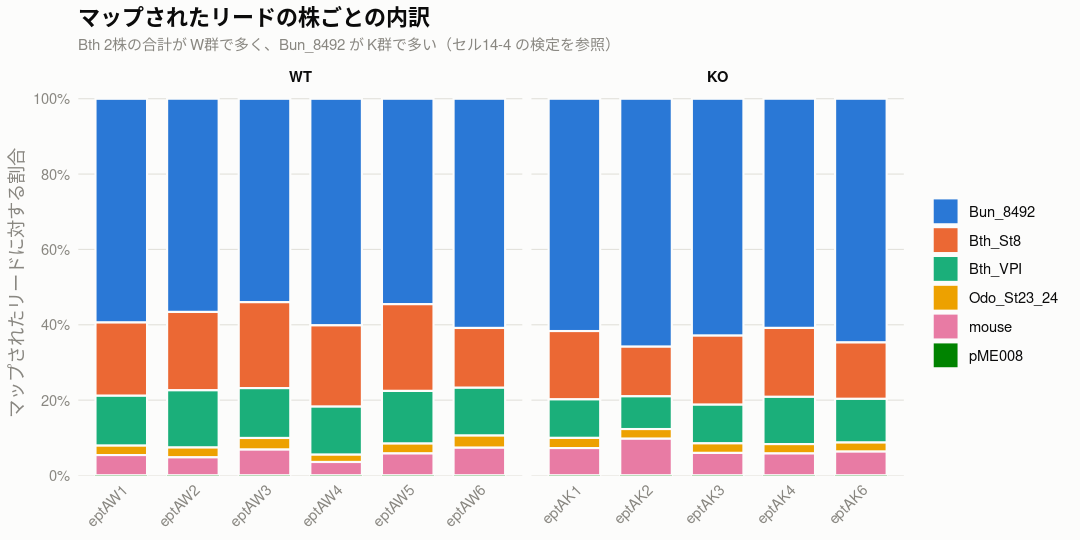

In [68]:
# ── 株シェアを積み上げ棒で見る ─────────────────────────────────
# 色は固定の割り当て（検体が増減しても色が入れ替わらないように名前で指定する）。
# 積み上げの順は多い株から上に置く。
# pME008 は 0.005% 台なので、この縦軸では線1本分も描けない（数値はセル14-3 の表と
# セル14-10 のパネルで見る）。それでも凡例と内訳に含めておく
library(ggplot2)

col_surface = '#fcfcfb'   # 図の地色
col_text    = '#0b0b0b'
col_muted   = '#898781'   # 軸ラベル
col_grid    = '#e1e0d9'   # 目盛線（細く薄く）

col_strain = c('Bun_8492'    = '#2a78d6',
               'Bth_St8'     = '#eb6834',
               'Bth_VPI'     = '#1baf7a',
               'Odo_St23_24' = '#eda100',
               'mouse'       = '#e87ba4',
               'pME008'      = '#008300')

# 横長の表を縦に積み直す
share_long = share %>%
    dplyr::select(name, group, Bun_8492, Bth_St8, Bth_VPI, Odo_St23_24, mouse, pME008) %>%
    pivot_longer(-c(name, group), names_to = '株', values_to = 'pct') %>%
    mutate(株    = factor(株, levels = names(col_strain)),
           group = factor(group, levels = c('WT','KO')))

options(repr.plot.width = 9, repr.plot.height = 4.5)

p = ggplot(share_long, aes(x = name, y = pct, fill = 株)) +
    # 境界に地色の細い線を入れて、積み上げの区切りを見せる
    geom_col(width = 0.72, colour = col_surface, linewidth = 0.6) +
    facet_grid(~ group, scales = 'free_x', space = 'free_x') +
    scale_fill_manual(values = col_strain) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'マップされたリードの株ごとの内訳',
         subtitle = 'Bth 2株の合計が W群で多く、Bun_8492 が K群で多い（セル14-4 の検定を参照）',
         x = NULL, y = 'マップされたリードに対する割合', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background  = element_rect(fill = col_surface, colour = NA),
          plot.background   = element_rect(fill = col_surface, colour = NA),
          strip.background  = element_rect(fill = col_surface, colour = NA),
          strip.text        = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text         = element_text(colour = col_muted),
          axis.text.x       = element_text(angle = 45, hjust = 1),
          axis.title        = element_text(colour = col_muted),
          plot.title        = element_text(colour = col_text, face = 'bold'),
          plot.subtitle     = element_text(colour = col_muted, size = 9),
          legend.text       = element_text(colour = col_text),
          legend.position   = 'right')

# 描画そのものは正しいが、PNG デバイスが日本語を描くときにグリフ変換の警告を
# 大量に出すので、表示のときだけ抑える（図の内容には影響しない）
suppressWarnings(print(p))

## セル14-10: 群間比較を点で見る

セル14-4 の検定結果を図にする。

**箱ひげ図は使わない。** n = 6 vs 5 では四分位が実質2点で決まるため、
分布を表しているように見えて誤解を招く。**全検体を点で出して平均を横線で重ねる。**

株ごとにスケールが大きく違う（`Bun_8492` 54〜66% / `Odo_St23_24` 2〜3%）ので、
**1枚に重ねず小分けにして縦軸を株ごとに取る**（軸を2本持つ図にはしない）。

パネルの見出しにセル14-4 の p 値を添えてある。

**縦軸は 0 から始める**（軸を切らない）。上端だけ株ごとに取る。
`Bun_8492` のように 54〜66% の範囲に収まる株では下に余白ができるが、
**軸を切ると差が実際より大きく見える**ので、そちらを避ける。

**pME008 もパネルとして出す。** 0.005〜0.013% と小さいが、
このパネルは pME008 用の縦軸を持つので**ここでは読める**。


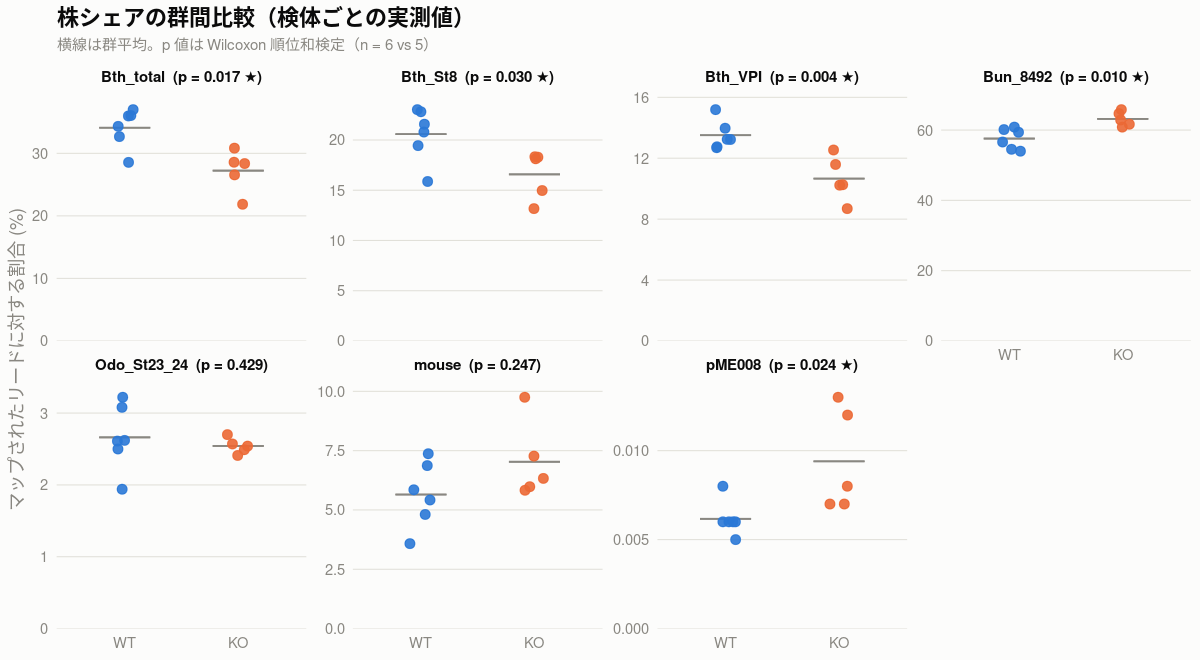

In [69]:
# ── 群間比較を点で見る ─────────────────────────────────────────
# n = 6 vs 5 と少ないので箱ひげは使わず、全検体を点で出して平均線を重ねる
#   （n=5 の箱ひげは四分位が実質2点で決まるため、分布を表しているように見えて誤解を招く）
# 株ごとにスケールが大きく違う（Bun 54〜66% / Odo 2〜3%）ので
# 1枚に重ねず小分けにし、縦軸は株ごとに取る

col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

cmp_long = share %>%
    dplyr::select(name, group, Bth計, Bth_St8, Bth_VPI, Bun_8492,
                  Odo_St23_24, mouse, pME008) %>%
    pivot_longer(-c(name, group), names_to = '指標', values_to = 'pct') %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           # パネル見出しに日本語を混ぜると PNG デバイスで文字が重なるので
           # 「Bth計」だけ ASCII 表記に置き換える（表の列名は変えない）
           指標  = ifelse(指標 == 'Bth計', 'Bth_total', 指標),
           指標  = factor(指標, levels = c('Bth_total','Bth_St8','Bth_VPI',
                                           'Bun_8492','Odo_St23_24','mouse','pME008')))

# セル14-4 の p 値を各パネルの見出しに添える
lab = grp_test %>%
    mutate(指標 = ifelse(指標 == 'Bth計', 'Bth_total', 指標)) %>%
    filter(指標 %in% levels(cmp_long$指標)) %>%
    mutate(見出し = sprintf("%s  (p = %.3f%s)", 指標, p, ifelse(p < 0.05, ' ★', ''))) %>%
    dplyr::select(指標, 見出し)
cmp_long = cmp_long %>% left_join(lab, by = '指標') %>%
    mutate(見出し = factor(見出し, levels = lab$見出し))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p = ggplot(cmp_long, aes(x = group, y = pct, colour = group)) +
    # 平均を横線で、各検体を点で
    #   errorbar の上下端を両方とも平均値にすると、ただの横線になる
    stat_summary(fun = mean, geom = 'errorbar',
                 aes(ymin = after_stat(y), ymax = after_stat(y)),
                 width = 0.45, linewidth = 0.5, colour = col_muted) +
    geom_point(size = 2.4, alpha = 0.9,
               position = position_jitter(width = 0.10, height = 0, seed = 1)) +
    facet_wrap(~ 見出し, scales = 'free_y', nrow = 2) +
    # 縦軸は 0 から始める（軸を切らない）。上端は株ごとに取る
    scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
    scale_colour_manual(values = col_group, guide = 'none') +
    labs(title = '株シェアの群間比較（検体ごとの実測値）',
         subtitle = '横線は群平均。p 値は Wilcoxon 順位和検定（n = 6 vs 5）',
         x = NULL, y = 'マップされたリードに対する割合 (%)') +
    theme_minimal(base_size = 11) +
    theme(panel.background  = element_rect(fill = col_surface, colour = NA),
          plot.background   = element_rect(fill = col_surface, colour = NA),
          strip.text        = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text         = element_text(colour = col_muted),
          axis.title        = element_text(colour = col_muted),
          plot.title        = element_text(colour = col_text, face = 'bold'),
          plot.subtitle     = element_text(colour = col_muted, size = 9))

# 描画そのものは正しいが、PNG デバイスが日本語を描くときにグリフ変換の警告を
# 大量に出すので、表示のときだけ抑える（図の内容には影響しない）
suppressWarnings(print(p))

---
# eptA の遺伝子型確認（ゲート2）

## セル14-5: eptA の領域ごとの depth（全検体）

セル13-5（eptAW1 だけ）を全検体に広げる。**CLAUDE.md §7 ステージ4 の中心的な確認。**

| 見るもの | 期待される結果 |
|---|---|
| `_deleted`（Bth_VPI / Bth_St8 / Bun） | **W群はカバーされる / K群はゼロ** |
| `_retained` | 両群にあり。**ここで DE 比較する** |
| `_5p` / `_3p`（Odo） | K群で `_3p` がゼロなら**挿入による転写終結**の証拠 |
| `pME008_CAST_spacer` | 群の判別子（CLAUDE.md §2） |

セル13-5 で使った `regions` をそのまま使う（セル13-5 を実行していない場合は先に流す）。

In [72]:
# ── eptA の遺伝子型確認（全検体）= ゲート2 ─────────────────────
# セル13-5 を全検体に広げる。CLAUDE.md §7 ステージ4 の中心的な確認。
#   _deleted : W群はカバーされる / K群はゼロ      ← 3株の欠失を確認
#   _retained: 両群にあり（ここで DE 比較する）
#   _5p / _3p: Odo の挿入。K群で _3p がゼロなら転写終結
#   CAST_spacer: pME008 の判別子（CLAUDE.md §2）
# samtools depth -a は depth 0 の塩基も返すので、平均 depth がそのまま使える

geno = data.frame()
for (s in seq_list$name) {
    for (i in 1:nrow(regions)) {
        reg = sprintf("%s:%d-%d", regions[i,'contig'], regions[i,'start'], regions[i,'end'])
        d   = system2(samtools, args = c('depth', '-a', '-r', reg,
                                         paste0(path_bam, "/", s, ".bam")), stdout = TRUE)
        v = if (length(d) == 0) 0 else as.numeric(sapply(strsplit(d, "\t"), `[`, 3))
        geno = rbind(geno, data.frame(name = s, feature = regions[i,'gene_id'],
                                      平均depth = round(mean(v), 1)))
    }
}

# 見やすさのため、eptA と判別子の feature だけを横並びにする
#   Bth_VPI と Bun は _retained が2区間に分かれているので合算せず区間ごとに出す
key = c('BT_RS09185_retained','BT_RS09185_deleted','CE91St8_20540_deleted',
        'NQ510_RS14730_retained','NQ510_RS14730_deleted',
        'CE91St23_40970_5p','CE91St23_40970_3p','pME008_CAST_spacer')

geno %>%
    filter(feature %in% key) %>%
    group_by(name, feature) %>% summarise(平均depth = mean(平均depth), .groups='drop') %>%
    pivot_wider(names_from = feature, values_from = 平均depth) %>%
    left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    dplyr::select(name, group, all_of(key)) %>%
    arrange(factor(group, levels = c('WT','KO')), name) %>%   # W群を上に
    as.data.frame()

name,group,BT_RS09185_retained,BT_RS09185_deleted,CE91St8_20540_deleted,NQ510_RS14730_retained,NQ510_RS14730_deleted,CE91St23_40970_5p,CE91St23_40970_3p,pME008_CAST_spacer
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,220.50,231.7,410.0,1376.25,1886.3,55.1,24.1,1.7
eptAW2,WT,206.70,203.7,347.3,1203.05,1632.6,55.7,21.4,0.0
eptAW3,WT,143.20,157.1,249.3,1013.35,1276.7,89.2,38.8,0.3
eptAW4,WT,122.75,140.8,459.2,4670.05,7382.5,74.5,29.0,1.0
eptAW5,WT,226.40,266.5,565.5,1304.75,1869.8,95.7,57.4,0.3
eptAW6,WT,106.60,124.7,164.8,613.75,937.4,50.5,39.3,0.0
eptAK1,KO,20.55,0.0,0.1,245.10,4.2,105.7,0.1,0.0
eptAK2,KO,25.75,0.1,0.1,303.20,3.7,85.2,0.3,0.0
eptAK3,KO,85.90,1.0,0.7,3375.05,49.9,158.6,0.3,1.2


## セル14-6: 遺伝子型の判定

`_deleted`（および Odo の `_3p`）が「W群で高く K群でゼロ」になっているかを数値で判定する。

**絶対値は検体間の深度差で動くので、同じ株の `_retained` との比（欠落率）で見る。**
`Bth_St8` は全長KOで `_retained` が無い（15 bp しかなく除去済み）ので絶対値で見る。

n = 6 vs 5 なので Wilcoxon。**この条件での両側 p の最小値は 0.0043**
（= 2 / C(11,5)）なので、**p = 0.0043 は「完全に分離した」という意味。**

**行は W群6検体を上、K群5検体を下**に並べる。
2つ目の出力（群間比較）も `cat()` ではなく **data.frame** にする
（`sprintf` は日本語を1文字幅で数えるので、`VPI_del欠落率` のような指標名が混ざると桁がずれる）。
値の幅が 0.1〜4,700 と広いので有効数字3桁で揃え、
`format(scientific = FALSE)` で `4.67e+03` のような表記を避ける。


In [73]:
# ── 遺伝子型の判定 ─────────────────────────────────────────────
# _deleted（および Odo の _3p）が「W群で高く K群でゼロ」になっているかを数値で判定する。
# 絶対値は検体間の深度差で動くので、同じ株の _retained との比で見る
#   Bth_St8 は全長KOで _retained が無い（15 bp しかなく除去済み）ので絶対値で見る

jd = geno %>%
    filter(feature %in% key) %>%
    group_by(name, feature) %>% summarise(d = mean(平均depth), .groups='drop') %>%
    pivot_wider(names_from = feature, values_from = d) %>%
    left_join(seq_list %>% dplyr::select(name, group), by='name') %>%
    mutate(VPI_del欠落率 = round(100 * BT_RS09185_deleted / BT_RS09185_retained, 2),
           Bun_del欠落率 = round(100 * NQ510_RS14730_deleted / NQ510_RS14730_retained, 2),
           Odo_3p欠落率  = round(100 * CE91St23_40970_3p / CE91St23_40970_5p, 2),
           St8_del深度   = CE91St8_20540_deleted)

jd %>% dplyr::select(name, group, VPI_del欠落率, Bun_del欠落率, Odo_3p欠落率,
                     St8_del深度, pME008_CAST_spacer) %>%
    arrange(factor(group, levels = c('WT','KO')), name) %>%   # W群を上に
    as.data.frame()

# _retained 側も並べる（両群にあるはず。ここが DE 比較の対象）
# 結果は cat() で並べると日本語の文字幅で桁がずれるので data.frame にして返す
geno_test = data.frame()
for (v in c('VPI_del欠落率','Bun_del欠落率','Odo_3p欠落率','St8_del深度','pME008_CAST_spacer',
            'BT_RS09185_retained','NQ510_RS14730_retained','CE91St23_40970_5p')) {
    w = jd[jd$group == 'WT', v, drop = TRUE]
    k = jd[jd$group == 'KO', v, drop = TRUE]
    p = suppressWarnings(wilcox.test(w, k)$p.value)

    geno_test = rbind(geno_test, data.frame(
        指標    = v,
        # 0.1 から 4700 まで値の幅が広いので、有効数字3桁で揃える。
        # sprintf("%g") だと 4670 が 4.67e+03 になるので format() を使う
        WT平均  = signif(mean(w), 4),
        WT範囲  = paste(format(signif(min(w), 3), scientific = FALSE, trim = TRUE), '-',
                        format(signif(max(w), 3), scientific = FALSE, trim = TRUE)),
        KO平均  = signif(mean(k), 4),
        KO範囲  = paste(format(signif(min(k), 3), scientific = FALSE, trim = TRUE), '-',
                        format(signif(max(k), 3), scientific = FALSE, trim = TRUE)),
        WT_KO倍 = ifelse(mean(k) > 0, round(mean(w)/mean(k), 2), Inf),
        p       = round(p, 4),
        判定    = ifelse(p < 0.05, '★ 差あり', '-')))
}
geno_test

name,group,VPI_del欠落率,Bun_del欠落率,Odo_3p欠落率,St8_del深度,pME008_CAST_spacer
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,105.08,137.06,43.74,410.0,1.7
eptAW2,WT,98.55,135.71,38.42,347.3,0.0
eptAW3,WT,109.71,125.99,43.50,249.3,0.3
eptAW4,WT,114.70,158.08,38.93,459.2,1.0
eptAW5,WT,117.71,143.31,59.98,565.5,0.3
eptAW6,WT,116.98,152.73,77.82,164.8,0.0
eptAK1,KO,0.00,1.71,0.09,0.1,0.0
eptAK2,KO,0.39,1.22,0.35,0.1,0.0
eptAK3,KO,1.16,1.48,0.19,0.7,1.2


指標,WT平均,WT範囲,KO平均,KO範囲,WT_KO倍,p,判定
<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
VPI_del欠落率,110.50,98.6 - 118,0.594,0 - 1.16,185.95,0.0043,★ 差あり
Bun_del欠落率,142.10,126 - 158,1.500,1.22 - 1.71,94.76,0.0043,★ 差あり
Odo_3p欠落率,50.40,38.4 - 77.8,0.182,0.09 - 0.35,276.91,0.0043,★ 差あり
St8_del深度,366.00,165 - 566,0.420,0.1 - 0.7,871.47,0.0078,★ 差あり
pME008_CAST_spacer,0.55,0 - 1.7,0.660,0 - 1.7,0.83,0.8511,-
BT_RS09185_retained,171.00,107 - 226,58.110,20.6 - 106,2.94,0.0043,★ 差あり
NQ510_RS14730_retained,1697.00,614 - 4670,1283.000,245 - 3380,1.32,0.5368,-
CE91St23_40970_5p,70.12,50.5 - 95.7,111.700,75.5 - 159,0.63,0.0519,-


## セル14-6図: eptA の遺伝子型を図にする

セル14-5・14-6 の結果を1枚で見る。

- depth は 0 から 7,000 まで4桁以上に広がるので**縦軸は対数**
- **対数軸は 0 を描けない**ので、`depth = 0` の点は下限 0.05 に置いて
  **白抜きの記号**で示す（K群の `_deleted` がゼロであることがこの図の要点なので落とさない）
- 破線は `depth = 1`。これを下回れば「転写されていない」と見てよい目安
- 横線は群の**中央値**（対数軸なので平均より中央値が見やすい）

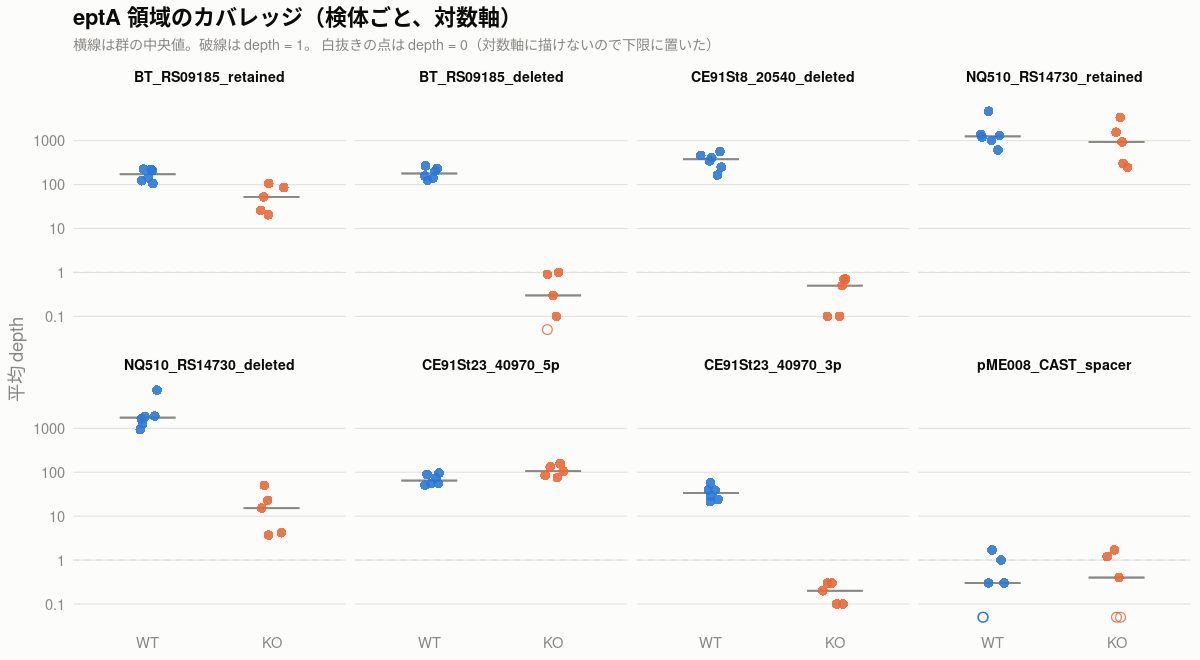

In [78]:
# ── eptA の遺伝子型を図にする ─────────────────────────────────
# セル14-5・14-6 の結果を1枚で見る。
# depth は 0 から 7,000 まで4桁以上に広がるので縦軸は対数にする。
#   対数軸は 0 を描けないので、0 の点は下限 0.05 に置いて開いた記号で示す
#   （K群の _deleted がゼロであることがこの図の要点なので、落とさずに見せる）

# 色は セル14-9 で決めたものを使う（このセルだけ動かす場合に備えて再掲）
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

dep_floor = 0.05

key_order = c('BT_RS09185_retained','BT_RS09185_deleted','CE91St8_20540_deleted',
              'NQ510_RS14730_retained','NQ510_RS14730_deleted',
              'CE91St23_40970_5p','CE91St23_40970_3p','pME008_CAST_spacer')

geno_fig = geno %>%
    filter(feature %in% key_order) %>%
    group_by(name, feature) %>% summarise(depth = mean(平均depth), .groups = 'drop') %>%
    left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(group    = factor(group, levels = c('WT','KO')),
           feature  = factor(feature, levels = key_order),
           ゼロ     = depth == 0,
           depth_描画 = ifelse(depth == 0, dep_floor, depth))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p = ggplot(geno_fig, aes(x = group, y = depth_描画, colour = group)) +
    # depth 1 の線。これを下回れば「転写されていない」と見てよい目安
    geom_hline(yintercept = 1, linetype = 'dashed', colour = col_grid, linewidth = 0.4) +
    stat_summary(fun = median, geom = 'errorbar',
                 aes(ymin = after_stat(y), ymax = after_stat(y)),
                 width = 0.45, linewidth = 0.5, colour = col_muted) +
    geom_point(aes(shape = ゼロ), size = 2.4, alpha = 0.9,
               position = position_jitter(width = 0.10, height = 0, seed = 1)) +
    facet_wrap(~ feature, nrow = 2, scales = 'fixed') +
    scale_y_log10(breaks = c(0.1, 1, 10, 100, 1000),
                  labels = c('0.1', '1', '10', '100', '1000')) +
    scale_colour_manual(values = col_group, guide = 'none') +
    scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 1), guide = 'none') +
    labs(title = 'eptA 領域のカバレッジ（検体ごと、対数軸）',
         subtitle = paste('横線は群の中央値。破線は depth = 1。',
                          '白抜きの点は depth = 0（対数軸に描けないので下限に置いた）'),
         x = NULL, y = '平均 depth') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 8.5),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル14-7: eptA の区間を MAPQ>=10 で測り直す

セル14-5・14-6 は **MAPQ 無制限**なので、**Bth 2株間の mismapping が混じっている可能性**がある
（セル13-2 で MAPQ 0-1 が 17.73% あった）。`samtools depth` の **`-Q`** で絞って確認する
（`-q` は base quality なので別物）。

あわせて **`_retained` を区間ごとに分けて出す。**
`Bth_VPI` と `Bun` の `_retained` は2区間に分かれていて GTF 上は同じ `gene_id` だが、
**短い区間は「欠失境界をまたぐリード」の影響を強く受ける**（セル10 の考察で予告した問題）。

**WT を KO より左の列**に置く（`pivot_wider` のままだとアルファベット順で KO が先に来る）。


In [77]:
# ── eptA の区間を MAPQ>=10 で測り直す ─────────────────────────
# 上の表は MAPQ 無制限なので、Bth 2株間の mismapping が混じっている可能性がある。
# samtools depth の -Q は mapping quality のしきい値（-q は base quality なので別物）。
# あわせて _retained を区間ごとに分けて出す
#   （Bth_VPI と Bun の _retained は2区間に分かれていて、GTF 上は同じ gene_id。
#    5'側の区間は短いので、下記の「境界をまたぐリード」の影響を強く受ける）

dep10 = data.frame()
for (s in seq_list$name) {
    for (i in 1:nrow(regions)) {
        if (!grepl('_retained$|_deleted$|_5p$|_3p$', regions[i,'gene_id'])) next
        reg = sprintf("%s:%d-%d", regions[i,'contig'], regions[i,'start'], regions[i,'end'])

        d0 = system2(samtools, args = c('depth','-a','-r',reg,
                     paste0(path_bam,"/",s,".bam")), stdout = TRUE)
        d1 = system2(samtools, args = c('depth','-a','-Q','10','-r',reg,
                     paste0(path_bam,"/",s,".bam")), stdout = TRUE)
        v0 = if (length(d0)==0) 0 else as.numeric(sapply(strsplit(d0,"\t"), `[`, 3))
        v1 = if (length(d1)==0) 0 else as.numeric(sapply(strsplit(d1,"\t"), `[`, 3))

        dep10 = rbind(dep10, data.frame(
            name     = s,
            group    = seq_list$group[seq_list$name == s],
            feature  = regions[i,'gene_id'],
            区間     = sprintf("%d-%d", regions[i,'start'], regions[i,'end']),
            長さ     = regions[i,'end'] - regions[i,'start'] + 1,
            depth    = round(mean(v0), 1),
            depth_Q10 = round(mean(v1), 1)))
    }
}

# 区間ごとに群平均を比べる
dep10 %>%
    group_by(feature, 区間, 長さ, group) %>%
    summarise(depth_Q10 = mean(depth_Q10), .groups='drop') %>%
    pivot_wider(names_from = group, values_from = depth_Q10) %>%
    mutate(WT_KO比 = round(ifelse(KO > 0, WT/KO, Inf), 2),
           WT = round(WT, 1), KO = round(KO, 1)) %>%
    dplyr::select(feature, 区間, 長さ, WT, KO, WT_KO比) %>%   # WT を左に
    arrange(feature, 区間) %>%
    as.data.frame()

feature,区間,長さ,WT,KO,WT_KO比
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
BT_RS09185_deleted,2276062-2276565,504,184.5,0.2,922.42
BT_RS09185_retained,2274992-2276061,1070,172.2,67.2,2.56
BT_RS09185_retained,2276566-2276695,130,145.5,32.1,4.54
CE91St23_40970_3p,5080080-5081503,1424,35.0,0.2,218.44
CE91St23_40970_5p,5081504-5081840,337,70.1,110.3,0.64
CE91St8_20540_deleted,2843190-2844878,1689,335.3,0.1,4191.04
NQ510_RS14730_deleted,3642426-3643000,575,2494.9,15.2,164.35
NQ510_RS14730_retained,3642227-3642425,199,1899.2,1791.6,1.06
NQ510_RS14730_retained,3643001-3643927,927,1492.0,721.5,2.07


## セル14-7図: 区間ごとの WT / KO 比と欠失境界の補正

### 欠失境界の効果とは何か

**参照ゲノムは W群（野生型）**なので、K群のリードが持つ「欠失でつながった接合部」は
参照のどこにも存在せず、**そのリードはマップされない。**

```
 参照（W群）  : ... A A A A [ 欠 失 す る 区 間 ] B B B B ...
 K群の実物    : ... A A A A B B B B ...        ← AAAA と BBBB が直接つながっている

 K群のリード  :        [=== A A A A | B B B B ===]   ← 参照に一致しない → 落ちる
                       [=== A A A A ]                ← 境界をまたがない → マップされる
```

**境界ちょうどの塩基を覆えるリードはほぼ無く、境界からリード長だけ離れれば影響が無くなる。**
その間は直線的に回復する。

```
 K群の depth
   │                    ┌──────────  ← リード長分離れれば影響なし
   │                ╱
   │            ╱
   │        ╱
   │    ╱
   └─┴────────────────────────────→ 境界からの距離
     境界            リード長（150 bp）
```

→ **区間が短いほど、その区間の大部分が「影響を受ける範囲」に入る**
→ **K群の depth が実際より低く出る**
→ **WT / KO 比が過大に出る**

### リード長は 150 bp（147 ではない）

| 測り方 | 値 |
|---|---|
| BAM 中のリード長の最頻値 | **150 bp（先頭200万アラインメントの 87%）** |
| fastp 後の平均リード長（セル9-2 の `len1`） | 146〜148 bp |

**平均 147 bp はアダプターを削った1割のリードに引き下げられた値**で、
大多数のリードは 150 bp のまま。境界効果が及ぶ範囲は**リードの長さそのもの**なので、
ここでは **150 bp** を使う（147 で計算しても補正後の値はほぼ変わらない）。

### 補正のしかた

区間全体で「K群に残る割合（保持率）」を幾何から出して、観測比にそれを掛け戻す。

| 区間長 | 保持率 |
|---|---|
| リード長以下 | `長さ / (2 × リード長)` ... 区間全体が影響範囲の中 |
| リード長より長い | `(リード長/2 + (長さ − リード長)) / 長さ` ... 一部だけ影響 |

一様な開始位置を仮定した**おおよその補正**。

**図の見方**: 白丸が観測比、塗り丸が補正後の比、矢印がその移動。
**補正は必ず比を小さくする方向にしか動かない**（K群が低く出ている分を戻すため）。
色は保持率で、濃いほど補正が大きい。

feature,区間,長さ,WT,KO,観測比,保持率,補正比
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CE91St23_40970_5p,5081504-5081840,337,70.10,110.32,0.64,0.777,0.49
NQ510_RS14730_retained,3642227-3642425,199,1899.15,1791.56,1.06,0.623,0.66
NQ510_RS14730_retained,3643001-3643927,927,1492.03,721.50,2.07,0.919,1.90
BT_RS09185_retained,2276566-2276695,130,145.50,32.08,4.54,0.433,1.97
BT_RS09185_retained,2274992-2276061,1070,172.17,67.18,2.56,0.930,2.38
NQ510_RS14730_deleted,3642426-3643000,575,2494.90,15.18,164.35,0.870,142.92
CE91St23_40970_3p,5080080-5081503,1424,34.95,0.16,218.44,0.947,206.93
BT_RS09185_deleted,2276062-2276565,504,184.48,0.20,922.42,0.851,785.15
CE91St8_20540_deleted,2843190-2844878,1689,335.28,0.08,4191.04,0.956,4004.94


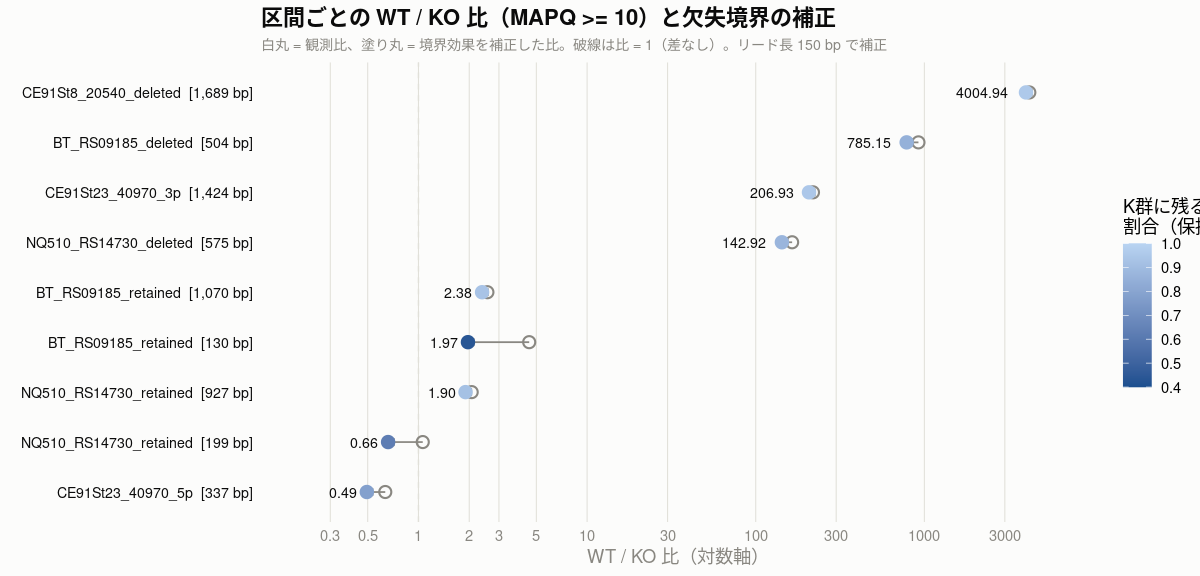

In [76]:
# ── 区間ごとの WT / KO 比と、欠失境界の補正 ───────────────────
# 色は セル14-9 で決めたものを使う（このセルだけ動かす場合に備えて再掲）
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# リード長。BAM 中の実測では 87% が 150 bp（fastp 後の「平均」147 bp は
# アダプターを削った1割のリードに引き下げられた値なので、ここでは 150 を使う）
read_len = 150

# ── 欠失境界の効果とは何か ──────────────────────────────
# 参照ゲノムは W群（野生型）なので、K群のリードが持つ「欠失でつながった接合部」は
# 参照に存在せず、そのリードはマップされない。
#
#   参照（W群）: ... AAAA [欠失する区間] BBBB ...
#   K群の実物  : ... AAAA BBBB ...          ← AAAA と BBBB が直接つながっている
#
# K群で「AAAA と BBBB にまたがるリード」は参照のどこにも一致しないので落ちる。
# つまり境界から リード長分手前までの塩基は、K群では覆うリードが減る。
# 境界ちょうどの塩基はほぼゼロ、リード長だけ離れれば影響なし、と直線的に回復する。
#
#   → 区間が短いほど、その区間の大部分が「影響を受ける範囲」に入る
#   → K群の depth が実際より低く出る → WT/KO 比が過大に出る
#
# 区間全体での「K群に残る割合」を幾何から出して、観測比をそれで割り戻す。
# 一様な開始位置を仮定したおおよその補正

int_fig = dep10 %>%
    group_by(feature, 区間, 長さ, group) %>%
    summarise(d = mean(depth_Q10), .groups = 'drop') %>%
    pivot_wider(names_from = group, values_from = d) %>%
    filter(KO > 0) %>%
    mutate(観測比 = WT / KO,
           # 境界が区間の片端にある前提（_retained も _5p も欠失/挿入点に接している）
           保持率 = ifelse(長さ <= read_len,
                           長さ / (2 * read_len),                       # 区間全体が影響範囲
                           (read_len / 2 + (長さ - read_len)) / 長さ),  # 一部だけ影響
           補正比 = 観測比 * 保持率,
           ラベル = sprintf("%s  [%s bp]", feature,
                            format(長さ, big.mark = ',', trim = TRUE))) %>%
    arrange(補正比)
int_fig$ラベル = factor(int_fig$ラベル, levels = int_fig$ラベル)

options(repr.plot.width = 10, repr.plot.height = 4.8)

p = ggplot(int_fig, aes(y = ラベル)) +
    geom_vline(xintercept = 1, linetype = 'dashed', colour = col_grid, linewidth = 0.4) +
    # 観測比 → 補正比 の移動を矢印で見せる
    geom_segment(aes(x = 観測比, xend = 補正比, y = ラベル, yend = ラベル),
                 colour = col_muted, linewidth = 0.5,
                 arrow = arrow(length = unit(0.14, 'cm'), type = 'closed')) +
    geom_point(aes(x = 観測比), size = 2.8, shape = 1, colour = col_muted, stroke = 0.9) +
    geom_point(aes(x = 補正比, colour = 保持率), size = 3.4) +
    # 補正は必ず比を小さくする（塗り丸は白丸の左）ので、数値は塗り丸の左に置く
    geom_text(aes(x = 補正比, label = sprintf('%.2f', 補正比)),
              hjust = 1.35, size = 3, colour = col_text) +
    scale_x_log10(breaks = c(0.3, 0.5, 1, 2, 3, 5, 10, 30, 100, 300, 1000, 3000),
                  labels = c('0.3','0.5','1','2','3','5','10','30','100','300','1000','3000'),
                  expand = expansion(mult = c(0.16, 0.10))) +
    scale_colour_gradient(low = '#1b4f8f', high = '#b9d4f2', limits = c(0.4, 1),
                          name = 'K群に残る\n割合（保持率）') +
    labs(title = '区間ごとの WT / KO 比（MAPQ >= 10）と欠失境界の補正',
         subtitle = paste0('白丸 = 観測比、塗り丸 = 境界効果を補正した比。破線は比 = 1（差なし）。',
                           'リード長 ', read_len, ' bp で補正'),
         x = 'WT / KO 比（対数軸）', y = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          panel.grid.major.y = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.x = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.y        = element_text(colour = col_text, size = 8.5),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

int_fig %>% dplyr::select(feature, 区間, 長さ, WT, KO, 観測比, 保持率, 補正比) %>%
    mutate(across(c(WT, KO, 観測比, 補正比), ~ round(., 2)),
           保持率 = round(保持率, 3)) %>% as.data.frame()

## セル14-8: 全検体の BAM 統計（MAPQ・インサート長）

セル13〜13-3（eptAW1 だけ）を全検体に広げる。
**1検体あたり1パス約2分なので、11検体で20分強。**
結果は検体ごとに `<検体>_bamstat.tsv` に残すので2回目以降はスキップされる。

CLAUDE.md §7 ステージ4 の「サンプル別 mapping率 / multimap率」をここで確定させる。

**スキップ判定は「ファイルがあるか」ではなく「中身が揃っているか」で行う。**
集計が途中で失敗すると、シェルのリダイレクトによって **0 バイトのファイルだけが残る。**
`file.exists()` だけで判定すると、それを完了とみなして飛ばしてしまい、
表に `NA` の行ができる（実際に `eptAK3` でこれが起きた）。
`COUNT` 行が3つ揃っているかを確認して、足りなければ作り直す。


In [85]:
# ── 全検体の BAM 統計（MAPQ・インサート長）────────────────────
# セル13〜13-3 を全検体に広げる。1検体あたり1パス約2分なので、
# 11検体で20分強かかる。結果は検体ごとに <検体>_bamstat.tsv に残すので
# 2回目以降はスキップされる

for (s in seq_list$name) {
    out_stat = paste0(path_bam, "/", s, "_bamstat.tsv")

    # 「ファイルがある」だけで済ませない。集計が途中で失敗すると
    # リダイレクトで 0 バイトのファイルだけが残り、それを完了と誤判定してしまう
    # （実際に eptAK3 でこれが起きた）。COUNT 行が3つ揃っているかで判定する
    done = FALSE
    if (file.exists(out_stat) && file.size(out_stat) > 0) {
        done = sum(startsWith(readLines(out_stat, warn = FALSE), 'COUNT')) == 3
    }
    if (done) { cat(sprintf("[スキップ] %s\n", s)); next }
    if (file.exists(out_stat)) cat(sprintf("[やり直し] %s（前回の出力が不完全）\n", s))

    cat(sprintf("%s を集計中...\n", s))
    cmd = paste0(samtools, " view -@ 8 ", path_bam, "/", s, ".bam | awk -v OFS='\\t' '",
        "{ tot++; if (int($2/4)%2==0) { mapped++; mq[$5]++ } if (int($2/2)%2==1) proper++; ",
        "  if (int($2/2)%2==1 && $9>0) tl[int($9/25)*25]++ } ",
        "END { print \"COUNT\",\"total\",tot; print \"COUNT\",\"mapped\",mapped; ",
        "      print \"COUNT\",\"proper_pair\",proper; ",
        "      for (k in mq) print \"MAPQ\",k,mq[k]; ",
        "      for (k in tl) print \"TLEN\",k,tl[k] }' > ", out_stat)
    system(cmd)
}

# 11検体分を1枚の表にする
bamqc = data.frame()
for (s in seq_list$name) {
    x = read.table(paste0(path_bam, "/", s, "_bamstat.tsv"), sep="\t", header=FALSE,
                   col.names=c('type','key','n'))
    cn = setNames(x$n[x$type=='COUNT'], x$key[x$type=='COUNT'])
    m  = x %>% filter(type=='MAPQ') %>% mutate(mapq = as.integer(key))
    t  = x %>% filter(type=='TLEN') %>% mutate(bin  = as.integer(key)) %>% arrange(bin)
    tc = cumsum(t$n) / sum(t$n)

    bamqc = rbind(bamqc, data.frame(
        name        = s,
        group       = seq_list$group[seq_list$name == s],
        総リードM   = round(cn['total']/1e6, 1),
        マップpct   = round(100*cn['mapped']/cn['total'], 2),
        properpct   = round(100*cn['proper_pair']/cn['total'], 2),
        MAPQ10以上pct = round(100*sum(m$n[m$mapq >= 10])/cn['mapped'], 2),
        MAPQ0_1pct  = round(100*sum(m$n[m$mapq <= 1])/cn['mapped'], 2),
        インサート中央値 = t$bin[which(tc >= 0.5)[1]],
        インサート95pct  = t$bin[which(tc >= 0.95)[1]],
        row.names   = NULL))
}

bamqc %>% arrange(factor(group, levels = c('WT','KO')), name)   # W群を上に

[スキップ] eptAK1
[スキップ] eptAK2
[スキップ] eptAK3
[スキップ] eptAK4
[スキップ] eptAK6
[スキップ] eptAW1
[スキップ] eptAW2
[スキップ] eptAW3
[スキップ] eptAW4
[スキップ] eptAW5
[スキップ] eptAW6


name,group,総リードM,マップpct,properpct,MAPQ10以上pct,MAPQ0_1pct,インサート中央値,インサート95pct
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
eptAW1,WT,111.7,98.92,98.33,74.02,17.73,225,425
eptAW2,WT,103.4,98.96,98.41,71.17,20.15,225,400
eptAW3,WT,86.9,98.88,98.31,72.67,18.94,225,375
eptAW4,WT,103.9,98.60,98.00,67.70,23.98,225,425
eptAW5,WT,130.3,98.90,98.38,71.88,18.62,225,425
eptAW6,WT,87.7,98.84,98.27,75.76,16.86,225,400
eptAK1,KO,118.4,98.73,98.17,77.29,17.03,225,375
eptAK2,KO,92.4,98.25,97.59,79.67,13.85,225,400
eptAK3,KO,181.3,98.49,97.92,77.32,15.67,225,400


## セル14-8図: 検体ごとのマッピング品質

セル14-8 の表を1枚で見る。

**縦軸は 0 起点にしていない。** マップ率と properly paired 率は 98% 台の狭い幅に
収まっていて、0 から描くと検体差が完全に潰れるため（絶対値はセル14-8 の表で確認する）。
セル14-10 とは扱いを変えている。

**見出しに「WT 何検体 / KO 何検体」を出す。**
`ggplot` は `NA` の行を**黙って落とす**ので、集計が欠けていても図は普通に描けてしまう
（実際に `eptAK3` の集計が 0 バイトで止まったとき、図を見ても気づきにくかった）。
セルの冒頭で `NA` の有無も確認し、欠けていれば検体名を表示する。


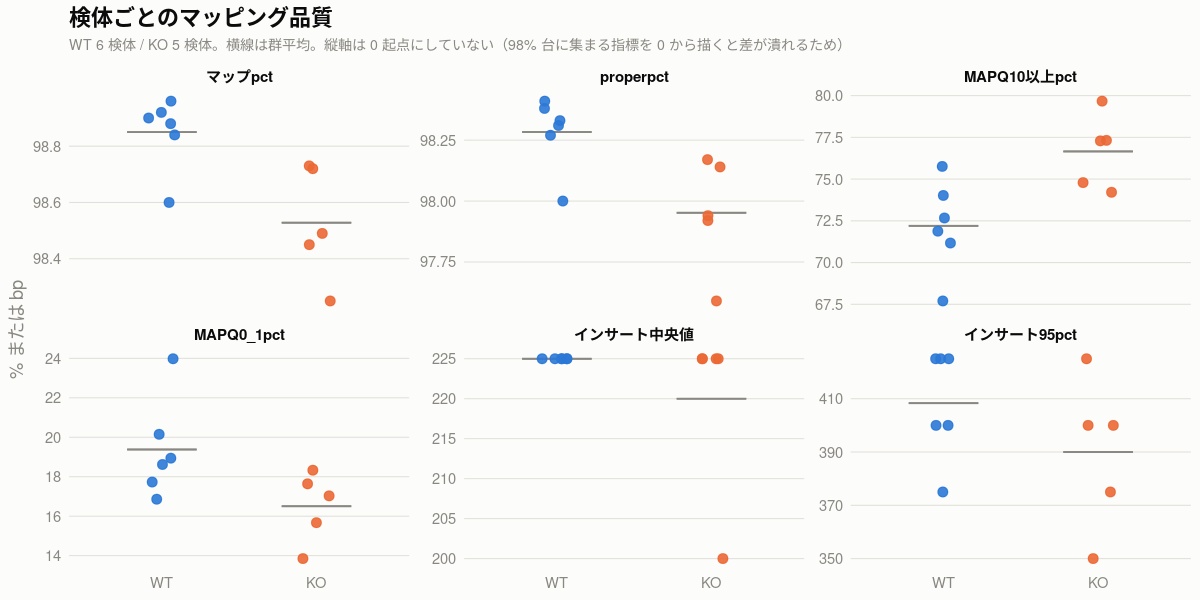

In [86]:
# ── 全検体の BAM 統計を図にする ───────────────────────────────
# セル14-8 の表を1枚で見る。
# 縦軸は 0 起点にしない。マップ率や properly paired 率は 98% 台の狭い幅に収まっていて、
# 0 から描くと検体差が完全に潰れるため（絶対値はセル14-8 の表で確認する）

# 色は セル14-9 で決めたものを使う（このセルだけ動かす場合に備えて再掲）
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

# NA が混ざっていないか先に確認する。
# ggplot は NA の行を黙って落とすので、集計が欠けていても図は普通に描けてしまう
#   （実際に eptAK3 の集計が 0 バイトで止まり、気づきにくい形になった）
na_cnt = sum(is.na(bamqc$マップpct))
if (na_cnt > 0) {
    cat(sprintf("!! %d 検体の集計が欠けています: %s\n", na_cnt,
                paste(bamqc$name[is.na(bamqc$マップpct)], collapse = ', ')))
    cat("   セル14-8 を実行し直してください（不完全な出力は作り直されます）\n")
}

bamqc_fig = bamqc %>%
    dplyr::select(name, group, マップpct, properpct, MAPQ10以上pct, MAPQ0_1pct,
                  インサート中央値, インサート95pct) %>%
    pivot_longer(-c(name, group), names_to = '指標', values_to = 'v') %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           指標  = factor(指標, levels = c('マップpct','properpct','MAPQ10以上pct',
                                           'MAPQ0_1pct','インサート中央値','インサート95pct')))

options(repr.plot.width = 10, repr.plot.height = 5)

p = ggplot(bamqc_fig, aes(x = group, y = v, colour = group)) +
    stat_summary(fun = mean, geom = 'errorbar',
                 aes(ymin = after_stat(y), ymax = after_stat(y)),
                 width = 0.45, linewidth = 0.5, colour = col_muted) +
    geom_point(size = 2.4, alpha = 0.9,
               position = position_jitter(width = 0.10, height = 0, seed = 1)) +
    facet_wrap(~ 指標, scales = 'free_y', nrow = 2) +
    scale_colour_manual(values = col_group, guide = 'none') +
    labs(title = '検体ごとのマッピング品質',
         # 何検体分の図かを見出しに出す。図を見るだけで欠けに気づけるように
         subtitle = sprintf('WT %d 検体 / KO %d 検体。横線は群平均。%s',
                            sum(bamqc$group == 'WT' & !is.na(bamqc$マップpct)),
                            sum(bamqc$group == 'KO' & !is.na(bamqc$マップpct)),
                            '縦軸は 0 起点にしていない（98% 台に集まる指標を 0 から描くと差が潰れるため）'),
         x = NULL, y = '% または bp') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

### 考察: eptA の遺伝子型確認（セル14-5〜14-8 の結果）= ゲート2 の判定

## ゲート2 は通過。4株すべて遺伝子型が確認できた

| 指標 | WT（n=6） | KO（n=5） | WT/KO | Wilcoxon p |
|---|---|---|---|---|
| Bth_VPI `_deleted` 欠落率 | 110.45% | 0.59% | **186倍** | **0.0043 ★** |
| Bth_St8 `_deleted` 深度 | 366.02 | 0.42 | **872倍** | **0.0078 ★** |
| Bun `_deleted` 欠落率 | 142.15% | 1.50% | **95倍** | **0.0043 ★** |
| Odo `_3p` 欠落率 | 50.40% | 0.18% | **277倍** | **0.0043 ★** |
| **pME008 `CAST_spacer`** | **0.55** | **0.66** | **0.8倍** | **0.8511（差なし）** |

**n = 6 vs 5 での両側 p の最小値は 0.0043**（= 2 / C(11,5) = 2/462）なので、
**eptA 3株は「完全に分離」している。** 検体の取り違えも無い。

MAPQ >= 10 で測り直しても結論は変わらない（セル14-7）。

| feature | 区間長 | WT | KO | WT/KO |
|---|---|---|---|---|
| `BT_RS09185_deleted` | 504 bp | 184.5 | 0.2 | **922倍** |
| `CE91St8_20540_deleted` | 1,689 bp | 335.3 | 0.1 | **4,191倍** |
| `NQ510_RS14730_deleted` | 575 bp | 2,494.9 | 15.2 | **164倍** |
| `CE91St23_40970_3p` | 1,424 bp | 35.0 | 0.2 | **218倍** |

## Odo の挿入は転写を止めている（予測どおり）

| feature | WT | KO | WT/KO |
|---|---|---|---|
| `CE91St23_40970_5p`（挿入点より5'側） | 70.1 | **110.3** | 0.64（**KO が1.6倍**） |
| `CE91St23_40970_3p`（挿入点より3'側） | 35.0 | **0.2** | **218倍** |

**K群で `_3p` がゼロ、`_5p` は残る。** CLAUDE.md §4 の予測「K群でゼロなら転写終結」が
そのまま出た。CAST 挿入（1,445 bp）が転写を止めている。

`_5p` が **KO で 1.6倍に増えている**のは注目点（p = 0.052）。
挿入カセットが転写終結させることで5'側断片が蓄積している、
あるいはカセット内のプロモーター（PcfxA など）の影響が考えられる。
**ステージ5 で正規化してから確定させる。**

## ★ pME008 の CAST spacer は判別子として使えない（確定）

セル13-5 で1検体から疑っていたが、**全検体で確定した。**

```
WT: 1.7, 0.0, 0.3, 1.0, 0.3, 0.0   ← 2検体がゼロ
KO: 0.0, 0.0, 1.2, 0.4, 1.7        ← 2検体が WT より高い
```

**WT/KO = 0.8倍、p = 0.85。判別力はゼロ。** むしろ検体単位では逆の答えを出す。

理由はセル13-5 のとおりで、
spacer が Cas オペロンの最後尾（depth が TnsA 36.7 → Cas6 2.0 と単調減衰する領域）にあり、
かつ転写産物が **crRNA（小さなRNA）で RNA-seq ライブラリに残らない**こと。

→ **CLAUDE.md §2・§7 の「スペーサー領域が最も単純な判別子」は RNA-seq では成り立たない。
判別子は eptA の `_deleted` を使う（上表のとおり 95〜4,191倍の分離）。**
CLAUDE.md を更新する。

## `_retained`（DE 比較の対象）— 欠失境界を補正すると筋が通る

MAPQ >= 10、区間ごとの群平均と、**欠失境界の効果を補正した比**（セル14-7図）。

| 株 | 区間 | 長さ | 保持率 | 観測比 | **補正比** |
|---|---|---|---|---|---|
| Bth_VPI | 5'側 | 130 bp | 0.433 | 4.54 | **1.96** |
| Bth_VPI | 3'側 | 1,070 bp | 0.930 | 2.56 | **2.38** |
| Bun | 5'側 | 199 bp | 0.623 | 1.06 | **0.66** |
| Bun | 3'側 | 927 bp | 0.919 | 2.07 | **1.90** |
| Odo | `_5p` | 337 bp | 0.777 | 0.63 | **0.49** |

### 補正が効いていることの確認

**Bth_VPI の2区間が一致した。** 補正前は 5'側 4.54 / 3'側 2.56 と2倍近く食い違っていたが、
補正後は **1.96 / 2.38** とほぼ同じ値になる。同じ転写産物の別の部分なのだから
一致するのが正しく、**食い違いは境界効果で説明できていた**ことになる。

`_deleted` 側（922倍→785倍など）は補正しても桁が変わらないので、ゲート2の判定には影響しない。

### 補正の向きは常に「比を小さくする」

境界効果は **K群の depth を下げる**ので、補正は必ず比を下げる方向にしか動かない。
したがって **K群の方が高く見えている区間（比 < 1）では、真の差は観測よりさらに大きい。**

| 区間 | 観測 | 補正後 | 読み方 |
|---|---|---|---|
| Bun 5'側 | 1.06（差なしに見える） | **0.66** | **K群が 1.5倍 高い** |
| Odo `_5p` | 0.63 | **0.49** | **K群が 2.0倍 高い** |

### 株ごとの読み（すべて暫定値。ステージ5 で DESeq2 により確定させる）

| 株 | 5'側 | 3'側 | 解釈の候補 |
|---|---|---|---|
| Bth_VPI | 1.96 倍低下 | 2.38 倍低下 | 転写産物全体が減っている |
| **Bun** | **1.5倍上昇** | **1.90 倍低下** | **5'側は保たれ（むしろ増え）、3'側だけ減る** |
| Odo | **2.0倍上昇**（`_5p`） | ゼロ（`_3p`） | 挿入で転写が止まり、5'側断片が蓄積 |

**Bun と Odo が似た形**（5'側は保たれるか増え、3'側が落ちる）なのが目を引く。
Odo は挿入による転写終結で説明がつくが、**Bun は内部欠失なのに同じ形**。
転写は始まっているが、欠失でつながった転写産物の3'側が不安定、
といった機構が考えられる。**この測定では機構までは区別できない。**

### ステージ5 への申し送り

1. **`_retained` の DE は DESeq2（株ごと、方針 B）で確定させる。** 上の倍率は暫定値
2. **`BT_RS09185_retained` は2区間を1つの `gene_id` にまとめてある。**
   短い 5'側（130 bp）は保持率 0.433 と補正が大きいが、長さ寄与は 130/1,200 = 11% なので
   feature 全体への影響は小さい（合算の観測比 2.67 → 3'側のみ 2.56）
3. **5'側と3'側で向きが違う株がある**（Bun）。feature を合算すると打ち消し合うので、
   ステージ5 では **`_retained` を区間ごとに分けた集計も併せて見る**

## セル14-8 の結果（全検体のマッピング品質）

| 検体 | 群 | 総リードM | マップ% | proper% | MAPQ10以上% | MAPQ0-1% | インサート中央値 | 95%ile |
|---|---|---|---|---|---|---|---|---|
| eptAW1 | WT | 111.7 | 98.92 | 98.33 | 74.02 | 17.73 | 225 | 425 |
| eptAW2 | WT | 103.4 | 98.96 | 98.41 | 71.17 | 20.15 | 225 | 400 |
| eptAW3 | WT | 86.9 | 98.88 | 98.31 | 72.67 | 18.94 | 225 | 375 |
| eptAW4 | WT | 103.9 | 98.60 | 98.00 | 67.70 | 23.98 | 225 | 425 |
| eptAW5 | WT | 130.3 | 98.90 | 98.38 | 71.88 | 18.62 | 225 | 425 |
| eptAW6 | WT | 87.7 | 98.84 | 98.27 | 75.76 | 16.86 | 225 | 400 |
| eptAK1 | KO | 118.4 | 98.73 | 98.17 | 77.29 | 17.03 | 225 | 375 |
| eptAK2 | KO | 92.4 | 98.25 | 97.59 | 79.67 | 13.85 | 225 | 400 |
| eptAK3 | KO | 181.3 | 98.49 | 97.92 | 77.32 | 15.67 | 225 | 400 |
| eptAK4 | KO | 116.0 | 98.72 | 98.14 | 74.21 | 17.64 | 225 | 425 |
| eptAK6 | KO | 88.7 | 98.45 | 97.94 | 74.79 | 18.33 | **200** | **350** |

### 群間比較

| 指標 | WT平均 | KO平均 | 差 | p | 判定 |
|---|---|---|---|---|---|
| 総リードM | 103.98 | 119.36 | −15.38 | 0.4286 | - |
| マップ% | 98.85 | 98.53 | +0.32 | 0.0173 | ★ |
| proper% | 98.28 | 97.95 | +0.33 | 0.0173 | ★ |
| **MAPQ10以上%** | **72.20** | **76.66** | **−4.46** | **0.0173** | **★** |
| MAPQ0-1% | 19.38 | 16.50 | +2.88 | 0.0519 | - |
| インサート中央値 | 225.00 | 220.00 | +5.00 | 0.3613 | - |
| インサート95%ile | 408.33 | 390.00 | +18.33 | 0.2911 | - |

### 1. マップ率・properly paired 率の差は統計的には一貫しているが、実質的に無視できる

p = 0.017 だが**差は 0.32 ポイント**（98.85% 対 98.53%）。
「群で揃って少し違う」ことは確かだが、**この大きさでは解析に影響しない。**
n = 6 vs 5 の Wilcoxon は完全に分離すれば小さい差でも p = 0.017 になるので、
**p 値ではなく差の大きさで判断する。**

### 2. MAPQ10以上% の差（4.46 ポイント）は組成の差で説明できる

**Bth計% と MAPQ10以上% の相関は r = −0.832（p = 0.0015）。**
Bth 2株間で multi-mapping が起きるので、**Bth のシェアが低い K群では
MAPQ が高いリードの割合が上がる。**
マップ率との相関も r = +0.808（p = 0.0026）で、同じ説明で足りる。

**→ マッピングの品質が群で違うのではなく、群集の組成が違うことの写し絵。**
セル14-4 の結論と同じ構図。

### 3. eptAK6 だけインサート長が短い

中央値 200 bp（他は 225 bp）、95%ile 350 bp（他は 375〜425 bp）。
深度が最小（88.7M リード = 44.3 Mpairs）の検体でもあり、**ライブラリ調製時の
断片長がやや短めだったと思われる。**
`-X 1000` の範囲に十分収まっており、**DE には影響しない。**

### 4. eptAK3 の集計が 0 バイトで止まっていた（対処済み）

11検体を流した最初の実行で **`eptAK3_bamstat.tsv` が 0 バイト**になり、
表に `NA` の行ができた。BAM 自体は正常（`samtools quickcheck` OK、
181,293,328 アラインメント）で、集計が一時的に失敗しただけだった。

**原因はスキップ判定。** `file.exists()` だけで見ていたため、
**失敗してリダイレクトで作られた 0 バイトのファイルを「完了」とみなして飛ばしていた。**
`COUNT` 行が3つ揃っているかで判定する形に直した（セル13・セル14-8 の両方）。
再集計後の `total` は 181,293,328 で `idxstats` の合計と一致。


---
# カウント（featureCounts）

## セル15: featureCounts を2通りで走らせる

CLAUDE.md §7 の「2通り」を次のように実装する。

| 設定 | 意味 |
|---|---|
| `minMQS = 10` | MAPQ 10 未満を捨てる = **株を判別できるリードだけ**で数える（保守的） |
| `minMQS = 0` | 捨てない = **bowtie2 が選んだ最良の1箇所**で数える（最良ヒット） |

### ★ `--fraction` / `-M`（按分）は使わない

ステージ2 のセル b69 は `--fraction -M` を出力していたが、**これは動かない。**

**featureCounts は multi-mapping を `NH` タグで判定するが、bowtie2 は既定出力に
`NH` を付けない**（`AS` / `XS` / `NM` / `MD` のみ）。
したがって全リードがユニーク扱いになり、`-M` も `--fraction` も何も起こさない。

**按分は Salmon の EM（セル16）に任せる。** これで

- 保守的（ユニークのみ）= `minMQS=10`
- 最良ヒット = `minMQS=0`
- 確率的按分 = Salmon

の**3つの見方**が揃い、株レベルの結論がどれだけ頑健かを示せる。

### 設定の根拠

| 引数 | 理由 |
|---|---|
| `GTF.featureType = "transcript"` | GTF の feature 型が `transcript`（ステージ2） |
| `GTF.attrType = "gene_id"` | 同じ `gene_id` の複数行（`_retained` の2区間など）をまとめて1つの feature に |
| `strandSpecific = 2` | reverse-stranded（セル11 で Salmon が `ISR` と判定） |
| `isPairedEnd` + `countReadPairs` + `requireBothEndsMapped` | ペアを1カウントとして数える |
| `annot.ext = path_gtf_count` | **セル10 で作ったカウント用GTF**（eptA 親CDS と pME008 の由来ラベルを除いたもの） |

### ★ カレントディレクトリを移してから呼ぶ（最初これで落ちた）

**featureCounts は出力の一時ファイルをカレントディレクトリに固定で作る。**

```r
fout <- file.path(".", paste(".Rsubread_featureCounts_pid", ...))   # Rsubread の中身
```

**引数 `tmpDir` では変えられない**（`tmpDir` は内部の並べ替え用の別の置き場）。
notebook のカレントが書けない場所だと、featureCounts は
**`No counts were generated` とだけ出して `.stop_quietly()` で静かに落ちる。**

さらに悪いことに、そのメッセージは `capture.output()` に吸い込まれて画面に出ず、
**`Error in .stop_quietly()` という手がかりの無いエラーだけが見える。**

対処は2つ。

| 対処 | 内容 |
|---|---|
| `setwd(path_count)` してから呼ぶ | 一時ファイルを scratch 側の書ける場所に作らせる。終わったら元に戻す（失敗したときも戻す） |
| 失敗したら `capture.output` の中身を全部出す | `tryCatch` で受けて、エラー時は `log` をそのまま表示する |

読み取り専用のディレクトリをカレントにして実験し、**`setwd` を入れれば通る**ことを確認済み。

### 実行について

- **11検体 × 2通りで1時間程度**（eptAW1 のサブサンプルで 100万アラインメント 1.4 秒）
- 結果は検体ごとに `featureCounts/<検体>_fc_q<設定>.rds` に保存。
  **中身で完了を判定する**ので、途中で止めても流し直せる（セル14-8 と同じ考え方）
- featureCounts は長いバナーを出すので、**要点の5行だけ**に絞って表示する
- 所要時間は セル12・14 と同じ `logs/runtime.tsv` に追記（`step` 列で区別）

In [95]:
# ── featureCounts（2通り）──────────────────────────────────────
# CLAUDE.md §7 の「2通り」を次のように実装する。
#   minMQS = 10 : MAPQ 10 未満を捨てる = 株を判別できるリードだけで数える（保守的）
#   minMQS =  0 : 捨てない = bowtie2 が選んだ最良の1箇所で数える（最良ヒット）
#
# ★ --fraction / -M（按分）は使わない。
#   featureCounts は multi-mapping を NH タグで判定するが、bowtie2 は既定出力に
#   NH を付けないので（AS/XS/NM/MD のみ）、全リードがユニーク扱いになり何も起きない。
#   按分は Salmon の EM（セル16）に任せる。
#
# 設定の根拠
#   -t transcript : GTF の feature 型が transcript（ステージ2）
#   -g gene_id    : 同じ gene_id の複数行（_retained の2区間など）はまとめて1つに
#   -s 2          : reverse-stranded（セル11 で Salmon が ISR と判定）
#   -p + countReadPairs + requireBothEndsMapped : ペアを1カウントとして数える
#   annot.ext     : セル10 で作ったカウント用GTF（親CDSと由来ラベルを除いたもの）
#
# ★ カレントディレクトリを移してから呼ぶ。
#   featureCounts は出力の一時ファイルを file.path(".", ".Rsubread_featureCounts_pid...")
#   という形で【カレントディレクトリに固定で】作る（引数 tmpDir では変えられない）。
#   notebook のカレントが書けない場所だと「No counts were generated」とだけ出して
#   静かに落ちる。tmpDir も併せて指定しておく（内部の並べ替え用。座標順の BAM を
#   ペアで数えるとき GB 単位になることがあるので scratch 側に置く）
library(Rsubread)

path_count = file.path(path, 'featureCounts')
if(!dir.exists(path_count)) dir.create(path_count, recursive = TRUE)

wd_old = getwd()
cat(sprintf("カレントディレクトリ: %s（書き込み可: %s）\n",
            wd_old, file.access(wd_old, 2) == 0))
setwd(path_count)        # ここに一時ファイルが作られる
cat(sprintf("→ %s に移動して実行する\n\n", getwd()))

for (q in c(10, 0)) {
    for (s in seq_list$name) {

        out_rds = sprintf("%s/%s_fc_q%d.rds", path_count, s, q)

        # 中身で完了を判定する（0 バイトや途中で落ちたファイルを飛ばさないため。
        # セル14-8 と同じ考え方）
        done = FALSE
        if (file.exists(out_rds) && file.size(out_rds) > 0) {
            done = tryCatch({ x = readRDS(out_rds); nrow(x$counts) > 18000 },
                            error = function(e) FALSE)
        }
        if (done) { cat(sprintf("[スキップ] %s  minMQS=%d\n", s, q)); next }

        cat(sprintf("%s  minMQS=%d を集計中...\n", s, q))
        t0 = Sys.time()

        # featureCounts は長いバナーを出すので、いったん受け取って要点だけ表示する。
        # ただし失敗したときは受け取った分を全部出す
        #   （capture.output に入れたままだとエラーの理由が見えなくなる。実際これで
        #    「No counts were generated」が隠れて .stop_quietly() だけが見えた）
        ok = tryCatch({
            log <- capture.output(
                fc <- featureCounts(files = paste0(path_bam, "/", s, ".bam"),
                                     annot.ext             = path_gtf_count,
                                     isGTFAnnotationFile   = TRUE,
                                     GTF.featureType       = "transcript",
                                     GTF.attrType          = "gene_id",
                                     strandSpecific        = 2,
                                     isPairedEnd           = TRUE,
                                     countReadPairs        = TRUE,
                                     requireBothEndsMapped = TRUE,
                                     minMQS                = q,
                                     tmpDir                = path_count,
                                     nthreads              = nthreads))
            TRUE
        }, error = function(e) { cat("!! featureCounts が失敗しました\n"); FALSE })

        if (!ok) {
            setwd(wd_old)                      # 失敗しても元のディレクトリに戻す
            cat(log, sep = "\n")
            stop("featureCounts が失敗。上の出力を確認")
        }
        t1 = Sys.time()
        saveRDS(fc, out_rds)

        cat(grep('Features :|Meta-features|Chromosomes|Total alignments|Successfully assigned',
                 log, value = TRUE), sep = "\n")
        cat(sprintf("\n  %.1f 分\n\n", as.numeric(difftime(t1, t0, units = 'mins'))))

        # セル12・14 と同じ runtime.tsv に追記
        rec = data.frame(
            step       = sprintf('featureCounts_q%d', q),
            name       = s,
            start      = format(t0, "%Y-%m-%d %H:%M:%S"),
            end        = format(t1, "%Y-%m-%d %H:%M:%S"),
            分         = round(as.numeric(difftime(t1, t0, units = 'mins')), 1),
            入力Mpairs = round(sum(fc$stat[,2]) / 1e6, 1),
            アライン率 = NA,
            出力GB     = round(file.size(out_rds) / 1e9, 4),
            threads    = as.character(nthreads),
            備考       = '-')
        write.table(rec, runtime_log, sep = "\t", quote = FALSE, row.names = FALSE,
                    col.names = !file.exists(runtime_log), append = file.exists(runtime_log))
    }
}

setwd(wd_old)
cat(sprintf("カレントディレクトリを %s に戻しました\n", getwd()))

カレントディレクトリ: /home（書き込み可: FALSE）
→ /mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/featureCounts に移動して実行する



[スキップ] eptAK1  minMQS=10
[スキップ] eptAK2  minMQS=10
[スキップ] eptAK3  minMQS=10
[スキップ] eptAK4  minMQS=10
[スキップ] eptAK6  minMQS=10
[スキップ] eptAW1  minMQS=10
[スキップ] eptAW2  minMQS=10
[スキップ] eptAW3  minMQS=10
[スキップ] eptAW4  minMQS=10
[スキップ] eptAW5  minMQS=10
[スキップ] eptAW6  minMQS=10
[スキップ] eptAK1  minMQS=0
[スキップ] eptAK2  minMQS=0
[スキップ] eptAK3  minMQS=0
[スキップ] eptAK4  minMQS=0
[スキップ] eptAK6  minMQS=0
[スキップ] eptAW1  minMQS=0
[スキップ] eptAW2  minMQS=0
[スキップ] eptAW3  minMQS=0
[スキップ] eptAW4  minMQS=0
[スキップ] eptAW5  minMQS=0
[スキップ] eptAW6  minMQS=0
カレントディレクトリを /home に戻しました


## セル15-2: カウント行列にまとめる

検体ごとの RDS を読んで、2通りそれぞれの行列（feature × 検体）にする。

行（feature）の順は featureCounts が GTF から作るので全検体で同じはずだが、
**念のため `gene_id` で突き合わせてから束ねる**（取り違えると全部が静かに壊れるため）。

`cnt$q10` / `cnt$q0` がカウント行列、`fcst$q10` / `fcst$q0` が割り当ての内訳。

In [96]:
# ── カウント行列にまとめる ─────────────────────────────────────
# 検体ごとの RDS を読んで、2通りそれぞれの行列（feature × 検体）にする。
# 行（feature）の順は featureCounts が GTF から作るので全検体で同じだが、
# 念のため gene_id で突き合わせてから束ねる

cnt  = list()   # cnt[['q10']], cnt[['q0']] にカウント行列
fcst = list()   # 割り当ての内訳（Assigned / Unassigned_* ）

for (q in c(10, 0)) {
    m = NULL; st = NULL
    for (s in seq_list$name) {
        x = readRDS(sprintf("%s/%s_fc_q%d.rds", path_count, s, q))
        v = x$counts[, 1]
        names(v) = rownames(x$counts)
        if (is.null(m)) { m = matrix(NA_real_, nrow = length(v), ncol = 0,
                                     dimnames = list(names(v), NULL)) }
        m = cbind(m, v[rownames(m)])          # 行名で突き合わせる
        colnames(m)[ncol(m)] = s

        s2 = setNames(x$stat[, 2], x$stat$Status)
        st = rbind(st, data.frame(name = s, t(s2), check.names = FALSE))
    }
    cnt[[paste0('q', q)]]  = m
    fcst[[paste0('q', q)]] = st
}

cat(sprintf("カウント行列: %d feature × %d 検体（2通り）\n",
            nrow(cnt$q10), ncol(cnt$q10)))
cat(sprintf("q10 と q0 で feature の並びが一致: %s\n",
            identical(rownames(cnt$q10), rownames(cnt$q0))))
cat(sprintf("総カウント  q10 = %.1f M / q0 = %.1f M\n",
            sum(cnt$q10)/1e6, sum(cnt$q0)/1e6))

カウント行列: 18245 feature × 11 検体（2通り）
q10 と q0 で feature の並びが一致: TRUE
総カウント  q10 = 393.3 M / q0 = 525.8 M


## セル15-3: 割り当ての内訳（検体ごと）

featureCounts が**何を捨てたか**を見る。
列名は featureCounts の `Status` 名をそのまま使う（`Unassigned_` を省略しない）。

| Status | 意味 | 捨てられる理由 |
|---|---|---|
| **`Assigned`** | feature に割り当てられた | — |
| **`Unassigned_MappingQuality`** | MAPQ が `minMQS` 未満 | **`minMQS=10` のときだけ出る。** 2箇所以上に同じスコアで当たり、どの株か決められないリード（主に Bth_St8 と Bth_VPI の共通領域） |
| **`Unassigned_NoFeatures`** | 重なる feature が無い | 遺伝子間領域、および**マウス decoy**（GTF にマウスの feature を入れていないので宿主リードはすべてここ） |
| **`Unassigned_Ambiguity`** | **異なる `gene_id` の feature に重なった** | セル10-2 で残した CDS–CDS 重なり（1,705組、中央値 4 bp）のコスト。`-O` を付けていないので、両方にまたがるリードは捨てる |
| **`Unassigned_Unmapped`** | そもそもマップされていない | bowtie2 でアラインしなかった 1% 強 |
| **`Unassigned_Singleton`** | 片割れだけがマップ | `requireBothEndsMapped = TRUE` なのでペアが揃わないと数えない |

6区分の合計が 100% になる（全アラインメントの行き先がすべてどれかに入る）。

**見るべき点**

- **`Unassigned_Ambiguity` が数%を超えていないか。** 超えていたら GTF を疑う
  （eptA 親CDS や pME008 の由来ラベルが残っていると、ここが膨らむ）。
  eptAW1 のサブサンプルでは 1.5〜2.0% だった
- **`Unassigned_MappingQuality` の群間差。** ここに差が出るのは
  「Bth 2株の多さ」が群で違うときで、マッピングの不具合ではない（セル14-4 参照）
- **`Unassigned_NoFeatures` の群間差。** 宿主リードの割合の差を反映する

In [99]:
# ── 割り当ての内訳（検体ごと）─────────────────────────────────
# featureCounts が何を捨てたかを見る。CLAUDE.md §7 ステージ4 の
# 「サンプル別 mapping率」をカウント段階で確認することにあたる

assign_sum = data.frame()
for (q in c(10, 0)) {
    st = fcst[[paste0('q', q)]]
    tot = rowSums(st[, -1])
    assign_sum = rbind(assign_sum, data.frame(
        name       = st$name,
        group      = seq_list$group[match(st$name, seq_list$name)],
        設定       = paste0('minMQS=', q),
        # featureCounts の Status 名をそのまま使う（Unassigned_ を省略しない）
        Assigned_pct                   = round(100 * st$Assigned / tot, 2),
        Unassigned_MappingQuality_pct  = round(100 * st$Unassigned_MappingQuality / tot, 2),
        Unassigned_NoFeatures_pct      = round(100 * st$Unassigned_NoFeatures / tot, 2),
        Unassigned_Ambiguity_pct       = round(100 * st$Unassigned_Ambiguity / tot, 2),
        Unassigned_Unmapped_pct        = round(100 * st$Unassigned_Unmapped / tot, 2),
        Unassigned_Singleton_pct       = round(100 * st$Unassigned_Singleton / tot, 2)))
}

assign_sum %>%
    arrange(設定, factor(group, levels = c('WT','KO')), name) %>%
    as.data.frame()

name,group,設定,Assigned_pct,Unassigned_MappingQuality_pct,Unassigned_NoFeatures_pct,Unassigned_Ambiguity_pct,Unassigned_Unmapped_pct,Unassigned_Singleton_pct
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,minMQS=0,87.35,0.00,9.43,1.83,0.76,0.64
eptAW2,WT,minMQS=0,87.76,0.00,9.22,1.69,0.75,0.57
eptAW3,WT,minMQS=0,85.07,0.00,11.91,1.58,0.79,0.65
eptAW4,WT,minMQS=0,88.27,0.00,8.00,1.91,0.97,0.85
eptAW5,WT,minMQS=0,86.64,0.00,10.17,1.77,0.78,0.64
eptAW6,WT,minMQS=0,85.76,0.00,11.36,1.36,0.80,0.73
eptAK1,KO,minMQS=0,84.48,0.00,12.63,1.28,0.93,0.67
eptAK2,KO,minMQS=0,83.15,0.00,13.01,1.60,1.27,0.97
eptAK3,KO,minMQS=0,85.94,0.00,9.96,2.24,1.16,0.71


## セル15-3図: 割り当ての内訳

セル15-3 の表を1枚で見る。6区分が 100% を分け合うので**積み上げ棒**。
**2通りの設定を上下に並べて**、`minMQS=10` で何がどれだけ削られるかを見る。

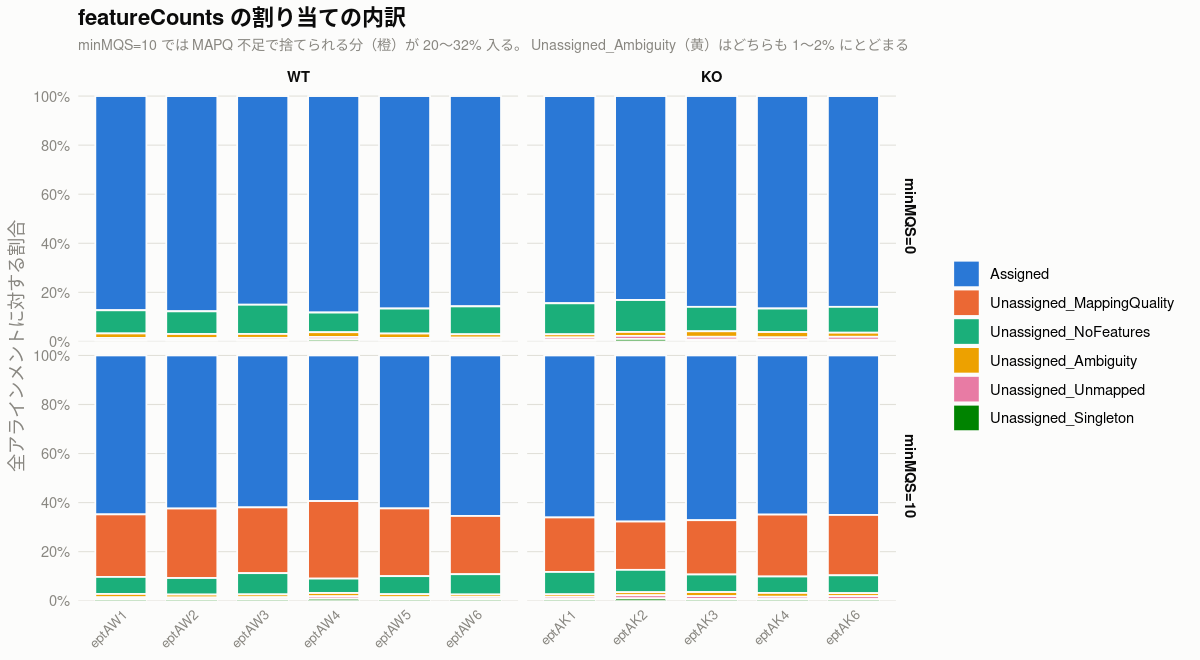

In [100]:
# ── 割り当ての内訳を図にする ─────────────────────────────────
# セル15-3 の表を1枚で見る。6区分が 100% を分け合うので積み上げ棒。
# 2通りの設定を上下に並べて、minMQS=10 で何がどれだけ削られるかを見る
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# 凡例は featureCounts の Status 名をそのまま出す（Unassigned_ を省略しない）
col_assign = c('Assigned'                  = '#2a78d6',
               'Unassigned_MappingQuality' = '#eb6834',
               'Unassigned_NoFeatures'     = '#1baf7a',
               'Unassigned_Ambiguity'      = '#eda100',
               'Unassigned_Unmapped'       = '#e87ba4',
               'Unassigned_Singleton'      = '#008300')

assign_long = assign_sum %>%
    pivot_longer(ends_with('_pct'), names_to = '区分', values_to = 'pct') %>%
    mutate(区分  = factor(sub('_pct$', '', 区分), levels = names(col_assign)),
           group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p = ggplot(assign_long, aes(x = name, y = pct, fill = 区分)) +
    geom_col(width = 0.72, colour = col_surface, linewidth = 0.5) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    scale_fill_manual(values = col_assign) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'featureCounts の割り当ての内訳',
         subtitle = paste('minMQS=10 では MAPQ 不足で捨てられる分（橙）が 20〜32% 入る。',
                          'Unassigned_Ambiguity（黄）はどちらも 1〜2% にとどまる'),
         x = NULL, y = '全アラインメントに対する割合', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-3図（英語版）: featureCounts read assignment

**中身はセル15-3図 と同じで、文字だけ英語にしたもの。**
共同研究者（Xiaoxi さん）や claude.ai への共有用。

**配色は日本語版と同じ**にしてあるので、2つの図を並べても色の対応が崩れない。
変数名も `p_en` と分けてあるので、日本語版の `p` を上書きしない。

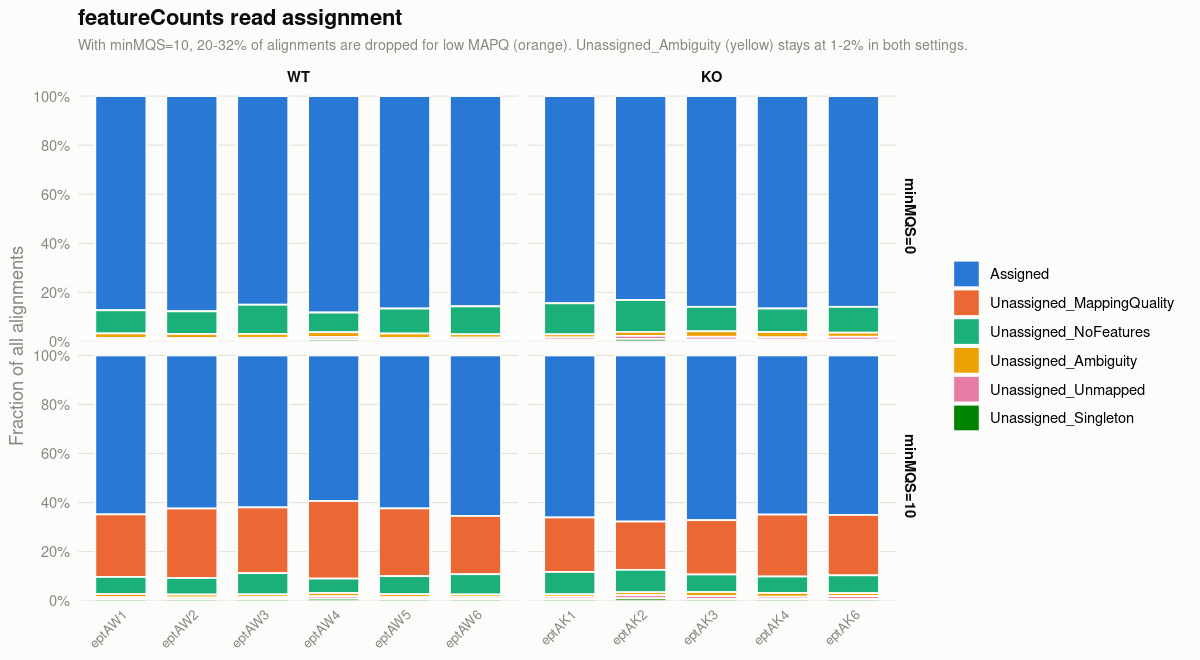

In [101]:
# ── Same figure, English labels （共同研究者と共有する用）───────
# セル15-3図 と中身は同じで、文字だけ英語にしたもの。
# 配色も同じにしてあるので、日本語版と英語版で色の対応が崩れない
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# 凡例は featureCounts の Status 名をそのまま出す（Unassigned_ を省略しない）
col_assign = c('Assigned'                  = '#2a78d6',
               'Unassigned_MappingQuality' = '#eb6834',
               'Unassigned_NoFeatures'     = '#1baf7a',
               'Unassigned_Ambiguity'      = '#eda100',
               'Unassigned_Unmapped'       = '#e87ba4',
               'Unassigned_Singleton'      = '#008300')

assign_long = assign_sum %>%
    pivot_longer(ends_with('_pct'), names_to = '区分', values_to = 'pct') %>%
    mutate(区分  = factor(sub('_pct$', '', 区分), levels = names(col_assign)),
           group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p_en = ggplot(assign_long, aes(x = name, y = pct, fill = 区分)) +
    geom_col(width = 0.72, colour = col_surface, linewidth = 0.5) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    scale_fill_manual(values = col_assign) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'featureCounts read assignment',
         subtitle = paste('With minMQS=10, 20-32% of alignments are dropped for low MAPQ (orange).',
                          'Unassigned_Ambiguity (yellow) stays at 1-2% in both settings.'),
         x = NULL, y = 'Fraction of all alignments', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p_en))

### 考察: カウント（セル15〜15-3 の結果）

**カウントは正常に取れている。群間差は出るが、すべてセル14-4 で見た群集組成の差で説明できる。**

#### 1. カウント行列

```
18,245 feature × 11 検体（2通り）
q10 と q0 で feature の並びが一致: TRUE
総カウント  q10 = 393.3 M / q0 = 525.8 M
```

**q10 / q0 = 74.8%** で、セル13-2 の MAPQ >= 10 の割合（74.02%）と一致する。
`minMQS=10` が意図どおり効いている。

#### 2. ★ Ambiguity は 1.2〜1.8%。セル10 のGTF修正が効いた

| 設定 | WT | KO | p |
|---|---|---|---|
| minMQS=0 | 1.69%（1.36-1.91） | 1.79%（1.28-2.24） | 0.9307 |
| minMQS=10 | 1.21%（1.01-1.36） | 1.34%（1.01-1.67） | 0.5209 |

セル10-2 で残した CDS–CDS 重なり（1,705組、中央値 4 bp）のコストが **1〜2%** と確定した。
**群間差も無い。**

もし eptA の親CDS や pME008 の由来ラベルを除いていなければ、
ここは数%以上に膨らみ、eptA と pME008 の CDS は**すべてゼロ**になっていた。

#### 3. minMQS=0 では Assigned に群間差が無い

| Status | WT | KO | 差 | p |
|---|---|---|---|---|
| `Assigned` | 86.81% | 85.23% | +1.58 | 0.1432 |
| `Unassigned_NoFeatures` | 10.02% | 11.14% | −1.12 | 0.2468 |
| `Unassigned_Ambiguity` | 1.69% | 1.79% | −0.10 | 0.9307 |
| `Unassigned_Unmapped` | 0.81% | 1.10% | −0.30 | **0.0173 ★** |
| `Unassigned_Singleton` | 0.68% | 0.74% | −0.06 | 0.2711 |

Unmapped だけ p < 0.05 だが**差は 0.30 ポイント**で実質的に無視できる
（セル14-8 の マップ率 と同じ話）。

#### 4. minMQS=10 の群間差は組成の差で説明できる

| Status | WT | KO | 差 | p |
|---|---|---|---|---|
| **`Assigned`** | **62.72%** | **66.17%** | **−3.45** | **0.0173 ★** |
| **`Unassigned_MappingQuality`** | **27.27%** | **22.78%** | **+4.49** | **0.0173 ★** |
| `Unassigned_NoFeatures` | 7.31% | 7.87% | −0.56 | 0.5368 |
| `Unassigned_Ambiguity` | 1.21% | 1.34% | −0.12 | 0.5209 |

**Bth計% と Assigned(q10)% の相関は r = −0.826（p = 0.0017）。**
Bth 2株が多い W群ほど MAPQ が足りないリードが増え、Assigned が下がる。
**マッピングやカウントの不具合ではなく、群集組成の差の写し絵**で、
セル14-4・14-8 と同じ構図。

#### 5. NoFeatures の正体は宿主リード

**mouse% と NoFeatures(q0)% の相関は r = 0.932（p = 0.00003）。**
GTF にマウスの feature は入れていないので、宿主リードはすべてここに落ちる。
残りは遺伝子間領域。

#### 6. DE への影響

`minMQS=10` では **W群のカウントが系統的に 3.45 ポイント低く出る**が、

- **方針 (B)（株ごと独立 DESeq2、主）**: 株ごとに size factor を取るので吸収される
- **方針 (A)（全株プール、従）**: セル14-4 の考察に書いたとおり、組成の差が出る

いずれも **DESeq2 の size factor が検体ごとの総量差を扱う**ので、
この 3.45 ポイントそのものが問題になることはない。
**問題になるのは「特定の遺伝子だけが偏って削られる」場合**だが、
削られているのは Bth 2株間で判別できないリードなので、
**Bth の共通領域の遺伝子に偏って効く。**
→ **セル15-6 の Bth_VPI : Bth_St8 比と、2通りのカウントの相関（ステージ4）で確認する。**

## セル15-4: biotype 別の内訳（rRNA% の確定）

GTF の `biotype` 属性を feature ごとに引いて、カウントを足し上げる。
**CLAUDE.md §7 ステージ4 の「rRNA%」はここで確定する。**

**★ `ncRNA` は中身に分けて出す。**
GTF の `biotype` は、ステージ2 セル b46 の対応表で
`tmRNA` / `RNase_P_RNA` / `SRP_RNA` / `antisense_RNA` を**まとめて `ncRNA`** にしている。
これだと表や図を見ても中身が分からないので、`product` 属性から元の種類に戻した列を作る。

| 表示名 | GTF の product | 件数 |
|---|---|---|
| `tmRNA(ncRNA)` | `transfer-messenger RNA` | 4（4株に1本ずつ） |
| `RNase_P_RNA(ncRNA)` | `RNase P RNA component class A` | 2（**Bth_VPI と Bun_8492 のみ**） |

**`RNase_P_RNA` が2件しか無いのは、Bth_St8 と Odo_St23 の GFF に注釈が無いため**
（下の考察 7・8 を参照）。実際には4株とも持っているが、
注釈の無い2株では `Unassigned_NoFeatures` に落ちている。

eptAW1 のサブサンプルでの先取り値は CDS 68.5% / **ncRNA 25.8%** / rRNA 5.5% / tRNA 0.1% で、
**rRNA は過去データ（37〜56%）を大きく下回り、代わりに ncRNA（tmRNA・RNase P RNA）が
6 feature だけで 1/4 を占めていた**（セル7 の考察の訂正を参照）。

→ **ステージ5 では CDS 以外（rRNA・ncRNA・tRNA）を DE 対象から外し、
size factor も CDS のみのカウント行列で計算する。**
tmRNA 1遺伝子が全体の 15% を占める状態で size factor を取ると、
その1遺伝子の変動が全遺伝子に伝播してしまう。

In [115]:
# ── biotype 別の内訳（rRNA% の確定）───────────────────────────
# GTF の biotype 属性を feature ごとに引いて、カウントを足し上げる。
# CLAUDE.md §7 ステージ4 の「rRNA%」はここで確定する。
# ステージ5 では CDS 以外（rRNA・ncRNA・tRNA）を DE 対象から外し、
# size factor も CDS のみで計算する

if (!exists('gtf_count')) {
    gtf_count = read.table(path_gtf_count, sep="\t", header=FALSE, quote="",
                           comment.char="", stringsAsFactors=FALSE)
    colnames(gtf_count) = c('contig','source','feature','start','end',
                            'score','strand','frame','attr')
    gtf_count$gene_id = str_match(gtf_count$attr, '^gene_id "([^"]+)"')[,2]
}

# feature ごとの biotype と株（同じ gene_id が複数行あるので1行にまとめる）
#
# ★ biotype の "ncRNA" は tmRNA と RNase_P_RNA をまとめた名前（ステージ2 セル b46 の KEEP）。
#   それだと図を見ても中身が分からないので、product から元の種類に戻した列も作る。
#   実際に入っているのは tmRNA 4件 と RNase P RNA 2件のみ
feat_info = gtf_count %>%
    mutate(biotype = str_match(attr, 'biotype "([^"]*)"')[,2],
           product = str_match(attr, 'product "([^"]*)"')[,2],
           biotype2 = case_when(
               biotype != 'ncRNA'                      ~ biotype,
               grepl('transfer-messenger', product)    ~ 'tmRNA(ncRNA)',
               grepl('RNase P', product)               ~ 'RNase_P_RNA(ncRNA)',
               TRUE                                    ~ 'other(ncRNA)'),
           strain  = sub("~.*", "", contig)) %>%
    distinct(gene_id, .keep_all = TRUE) %>%
    dplyr::select(gene_id, biotype, biotype2, product, strain)

bio = data.frame()
for (q in c(10, 0)) {
    m  = cnt[[paste0('q', q)]]
    bt = feat_info$biotype2[match(rownames(m), feat_info$gene_id)]
    for (s in colnames(m)) {
        agg = tapply(m[, s], bt, sum)
        bio = rbind(bio, data.frame(
            name = s, group = seq_list$group[seq_list$name == s],
            設定 = paste0('minMQS=', q),
            CDS_pct              = round(100 * agg['CDS']                / sum(agg), 2),
            `tmRNA(ncRNA)_pct`   = round(100 * agg['tmRNA(ncRNA)']       / sum(agg), 2),
            `RNase_P_RNA(ncRNA)_pct` = round(100 * agg['RNase_P_RNA(ncRNA)'] / sum(agg), 2),
            rRNA_pct             = round(100 * agg['rRNA']               / sum(agg), 2),
            tRNA_pct             = round(100 * agg['tRNA']               / sum(agg), 2),
            CDS_M                = round(agg['CDS'] / 1e6, 1),
            row.names = NULL, check.names = FALSE))
    }
}

bio %>% arrange(設定, factor(group, levels = c('WT','KO')), name) %>% as.data.frame()

name,group,設定,CDS_pct,tmRNA(ncRNA)_pct,RNase_P_RNA(ncRNA)_pct,rRNA_pct,tRNA_pct,CDS_M
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,minMQS=0,68.62,20.66,4.85,5.74,0.13,33.5
eptAW2,WT,minMQS=0,66.49,20.69,6.00,6.68,0.15,30.2
eptAW3,WT,minMQS=0,68.68,20.70,5.66,4.86,0.11,25.4
eptAW4,WT,minMQS=0,65.93,15.69,5.47,12.65,0.25,30.2
eptAW5,WT,minMQS=0,68.37,21.72,5.64,4.13,0.14,38.6
eptAW6,WT,minMQS=0,56.62,29.01,9.84,4.43,0.11,21.3
eptAK1,KO,minMQS=0,56.02,30.43,10.85,2.45,0.26,28.0
eptAK2,KO,minMQS=0,57.58,27.38,11.57,3.17,0.31,22.1
eptAK3,KO,minMQS=0,69.82,19.50,7.65,2.40,0.62,54.4


## セル15-4図: biotype 別の内訳（株は区別しない）

セル15-4 の表を1枚で見る。**まず全体を biotype だけで俯瞰する。**
株の内訳を重ねた図は**セル15-4図-2**。

| encoding | 何を表すか |
|---|---|
| 色 | **biotype**。下から CDS → tmRNA → RNase_P_RNA → rRNA → tRNA → other |
| **灰色の区分線** | **各 biotype の帯の上端を検体間で結んだもの**（Excel の「区分線」と同じ） |
| 上下のパネル | `minMQS` の2設定 |
| 左右のパネル | W群 / K群 |

**色は セル15-4図-2 で「縁」に使うものと同じ**にしてある
（CDS = 緑、tmRNA = 紫、RNase_P_RNA = 赤、rRNA = 青、tRNA = 橙、other = 水色）。
2枚を並べたときに同じ biotype が同じ色で読める。

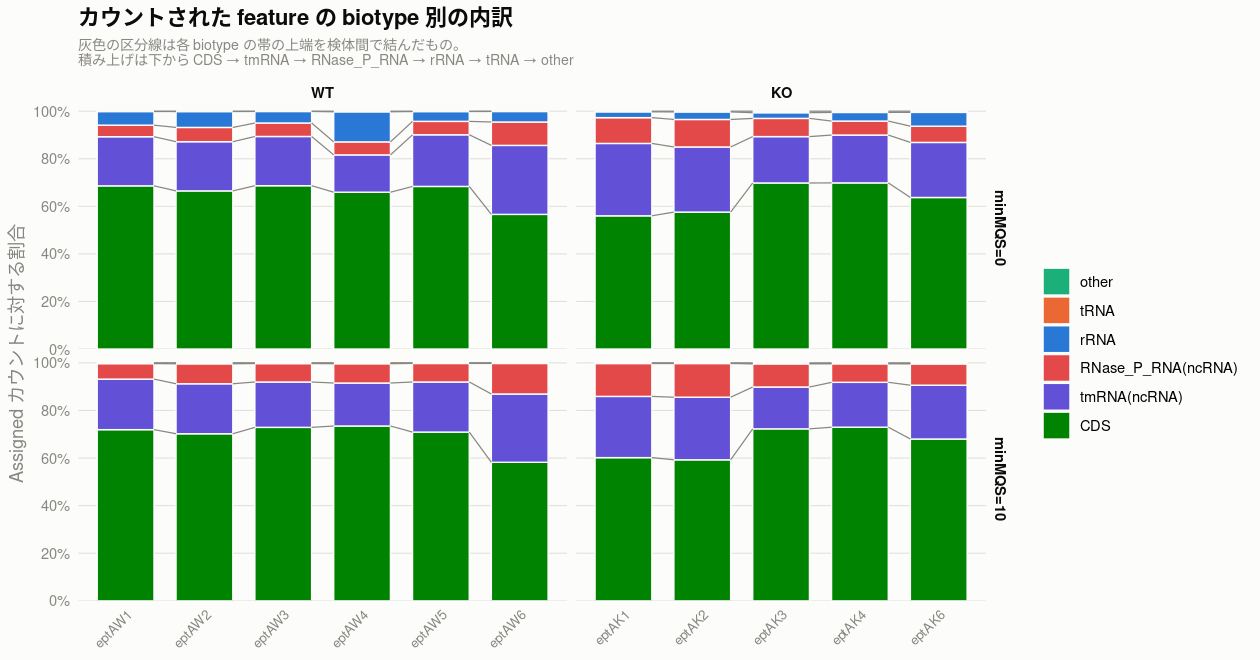

In [120]:
# ── biotype の内訳（株は区別しない）─────────────────────────
# まず全体を biotype だけで見る。株ごとの内訳はセル15-4図-2。
# 色は セル15-4図-2 で「縁」に使うものと同じにしてあるので、2枚を並べて読める
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

col_bio_edge = c('CDS'                = '#008300',
                 'tmRNA(ncRNA)'       = '#6250d6',
                 'RNase_P_RNA(ncRNA)' = '#e34948',
                 'rRNA'               = '#2a78d6',
                 'tRNA'               = '#eb6834',
                 'other'              = '#1baf7a')
bio_order = names(col_bio_edge)

# 検体 × biotype で集計して、検体内の割合にする
seg_bio = data.frame()
for (q in c(10, 0)) {
    m   = cnt[[paste0('q', q)]]
    idx = match(rownames(m), feat_info$gene_id)
    for (s in colnames(m)) {
        agg = tapply(m[, s], feat_info$biotype2[idx], sum)
        agg[is.na(agg)] = 0
        seg_bio = rbind(seg_bio, data.frame(
            name = s, group = seq_list$group[seq_list$name == s],
            設定 = paste0('minMQS=', q), biotype = names(agg),
            カウント = as.numeric(agg), row.names = NULL))
    }
}

seg_bio = seg_bio %>%
    group_by(name, 設定) %>% mutate(pct = 100 * カウント / sum(カウント)) %>% ungroup() %>%
    mutate(biotype = factor(biotype, levels = bio_order),
           group   = factor(group, levels = c('WT','KO')),
           設定    = factor(設定, levels = c('minMQS=0','minMQS=10'))) %>%
    arrange(name, 設定, biotype)

# 区分線（棒の右端から次の棒の左端まで）。各 biotype の帯の上端を結ぶ
bar_w = 0.72
link_bio = seg_bio %>%
    group_by(name, group, 設定) %>%
    arrange(biotype, .by_group = TRUE) %>%
    mutate(y = cumsum(pct)) %>%
    ungroup() %>%
    filter(biotype != tail(bio_order, 1)) %>%
    group_by(設定, group) %>%
    mutate(xi = as.integer(factor(name))) %>%        # パネル内での位置
    group_by(設定, group, biotype) %>%
    arrange(xi, .by_group = TRUE) %>%
    mutate(yend = lead(y)) %>%
    ungroup() %>%
    filter(!is.na(yend))

options(repr.plot.width = 10.5, repr.plot.height = 5.5)

p = ggplot(seg_bio, aes(x = name, y = pct, fill = biotype)) +
    geom_col(width = bar_w, colour = col_surface, linewidth = 0.4,
             position = position_stack(reverse = TRUE)) +
    geom_segment(data = link_bio, inherit.aes = FALSE,
                 aes(x = xi + bar_w/2, xend = xi + 1 - bar_w/2, y = y, yend = yend),
                 colour = col_muted, linewidth = 0.35) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    scale_fill_manual(values = col_bio_edge) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill = guide_legend(reverse = TRUE)) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'カウントされた feature の biotype 別の内訳',
         subtitle = paste0('灰色の区分線は各 biotype の帯の上端を検体間で結んだもの。\n',
                           '積み上げは下から CDS → tmRNA → RNase_P_RNA → rRNA → tRNA → other'),
         x = NULL, y = 'Assigned カウントに対する割合', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-4図（英語版）: Assigned counts by feature biotype

**中身はセル15-4図 と同じで、文字だけ英語にしたもの。** 配色も同じ。

集計（`seg_bio` / `link_bio`）はセル15-4図 で作ったものをそのまま使うので、
**このセルだけを動かす場合は先にセル15-4図 を実行する。**

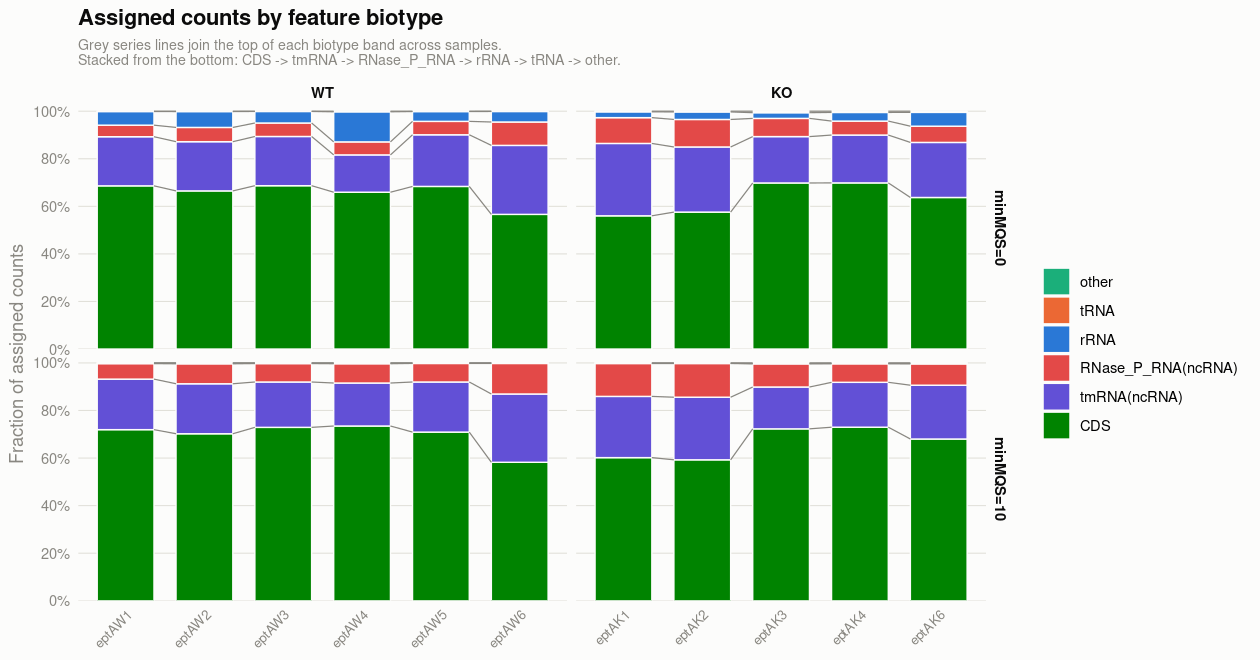

In [121]:
# ── Same figure, English labels（共同研究者と共有する用）────────
# セル15-4図 と中身は同じで、文字だけ英語にしたもの。配色も同じ
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

col_bio_edge = c('CDS'                = '#008300',
                 'tmRNA(ncRNA)'       = '#6250d6',
                 'RNase_P_RNA(ncRNA)' = '#e34948',
                 'rRNA'               = '#2a78d6',
                 'tRNA'               = '#eb6834',
                 'other'              = '#1baf7a')
bio_order = names(col_bio_edge)

# 検体 × biotype で集計して、検体内の割合にする
# 集計（seg_bio・link_bio）はセル15-4図 で作ったものをそのまま使う

options(repr.plot.width = 10.5, repr.plot.height = 5.5)

p_en = ggplot(seg_bio, aes(x = name, y = pct, fill = biotype)) +
    geom_col(width = bar_w, colour = col_surface, linewidth = 0.4,
             position = position_stack(reverse = TRUE)) +
    geom_segment(data = link_bio, inherit.aes = FALSE,
                 aes(x = xi + bar_w/2, xend = xi + 1 - bar_w/2, y = y, yend = yend),
                 colour = col_muted, linewidth = 0.35) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    scale_fill_manual(values = col_bio_edge) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill = guide_legend(reverse = TRUE)) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'Assigned counts by feature biotype',
         subtitle = paste0('Grey series lines join the top of each biotype band across samples.\n',
                           'Stacked from the bottom: CDS -> tmRNA -> RNase_P_RNA -> rRNA -> tRNA -> other.'),
         x = NULL, y = 'Fraction of assigned counts', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p_en))

## セル15-4図-2: biotype × 株の内訳

セル15-4図（株を区別しない版）に**株の内訳を重ねたもの。**
**biotype の帯の中をさらに株で塗り分ける。**

**1つの四角に2つの情報を載せる。**

| encoding | 何を表すか |
|---|---|
| **四角の塗り（薄い色）** | **株**（Bun_8492 / Bth_St8 / Bth_VPI / Odo_St23 / pME008） |
| **四角の縁（濃い太線）** | **biotype**（CDS / tmRNA / RNase_P_RNA / rRNA / tRNA / other） |
| 積み上げの位置 | biotype。下から CDS → tmRNA → RNase_P_RNA → rRNA → tRNA → other |
| **灰色の区分線** | **各 biotype の帯の上端を検体間で結んだもの**（Excel の「区分線」と同じ）。biotype の割合が検体でどう動くかを追える |
| 上下のパネル | `minMQS` の2設定 |
| 左右のパネル | W群 / K群 |

**縁と塗りで色が衝突しないように割り当ててある。**
面積の大きい CDS / tmRNA / RNase_P には、株で使っていない**緑・紫・赤**を当てた。
残りの rRNA / tRNA / other は帯が 1% 未満なので、色が株と重なっても実害が無い。
縁の6色は検証スクリプトに通してあり、隣り合う色のCVD分離 ΔE 9.2 で基準を満たす。

塗りは `scales::alpha(..., 0.45)` で薄くして、**縁の色が主役になる**ようにしている。

**この1枚で「どの biotype がどれだけあり、その中でどの株が効いているか」が同時に読める。**
例えば CDS 帯の中で Bun が 39/68 を占める、tmRNA 帯の大半が Bun 由来、といったこと。

**実装の注意**: 積み上げの順を `積み上げ順` という明示的な因子で作っている。
`interaction(biotype, 株)` を使うと**「株が外側」の順序**になり、
CDS と tmRNA が株ごとに混ざって積み上がってしまう（最初これで間違えた）。

縦軸は**検体全体の Assigned カウントに対する割合**。
株ごとに 100% へ正規化した図は**セル15-4図-3**（株の内部構成を見る用）。

**区分線は棒の端から次の棒の端まで**を結ぶ（中心どうしではない）。
離散軸なので、`geom_segment` に**パネル内での位置を自分で振って**渡している。
`facet` が `scales = 'free_x'` なので、**パネルごとに振り直す**必要がある点に注意。


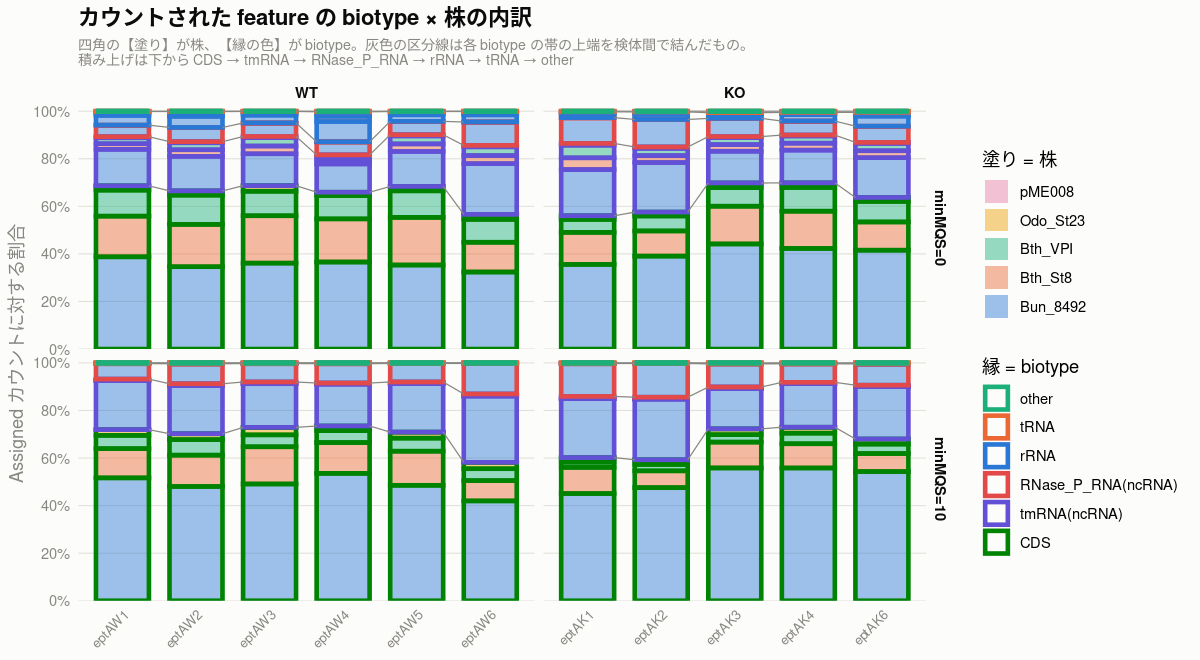

In [122]:
# ── biotype × 株 の内訳を1枚で見る ───────────────────────────
# 1つの四角に2つの情報を載せる。
#   塗り = 株（5色。薄く塗る）
#   縁   = biotype（6色。太く濃く描く）
# 積み上げの順は biotype（下から CDS → tmRNA → RNase P → rRNA → tRNA → other）。
# こうすると「どの biotype がどれだけあり、その中でどの株が効いているか」が1枚で見える
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

col_strain5 = c('Bun_8492' = '#2a78d6', 'Bth_St8' = '#eb6834', 'Bth_VPI' = '#1baf7a',
                'Odo_St23' = '#eda100', 'pME008'  = '#e87ba4')

# 縁の色（biotype）。塗り（株）と同じ色にならないよう、
# 面積の大きい CDS / tmRNA / RNase P には株で使っていない緑・紫・赤を割り当てる。
# 残りの rRNA / tRNA / other は帯が 1% 未満なので色が重なっても実害がない
col_bio_edge = c('CDS'                = '#008300',
                 'tmRNA(ncRNA)'       = '#6250d6',
                 'RNase_P_RNA(ncRNA)' = '#e34948',
                 'rRNA'               = '#2a78d6',
                 'tRNA'               = '#eb6834',
                 'other'              = '#1baf7a')
bio_order   = names(col_bio_edge)

# 検体 × biotype × 株 ごとに集計して、検体内の割合にする
seg = data.frame()
for (q in c(10, 0)) {
    m   = cnt[[paste0('q', q)]]
    idx = match(rownames(m), feat_info$gene_id)
    for (s in colnames(m)) {
        agg = tapply(m[, s], list(feat_info$biotype2[idx], feat_info$strain[idx]), sum)
        agg[is.na(agg)] = 0
        for (b in rownames(agg)) seg = rbind(seg, data.frame(
            name = s, group = seq_list$group[seq_list$name == s],
            設定 = paste0('minMQS=', q), biotype = b, 株 = colnames(agg),
            カウント = as.numeric(agg[b, ]), row.names = NULL))
    }
}

seg = seg %>%
    group_by(name, 設定) %>% mutate(pct = 100 * カウント / sum(カウント)) %>% ungroup() %>%
    mutate(biotype = factor(biotype, levels = bio_order),
           株      = factor(株, levels = names(col_strain5)),
           group   = factor(group, levels = c('WT','KO')),
           設定    = factor(設定, levels = c('minMQS=0','minMQS=10'))) %>%
    arrange(name, 設定, biotype, 株)

# 積み上げの順を明示的に作る。biotype を外側、株を内側にする
#   （interaction(biotype, 株) だと「株が外側」になってしまい、
#     CDS と tmRNA が株ごとに混ざって積み上がる）
seg_levels = c()
for (b in bio_order) for (st in names(col_strain5)) {
    seg_levels = c(seg_levels, paste(b, st, sep = ' | '))
}
seg$積み上げ順 = factor(paste(seg$biotype, seg$株, sep = ' | '), levels = seg_levels)

# 各 biotype の帯の上端（積み上げの累積）。検体をまたいで点線でつなぐと、
# biotype の割合が検体間でどう動いているかが追える。
# 一番上（other）の上端は必ず 100% なので描かない
bnd = seg %>%
    group_by(name, group, 設定, biotype) %>%
    summarise(pct = sum(pct), .groups = 'drop') %>%
    group_by(name, group, 設定) %>%
    arrange(biotype, .by_group = TRUE) %>%
    mutate(y = cumsum(pct)) %>%
    ungroup() %>%
    filter(biotype != tail(bio_order, 1))

# 区分線（Excel の「区分線」と同じもの）。
# 棒の中心どうしをつなぐのではなく、【棒の右端から次の棒の左端まで】を結ぶ。
#   x はカテゴリ軸なので、パネル内での位置（1, 2, 3 …）を自分で振る。
#   facet は scales='free_x' なのでパネルごとに振り直す必要がある
bar_w = 0.72
link = bnd %>%
    group_by(設定, group) %>%
    # seg$name は文字列。group_by の中で factor() を作ると、そのパネルに居る検体だけで
    # アルファベット順の水準ができる。ggplot の離散軸の並びと同じになる
    mutate(xi = as.integer(factor(name))) %>%          # パネル内での位置
    group_by(設定, group, biotype) %>%
    arrange(xi, .by_group = TRUE) %>%
    mutate(yend = lead(y)) %>%                          # 次の検体での高さ
    ungroup() %>%
    filter(!is.na(yend))

options(repr.plot.width = 10, repr.plot.height = 5.5)

p = ggplot(seg, aes(x = name, y = pct, fill = 株, colour = biotype, group = 積み上げ順)) +
    # reverse = TRUE で、並べた順（CDS が先頭）が下から積み上がる
    geom_col(width = 0.72, linewidth = 1.3,
             position = position_stack(reverse = TRUE)) +
    # 区分線。棒の端から次の棒の端までを薄いグレーの実線で結ぶ
    geom_segment(data = link, inherit.aes = FALSE,
                 aes(x = xi + bar_w/2, xend = xi + 1 - bar_w/2, y = y, yend = yend),
                 colour = col_muted, linewidth = 0.35) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    # 塗りは薄く（縁の色が主役になるように）。縁は不透明のまま
    scale_fill_manual(values = scales::alpha(col_strain5, 0.45)) +
    scale_colour_manual(values = col_bio_edge) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill   = guide_legend(reverse = TRUE, title = '塗り = 株', order = 1,
                                 override.aes = list(colour = NA)),
           colour = guide_legend(reverse = TRUE, title = '縁 = biotype', order = 2,
                                 override.aes = list(fill = NA, linewidth = 1.3))) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'カウントされた feature の biotype × 株の内訳',
         # 1行だと右で切れるので2行に分ける
         subtitle = paste0('四角の【塗り】が株、【縁の色】が biotype。',
                           '灰色の区分線は各 biotype の帯の上端を検体間で結んだもの。\n',
                           '積み上げは下から CDS → tmRNA → RNase_P_RNA → rRNA → tRNA → other'),
         x = NULL, y = 'Assigned カウントに対する割合') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-4図-2（英語版）: Assigned counts by feature biotype and strain

**中身はセル15-4図-2 と同じで、文字だけ英語にしたもの。** 配色も同じ。

集計（`seg` / `bnd` / `link`）はセル15-4図-2 で作ったものをそのまま使うので、
**このセルだけを動かす場合は先にセル15-4図-2 を実行する。**

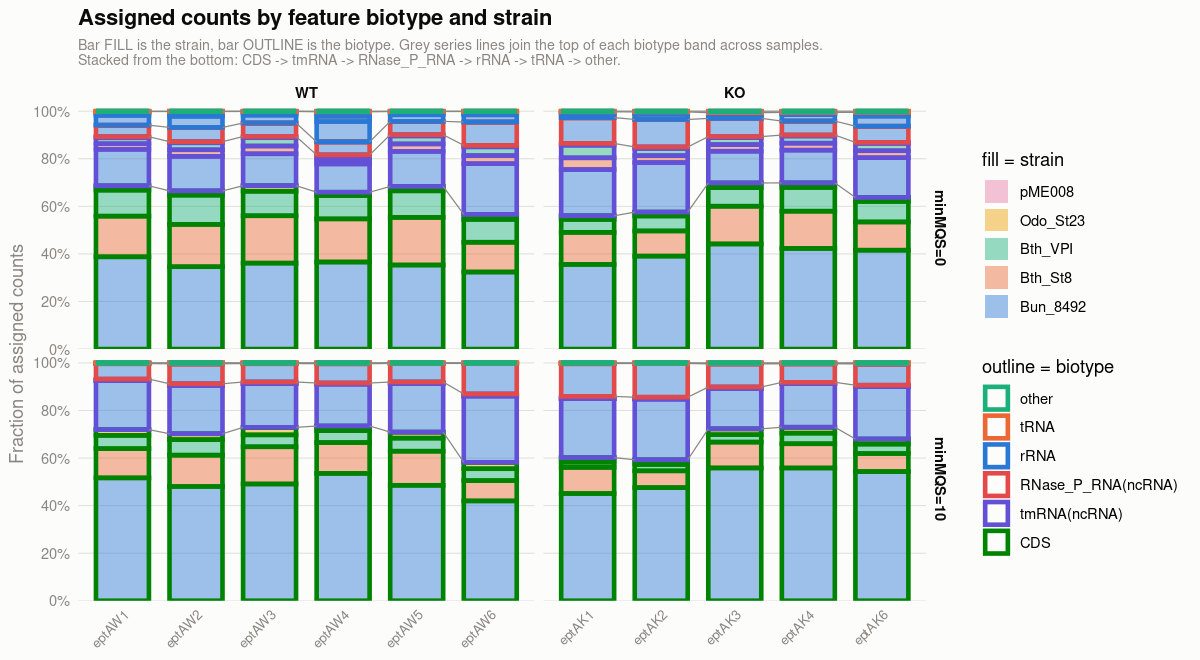

In [123]:
# ── Same figure, English labels（共同研究者と共有する用）────────
# セル15-4図 と中身は同じで、文字だけ英語にしたもの。配色も同じ
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

col_strain5 = c('Bun_8492' = '#2a78d6', 'Bth_St8' = '#eb6834', 'Bth_VPI' = '#1baf7a',
                'Odo_St23' = '#eda100', 'pME008'  = '#e87ba4')

# 縁の色（biotype）。塗り（株）と同じ色にならないよう、
# 面積の大きい CDS / tmRNA / RNase P には株で使っていない緑・紫・赤を割り当てる。
# 残りの rRNA / tRNA / other は帯が 1% 未満なので色が重なっても実害がない
col_bio_edge = c('CDS'                = '#008300',
                 'tmRNA(ncRNA)'       = '#6250d6',
                 'RNase_P_RNA(ncRNA)' = '#e34948',
                 'rRNA'               = '#2a78d6',
                 'tRNA'               = '#eb6834',
                 'other'              = '#1baf7a')
bio_order   = names(col_bio_edge)

# 検体 × biotype × 株 ごとに集計して、検体内の割合にする
# 集計（seg・bnd・link）はセル15-4図 で作ったものをそのまま使う

options(repr.plot.width = 10, repr.plot.height = 5.5)

p_en = ggplot(seg, aes(x = name, y = pct, fill = 株, colour = biotype, group = 積み上げ順)) +
    # reverse = TRUE で、並べた順（CDS が先頭）が下から積み上がる
    geom_col(width = 0.72, linewidth = 1.3,
             position = position_stack(reverse = TRUE)) +
    # 区分線。棒の端から次の棒の端までを薄いグレーの実線で結ぶ
    geom_segment(data = link, inherit.aes = FALSE,
                 aes(x = xi + bar_w/2, xend = xi + 1 - bar_w/2, y = y, yend = yend),
                 colour = col_muted, linewidth = 0.35) +
    facet_grid(設定 ~ group, scales = 'free_x', space = 'free_x') +
    # 塗りは薄く（縁の色が主役になるように）。縁は不透明のまま
    scale_fill_manual(values = scales::alpha(col_strain5, 0.45)) +
    scale_colour_manual(values = col_bio_edge) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill   = guide_legend(reverse = TRUE, title = 'fill = strain', order = 1,
                                 override.aes = list(colour = NA)),
           colour = guide_legend(reverse = TRUE, title = 'outline = biotype', order = 2,
                                 override.aes = list(fill = NA, linewidth = 1.3))) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 20), labels = function(x) paste0(x, '%')) +
    labs(title = 'Assigned counts by feature biotype and strain',
         subtitle = paste0('Bar FILL is the strain, bar OUTLINE is the biotype. ',
                           'Grey series lines join the top of each biotype band across samples.\n',
                           'Stacked from the bottom: CDS -> tmRNA -> RNase_P_RNA -> rRNA -> tRNA -> other.'),
         x = NULL, y = 'Fraction of assigned counts') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p_en))

## セル15-4図-3: biotype の内訳を株ごとに分ける

セル15-4図・15-4図-2 は**検体全体に対する割合**だった。株ごとに分けると次が見える。

| 見えること | なぜ分けないと見えないか |
|---|---|
| **どの株の tmRNA が多いのか** | 合算だと「ncRNA が 1/4〜2/5」としか分からない |
| **`RNase_P_RNA` が Bth_VPI と Bun_8492 にしか無いこと** | 注釈の非対称（考察 7・8）が図で確認できる |
| **rRNA の残り方が株で違うこと** | 株ごとに rRNA オペロン数もコピー間の類似度も違う |

**縦軸はその株の Assigned カウントに対する割合**（株ごとに 100% に正規化）なので、
株の存在量の違い（Bun が 59%、Odo が 2.5%）には影響されない。

pME008 の promoter / terminator などは `biotype = "other"` なので6色目に入れてある。

**縦の細線が W群（左6本）と K群（右5本）の境目。**

**積み上げの向きと凡例の並びは セル15-4図・15-4図-2 とそろえてある**
（下から CDS → tmRNA → …、凡例も上から順に上の帯）。


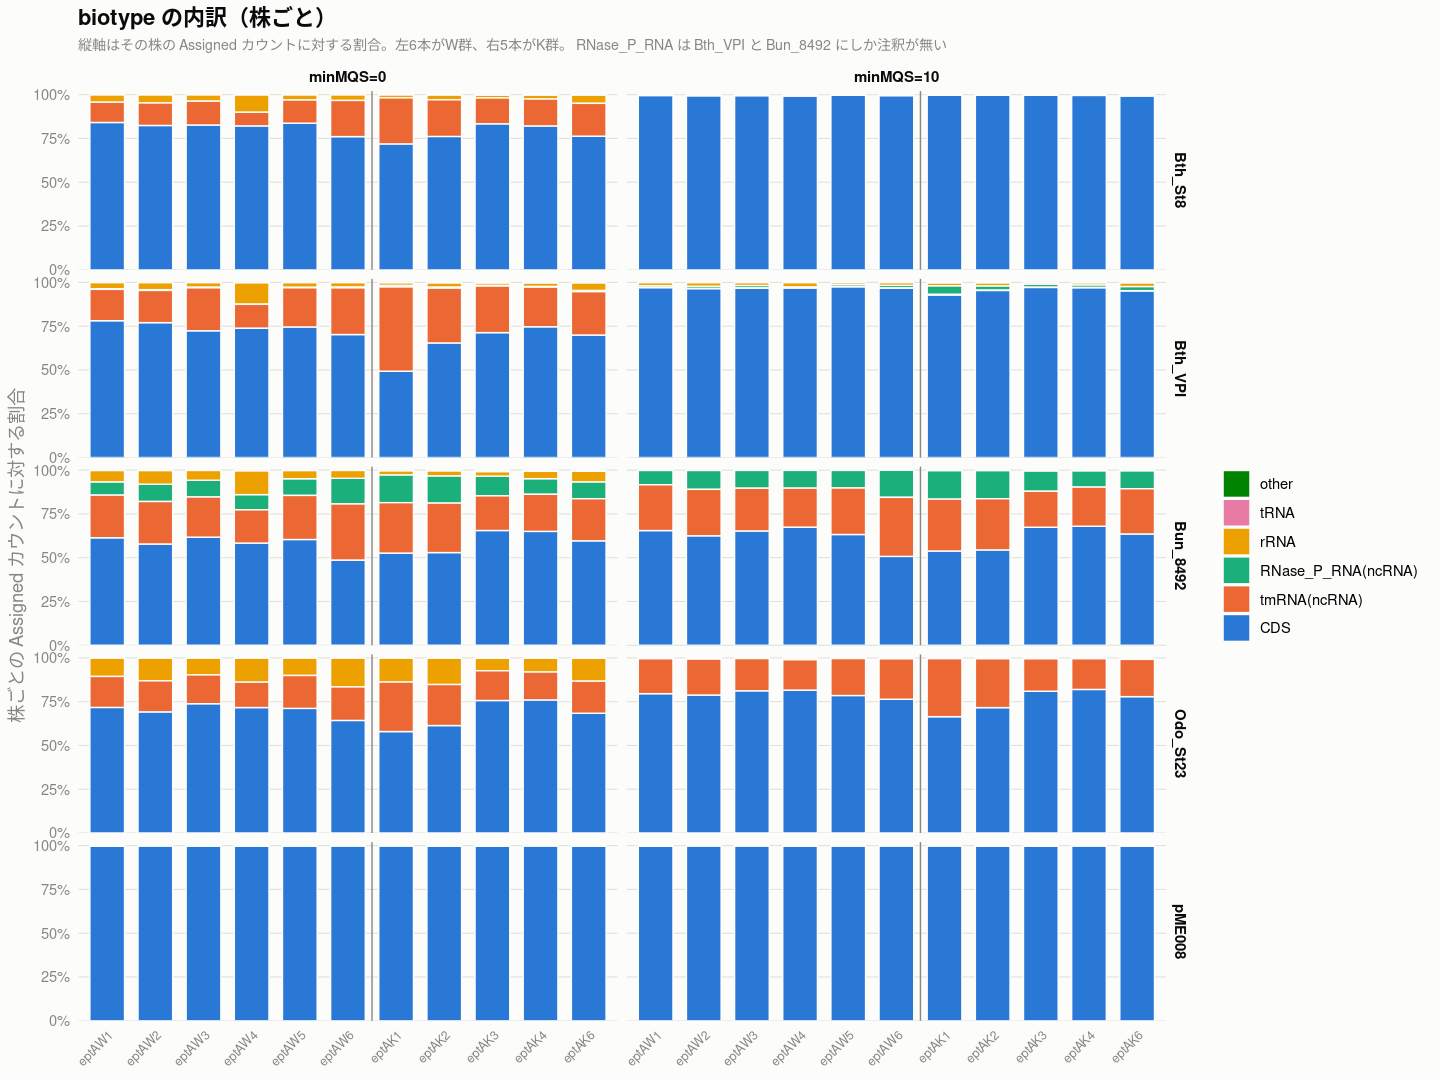

In [124]:
# ── biotype の内訳を株ごとに分ける ───────────────────────────
# セル15-4図 は4株＋プラスミドを合算したもの。株ごとに分けると
#   ・どの株の tmRNA が多いのか
#   ・RNase P RNA が Bth_VPI と Bun_8492 にしか注釈されていないこと
#   ・rRNA の残り方が株で違うこと
# が見える

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# pME008 の promoter / terminator などは biotype が "other"。6色目に入れる
col_bio2 = c('CDS'                = '#2a78d6',
             'tmRNA(ncRNA)'       = '#eb6834',
             'RNase_P_RNA(ncRNA)' = '#1baf7a',
             'rRNA'               = '#eda100',
             'tRNA'               = '#e87ba4',
             'other'              = '#008300')

bio_strain = data.frame()
for (q in c(10, 0)) {
    m   = cnt[[paste0('q', q)]]
    idx = match(rownames(m), feat_info$gene_id)
    for (s in colnames(m)) {
        # 株 × biotype2 ごとに合計する
        agg = tapply(m[, s], list(feat_info$strain[idx], feat_info$biotype2[idx]), sum)
        agg[is.na(agg)] = 0
        for (st in rownames(agg)) {
            bio_strain = rbind(bio_strain, data.frame(
                name = s, group = seq_list$group[seq_list$name == s],
                設定 = paste0('minMQS=', q), 株 = st,
                biotype = colnames(agg), カウント = as.numeric(agg[st, ]),
                row.names = NULL))
        }
    }
}

bio_strain = bio_strain %>%
    group_by(name, 設定, 株) %>%
    mutate(pct = 100 * カウント / sum(カウント)) %>%
    ungroup() %>%
    mutate(biotype = factor(biotype, levels = names(col_bio2)),
           株      = factor(株, levels = c('Bth_St8','Bth_VPI','Bun_8492','Odo_St23','pME008')),
           設定    = factor(設定, levels = c('minMQS=0','minMQS=10')),
           # W群を左、K群を右に並べる
           name    = factor(name, levels = c(sort(seq_list$name[seq_list$group == 'WT']),
                                             sort(seq_list$name[seq_list$group == 'KO']))))

options(repr.plot.width = 12, repr.plot.height = 9)

p = ggplot(bio_strain, aes(x = name, y = pct, fill = biotype)) +
    # 15-4図・15-4図-2 と同じく、最初の水準（CDS）を下に積む
    geom_col(width = 0.72, colour = col_surface, linewidth = 0.4,
             position = position_stack(reverse = TRUE)) +
    # W群（左6本）と K群（右5本）の境目
    geom_vline(xintercept = sum(seq_list$group == 'WT') + 0.5,
               colour = col_muted, linewidth = 0.4) +
    facet_grid(株 ~ 設定) +
    scale_fill_manual(values = col_bio2, drop = FALSE) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill = guide_legend(reverse = TRUE)) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 25), labels = function(x) paste0(x, '%')) +
    labs(title = 'biotype の内訳（株ごと）',
         subtitle = paste('縦軸はその株の Assigned カウントに対する割合。左6本がW群、右5本がK群。',
                          'RNase_P_RNA は Bth_VPI と Bun_8492 にしか注釈が無い'),
         x = NULL, y = '株ごとの Assigned カウントに対する割合', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 7.5),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-4図-3（英語版）: Assigned counts by feature biotype, per strain

**中身はセル15-4図-3 と同じで、文字だけ英語にしたもの。** 配色も同じ。

集計（`bio_strain`）はセル15-4図-3 で作ったものをそのまま使うので、
**このセルだけを動かす場合は先にセル15-4図-3 を実行する。**

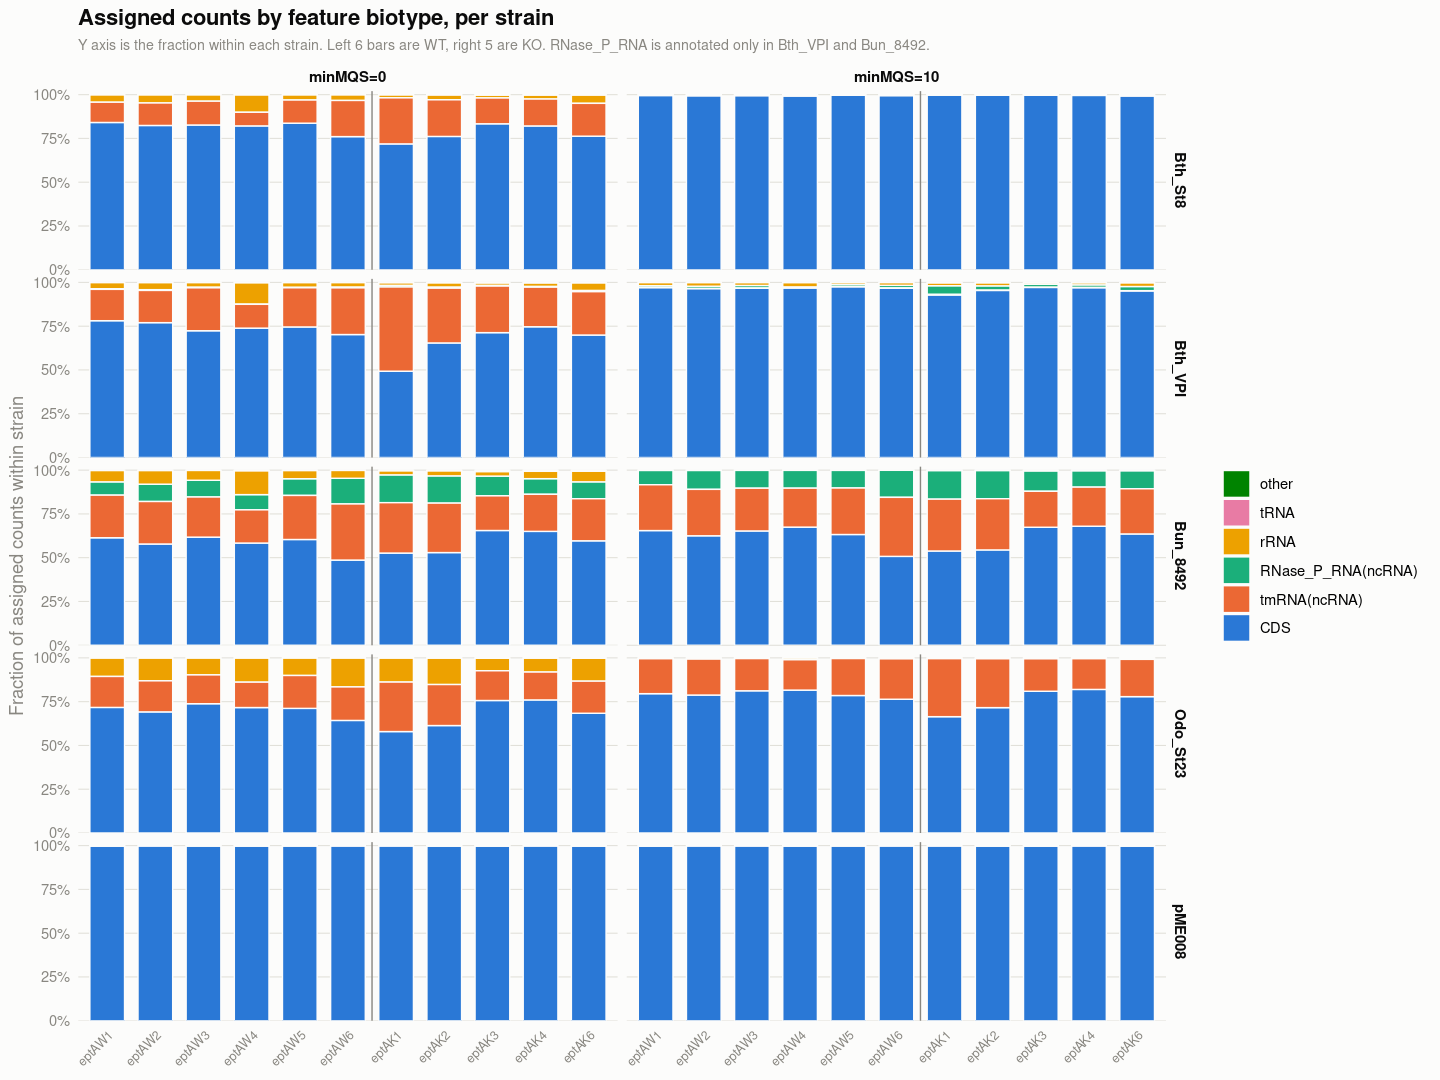

In [125]:
# ── Same figure, English labels（共同研究者と共有する用）────────
# セル15-4図-2 と中身は同じで、文字だけ英語にしたもの。配色も同じ

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# pME008 の promoter / terminator などは biotype が "other"。6色目に入れる
col_bio2 = c('CDS'                = '#2a78d6',
             'tmRNA(ncRNA)'       = '#eb6834',
             'RNase_P_RNA(ncRNA)' = '#1baf7a',
             'rRNA'               = '#eda100',
             'tRNA'               = '#e87ba4',
             'other'              = '#008300')

# 集計（bio_strain）はセル15-4図-2 で作ったものをそのまま使う

options(repr.plot.width = 12, repr.plot.height = 9)

p_en = ggplot(bio_strain, aes(x = name, y = pct, fill = biotype)) +
    # 15-4図・15-4図-2 と同じく、最初の水準（CDS）を下に積む
    geom_col(width = 0.72, colour = col_surface, linewidth = 0.4,
             position = position_stack(reverse = TRUE)) +
    # W群（左6本）と K群（右5本）の境目
    geom_vline(xintercept = sum(seq_list$group == 'WT') + 0.5,
               colour = col_muted, linewidth = 0.4) +
    facet_grid(株 ~ 設定) +
    scale_fill_manual(values = col_bio2, drop = FALSE) +
    # 凡例の並びをグラフの積み上げに合わせる。
    #   position_stack(reverse = TRUE) は「最初の水準を下」に積むが、
    #   凡例は既定で「最初の水準を上」に出すので、そのままだと上下が逆になる
    guides(fill = guide_legend(reverse = TRUE)) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.02)),
                       breaks = seq(0, 100, 25), labels = function(x) paste0(x, '%')) +
    labs(title = 'Assigned counts by feature biotype, per strain',
         subtitle = paste('Y axis is the fraction within each strain. Left 6 bars are WT, right 5 are KO.',
                          'RNase_P_RNA is annotated only in Bth_VPI and Bun_8492.'),
         x = NULL, y = 'Fraction of assigned counts within strain', fill = NULL) +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 7.5),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p_en))

### 考察: biotype 別の内訳（セル15-4 の結果）

#### 1. ★ rRNA は `minMQS=10` でほぼ消える（29分の1）

| 設定 | WT | KO | p |
|---|---|---|---|
| minMQS=0 | 6.42%（4.13-12.65） | 3.50%（2.40-5.82） | 0.0519 |
| **minMQS=10** | **0.22%（0.14-0.29）** | **0.13%（0.10-0.19）** | 0.0222 ★ |

**平均 5.09% → 0.18%。97% が MAPQ フィルタで落ちている。**

理由は2つ重なっている。

- **同一ゲノム内で rRNA オペロンが多コピー**（4株で計19オペロン。1株あたり4〜5コピー）
- **4株間で 16S / 23S がほぼ同一**

どちらも「2箇所以上に同じスコアで当たる」状況を作るので、**rRNA リードの MAPQ は 0〜1 になる。**
`minMQS=10` は rRNA を狙って落としているわけではないが、**結果として rRNA 除去として働いている。**

→ ステージ5 では biotype で CDS 以外を外す方針なので実害は無いが、
**`minMQS=10` のカウントを見るときは「rRNA はすでにほぼ無い」ことを前提にしてよい。**

#### 2. rRNA 残存率は過去データを大きく下回る

`minMQS=0` で **2.40〜12.65%**。CLAUDE.md §6-3 の過去データ（rRNA が assigned read の 37〜56%）
に対して**1桁小さい。rRNA 除去はよく効いている。**

eptAW4 だけ 12.65% と他の2〜3倍だが、`minMQS=10` では 0.26% と他と変わらないので**実害は無い。**

#### 3. ★ 非CDSの主役は ncRNA（21〜42%）。群間差は無い

| 設定 | WT | KO | p |
|---|---|---|---|
| minMQS=0 | 27.66%（21.17-38.84） | 32.67%（25.99-41.27） | 0.1775 |
| minMQS=10 | 30.11%（26.20-41.57） | 33.14%（26.69-40.49） | 0.6623 |

**たった6 feature（tmRNA 4本 + RNase P RNA 2本）が 1/4〜2/5 を占める。**

（セル15-4 の表と図は `tmRNA(ncRNA)` と `RNase_P_RNA(ncRNA)` に分けて出すので、
ここの「ncRNA」は2つの合計にあたる。eptAW1 のサブサンプルでは
`minMQS=10` で tmRNA 21.2% / RNase P 6.9% だった。）
群間差は無いが、**検体間では 26.2% から 41.6% まで 1.6倍ひらく。**

`Bth計%` との相関は **r = −0.673（p = 0.023）**。
最大の tmRNA は Bun 由来（`NQ510_RS17790`）で、Bun は Bth と裏返しの関係なので、
**Bth が少ない検体ほど ncRNA の割合が上がる。**

→ **ステージ5 では size factor を CDS のみのカウント行列で計算する。**
この 1.6倍の変動を含んだまま size factor を取ると、
**tmRNA の量の違いが全遺伝子の発現量に伝播する。**

#### 4. tRNA に群間差がある（絶対量は小さい）

| 設定 | WT | KO | WT/KO | p |
|---|---|---|---|---|
| minMQS=0 | 0.15% | 0.44% | 0.34 | **0.0080 ★** |
| minMQS=10 | 0.07% | 0.20% | 0.35 | **0.0069 ★** |

**K群が約3倍多い。** ただし絶対量は 0.2〜0.44% で、CDS を外して解析する限り影響しない。
tRNA 量は増殖速度を反映することが知られているので、
**K群の方が増殖が活発だった可能性**を示唆するが、この測定だけでは言い切れない。
**ステージ4の所見として記録にとどめる。**

#### 5. CDS に割り当てられた量（実効的な mRNA 深度）

| 設定 | WT | KO | p |
|---|---|---|---|
| minMQS=0 | 29.87 M pairs（21.3-38.6） | 32.78 M pairs（22.1-54.4） | 1.0000 |
| minMQS=10 | 22.75 M pairs（16.7-28.8） | 26.62 M pairs（18.5-44.0） | 0.7138 |

**群間差は無い。**

CLAUDE.md §7 の要求は「rRNA残存50%を前提に mRNA換算 **40〜60M read/sample**」。
**この「read」がリード本数かペア数かが文面からは確定できない**ので、両方で見る。

| 設定 | ペア数で見る | リード本数で見る（× 2） | 40M read を下回る検体 |
|---|---|---|---|
| minMQS=0 | 21.3〜54.4 M | 42.6〜108.8 M | **なし** |
| minMQS=10 | 16.7〜44.0 M | 33.4〜88.0 M | **4検体**（W3 39.2 / W6 33.4 / K2 37.0 / K6 39.2） |

**ペア数で 40M を要求するなら全検体が未達、リード本数なら `minMQS=0` は全検体達成、
`minMQS=10` でも4検体がわずかに届かない**、という状況。

ただし**この要求値は rRNA 残存 50% を前提に置いたもの**で、
実際の rRNA は 2.4〜12.7%（`minMQS=0`）と大幅に少なかった。
**前提が変わっているので、この数値をそのまま適用するのは適切でない。**
深度が足りているかは、**ステージ5 で株ごとに「count >= 10 を満たす遺伝子数」を見て判断する**
方が確実（CLAUDE.md §7 ステージ5 の prefiltering）。

#### 6. mRNA 信号が最も少ない3検体

`eptAW6` / `eptAK1` / `eptAK2` は **ncRNA が最も多く（39.6〜41.6%）、CDS_M が最も少ない**
（16.7 / 23.5 / 18.5 M pairs、`minMQS=10`）。
**W群とK群の両方に含まれるので群間比較を偏らせはしない**が、
ステージ5 で株ごとの検出力を見るときはこの3検体が律速になる。

#### 7. biotype の出どころと、株による注釈の違い

`biotype` は **4株とも NCBI/DDBJ の GFF の3列目（feature type）をそのまま写したもの**
（ステージ2 セル b46）。

```python
KEEP = {"CDS": "CDS", "rRNA": "rRNA", "tRNA": "tRNA", "tmRNA": "ncRNA",
        "ncRNA": "ncRNA", "RNase_P_RNA": "ncRNA", "SRP_RNA": "ncRNA",
        "antisense_RNA": "ncRNA"}
```

**ところが元の GFF の中身が株で違う。**

| 株 | 由来 | CDS | tRNA | rRNA | tmRNA | RNase_P_RNA | riboswitch | pseudogene |
|---|---|---|---|---|---|---|---|---|
| Bth_VPI | **RefSeq**（PGAP 再注釈） | 4,802 | 70 | 15 | 1 | **1** | **10** | **114** |
| Bth_St8 | GenBank（登録時のまま） | 4,795 | 71 | 15 | 1 | **0** | **0** | **0** |
| Bun_8492 | **RefSeq**（PGAP 再注釈） | 3,688 | 64 | 12 | 1 | **1** | **7** | **76** |
| Odo_St23 | GenBank（登録時のまま） | 4,618 | 55 | 15 | 1 | **0** | **0** | **0** |

`riboswitch` と `pseudogene` は `KEEP` に無いので GTF から落としている（意図どおり）。

**では St8 / St23 ではそれらがどこへ行ったのか。相同領域を探して確かめた。**

| 種類 | St8 での扱い | 確かめ方と結果 |
|---|---|---|
| **pseudogene** | **ふつうの CDS として注釈されている** | VPI の pseudogene 84件（300 bp 以上）を St8 にマップ。相同領域が見つかった **53件が全件、St8 では CDS**（相同領域の50%以上を覆う CDS がある）。例: VPI 147,968-149,618 の pseudogene → St8 `CE91St8_39800`（glycoside hydrolase）99.2% 一致 |
| **RNase_P_RNA** | **どこにも注釈されていない（CDS にも入らない）** | VPI の `BT_RS06655` を St8 にマップ → 3,546,417-3,546,778（96.7% 一致）。そこは **CDS 間の隙間**（隣は 3,545,061-3,546,380 と 3,546,877-3,547,863） |
| `riboswitch` | 未確認。機構上 CDS にはならないはず | 5'UTR の非コード要素なので遺伝子予測器は ORF として呼ばない |

#### 8. ★ 結論: CDS カウントは汚染されていない。ただし株間の CDS 集合は非対称

**RNase P RNA は注釈が無いので「どの feature にも入らない」= `Unassigned_NoFeatures` に落ちる。**
CDS のカウントには混ざらない。**biotype による除外は、注釈の無い構造RNAに対しても
結果的に機能している。**

ただし**その量は大きい。** eptAW1 で測った depth:

| 領域 | 平均 depth |
|---|---|
| Bth_VPI の RNase P（注釈あり・ncRNA に入る） | 19,290 |
| **Bth_St8 の RNase P（注釈なし・NoFeatures へ）** | **184,317** |
| Bth_St8 の隣の CDS `CE91St8_26570` | 96.2 |
| Bth_St8 の隣の CDS `CE91St8_26580` | 33.8 |

St8 の RNase P だけで eptAW1 の全リードの約 0.4%、
`Unassigned_NoFeatures`（6.95%）の **約6%** を占める計算になる。

**解析方針への影響**

| 項目 | 影響 |
|---|---|
| CDS カウントの正しさ | **影響なし。** 構造RNAは CDS に混入していない |
| **ncRNA% の株間比較** | **できない。** St8 / St23 には RNase P の注釈が無いので、その分 ncRNA が少なく見える |
| **CDS 集合の株間の非対称** | **St8 / St23 は pseudogene 相当の遺伝子も CDS として持つ。** VPI / Bun では同じ座位が CDS から外れている |
| 方針 (B)（株ごと独立 DESeq2、主） | **影響なし。** 株の中だけで比較する |
| **オーソログ単位の株間比較**（ステージ6 で行う場合） | **注意が要る。** 「VPI に無く St8 にある遺伝子」の一部は、実体は同じ座位の pseudogene |

→ **ステージ5・6 で株をまたいで遺伝子集合を比べるときは、
この注釈の非対称を前提に置く。** CLAUDE.md に追記する。

## セル15-5: 株ごとの CDS カウントとシェア

CLAUDE.md §7 ステージ4 の「株別CDSリード数・シェア」と**除外基準の判定**。
セル14-3 は contig 単位（rRNA や遺伝子間も含む）だったが、ここは **CDS 単位**。

### 出力は2つ

**1つ目**: 検体ごとの株シェア（`minMQS=10`。株を判別できるリードだけで見た値）。

**2つ目**: 除外基準の判定。

| 列 | 中身 |
|---|---|
| `最少の検体` | その株の CDS リードが**最も少なかった検体** |
| `その検体の総CDSリード` | **その株の CDS 全部を合計した、その1検体でのリード数** |
| `その検体のシェア_pct` | 同じ検体での、全株の CDS リードに対する割合 |
| `CDS数` | その株の CDS feature 数 |
| `CDSあたり平均` | `総CDSリード ÷ CDS数`。1遺伝子あたりの平均リード数の目安 |
| `判定` | 基準に照らした結果 |

**★ `総CDSリード` は「遺伝子ごとのリード数」ではない。**
**その株の CDS を全部足した1検体あたりの合計**で、`CDSあたり平均` が1遺伝子あたりの目安。
11検体のうち**最も少ない検体**で判定するのは、どの検体でも基準を満たしている必要があるため。

### 除外基準（CLAUDE.md §7 ステージ4）

**総CDSリード 200,000 未満、または全CDSリードの 0.1% 未満の株は株レベル解析から外す。**

過去プロジェクトでは全8検体で1リードしかない株が最後まで解析に残り、
論文の主張を支えていた。

**`pME008` はプラスミドなので「株」の判定からは外す**（0.007〜0.009% なので
機械的に判定すると必ず抵触する）。

In [127]:
# ── 株ごとの CDS カウントとシェア ─────────────────────────────
# CLAUDE.md §7 ステージ4 の
#   「株別CDSリード数・シェア」「除外基準」「Bth_VPI : Bth_St8 の存在比」
# をここで確定させる。
# ★ Bth_VPI : Bth_St8 の比は minMQS=10（株を判別できるリードだけ）で見る。
#   セル14-3 の contig 単位の比は MAPQ 0-1 を片側に寄せた暫定値だった
#
# 除外基準（CLAUDE.md §7）: 総CDSリード 200,000 未満、
#                           または全CDSリードの 0.1% 未満の株は株レベル解析から外す

strain_cds = data.frame()
for (q in c(10, 0)) {
    m   = cnt[[paste0('q', q)]]
    idx = match(rownames(m), feat_info$gene_id)
    keep = feat_info$biotype[idx] == 'CDS'          # CDS だけ
    for (s in colnames(m)) {
        agg = tapply(m[keep, s], feat_info$strain[idx][keep], sum)
        strain_cds = rbind(strain_cds, data.frame(
            name = s, group = seq_list$group[seq_list$name == s],
            設定 = paste0('minMQS=', q), 株 = names(agg),
            CDSリード = as.numeric(agg),
            シェア_pct = round(100 * as.numeric(agg) / sum(agg), 3),
            row.names = NULL))
    }
}

# 検体ごとのシェア（minMQS=10。株を判別できるリードだけで見た値）
strain_cds %>%
    filter(設定 == 'minMQS=10') %>%
    dplyr::select(name, group, 株, シェア_pct) %>%
    pivot_wider(names_from = 株, values_from = シェア_pct) %>%
    arrange(factor(group, levels = c('WT','KO')), name) %>%
    as.data.frame()

# ── 除外基準の判定 ─────────────────────────────────────────
# 基準（CLAUDE.md §7 ステージ4）:
#   「総CDSリード 200,000 未満」または「全CDSリードの 0.1% 未満」の株は株レベル解析から外す
#
# ★ ここでいう「総CDSリード」は【その株の CDS 全部を合計した、1検体あたりのリード数】。
#   遺伝子ごとのリード数ではない。11検体のうち最も少ない検体で判定する
#   （どの検体でも基準を満たしている必要があるため）。
# pME008 はプラスミドなので「株」の判定からは外す

strain_cds %>%
    group_by(設定, 株) %>%
    slice_min(CDSリード, n = 1, with_ties = FALSE) %>%   # 最も少ない検体を取る
    ungroup() %>%
    dplyr::select(設定, 株, 最少の検体 = name,
                  その検体の総CDSリード = CDSリード,
                  その検体のシェア_pct  = シェア_pct) %>%
    mutate(CDS数 = as.numeric(table(feat_info$strain[feat_info$biotype == 'CDS'])[株]),
           CDSあたり平均 = round(その検体の総CDSリード / CDS数),
           判定 = ifelse(株 == 'pME008', 'プラスミド（株の判定対象外）',
                  ifelse(その検体の総CDSリード < 200000 | その検体のシェア_pct < 0.1,
                         '★ 除外基準に抵触', 'OK'))) %>%
    as.data.frame()

name,group,Bth_St8,Bth_VPI,Bun_8492,Odo_St23,pME008
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,17.093,7.761,71.822,3.315,0.009
eptAW2,WT,18.751,9.315,68.442,3.482,0.010
eptAW3,WT,21.453,6.882,67.354,4.300,0.011
eptAW4,WT,17.652,6.769,72.909,2.655,0.016
eptAW5,WT,20.216,7.747,68.465,3.561,0.010
eptAW6,WT,14.677,8.567,72.121,4.623,0.013
eptAK1,KO,18.264,3.625,74.948,3.150,0.013
eptAK2,KO,11.894,4.538,80.274,3.280,0.015
eptAK3,KO,15.037,4.335,77.255,3.352,0.021


設定,株,最少の検体,その検体の総CDSリード,その検体のシェア_pct,CDS数,CDSあたり平均,判定
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
minMQS=0,Bth_St8,eptAK2,4065117,18.381,4795,848,OK
minMQS=0,Bth_VPI,eptAK2,2418679,10.936,4802,504,OK
minMQS=0,Bun_8492,eptAW6,12181690,57.209,3689,3302,OK
minMQS=0,Odo_St23,eptAK2,620918,2.808,4619,134,OK
minMQS=0,pME008,eptAW6,2122,0.010,13,163,プラスミド（株の判定対象外）
minMQS=10,Bth_St8,eptAK6,2184551,11.140,4795,456,OK
minMQS=10,Bth_VPI,eptAK2,841230,4.538,4802,175,OK
minMQS=10,Bun_8492,eptAW6,12049710,72.121,3689,3266,OK
minMQS=10,Odo_St23,eptAW4,601673,2.655,4619,130,OK


## セル15-6: Bth_VPI : Bth_St8 の比を確定させる

**CLAUDE.md §7 ステージ4 が最も警戒していた項目。**
この比が群間でずれていると、近縁2株の取り違えがそのまま群間差に化ける。

セル14-3 の contig 単位の比（WT 0.665 / KO 0.649、p = 0.66）は、
**MAPQ 0-1 のリードを bowtie2 が選んだ片側に寄せた暫定値**だった。

ここで **`minMQS=10`（2株を判別できるリードだけ）** の値と並べて確定させる。
eptAW1 のサブサンプルでは 比が `q0` 0.637 → `q10` 0.451 と**大きく動いた**ので、
設定によって値が変わること自体は予想される。**見るべきは群間差の有無。**

In [128]:
# ── Bth_VPI : Bth_St8 の比を確定させる ───────────────────────
# セル14-3 の contig 単位の比（WT 0.665 / KO 0.649）は、MAPQ 0-1 のリードを
# bowtie2 が選んだ片側に寄せた暫定値だった。
# ここで minMQS=10（2株を判別できるリードだけ）の値と並べて確定させる。
# CLAUDE.md §7 ステージ4 が最も警戒していた項目

vpi_st8 = strain_cds %>%
    filter(株 %in% c('Bth_St8','Bth_VPI')) %>%
    dplyr::select(name, group, 設定, 株, CDSリード) %>%
    pivot_wider(names_from = 株, values_from = CDSリード) %>%
    mutate(VPI_St8比 = round(Bth_VPI / Bth_St8, 3)) %>%
    arrange(設定, factor(group, levels = c('WT','KO')), name)

vpi_st8 %>% as.data.frame()

# 設定ごとに群間差を検定する
for (qq in c('minMQS=10', 'minMQS=0')) {
    d = vpi_st8 %>% filter(設定 == qq)
    w = d$VPI_St8比[d$group == 'WT']; k = d$VPI_St8比[d$group == 'KO']
    p = suppressWarnings(wilcox.test(w, k)$p.value)
    cat(sprintf("%-10s  WT %.3f (%.3f-%.3f) / KO %.3f (%.3f-%.3f)  p = %.4f %s\n",
                qq, mean(w), min(w), max(w), mean(k), min(k), max(k),
                p, ifelse(!is.na(p) && p < 0.05, '★', '')))
}

name,group,設定,Bth_St8,Bth_VPI,VPI_St8比
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
eptAW1,WT,minMQS=0,8343215,5335407,0.639
eptAW2,WT,minMQS=0,8078436,5580053,0.691
eptAW3,WT,minMQS=0,7359850,3810176,0.518
eptAW4,WT,minMQS=0,8317691,4504193,0.542
eptAW5,WT,minMQS=0,11307578,6297280,0.557
eptAW6,WT,minMQS=0,4705448,3620080,0.769
eptAK1,KO,minMQS=0,6741189,2717312,0.403
eptAK2,KO,minMQS=0,4065117,2418679,0.595
eptAK3,KO,minMQS=0,12362238,6095621,0.493


minMQS=10   WT 0.437 (0.321-0.584) / KO 0.366 (0.198-0.523)  p = 0.3142 
minMQS=0    WT 0.619 (0.518-0.769) / KO 0.571 (0.403-0.728)  p = 0.5368 


## セル15-6図: Bth_VPI : Bth_St8 の比

**線は同じ検体**（`minMQS=0` → `10` でどう動くか）。
n = 6 対 5 と少ないので箱ひげは使わず、全検体を点で出して**群平均を横線**で重ねる。
縦軸は 0 起点。

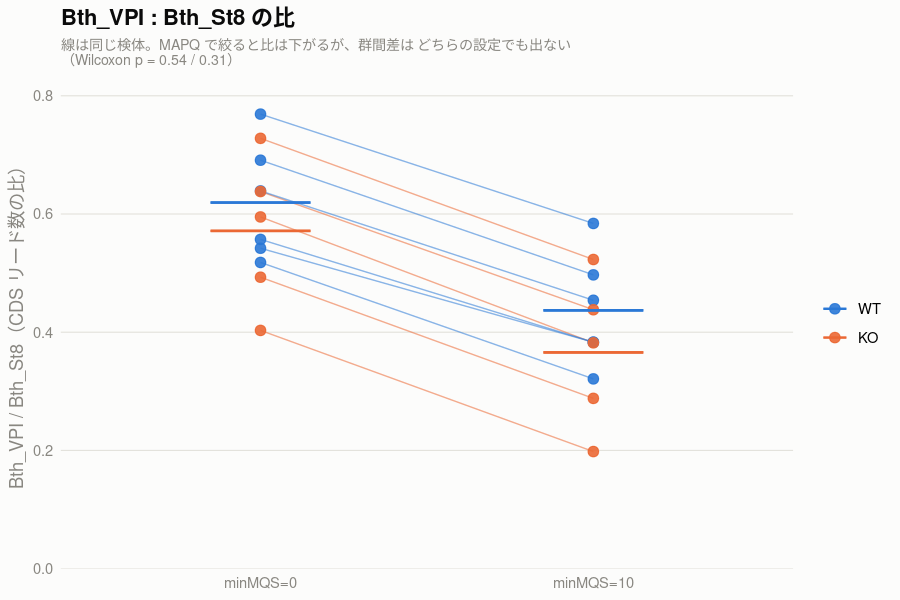

In [129]:
# ── Bth_VPI : Bth_St8 比を図にする ───────────────────────────
# 検体ごとに2設定を線で結ぶ（同じ検体が minMQS=0 → 10 でどう動くかを見る）。
# n = 6 対 5 と少ないので箱ひげは使わず、全検体を点で出して群平均を横線で重ねる
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

vs_fig = vpi_st8 %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 7.5, repr.plot.height = 5)

p = ggplot(vs_fig, aes(x = 設定, y = VPI_St8比)) +
    # 同じ検体を線で結ぶ
    geom_line(aes(group = name, colour = group), linewidth = 0.4, alpha = 0.55) +
    geom_point(aes(colour = group), size = 2.6, alpha = 0.9) +
    # 群平均（設定ごと）
    stat_summary(aes(colour = group, group = group,
                     ymin = after_stat(y), ymax = after_stat(y)),
                 fun = mean, geom = 'errorbar', width = 0.3, linewidth = 0.7) +
    scale_colour_manual(values = col_group, name = NULL) +
    scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
    labs(title = 'Bth_VPI : Bth_St8 の比',
         subtitle = paste0('線は同じ検体。MAPQ で絞ると比は下がるが、群間差は どちらの設定でも出ない\n',
                           '（Wilcoxon p = 0.54 / 0.31）'),
         x = NULL, y = 'Bth_VPI / Bth_St8（CDS リード数の比）') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-6図（英語版）: Bth_VPI : Bth_St8 ratio

**中身はセル15-6図 と同じで、文字だけ英語にしたもの。**

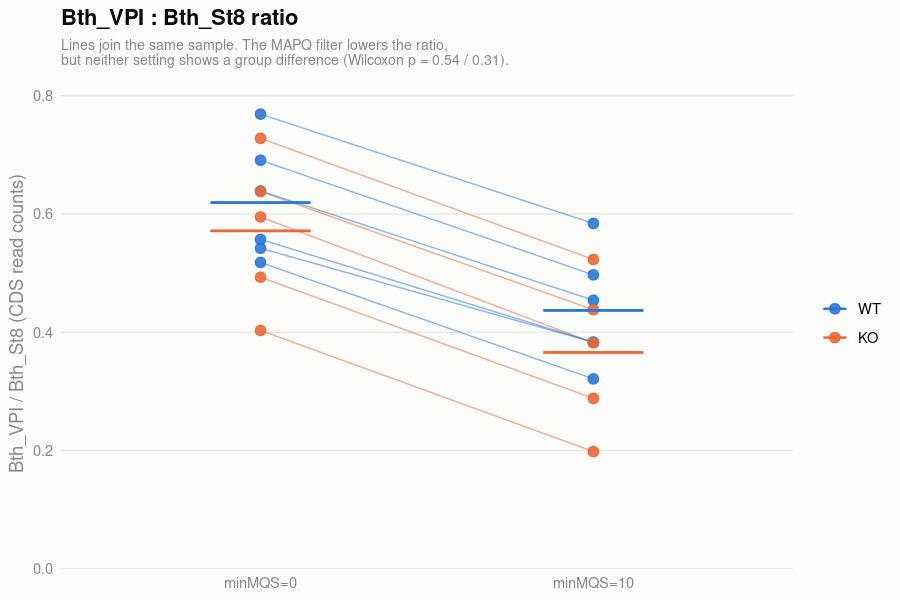

In [130]:
# ── Same figure, English labels（共同研究者と共有する用）────────
# セル15-6図 と中身は同じで、文字だけ英語にしたもの
library(ggplot2)

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}
if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

vs_fig = vpi_st8 %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 7.5, repr.plot.height = 5)

p_en = ggplot(vs_fig, aes(x = 設定, y = VPI_St8比)) +
    # 同じ検体を線で結ぶ
    geom_line(aes(group = name, colour = group), linewidth = 0.4, alpha = 0.55) +
    geom_point(aes(colour = group), size = 2.6, alpha = 0.9) +
    # 群平均（設定ごと）
    stat_summary(aes(colour = group, group = group,
                     ymin = after_stat(y), ymax = after_stat(y)),
                 fun = mean, geom = 'errorbar', width = 0.3, linewidth = 0.7) +
    scale_colour_manual(values = col_group, name = NULL) +
    scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
    labs(title = 'Bth_VPI : Bth_St8 ratio',
         subtitle = paste0('Lines join the same sample. The MAPQ filter lowers the ratio,\n',
                           'but neither setting shows a group difference (Wilcoxon p = 0.54 / 0.31).'),
         x = NULL, y = 'Bth_VPI / Bth_St8 (CDS read counts)') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p_en))

### 考察: Bth_VPI : Bth_St8 の比（セル15-6 の結果）= ゲート2 の最重要項目

## 結論: 群間差は出ない。ゲート2 はクリア

| 設定 | WT（n=6） | KO（n=5） | WT/KO | Wilcoxon p |
|---|---|---|---|---|
| minMQS=0 | 0.619 ± 0.098 | 0.571 ± 0.127 | 1.08 | **0.5368** |
| **minMQS=10** | **0.437 ± 0.095** | **0.366 ± 0.127** | **1.19** | **0.3142** |

CLAUDE.md §7 ステージ4 が最も警戒していた
「**Bth_VPI : Bth_St8 の存在比が変わると、近縁2株の取り違えが群間差に漏れる**」
という懸念は、**どちらの設定でも顕在化していない。**

セル14-3 の contig 単位の暫定値（WT 0.665 / KO 0.649、p = 0.66）とも向きが一致する。

## ★ ただし「差が無い」ではなく「大きな差は無い」

**n = 6 対 5 では検出力が足りない。**

| 設定 | 群内のばらつき（プール SD） | 観測された差 | 検出力80%で検出できる差 |
|---|---|---|---|
| minMQS=0 | 0.112 | 0.048（0.43 SD） | **約 0.22（相対 36%）** |
| minMQS=10 | 0.110 | 0.071（0.65 SD） | **約 0.22（相対 50%）** |

つまり **「比が 40〜50% 以上ずれていれば検出できたはずだが、そうではなかった」**
というのが正確な言い方。**5〜20% 程度のずれは、あっても見えない。**

観測された差（WT の方が 8〜19% 高い）は**2設定で向きが揃っている**ので、
小さな実差がある可能性は残る。ステージ5 で (B) 株ごと DESeq2 を回す限り
この程度のずれは size factor に吸収されるが、
**(A) 全株プールの結果を解釈するときは念頭に置く。**

## MAPQ フィルタは比を一律に下げる（検体ごとの偏りは作らない）

| 群 | 株 | minMQS=0 | minMQS=10 | 残存率 |
|---|---|---|---|---|
| WT | Bth_St8 | 48,112,218 | 25,188,880 | **52.4%** |
| WT | Bth_VPI | 29,147,189 | 10,680,113 | **36.6%** |
| KO | Bth_St8 | 35,556,315 | 19,137,129 | **53.8%** |
| KO | Bth_VPI | 19,544,154 | 6,422,499 | **32.9%** |

**Bth_VPI の方が 1.5倍多く失う。** 比が 0.62 → 0.44 に下がるのはこのため。

理由はこう考えられる。2株で配列が同一の領域から来たリードは
bowtie2 がどちらかに任意に割り当てて MAPQ 0〜1 になる。
`minMQS=0` ではそれが**ほぼ半々に分かれて数えられる**ので、
**存在量の少ない方（VPI）のシェアが相対的に水増しされる。**
`minMQS=10` でそれを除くと水増しが消える。

→ **`minMQS=10` の比（0.37〜0.44）の方が、真の存在比に近い。**

**検体ごとの偏りは作っていない。** 2設定の比の検体ごとの相関は **r = 0.990（p < 0.0001）**で、
MAPQ フィルタはどの検体にもほぼ同じ倍率で効いている。

## 検体間のばらつきは大きい（生物学的な変動）

`minMQS=10` で WT 0.321〜0.584（1.8倍）、KO 0.198〜0.523（2.6倍）。
**同じ群の中でも個体ごとに Bth 2株の定着比がかなり違う。**
これは群間差ではなく個体差で、(B) 株ごと DESeq2 では各株の中で正規化されるため影響しない。

## ゲート2 の判定まとめ

| 項目 | 結果 |
|---|---|
| eptA `_deleted` の遺伝子型確認（3株） | **通過**（95〜4,191倍の分離、p = 0.0043〜0.0078） |
| Odo の挿入による転写終結 | **通過**（`_3p` が 218倍） |
| 株別CDSリード数・除外基準 | **通過**（4株とも基準の3〜60倍の余裕） |
| **Bth_VPI : Bth_St8 の存在比** | **通過**（p = 0.31〜0.54。ただし検出力は 40% 程度まで） |
| pME008 スペーサーによる群判別 | **不可**（depth 1.7、p = 0.85）→ eptA `_deleted` で代替済み |
| 群集組成の群間差 | **あり**（Bth 多 / Bun 少 が WT、p = 0.01〜0.02）。eptA 変異コンソーシアムの定着結果として扱う |

→ **ステージ4（ゲート2）通過。ステージ5（DESeq2）に進んでよい。**
ただし上記2点（組成の群間差、VPI:St8 比の検出力）は
ステージ5・6 の解釈に持ち越す。

## ★ 追記: Salmon による独立確認（セル16-6 の結果）

ここまでは **featureCounts で出した結論**なので、按分の仕組みが違う **Salmon で独立に再確認した。**

| 見方 | `VPI:St8` WT / KO | p |
|---|---|---|
| featureCounts `minMQS=0` | 0.680 / 0.671 | 0.7922 |
| featureCounts `minMQS=10` | 0.449 / 0.381 | 0.5368 |
| **Salmon（VBEM）** | 0.517 / 0.471 | **0.5368** |
| **Salmon（`--meta`）** | 0.460 / 0.411 | **0.5368** |

**水準（絶対値）は 0.38〜0.68 と見方によって大きく動くが、群間差はどれも出ない。**
→ **ゲート2 の「`VPI:St8` に群間差なし」は、多重マップの扱いに依存しない頑健な結論。**

**※ ただし Salmon の `VPI:St8` の絶対値は使ってはいけない。**
index から落ちる重複クラスタ737本が `Bth_VPI` に偏っており（`Bth_VPI` の 10.3% / `Bth_St8` の 0.2%）、
**それだけで比が 10% 下がる。** 詳細はセル16 の考察。

**遺伝子型の判別は Salmon の方が鋭い。** 4つの欠失マーカーが **K群の全5検体で TPM = 0.00（完全分離）**。
featureCounts の 95〜4,191倍より明確。詳細はセル16-7。

---
# カウント結果の確認

**過去notebook `230313_T19_33mix_metatranscriptome/3_2_featureCounts_R.ipynb` の
「カウント結果確認」以降と同じ確認をここで行う。**

当初この節を飛ばしていたのは**こちらの手落ち**。過去notebookに沿う方針から逸脱していた。

| 過去notebook | このnotebook | 状況 |
|---|---|---|
| セル17-18 log2カウントのヒストグラム | **セル15-7** | 追加 |
| セル19 検体ごとの箱ひげ | **セル15-8** | 追加 |
| セル25-27 PCA（3通りのカウント） | **セル15-9 / 15-10** | 追加（2通り） |
| セル28-36 STAR stats と featureCounts stats の比較 | セル14-2 / 15-3 | 対応済み |
| セル38-39 3通りのカウントの遺伝子ごと比較 | **セル15-11** | 追加（2通り） |
| セル40-43 株ごとサマリー・株ID対応表 | セル15-5 / `feat_info` | 対応済み |
| セル45 保存 | **セル15-12** | 追加 |

**過去notebookから意図的に変えた点が1つある。**
過去は**全 feature** で分布と PCA を見ていたが、ここは **CDS だけ**に絞る。
このデータでは tmRNA など6 feature が 21〜42% を占めるので（セル15-4）、
そのままだと分布も PC1 も構造RNAの量で決まってしまう。

## セル15-7: カウント分布のヒストグラム

過去notebook セル17-18 と同じ。`log2(カウント + 1)` の分布を検体ごとに見る。

- 分布の形が検体でそろっているか
- ゼロ（`log2 = 0`）に寄りすぎていないか

過去notebook は `patchwork` で検体ごとのプロットを並べていたが、
**`patchwork` は既定のライブラリに入っていない**（`metatx-lib` にはあるが、
読み込むと ggplot2 のバージョンが 3.5.1 → 3.5.2 に変わる）。
`facet_wrap` で同じ「小さい図を並べる」形にした。

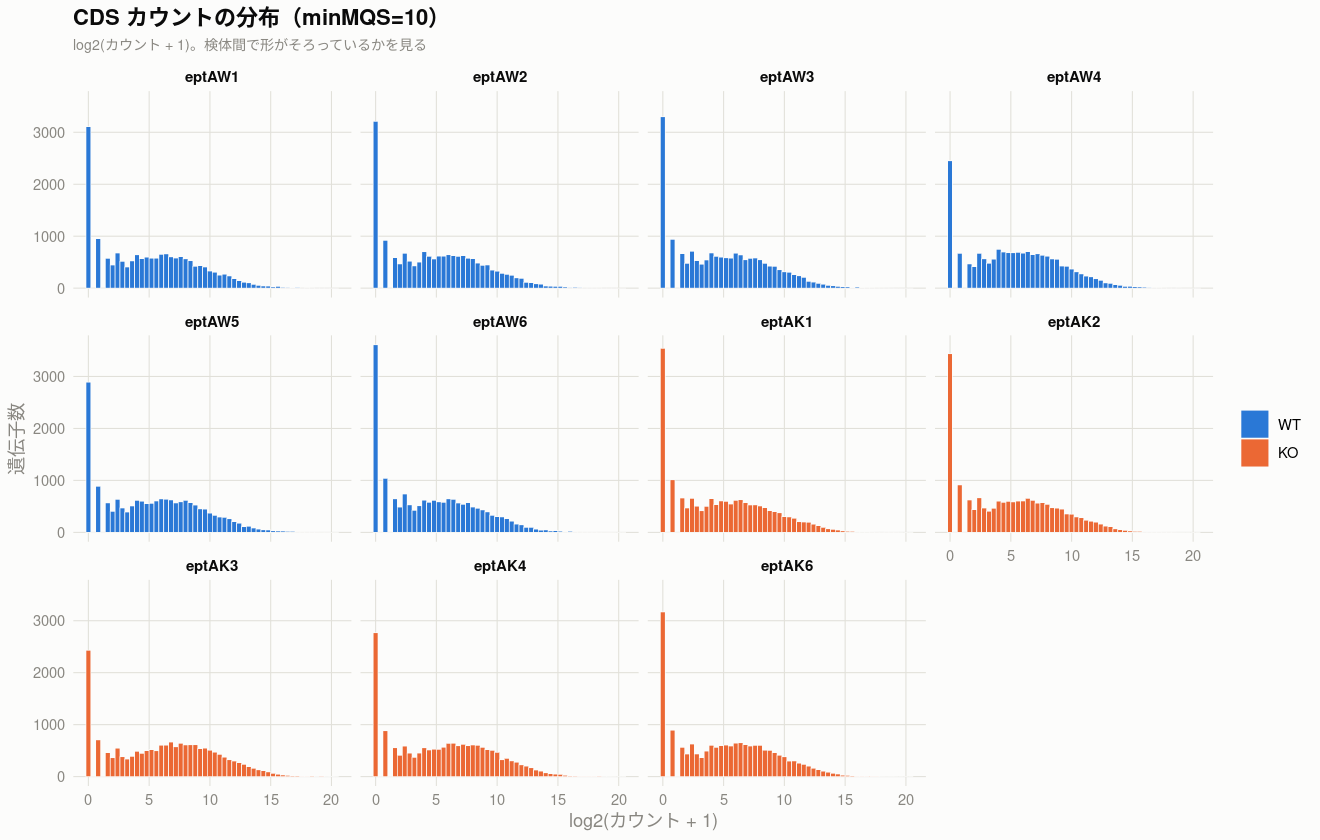

In [131]:
# ── カウント分布のヒストグラム ─────────────────────────────
# 過去notebook（230313_T19_33mix_metatranscriptome/3_2_featureCounts_R.ipynb のセル17-18）
# と同じ確認。log2(カウント + 1) の分布を検体ごとに見る。
#   ・分布の形が検体でそろっているか
#   ・ゼロ（log2 = 0）に寄りすぎていないか
#
# 過去notebook は patchwork で検体ごとのプロットを並べていたが、patchwork は
# 既定のライブラリに入っていない（metatx-lib にはあるが ggplot2 のバージョンが
# 変わるので読み込まない）。facet_wrap で同じ「小さい図を並べる」形にする。
#
# ★ CDS だけを使う。tmRNA が 21〜42% を占めるので（セル15-4）、
#   全 feature で見ると分布が構造RNAに引きずられる
library(ggplot2)

if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')
if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

q_hist = 10        # 見たい設定。minMQS=0 を見るときは 0 に変える

m    = cnt[[paste0('q', q_hist)]]
keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
lg   = log2(m[keep, ] + 1)

cnt_log = data.frame(name  = rep(colnames(lg), each = nrow(lg)),
                     value = as.vector(lg)) %>%
    left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(name = factor(name, levels = c(sort(seq_list$name[seq_list$group == 'WT']),
                                          sort(seq_list$name[seq_list$group == 'KO']))),
           group = factor(group, levels = c('WT','KO')))

options(repr.plot.width = 11, repr.plot.height = 7)

p = ggplot(cnt_log, aes(x = value, fill = group)) +
    geom_histogram(binwidth = 0.4, colour = col_surface, linewidth = 0.2) +
    facet_wrap(~ name, ncol = 4) +
    scale_fill_manual(values = col_group, name = NULL) +
    labs(title = sprintf('CDS カウントの分布（minMQS=%d）', q_hist),
         subtitle = 'log2(カウント + 1)。検体間で形がそろっているかを見る',
         x = 'log2(カウント + 1)', y = '遺伝子数') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-7-2: カウント0の遺伝子の正体

セル15-7 のヒストグラムで **`log2 = 0`（＝カウント0）の山が大きい**（`minMQS=10` で
検体あたり 2,500〜3,600 個）。中身を確かめる。

**仮説**: 似た配列の遺伝子が判別できずに削られている。

**確かめ方**: ステージ2 で測った **`mappability`** が GTF の属性に入っているので、それを使う。

```
mappability = その CDS から作った擬似リードが、自分の CDS に
              MAPQ >= 10 で戻ってくる割合（1.0 なら完全に判別できる）
```

カウント0を2種類に分けて数える。

| 区分 | 意味 |
|---|---|
| `minMQS=0` でも0 | **本当に発現が無い**（または検出限界以下） |
| `minMQS=10` で初めて0 | **MAPQ フィルタで消えた** |

In [ ]:
# ── カウント0の遺伝子の正体を調べる ─────────────────────────
# セル15-7 のヒストグラムで log2 = 0（＝カウント0）の山が大きいので、中身を見る。
# 仮説は「似た配列の遺伝子が判別できずに削られている」。
# ステージ2 で測った mappability が GTF の属性に入っているので、それで確かめる。
#   mappability = その CDS から作った擬似リードが、自分の CDS に
#                 MAPQ >= 10 で戻ってくる割合（1.0 なら完全に判別できる）

# GTF から mappability を取り出す（eptA の分割feature など一部は値が無く NA になる）
mapp = gtf_count %>%
    mutate(mappability = suppressWarnings(
               as.numeric(str_match(attr, 'mappability "([^"]*)"')[, 2]))) %>%
    distinct(gene_id, .keep_all = TRUE) %>%
    dplyr::select(gene_id, mappability)

idx  = match(rownames(cnt$q10), feat_info$gene_id)
keep = feat_info$biotype[idx] == 'CDS'
mp   = mapp$mappability[match(rownames(cnt$q10), mapp$gene_id)]

# 検体あたりのカウント0の数
for (q in c(0, 10)) {
    z = colSums(cnt[[paste0('q', q)]][keep, ] == 0)
    cat(sprintf("minMQS=%-2d  検体あたりカウント0の CDS: %d 〜 %d（平均 %.0f / CDS 計 %d）\n",
                q, min(z), max(z), mean(z), sum(keep)))
}

# 全検体で0のものを「q0 でも0」と「q10 で初めて0」に分ける
never = keep & rowSums(cnt$q0)  == 0                      # 本当に発現していない
lost  = keep & rowSums(cnt$q0)   > 0 & rowSums(cnt$q10) == 0   # MAPQ で消えた

cat(sprintf("\n全11検体で0（minMQS=0）  : %d 個 … 本当に発現が無い\n", sum(never)))
cat(sprintf("全11検体で0（minMQS=10） : %d 個 … うち %d 個は minMQS=10 で初めて0になった\n",
            sum(keep & rowSums(cnt$q10) == 0), sum(lost)))

data.frame(
    区分 = c('minMQS=0 でも0（発現なし）', 'minMQS=10 で消えた'),
    rbind(table(factor(feat_info$strain[idx][never],
                       levels = c('Bth_St8','Bth_VPI','Bun_8492','Odo_St23','pME008'))),
          table(factor(feat_info$strain[idx][lost],
                       levels = c('Bth_St8','Bth_VPI','Bun_8492','Odo_St23','pME008')))),
    check.names = FALSE)

## セル15-7-2図: 消えた遺伝子の mappability

「似た配列だから判別できない」が理由なら、
**消えた遺伝子の mappability は 0 に寄るはず。** それを確かめる。

In [ ]:
# ── 消えた遺伝子の mappability ───────────────────────────────
# 「似た配列だから判別できない」が理由なら、消えた遺伝子の mappability は 0 に寄るはず

cat(sprintf("消えた %d 個 : mappability 中央値 %.3f（四分位 %.3f - %.3f）\n",
            sum(lost), median(mp[lost], na.rm = TRUE),
            quantile(mp[lost], 0.25, na.rm = TRUE), quantile(mp[lost], 0.75, na.rm = TRUE)))
cat(sprintf("CDS 全体     : mappability 中央値 %.3f（四分位 %.3f - %.3f）\n",
            median(mp[keep], na.rm = TRUE),
            quantile(mp[keep], 0.25, na.rm = TRUE), quantile(mp[keep], 0.75, na.rm = TRUE)))
cat(sprintf("\nmappability < 0.1 の割合:  消えた遺伝子 %.1f%%  /  CDS 全体 %.1f%%\n",
            100 * mean(mp[lost] < 0.1, na.rm = TRUE),
            100 * mean(mp[keep] < 0.1, na.rm = TRUE)))

# 図で見る
mp_df = rbind(data.frame(区分 = sprintf('minMQS=10 で消えた (n=%d)', sum(lost)),
                         mappability = mp[lost]),
              data.frame(区分 = sprintf('それ以外の CDS (n=%d)', sum(keep) - sum(lost)),
                         mappability = mp[keep & !lost]))

options(repr.plot.width = 8, repr.plot.height = 4)

p = ggplot(mp_df, aes(x = mappability, fill = 区分)) +
    geom_histogram(binwidth = 0.05, colour = col_surface, linewidth = 0.2) +
    facet_wrap(~ 区分, scales = 'free_y') +
    scale_fill_manual(values = c('#eb6834', '#2a78d6'), guide = 'none') +
    labs(title = 'カウントが消えた遺伝子の mappability',
         subtitle = 'mappability = 自分の CDS に MAPQ >= 10 で戻ってくる擬似リードの割合（ステージ2）',
         x = 'mappability', y = '遺伝子数') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-8: 検体ごとの分布を箱ひげで並べる

過去notebook セル19 と同じ。検体間で分布がずれていないかを1枚で見る。
ここは2設定とも出す（`minMQS=10` でどれだけ下がるかも一緒に見える）。

**箱の位置がそろっていれば、検体間の深度差は DESeq2 の size factor で吸収できる。**

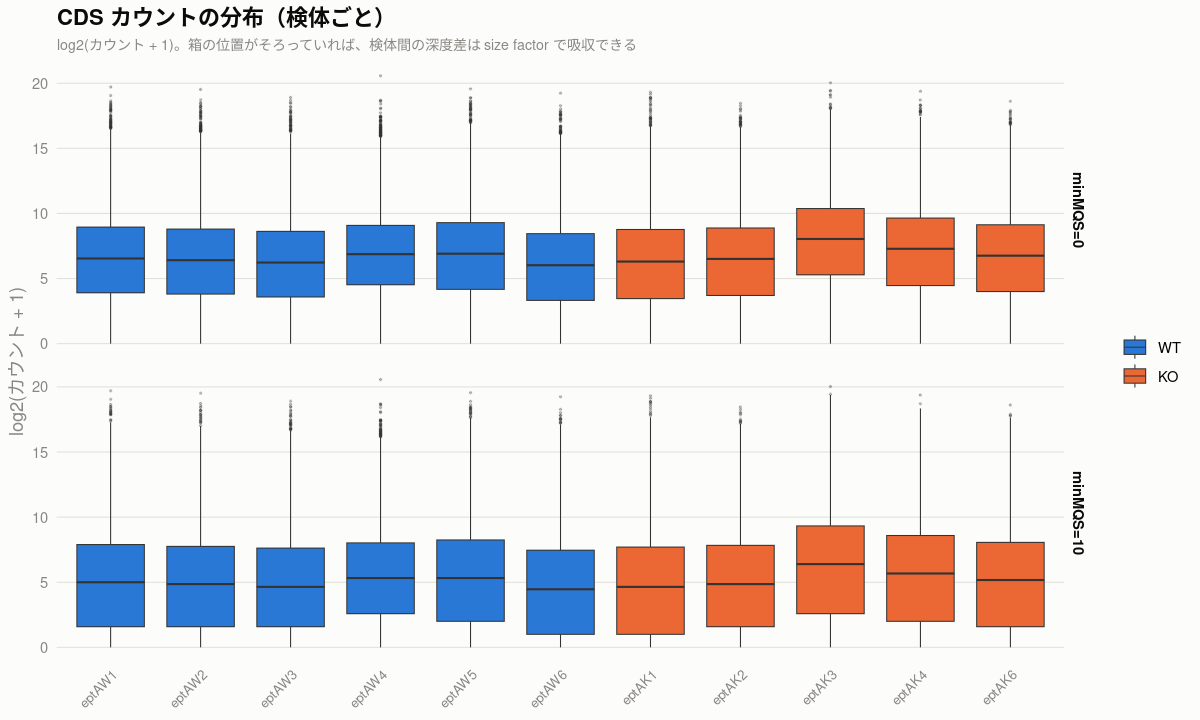

In [132]:
# ── 検体ごとの分布を箱ひげで並べる ───────────────────────────
# 過去notebook（セル19）と同じ確認。検体間で分布がずれていないかを1枚で見る。
# ここは2設定とも出す（minMQS=10 でどれだけ下がるかも一緒に見える）

box_df = data.frame()
for (q in c(0, 10)) {
    m    = cnt[[paste0('q', q)]]
    keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
    lg   = log2(m[keep, ] + 1)
    box_df = rbind(box_df, data.frame(設定 = paste0('minMQS=', q),
                                      name = rep(colnames(lg), each = nrow(lg)),
                                      value = as.vector(lg)))
}
box_df = box_df %>%
    left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(name = factor(name, levels = c(sort(seq_list$name[seq_list$group == 'WT']),
                                          sort(seq_list$name[seq_list$group == 'KO']))),
           group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 10, repr.plot.height = 6)

p = ggplot(box_df, aes(x = name, y = value, fill = group)) +
    geom_boxplot(outlier.size = 0.3, outlier.alpha = 0.25, linewidth = 0.3) +
    facet_grid(設定 ~ .) +
    scale_fill_manual(values = col_group, name = NULL) +
    labs(title = 'CDS カウントの分布（検体ごと）',
         subtitle = 'log2(カウント + 1)。箱の位置がそろっていれば、検体間の深度差は size factor で吸収できる',
         x = NULL, y = 'log2(カウント + 1)') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-8-2: 検体間のずれが許容範囲かを判定する

**セル15-8 の箱ひげで目立つ「中央値の上下のずれ」は、それ自体は深度の差で、
DESeq2 の size factor が取り除く。** 問題になるのは
**「1つの倍率では直せないずれ」＝分布の形の違い**の方。

そこで DESeq2 と同じ **median-of-ratios** で size factor を計算し、
正規化後の **RLE**（遺伝子ごとの中央値からのずれ）を見る。

| 指標 | 計算 |
|---|---|
| `size_factor` | 全検体で非ゼロの遺伝子で、`log(count) − 全検体の log 平均` の中央値を `exp` したもの |
| `RLE中央値` / `RLE_IQR` | 正規化後の `log2` から、その遺伝子の全検体中央値を引いたものの中央値と IQR |

**★ median-of-ratios では `RLE中央値` は構造上ほぼ 0 になる**ので、
判定に使うのは **`RLE_IQR`（ばらつきの幅）**の方。

In [138]:
# ── 検体間のずれが許容範囲かを判定する ─────────────────────
# セル15-8 の箱ひげは「中央値の上下のずれ」が目立つが、
# それ自体は深度の差であって、DESeq2 の size factor が取り除く。
# 問題になるのは「1つの倍率では直せないずれ」＝分布の形の違い。
#
# そこで DESeq2 と同じ median-of-ratios で size factor を計算し、
# 正規化後の RLE（遺伝子ごとの中央値からのずれ）を見る。
#   size factor : 全検体で非ゼロの遺伝子だけを使い、
#                 log(count) − 全検体の log 平均 の中央値を exp したもの
#   RLE         : 正規化後の log2 から、その遺伝子の全検体中央値を引いたもの
#
# ★ median-of-ratios では RLE の【中央値】は構造上ほぼ 0 になるので、
#   判定に使うのは【IQR（ばらつきの幅）】の方

sf_qc = data.frame()
for (q in c(0, 10)) {
    m    = cnt[[paste0('q', q)]]
    keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
    m    = m[keep, ]
    ok   = rowSums(m == 0) == 0            # 全検体で非ゼロの遺伝子だけで計算する

    lgm  = rowMeans(log(m[ok, ]))
    sf   = apply(m[ok, ], 2, function(x) exp(median(log(x) - lgm)))
    norm = sweep(m[ok, ], 2, sf, '/')
    L    = log2(norm)
    rle  = L - apply(L, 1, median)

    sf_qc = rbind(sf_qc, data.frame(
        設定        = paste0('minMQS=', q),
        name        = colnames(m),
        group       = seq_list$group[match(colnames(m), seq_list$name)],
        size_factor = round(sf, 3),
        RLE中央値   = round(apply(rle, 2, median), 3),
        RLE_IQR     = round(apply(rle, 2, IQR), 3),
        生log2中央値 = round(apply(log2(m + 1), 2, median), 2),
        カウント0   = colSums(m == 0),
        row.names   = NULL))
}

sf_qc %>% arrange(設定, factor(group, levels = c('WT','KO')), name) %>% as.data.frame()

設定,name,group,size_factor,RLE中央値,RLE_IQR,生log2中央値,カウント0
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
minMQS=0,eptAW1,WT,0.915,0,0.473,6.54,1016
minMQS=0,eptAW2,WT,0.829,0,0.557,6.41,1076
minMQS=0,eptAW3,WT,0.730,0,0.737,6.23,1100
minMQS=0,eptAW4,WT,1.105,0,1.319,6.87,434
minMQS=0,eptAW5,WT,1.134,0,0.498,6.91,905
minMQS=0,eptAW6,WT,0.629,0,0.638,6.02,1331
minMQS=0,eptAK1,KO,0.785,0,0.970,6.30,1365
minMQS=0,eptAK2,KO,0.884,0,0.795,6.51,1280
minMQS=0,eptAK3,KO,2.381,0,0.952,8.04,692


## セル15-8-3: 判定

**★ ここで使う数値の目安は、このプロジェクトで決めた作業用のもの。**
**文献に定まった基準があるわけではない。** 出どころは次のとおり。

| 指標 | 目安 | 出どころ |
|---|---|---|
| `size_factor` の最大/最小 | ≤ 5 | DESeq2 の vignette は「検体間の深度の幅が**1桁（10倍）**あるなら `rlog` を使う」と書いている。**変換の選び方の話で、検体を落とす基準ではない。** その半分を安全側の目安として置いた |
| `RLE中央値` の絶対値 | ≤ 0.1 | median-of-ratios では構造上ほぼ 0 になるので、**計算が正しいことの確認用** |
| `RLE_IQR` の最大/最小 | ≤ 2 | RLE プロットの原典（Gandolfo & Speed 2018）は「中央値が 0 に乗り、箱の高さがそろっていること」と書いているだけで**数値のしきい値は示していない**。2倍は「図で見て明らかに1つ高い」水準として置いた |

**→ 数値は目安にすぎない。判断の主役は次の2つの図**（どちらもこの用途の標準的な図）。

| セル | 図 | 由来 |
|---|---|---|
| **15-8-4** | **RLE プロット** | Gandolfo & Speed (2018) PLoS ONE 13:e0191629 |
| **15-8-5** | **検体間の距離のヒートマップ** | DESeq2 vignette「Data transformations and visualization」 |

あわせて**株ごとに分けても同じ検体が外れるか**を見る。
群集組成の差（セル14-4）で広がっているだけなら、株ごとに分ければ収まるはず。

In [143]:
# ── 判定 ─────────────────────────────────────────────────────
# ★ ここで使う数値の目安は【このプロジェクトで決めた作業用のもの】で、
#   文献に定まった基準があるわけではない。出どころは次のとおり。
#
#   size factor の最大/最小 <= 5
#     DESeq2 の vignette は「検体間の深度の幅が1桁（10倍）あるなら rlog を使う」
#     という書き方をしている（変換の選び方の話で、検体を落とす基準ではない）。
#     その半分を、安全側の目安として置いた。
#
#   RLE 中央値の絶対値 <= 0.1
#     median-of-ratios では構造上ほぼ 0 になるので、計算が正しいことの確認用。
#
#   RLE IQR の最大/最小 <= 2
#     RLE プロットの原典（Gandolfo & Speed 2018）は
#     「中央値が 0 に乗り、箱の高さがそろっていること」と書いているだけで
#     数値のしきい値は示していない。2倍は「図で見て明らかに1つ高い」水準として置いた。
#
#   → 数値は目安。判断の主役は セル15-8-4 の RLE プロットと
#     セル15-8-5 の距離ヒートマップ（どちらもこの用途の標準的な図）。

for (qq in unique(sf_qc$設定)) {
    d = sf_qc %>% filter(設定 == qq)
    cat(sprintf("\n##### %s #####\n", qq))
    cat(sprintf("  生 log2 中央値  : %.2f 〜 %.2f（%.1f倍の深度差）→ size factor が吸収する\n",
                min(d$生log2中央値), max(d$生log2中央値),
                2^(max(d$生log2中央値) - min(d$生log2中央値))))
    cat(sprintf("  size factor     : %.3f 〜 %.3f（最大/最小 %.2f倍）%s\n",
                min(d$size_factor), max(d$size_factor),
                max(d$size_factor)/min(d$size_factor),
                ifelse(max(d$size_factor)/min(d$size_factor) <= 5, ' → 目安内', ' → ★ 目安超え')))
    cat(sprintf("  RLE 中央値      : 絶対値の最大 %.3f%s\n", max(abs(d$RLE中央値)),
                ifelse(max(abs(d$RLE中央値)) <= 0.1, ' → 目安内', ' → ★ 目安超え')))
    cat(sprintf("  RLE IQR         : %.3f 〜 %.3f（最大/最小 %.2f倍）%s\n",
                min(d$RLE_IQR), max(d$RLE_IQR), max(d$RLE_IQR)/min(d$RLE_IQR),
                ifelse(max(d$RLE_IQR)/min(d$RLE_IQR) <= 2, ' → 目安内', ' → ★ 目安超え')))
    cat(sprintf("    IQR が最大の検体: %s（%.3f） / 最小: %s（%.3f）\n",
                d$name[which.max(d$RLE_IQR)], max(d$RLE_IQR),
                d$name[which.min(d$RLE_IQR)], min(d$RLE_IQR)))
}

# 株ごとに分けても同じ検体が外れるのか（群集組成の差で広がっているだけではないかの確認）
cat("\n##### 株ごとに分けた場合（minMQS=0）#####\n")
m0  = cnt$q0
idx = match(rownames(m0), feat_info$gene_id)
for (st in c('全株まとめて', 'Bth_St8', 'Bth_VPI', 'Bun_8492', 'Odo_St23')) {
    sel = if (st == '全株まとめて') feat_info$biotype[idx] == 'CDS' else
          (feat_info$biotype[idx] == 'CDS' & feat_info$strain[idx] == st)
    m = m0[sel, ]; ok = rowSums(m == 0) == 0
    lgm = rowMeans(log(m[ok, ])); sf = apply(m[ok, ], 2, function(x) exp(median(log(x) - lgm)))
    L = log2(sweep(m[ok, ], 2, sf, '/')); iq = apply(L - apply(L, 1, median), 2, IQR)
    cat(sprintf("  %-12s 遺伝子 %5d  RLE IQR %.3f 〜 %.3f（%.2f倍）  最大: %s\n",
                st, sum(ok), min(iq), max(iq), max(iq)/min(iq), colnames(m)[which.max(iq)]))
}


##### minMQS=0 #####
  生 log2 中央値  : 6.02 〜 8.04（4.1倍の深度差）→ size factor が吸収する
  size factor     : 0.629 〜 2.381（最大/最小 3.79倍） → 目安内
  RLE 中央値      : 絶対値の最大 0.000 → 目安内
  RLE IQR         : 0.473 〜 1.319（最大/最小 2.79倍） → ★ 目安超え
    IQR が最大の検体: eptAW4（1.319） / 最小: eptAW1（0.473）

##### minMQS=10 #####
  生 log2 中央値  : 4.46 〜 6.39（3.8倍の深度差）→ size factor が吸収する
  size factor     : 0.651 〜 2.357（最大/最小 3.62倍） → 目安内
  RLE 中央値      : 絶対値の最大 0.000 → 目安内
  RLE IQR         : 0.486 〜 1.373（最大/最小 2.83倍） → ★ 目安超え
    IQR が最大の検体: eptAW4（1.373） / 最小: eptAW1（0.486）

##### 株ごとに分けた場合（minMQS=0）#####
  全株まとめて 遺伝子 15447  RLE IQR 0.473 〜 1.319（2.79倍）  最大: eptAW4
  Bth_St8      遺伝子  4280  RLE IQR 0.480 〜 1.067（2.22倍）  最大: eptAW4
  Bth_VPI      遺伝子  4227  RLE IQR 0.523 〜 1.137（2.18倍）  最大: eptAW4
  Bun_8492     遺伝子  3561  RLE IQR 0.286 〜 1.295（4.53倍）  最大: eptAW4
  Odo_St23     遺伝子  3368  RLE IQR 0.439 〜 1.207（2.75倍）  最大: eptAW4


## セル15-8-3図: size factor

**size factor そのものを見る標準的な図は決まっていない。**
（RLE プロットや距離ヒートマップのような、名前の付いた定番図は無い。）

そこで、判断に必要な2点を見る図を用意した。

| セル | 見るもの |
|---|---|
| **15-8-3図** | 検体ごとの size factor と、**許容幅（最小値の5倍まで）** |
| **15-8-3図-2** | size factor が**深度と比例しているか** |

この図では **灰色の帯が許容幅**。`size_factor` の最大/最小 ≤ 5 という目安は、
**「すべての棒が帯の中に収まっているか」**と言い換えられる。
黒い横線は 1（＝全検体の典型値）。

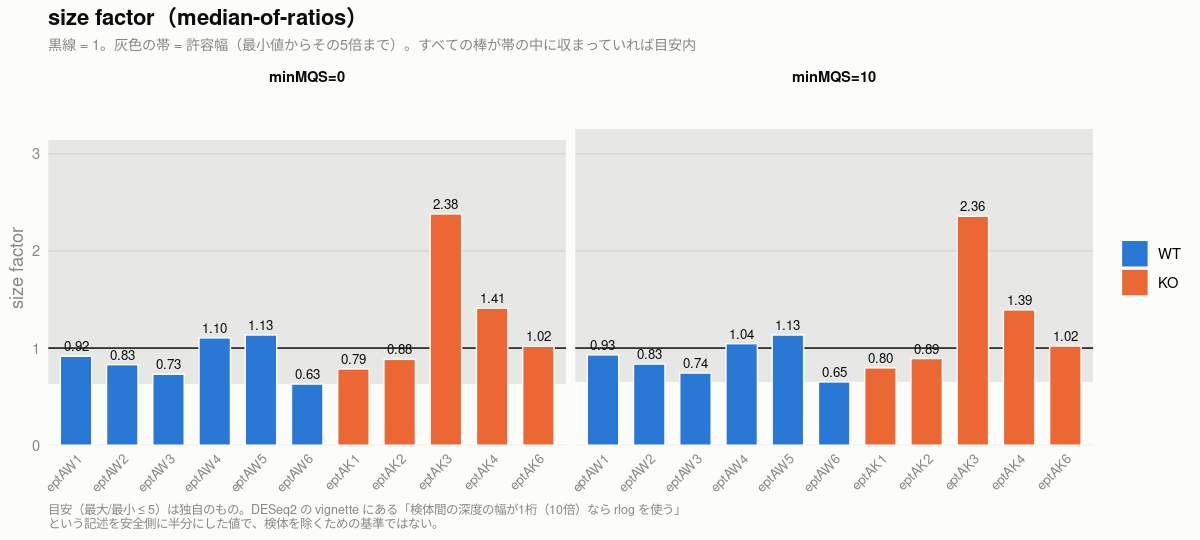

In [151]:
# ── size factor を図にする ───────────────────────────────────
# size factor そのものを見る標準的な図は決まっていないが、
# 次の2つを見ておけば「深度の差が素直に吸収されているか」が判断できる。
#   (1) 検体ごとの size factor と、許容幅（最小値の5倍まで）
#   (2) size factor が深度（CDS の総カウント）と比例しているか
#       → 比例していれば「深度の差を測っているだけ」。
#         外れる検体があれば、その検体は組成が他と違うということ

if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

sfd = sf_qc %>%
    left_join(data.frame(設定 = rep(c('minMQS=0','minMQS=10'), each = ncol(cnt$q0)),
                         name = rep(colnames(cnt$q0), 2),
                         総カウントM = c(colSums(cnt$q0[feat_info$biotype[
                                            match(rownames(cnt$q0), feat_info$gene_id)]=='CDS', ]),
                                        colSums(cnt$q10[feat_info$biotype[
                                            match(rownames(cnt$q10), feat_info$gene_id)]=='CDS', ])) / 1e6),
              by = c('設定','name')) %>%
    mutate(name = factor(name, levels = c(sort(seq_list$name[seq_list$group == 'WT']),
                                          sort(seq_list$name[seq_list$group == 'KO']))),
           group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

# 許容幅（最小値の5倍まで）を設定ごとに出す
band = sfd %>% group_by(設定) %>% summarise(lo = min(size_factor), .groups = 'drop') %>%
    mutate(hi = lo * 5)

options(repr.plot.width = 10, repr.plot.height = 4.5)

p1 = ggplot(sfd, aes(x = name, y = size_factor, fill = group)) +
    geom_rect(data = band, inherit.aes = FALSE,
              aes(xmin = -Inf, xmax = Inf, ymin = lo, ymax = hi),
              fill = col_muted, alpha = 0.18) +
    geom_hline(yintercept = 1, colour = col_text, linewidth = 0.4) +
    geom_col(width = 0.68, colour = col_surface, linewidth = 0.4) +
    geom_text(aes(label = sprintf('%.2f', size_factor)), vjust = -0.5,
              size = 2.8, colour = col_text) +
    facet_grid(. ~ 設定) +
    scale_fill_manual(values = col_group, name = NULL) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
    labs(title = 'size factor（median-of-ratios）',
         subtitle = paste0('黒線 = 1。灰色の帯 = 許容幅（最小値からその5倍まで）。',
                           'すべての棒が帯の中に収まっていれば目安内'),
         x = NULL, y = 'size factor',
         # 目安の出どころを図の中に残す
         caption = '目安（最大/最小 ≤ 5）は独自のもの。DESeq2 の vignette にある「検体間の深度の幅が1桁（10倍）なら rlog を使う」\nという記述を安全側に半分にした値で、検体を除くための基準ではない。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p1))

## セル15-8-3図-2: size factor と深度の関係

**size factor が深度（CDS の総カウント）と比例しているか**を見る。

| 状態 | 意味 |
|---|---|
| 破線（原点を通る比例の線）に乗っている | **size factor は深度の差を測っているだけ。** 素直な状態 |
| 線から外れる検体がある | その検体は**他と組成が違う**（同じ深度でも典型的な遺伝子の発現水準が違う） |

傾きは全検体の `size_factor ÷ 総カウント` の中央値を使っている。

**15-8-3図 と同じ目安をこの図にも描く。**

| 図の要素 | 意味 |
|---|---|
| **灰色の影** | **目安（最小値の5倍）を超える領域。** ここに点が入ると、その検体が分散推定を支配しうる |
| 水平の破線 + 数値 | 目安の上限そのもの |

影は `Inf` まで伸ばさず**図の上端で止めている**（`coord_cartesian` で表示範囲を決め、
軸が影につられて伸びないようにしている）。


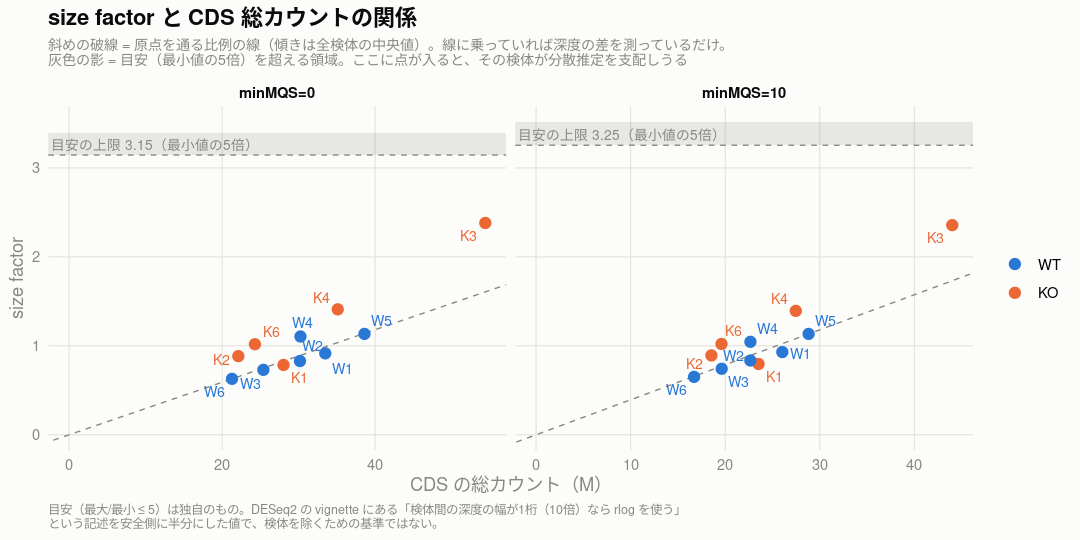

In [150]:
# ── size factor が深度と比例しているか ───────────────────────
# 比例していれば「深度の差を測っているだけ」。
# 外れる検体があれば、その検体は他と組成が違うということ

# 目安の上限（最小値の5倍）。15-8-3図 の帯と同じ基準を、この図にも描く
lim_sf = sfd %>% group_by(設定) %>%
    summarise(上限 = min(size_factor) * 5,
              図の上端 = max(max(size_factor) * 1.15, min(size_factor) * 5 * 1.08),
              .groups = 'drop')

options(repr.plot.width = 9, repr.plot.height = 4.5)

p2 = ggplot(sfd, aes(x = 総カウントM, y = size_factor, colour = group)) +
    # 目安を超える領域（最小値の5倍より上）に影をかける
    geom_rect(data = lim_sf, inherit.aes = FALSE,
              aes(xmin = -Inf, xmax = Inf, ymin = 上限, ymax = 図の上端),
              fill = col_muted, alpha = 0.18) +
    geom_hline(data = lim_sf, aes(yintercept = 上限),
               linetype = 'dashed', colour = col_muted, linewidth = 0.4) +
    geom_text(data = lim_sf, inherit.aes = FALSE,
              aes(x = -Inf, y = 上限, label = sprintf(' 目安の上限 %.2f（最小値の5倍）', 上限)),
              hjust = 0, vjust = -0.5, size = 2.9, colour = col_muted) +
    # 原点を通る比例の線（傾きは全検体の中央値）
    geom_abline(data = sfd %>% group_by(設定) %>%
                    summarise(a = median(size_factor / 総カウントM), .groups = 'drop'),
                aes(slope = a, intercept = 0),
                linetype = 'dashed', colour = col_muted, linewidth = 0.4) +
    geom_point(size = 2.8) +
    ggrepel::geom_text_repel(aes(label = sub('^eptA', '', name)), size = 3,
                             show.legend = FALSE, seed = 1) +
    facet_grid(. ~ 設定, scales = 'free_x') +
    scale_colour_manual(values = col_group, name = NULL) +
    scale_x_continuous(limits = c(0, NA)) +
    # 影を Inf まで伸ばさず、図の上端で止める（軸が伸びないように）
    coord_cartesian(ylim = c(0, max(lim_sf$図の上端))) +
    labs(title = 'size factor と CDS 総カウントの関係',
         subtitle = paste0('斜めの破線 = 原点を通る比例の線（傾きは全検体の中央値）。線に乗っていれば深度の差を測っているだけ。\n',
                           '灰色の影 = 目安（最小値の5倍）を超える領域。ここに点が入ると、その検体が分散推定を支配しうる'),
         x = 'CDS の総カウント（M）', y = 'size factor',
         # 目安の出どころを図の中に残す
         caption = '目安（最大/最小 ≤ 5）は独自のもの。DESeq2 の vignette にある「検体間の深度の幅が1桁（10倍）なら rlog を使う」\nという記述を安全側に半分にした値で、検体を除くための基準ではない。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p2))

## セル15-8-4: RLE プロット

**「検体間のずれ」を見るときの標準的な図。**
Gandolfo & Speed (2018) *RLE plots: Visualizing unwanted variation in high
dimensional data.* PLoS ONE 13:e0191629

正規化後に、**遺伝子ごとの全検体中央値からのずれ**を検体ごとに箱ひげにする。

**見方**（元論文の指針。数値のしきい値は示されていない）

| 見るところ | 良い状態 | 悪いとき何を意味するか |
|---|---|---|
| 箱の中央値 | 0 の線に乗る | ずれていれば正規化が効いていない |
| **箱の高さ（IQR）** | **検体でそろう** | **1つだけ高い検体は、他と性質が違う** |
| ひげ・外れ値 | 極端に伸びない | 一部の遺伝子だけが大きく外れている |

median-of-ratios で正規化しているので**中央値は構造上 0 に乗る**。
**実質見るのは箱の高さ。**

### 目安を図の中に描く

| 図の要素 | 何の目安か | 描き方 |
|---|---|---|
| **灰色の帯（±0.1）** | `RLE中央値` の目安 | 0 をはさんだ影 |
| **破線（±最小IQR）** | `RLE_IQR` の目安（最小の検体の2倍以内） | 箱の上下の端は `±IQR/2` に来るので、**「箱の端が破線の内側」＝「IQR が最小の2倍以内」**と同じ意味になる |

**箱の端が破線の外に出ている検体は、ばらつきが他の2倍を超えている。**


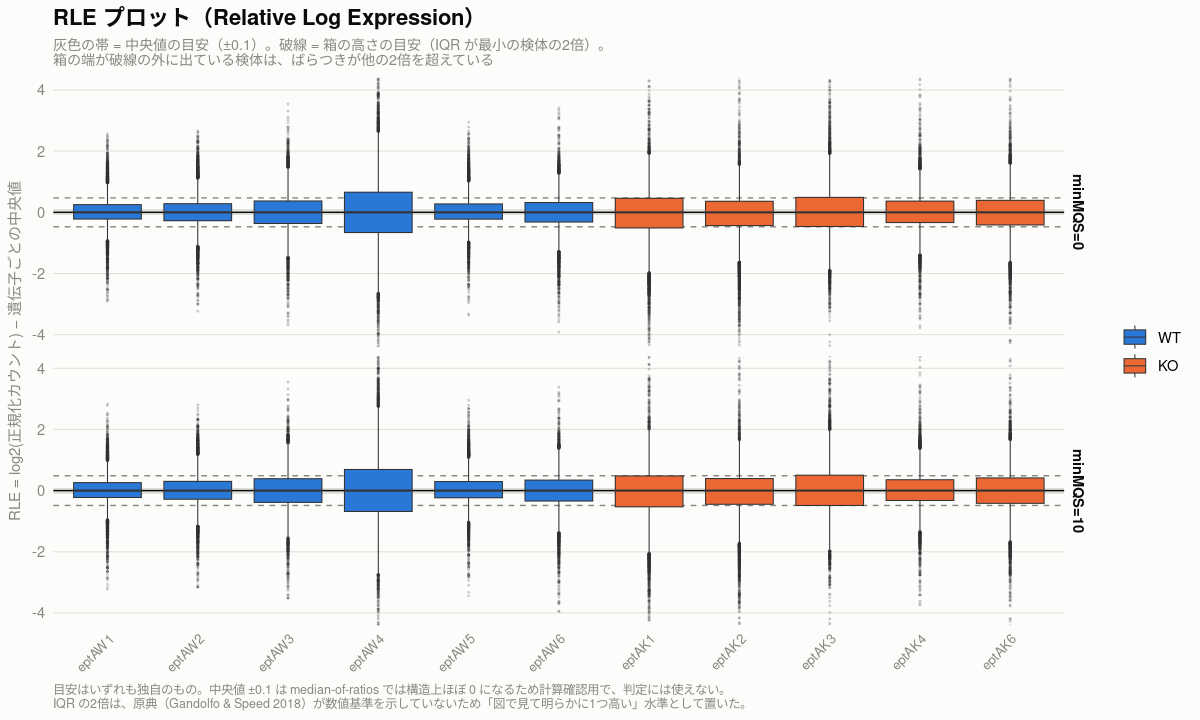

In [148]:
# ── RLE プロット ─────────────────────────────────────────────
# これが「検体間のずれ」を見るときの標準的な図。
#   Gandolfo & Speed (2018) RLE plots: Visualizing unwanted variation in
#   high dimensional data. PLoS ONE 13:e0191629
#
# 見方（元論文の指針。数値のしきい値は示されていない）
#   ・箱の中央値が 0 の線からずれていないか  → ずれていれば正規化が効いていない
#   ・箱の高さ（IQR）が検体でそろっているか  → 1つだけ高い検体は不均一な検体
#   ・ひげや外れ値が極端に伸びていないか
#
# median-of-ratios で正規化しているので中央値は構造上 0 に乗る。
# 実質見るのは【箱の高さ】。
library(ggplot2)

if (!exists('col_group')) col_group = c('WT' = '#2a78d6', 'KO' = '#eb6834')

rle_df = data.frame()
for (q in c(0, 10)) {
    m    = cnt[[paste0('q', q)]]
    keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
    m    = m[keep, ]; ok = rowSums(m == 0) == 0

    lgm = rowMeans(log(m[ok, ]))
    sf  = apply(m[ok, ], 2, function(x) exp(median(log(x) - lgm)))
    L   = log2(sweep(m[ok, ], 2, sf, '/'))
    rle = L - apply(L, 1, median)

    rle_df = rbind(rle_df, data.frame(設定 = paste0('minMQS=', q),
                                      name = rep(colnames(rle), each = nrow(rle)),
                                      value = as.vector(rle)))
}
rle_df = rle_df %>%
    left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(name = factor(name, levels = c(sort(seq_list$name[seq_list$group == 'WT']),
                                          sort(seq_list$name[seq_list$group == 'KO']))),
           group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

# ── 目安を図の中に描く ──────────────────────────────────
#   中央値の目安（絶対値 0.1 以内）→ 0 をはさんだ影
#   箱の高さの目安（IQR が最小の検体の2倍以内）
#     → 箱の上下の端は ±IQR/2 の位置に来るので、
#       「IQR <= 2 × 最小IQR」は「箱の端が ±最小IQR の線の内側」と同じ意味になる
iqr_min = rle_df %>% group_by(設定, name) %>% summarise(iqr = IQR(value), .groups='drop') %>%
    group_by(設定) %>% summarise(lim = min(iqr), .groups='drop')

options(repr.plot.width = 10, repr.plot.height = 6)

p = ggplot(rle_df, aes(x = name, y = value, fill = group)) +
    # 中央値の目安（±0.1）
    geom_rect(data = iqr_min, inherit.aes = FALSE,
              aes(xmin = -Inf, xmax = Inf, ymin = -0.1, ymax = 0.1),
              fill = col_muted, alpha = 0.25) +
    # 箱の高さの目安（±最小IQR。この外に箱の端が出ると IQR が2倍超）
    geom_hline(data = iqr_min, aes(yintercept =  lim), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_hline(data = iqr_min, aes(yintercept = -lim), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.4) +
    geom_boxplot(outlier.size = 0.25, outlier.alpha = 0.15, linewidth = 0.3) +
    facet_grid(設定 ~ .) +
    scale_fill_manual(values = col_group, name = NULL) +
    coord_cartesian(ylim = c(-4, 4)) +
    labs(title = 'RLE プロット（Relative Log Expression）',
         subtitle = paste0('灰色の帯 = 中央値の目安（±0.1）。破線 = 箱の高さの目安（IQR が最小の検体の2倍）。\n',
                           '箱の端が破線の外に出ている検体は、ばらつきが他の2倍を超えている'),
         x = NULL, y = 'RLE = log2(正規化カウント) − 遺伝子ごとの中央値',
         # 目安の出どころを図の中に残す
         caption = '目安はいずれも独自のもの。中央値 ±0.1 は median-of-ratios では構造上ほぼ 0 になるため計算確認用で、判定には使えない。\nIQR の2倍は、原典（Gandolfo & Speed 2018）が数値基準を示していないため「図で見て明らかに1つ高い」水準として置いた。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.x = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.x        = element_text(angle = 45, hjust = 1, size = 8),
          axis.title         = element_text(colour = col_muted, size = 9),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p))

## セル15-8-5: 検体間の距離のヒートマップ

**DESeq2 の vignette（Data transformations and visualization）で標準的に使われる図。**
検体どうしの似かたを総当たりで見る。

| 見るところ | 意味 |
|---|---|
| 同じ群どうしが近い（濃い） | **群の差がいちばん大きい変動要因**ということ |
| 1検体だけが全部から遠い（薄い） | **その検体が外れている** |

vignette は `rlog` / `vst` で変換してから距離を取るが、
ここは `log2(正規化カウント + 1)` で代用する（**DESeq2 はステージ5 で使う**）。

配色は量をあらわすので**1色の濃淡**（近い = 濃い）。

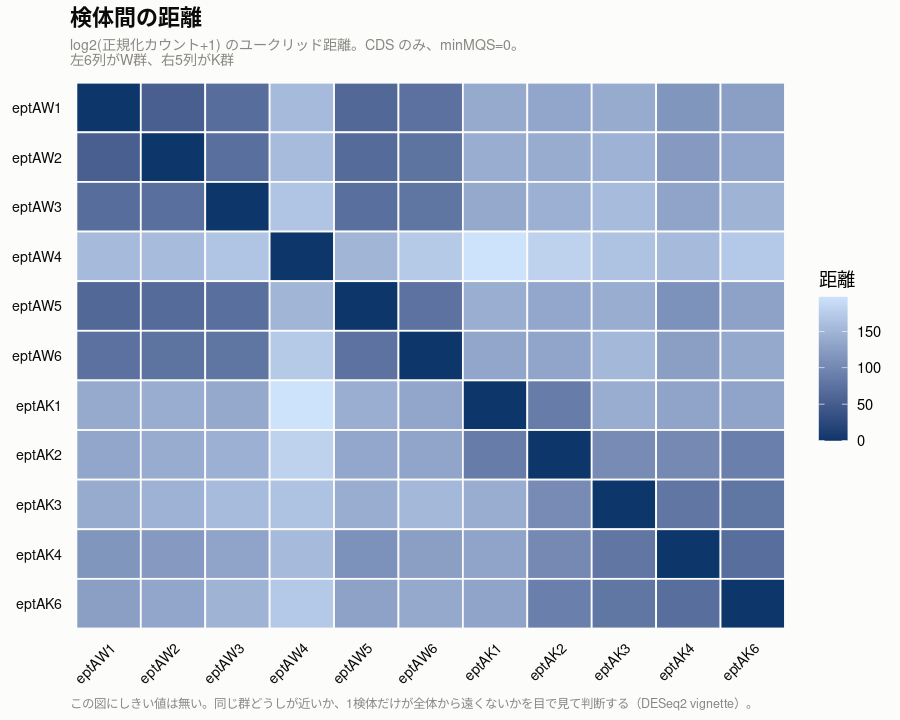

In [149]:
# ── 検体間の距離のヒートマップ ───────────────────────────────
# DESeq2 の vignette（Data transformations and visualization）で
# 標準的に使われる図。検体どうしの似かたを総当たりで見る。
#   ・同じ群どうしが近ければ、群の差がいちばん大きい変動要因
#   ・1検体だけが全部から遠ければ、その検体が外れている
#
# vignette は rlog / vst で変換してから距離を取るが、ここは
# log2(正規化カウント + 1) で代用する（DESeq2 はステージ5 で使う）

m    = cnt$q0
keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
m    = m[keep, ]; ok = rowSums(m == 0) == 0
lgm  = rowMeans(log(m[ok, ]))
sf   = apply(m[ok, ], 2, function(x) exp(median(log(x) - lgm)))
L    = log2(sweep(m[ok, ], 2, sf, '/') + 1)

dm   = as.matrix(dist(t(L)))                      # ユークリッド距離
ord  = c(sort(seq_list$name[seq_list$group == 'WT']),
         sort(seq_list$name[seq_list$group == 'KO']))
dm   = dm[ord, ord]

hm = data.frame(行 = rep(rownames(dm), times = ncol(dm)),
                列 = rep(colnames(dm), each  = nrow(dm)),
                距離 = as.vector(dm)) %>%
    mutate(行 = factor(行, levels = rev(ord)), 列 = factor(列, levels = ord))

options(repr.plot.width = 7.5, repr.plot.height = 6)

p = ggplot(hm, aes(x = 列, y = 行, fill = 距離)) +
    geom_tile(colour = col_surface, linewidth = 0.5) +
    # 量をあらわす配色なので1色の濃淡（近い = 濃い）
    scale_fill_gradient(low = '#0d366b', high = '#cde2fb', name = '距離') +
    labs(title = '検体間の距離',
         subtitle = paste0('log2(正規化カウント+1) のユークリッド距離。CDS のみ、minMQS=0。\n',
                           '左6列がW群、右5列がK群'),
         x = NULL, y = NULL,
         # 目安の出どころを図の中に残す
         caption = 'この図にしきい値は無い。同じ群どうしが近いか、1検体だけが全体から遠くないかを目で見て判断する（DESeq2 vignette）。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          panel.grid         = element_blank(),
          axis.text          = element_text(colour = col_text, size = 8.5),
          axis.text.x        = element_text(angle = 45, hjust = 1),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p))

### 考察: 検体間のずれ（セル15-8〜15-8-3 の結果）

## 中央値のずれ（箱の上下）は問題ない

| 設定 | 生 log2 の中央値 | 深度差 | size factor | 最大/最小 |
|---|---|---|---|---|
| minMQS=0 | 6.02 〜 8.04 | 4.1倍 | 0.629 〜 2.381 | **3.79倍** |
| minMQS=10 | 4.46 〜 6.39 | 3.8倍 | 0.651 〜 2.357 | **3.62倍** |

**目安（≤ 5倍）の内側。** 箱ひげで見える上下のずれは、ほぼそのまま深度の差で、
**size factor が取り除く。**

参考までに、`size_factor` が最大なのは `eptAK3`（2.38。深度も最大の 90.6 Mpairs）、
最小は `eptAW6`（0.63。深度 43.9 Mpairs かつ ncRNA 最多）。
**深度の順とほぼ一致している**ので、想定どおりの挙動。

## ★ ばらつきの幅（箱の高さ）は目安を超える。原因は `eptAW4` 一択

| 設定 | RLE IQR | 最大/最小 | 判定 |
|---|---|---|---|
| minMQS=0 | 0.473 〜 1.319 | **2.79倍** | ★ 目安（≤2）超え |
| minMQS=10 | 0.486 〜 1.373 | **2.83倍** | ★ 目安超え |

**どちらも `eptAW4` が最大、`eptAW1` が最小。**

**株ごとに分けても `eptAW4` が外れる。**

| 対象 | RLE IQR の最大/最小 | IQR 最大の検体 |
|---|---|---|
| 全株まとめて | 2.79倍 | **eptAW4** |
| Bth_St8 | 2.22倍 | **eptAW4** |
| Bth_VPI | 2.18倍 | **eptAW4** |
| Bun_8492 | 4.53倍 | **eptAW4** |
| Odo_St23 | 2.75倍 | **eptAW4** |

→ **群集組成の差で広がっているのではない。** 4株すべてで同じ検体が外れているので、
**`eptAW4` という検体そのものの性質。**

## `eptAW4` は独立な2つの指標で外れている

セル15-9 の PCA でも **`eptAW4` だけが PC2・PC3 で大きく離れている。**
RLE と PCA は別の計算なので、**独立な2つの証拠**ということになる。

これまでに見えている `eptAW4` の特徴:

| 指標 | eptAW4 | 他の検体 |
|---|---|---|
| rRNA（minMQS=0） | **12.65%** | 2.40〜6.68% |
| 宿主（マウス） | **3.58%** | 4.81〜9.75% |
| カウント0の CDS | **434** | 692〜1,365 |
| RLE IQR | **1.32** | 0.47〜0.99 |

**rRNA が他の2〜3倍、宿主が最少、発現が検出された遺伝子が最多**という組み合わせ。
rRNA 除去の効きが悪かった検体だが、それだけで RLE の広がりは説明しにくい。

## 判断

**除外はしない。** 理由は3つ。

1. **中央値（size factor 1.105）は中庸**で、系統的な偏りではなく**ばらつきの大きさ**の問題
2. W群（n=6）の1検体なので、**群間差を偽造する向きには働かない**（分散を増やして検出力を下げる向き）
3. n = 6 対 5 しかないので、**1検体落とすと検出力の損失の方が大きい**

**ステージ5 では次を行う。**

| やること | 目的 |
|---|---|
| DESeq2 の `plotDispEsts` と PCA（rlog / vst 後）で `eptAW4` を再確認 | 正規化後も外れるか |
| **`eptAW4` を除いた結果も出して、主要な結論が変わらないか確認** | 感度解析 |
| Cook's distance による外れ値フラグを確認（DESeq2 の既定機能） | 遺伝子単位の外れ値 |

**これを CLAUDE.md の §8（未決事項）に追記する。**

## セル15-9: PCA（vst 変換後）

過去notebook セル25-27 と同じ確認。**検体が群で分かれるか**を見る。
過去は3通りのカウントそれぞれで PCA を取っていたので、ここも2設定とも取る。

### ★ 過去notebook から変えた点: `log2(カウント+1)` ではなく **vst** を使う

**過去notebook は `log2(カウント+1)` に `prcomp` をかけていたが、この方法には既知の問題がある。**

カウントデータは**平均が大きい遺伝子ほど分散も大きい**ので、`log` を取っただけでは
低カウント遺伝子の分散が過大に残り、**PC1 が深度や検出遺伝子数に引きずられる。**

**実際このデータでそうなっていた。** `log2(カウント+1)` の PCA では
**PC1 と size factor の相関が r = +0.94**（セル15-9-2）。
つまり PC1 は「発現の違い」ではなく**「深度の違い」の軸**だった。
検体が一直線に並んで見えたのはそのため。

DESeq2 の vignette が PCA の前に推奨しているとおり、**分散安定化変換（vst）**を使う。
`blind = TRUE`（群の情報を使わない）が QC 目的には適切。

**「以前のコードに沿う」より「技術的な軸を生物学的な軸と取り違えない」を優先した。**

図は過去notebook の `base plot` ではなく ggplot にしてある
（このnotebook の他の図と配色・体裁をそろえるため）。

### ★ eptA の「遺伝子型マーカー」を解析から外す

`_deleted`（Bth_VPI / Bth_St8 / Bun）と `_3p`（Odo）の4 feature は
**K群で構造的にゼロになる**もので、**発現が下がっているのではなく配列が無い**
（または転写が止まっている）。GTF の `product` にも
「遺伝子型の確認用。K群でゼロ」と書いてある。

**これを入れたまま PCA をかけると、PC1 の正側の上位4つを全部これが占める。**

**ただしこれは悪いことばかりではない。**
「K群でゼロになるはずの feature が、実際に PC1 の最上位に来る」ことは
**解析が意図どおり効いていることの確認（陽性対照）**になる。

そこで**2通り作って両方見る。**

| 版 | 中身 | 用途 |
|---|---|---|
| **含む** | `_deleted` ×3、`_3p` ×1 を入れたまま | **解析が効いていることの確認（陽性対照）** |
| **除く** | それらを外す | **発現の違いだけを見る。解釈にはこちら** |

`_retained` ×2 と `_5p` ×1 は**どちらの版でも残す**（両群にあり、DE の比較対象）。

**この除外はステージ5（DESeq2）でも同じく必要。**

In [156]:
# ── PCA（vst 変換後）2通り ───────────────────────────────────
# 過去notebook（セル25-27）と同じ確認。検体が群で分かれるかを見る。
#
# ★ 過去notebook から変えた点1: log2(カウント+1) ではなく vst を使う
#   log を取っただけでは低カウント遺伝子の分散が過大に残り、PC1 が深度に引きずられる。
#   実際このデータでは PC1 と size factor の相関が r = +0.94 だった（セル15-9-2）。
#
# ★ 変えた点2: eptA の「遺伝子型マーカー」を外した版も作る
#   _deleted（3株）と _3p（Odo）は【K群で構造的にゼロになる】feature で、
#   発現が下がっているのではなく配列が無い（または転写が止まっている）。
#   2通り作って両方見る。
#     含む版 … これらが PC1 の上位に来るかで「解析が効いていること」を確認する（陽性対照）
#     除く版 … 発現の違いだけを見る（こちらを解釈に使う）
suppressMessages(library(DESeq2))

geno_marker = c('BT_RS09185_deleted', 'CE91St8_20540_deleted',
                'NQ510_RS14730_deleted', 'CE91St23_40970_3p')

pca_res = list()
for (q in c(0, 10)) {
    for (inc in c(TRUE, FALSE)) {
        m    = cnt[[paste0('q', q)]]
        keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS'
        if (!inc) keep = keep & !(rownames(m) %in% geno_marker)
        m = round(m[keep, ])

        dds = DESeqDataSetFromMatrix(m,
                  data.frame(row.names = colnames(m),
                             group = factor(seq_list$group[match(colnames(m), seq_list$name)])),
                  ~ group)
        vs = assay(varianceStabilizingTransformation(dds, blind = TRUE))
        vs = vs[apply(vs, 1, var) > 0, ]
        pca_res[[sprintf('q%d_%s', q, ifelse(inc, 'incl', 'excl'))]] = prcomp(t(vs))
    }
}

# 寄与率
data.frame(do.call(rbind, lapply(names(pca_res), function(k) {
    pca = pca_res[[k]]; v = round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
    data.frame(設定 = paste0('minMQS=', sub('^q(\\d+)_.*$', '\\1', k)),
               遺伝子型マーカー = ifelse(grepl('incl', k), '含む', '除く'),
               遺伝子数 = nrow(pca$rotation),
               PC1 = v[1], PC2 = v[2], PC3 = v[3],
               PC1_WT平均 = round(mean(pca$x[seq_list$group[
                   match(rownames(pca$x), seq_list$name)] == 'WT', 1]), 1),
               PC1_KO平均 = round(mean(pca$x[seq_list$group[
                   match(rownames(pca$x), seq_list$name)] == 'KO', 1]), 1))
})), row.names = NULL)

converting counts to integer mode

converting counts to integer mode

converting counts to integer mode

converting counts to integer mode



設定,遺伝子型マーカー,遺伝子数,PC1,PC2,PC3,PC1_WT平均,PC1_KO平均
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
minMQS=0,含む,17793,38.1,27.5,13.1,47.1,-56.6
minMQS=0,除く,17789,37.5,27.7,13.2,46.5,-55.8
minMQS=10,含む,16623,36.5,26.1,12.8,44.5,-53.4
minMQS=10,除く,16619,35.9,26.3,12.9,43.9,-52.6


## セル15-9図: PC1 vs PC2（2通りを並べる）

左が**遺伝子型マーカーを含む**、右が**除く**。
**構造がほとんど変わらなければ、PC1 はマーカーで作られたものではない**ということ。

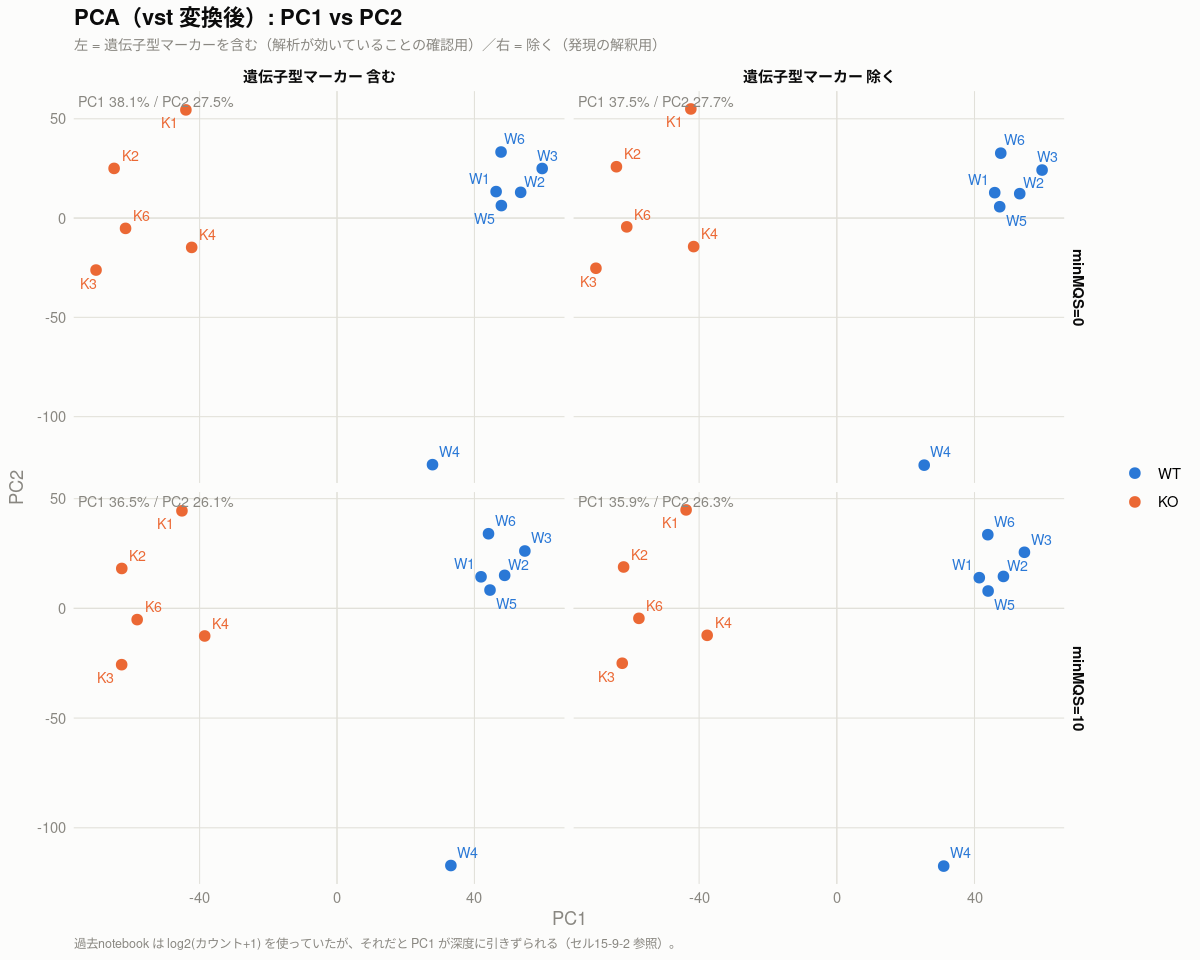

In [157]:
# ── PC1 vs PC2 を2通り並べて比べる ───────────────────────────
# 左が「遺伝子型マーカーを含む」、右が「除く」。
# 構造がほとんど変わらなければ、PC1 はマーカーで作られたものではないということ

pc12 = data.frame()
for (k in names(pca_res)) {
    pca = pca_res[[k]]; v = round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
    pc12 = rbind(pc12, data.frame(
        設定 = paste0('minMQS=', sub('^q(\\d+)_.*$', '\\1', k)),
        マーカー = ifelse(grepl('incl', k), '遺伝子型マーカー 含む', '遺伝子型マーカー 除く'),
        name = rownames(pca$x), x = pca$x[,1], y = pca$x[,2],
        軸ラベル = sprintf('PC1 %.1f%% / PC2 %.1f%%', v[1], v[2])))
}
pc12 = pc12 %>% left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')),
           マーカー = factor(マーカー, levels = c('遺伝子型マーカー 含む','遺伝子型マーカー 除く')))

options(repr.plot.width = 10, repr.plot.height = 8)

p = ggplot(pc12, aes(x = x, y = y, colour = group)) +
    geom_hline(yintercept = 0, colour = col_grid, linewidth = 0.3) +
    geom_vline(xintercept = 0, colour = col_grid, linewidth = 0.3) +
    geom_point(size = 2.6) +
    ggrepel::geom_text_repel(aes(label = sub('^eptA', '', name)), size = 3,
                             show.legend = FALSE, seed = 1, max.overlaps = 20) +
    geom_text(data = pc12 %>% distinct(設定, マーカー, 軸ラベル),
              inherit.aes = FALSE, aes(x = -Inf, y = Inf, label = paste0(' ', 軸ラベル)),
              hjust = 0, vjust = 1.4, size = 3, colour = col_muted) +
    facet_grid(設定 ~ マーカー, scales = 'free') +
    scale_colour_manual(values = col_group, name = NULL) +
    labs(title = 'PCA（vst 変換後）: PC1 vs PC2',
         subtitle = '左 = 遺伝子型マーカーを含む（解析が効いていることの確認用）／右 = 除く（発現の解釈用）',
         x = 'PC1', y = 'PC2',
         caption = '過去notebook は log2(カウント+1) を使っていたが、それだと PC1 が深度に引きずられる（セル15-9-2 参照）。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold', size = 9),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p))

## セル15-9図-2: PC2 vs PC3

PC1 は群の差、**PC2・PC3 は群の中での違い**を見る軸になっている。
遺伝子型マーカーを除く版で見る（含む版でもほぼ同じ）。

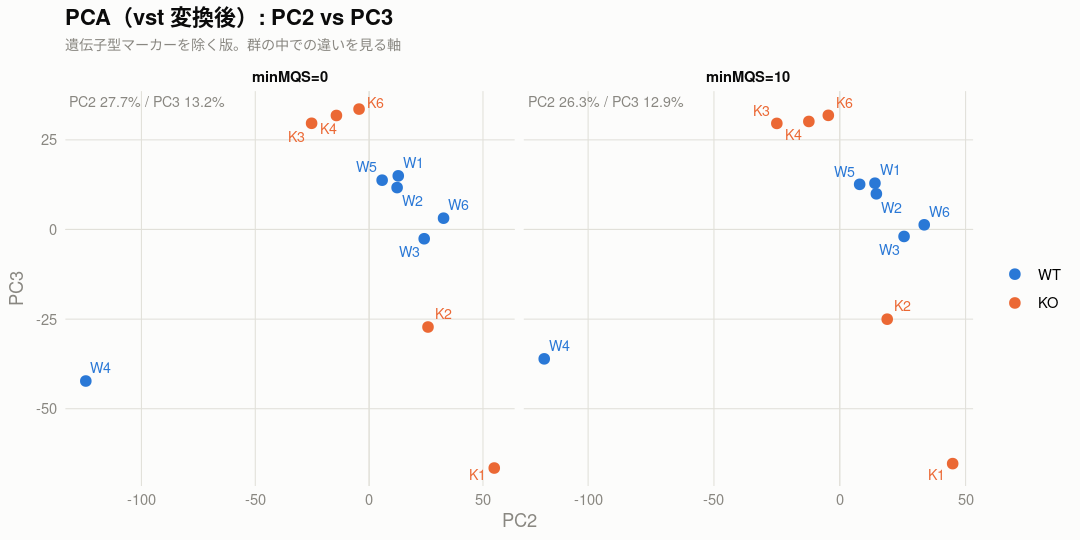

In [158]:
# ── PC2 vs PC3（eptAW4 の確認）───────────────────────────────
# PC1 は群の差、PC2・PC3 は群の中の違いを見る軸になっている。
# 遺伝子型マーカーを除く版で見る（含む版でもほぼ同じ）

pc23 = data.frame()
for (k in grep('excl', names(pca_res), value = TRUE)) {
    pca = pca_res[[k]]; v = round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
    pc23 = rbind(pc23, data.frame(
        設定 = paste0('minMQS=', sub('^q(\\d+)_.*$', '\\1', k)),
        name = rownames(pca$x), x = pca$x[,2], y = pca$x[,3],
        軸ラベル = sprintf('PC2 %.1f%% / PC3 %.1f%%', v[2], v[3])))
}
pc23 = pc23 %>% left_join(seq_list %>% dplyr::select(name, group), by = 'name') %>%
    mutate(group = factor(group, levels = c('WT','KO')),
           設定  = factor(設定,  levels = c('minMQS=0','minMQS=10')))

options(repr.plot.width = 9, repr.plot.height = 4.5)

p = ggplot(pc23, aes(x = x, y = y, colour = group)) +
    geom_hline(yintercept = 0, colour = col_grid, linewidth = 0.3) +
    geom_vline(xintercept = 0, colour = col_grid, linewidth = 0.3) +
    geom_point(size = 2.6) +
    ggrepel::geom_text_repel(aes(label = sub('^eptA', '', name)), size = 3,
                             show.legend = FALSE, seed = 1, max.overlaps = 20) +
    geom_text(data = pc23 %>% distinct(設定, 軸ラベル), inherit.aes = FALSE,
              aes(x = -Inf, y = Inf, label = paste0(' ', 軸ラベル)),
              hjust = 0, vjust = 1.4, size = 3, colour = col_muted) +
    facet_grid(. ~ 設定, scales = 'free') +
    scale_colour_manual(values = col_group, name = NULL) +
    labs(title = 'PCA（vst 変換後）: PC2 vs PC3',
         subtitle = '遺伝子型マーカーを除く版。群の中での違いを見る軸',
         x = 'PC2', y = 'PC3') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5))

suppressWarnings(print(p))

## セル15-9-2: PC が何を見ているかの確認

**PCA の軸が「生物学的な違い」ではなく「深度などの技術的な差」を拾っていないか**を調べる。
**検体が一直線に並ぶときは、たいてい1本の技術的な勾配が PC1 になっている。**

`log2(カウント+1)` と `vst` の両方で PCA を取り、各 PC と次の変数の相関を見る。

| 変数 | 何を表すか |
|---|---|
| `size_factor` | 正規化係数（典型的な遺伝子の相対的な発現水準） |
| `総カウントM` | CDS に割り当てられた総カウント（深度） |
| `検出遺伝子数` | カウントが 1 以上の CDS の数 |
| `Bth計` / `Bun_8492` | 群集組成（セル14-3） |

**技術変数と強く相関する PC は、その変数を見ているだけ**ということになる。

In [159]:
# ── PC が何を見ているかの確認 ───────────────────────────────
# PCA の軸が「生物学的な違い」ではなく「深度などの技術的な差」を拾っていないかを調べる。
# 検体が一直線に並ぶときは、たいてい1本の技術的な勾配が PC1 になっている。
#
# log2(カウント+1) と vst の両方で PCA を取り、各 PC と技術的な変数の相関を見る

m    = cnt$q0
keep = feat_info$biotype[match(rownames(m), feat_info$gene_id)] == 'CDS' &
       !(rownames(m) %in% geno_marker)        # セル15-9 で定義
m    = round(m[keep, ])

# 技術的な変数
ok  = rowSums(m == 0) == 0
lgm = rowMeans(log(m[ok, ]))
tech = data.frame(
    name         = colnames(m),
    size_factor  = apply(m[ok, ], 2, function(x) exp(median(log(x) - lgm))),
    総カウントM  = colSums(m) / 1e6,
    検出遺伝子数 = colSums(m > 0)) %>%
    left_join(share %>% dplyr::select(name, Bth計, Bun_8492), by = 'name')

# (A) 過去notebook と同じ log2(カウント+1)
lgm2 = log2(m + 1); lgm2 = lgm2[apply(lgm2, 1, var) > 0, ]
pa = prcomp(t(lgm2))
# (B) vst
dds = DESeqDataSetFromMatrix(m, data.frame(row.names = colnames(m),
          group = factor(seq_list$group[match(colnames(m), seq_list$name)])), ~ group)
vs = assay(varianceStabilizingTransformation(dds, blind = TRUE))
vs = vs[apply(vs, 1, var) > 0, ]
pb = prcomp(t(vs))

cor_tbl = data.frame()
for (nm in c('log2(カウント+1)', 'vst')) {
    pca = if (nm == 'log2(カウント+1)') pa else pb
    v   = round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
    for (k in c('size_factor', '総カウントM', '検出遺伝子数', 'Bth計', 'Bun_8492')) {
        cor_tbl = rbind(cor_tbl, data.frame(
            変換 = nm, 技術変数 = k,
            PC1寄与率 = v[1],
            PC1との相関 = round(cor(pca$x[, 1], tech[[k]]), 3),
            PC1のp値    = round(cor.test(pca$x[, 1], tech[[k]])$p.value, 4),
            PC2との相関 = round(cor(pca$x[, 2], tech[[k]]), 3)))
    }
}
cor_tbl

converting counts to integer mode



変換,技術変数,PC1寄与率,PC1との相関,PC1のp値,PC2との相関
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
log2(カウント+1),size_factor,45.9,0.941,0.0000,0.005
log2(カウント+1),総カウントM,45.9,0.773,0.0052,0.177
log2(カウント+1),検出遺伝子数,45.9,0.672,0.0234,0.720
log2(カウント+1),Bth計,45.9,-0.181,0.5940,0.784
log2(カウント+1),Bun_8492,45.9,0.387,0.2397,-0.611
vst,size_factor,37.5,-0.513,0.1062,-0.395
vst,総カウントM,37.5,-0.212,0.5317,-0.295
vst,検出遺伝子数,37.5,0.057,0.8673,-0.913
vst,Bth計,37.5,0.791,0.0037,-0.249


## セル15-9-2図: 相関を図で見る

`|r|` が大きいほど、その PC はその変数を見ている。

**破線（`|r| = 0.8`）も独自の目安。** 「その軸がその変数とほぼ同じ」と言える水準として置いた。

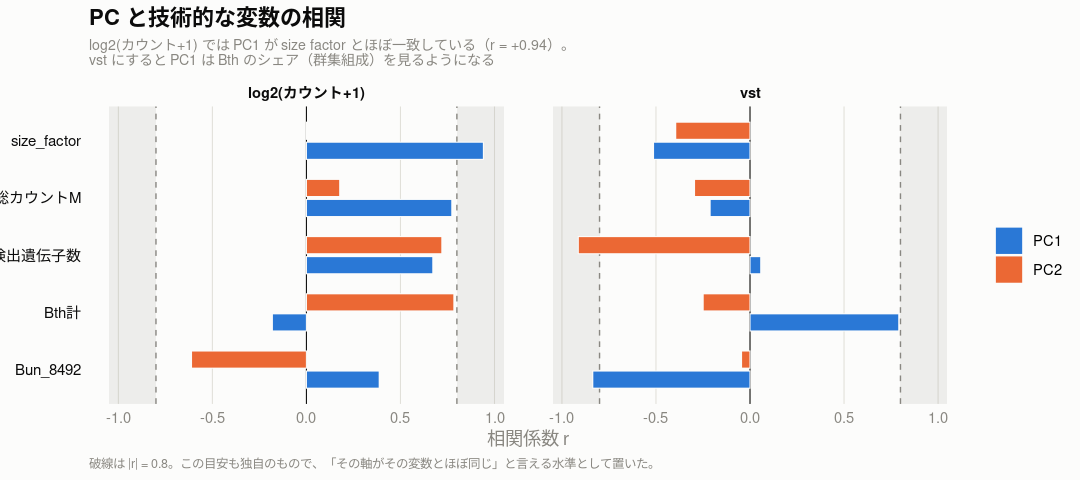

In [160]:
# ── 相関を図で見る ───────────────────────────────────────────
# |r| が大きいほど、その PC はその変数を見ている

cor_fig = cor_tbl %>%
    dplyr::select(変換, 技術変数, PC1 = PC1との相関, PC2 = PC2との相関) %>%
    pivot_longer(c(PC1, PC2), names_to = '軸', values_to = 'r') %>%
    mutate(技術変数 = factor(技術変数,
               levels = rev(c('size_factor','総カウントM','検出遺伝子数','Bth計','Bun_8492'))),
           変換 = factor(変換, levels = c('log2(カウント+1)','vst')))

options(repr.plot.width = 9, repr.plot.height = 4)

p = ggplot(cor_fig, aes(x = r, y = 技術変数, fill = 軸)) +
    # |r| >= 0.8 を「その軸はこの変数を見ている」とみなす目安
    #   データに依らない固定の長方形なので annotate() を使う（geom_rect だと
    #   行数分だけ重ね描きされて警告が出る）
    annotate('rect', xmin = -1.05, xmax = -0.8, ymin = -Inf, ymax = Inf,
             fill = col_muted, alpha = 0.12) +
    annotate('rect', xmin = 0.8, xmax = 1.05, ymin = -Inf, ymax = Inf,
             fill = col_muted, alpha = 0.12) +
    geom_vline(xintercept = 0, colour = col_text, linewidth = 0.3) +
    geom_vline(xintercept = c(-0.8, 0.8), linetype = 'dashed',
               colour = col_muted, linewidth = 0.4) +
    geom_col(position = position_dodge(width = 0.7), width = 0.6,
             colour = col_surface, linewidth = 0.3) +
    facet_grid(. ~ 変換) +
    scale_fill_manual(values = c('PC1' = '#2a78d6', 'PC2' = '#eb6834'), name = NULL) +
    scale_x_continuous(limits = c(-1.05, 1.05), breaks = seq(-1, 1, 0.5)) +
    labs(title = 'PC と技術的な変数の相関',
         subtitle = paste0('log2(カウント+1) では PC1 が size factor とほぼ一致している（r = +0.94）。\n',
                           'vst にすると PC1 は Bth のシェア（群集組成）を見るようになる'),
         x = '相関係数 r', y = NULL,
         caption = '破線は |r| = 0.8。この目安も独自のもので、「その軸がその変数とほぼ同じ」と言える水準として置いた。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          strip.background   = element_rect(fill = col_surface, colour = NA),
          strip.text         = element_text(colour = col_text, face = 'bold'),
          panel.grid.major.y = element_blank(),
          panel.grid.minor   = element_blank(),
          panel.grid.major.x = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.text.y        = element_text(colour = col_text, size = 9),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p))

## セル15-10: PC1 を決めている遺伝子（2通り）

過去notebook セル25 の末尾と同じ確認。**PC1 の両端に効いている遺伝子**を見る。

| 版 | 見るポイント |
|---|---|
| **含む** | **遺伝子型マーカー（`_deleted` / `_3p`）が上位に来ているか。** 来ていれば解析が意図どおり効いている（陽性対照） |
| **除く** | **発現の違いだけ。** ここが特定の1株で占められていたら、PC1 は「発現の差」ではなく「その株の菌量の差」を見ていることになる（セル14-4 の組成の群間差） |

**`dplyr::count` と明示して呼ぶ。** DESeq2 が読み込む `matrixStats` にも `count` があり、
そちらが先に当たると `Argument 'x' is not a vector: list` で落ちる。

In [161]:
# ── PC1 を決めている遺伝子（2通り）───────────────────────────
# 過去notebook（セル25 の末尾）と同じ確認。PC1 の両端に効いている遺伝子を見る。
#
# 含む版 … 遺伝子型マーカーが上位に来ていれば「解析が効いている」ことの確認になる（陽性対照）
# 除く版 … 発現の違いだけを見る。解釈にはこちらを使う
#
# dplyr:: を付けて呼ぶ。DESeq2 が読み込む matrixStats にも count があり、
# そちらが先に当たると「Argument 'x' is not a vector: list」で落ちる

ld_both = data.frame()
for (k in c('q0_incl', 'q0_excl')) {
    pca = pca_res[[k]]
    ld  = data.frame(gene_id = rownames(pca$rotation), PC1 = pca$rotation[, 1]) %>%
        left_join(feat_info %>% dplyr::select(gene_id, strain, product), by = 'gene_id') %>%
        mutate(版 = ifelse(grepl('incl', k), '含む', '除く'))
    ld_both = rbind(ld_both,
        ld %>% arrange(desc(PC1)) %>% head(10) %>% mutate(側 = 'PC1 正（W群で高い）'),
        ld %>% arrange(PC1)       %>% head(10) %>% mutate(側 = 'PC1 負（K群で高い）'))
}

ld_both %>%
    mutate(PC1 = round(PC1, 4), product = substr(product, 1, 40)) %>%
    dplyr::select(版, 側, gene_id, strain, PC1, product) %>%
    as.data.frame()

版,側,gene_id,strain,PC1,product
<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
含む,PC1 正（W群で高い）,NQ510_RS14730_deleted,Bun_8492,0.0926,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
含む,PC1 正（W群で高い）,CE91St8_20540_deleted,Bth_St8,0.0814,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
含む,PC1 正（W群で高い）,BT_RS09185_deleted,Bth_VPI,0.0624,eptA: K群で欠失する領域（遺伝子型の確認用。K群でゼロ）
含む,PC1 正（W群で高い）,CE91St23_40970_3p,Odo_St23,0.0552,eptA: 挿入点より3'側（K群でゼロなら転写終結）
含む,PC1 正（W群で高い）,CE91St8_37650,Bth_St8,0.0418,UDP-glucose dehydrogenase
含む,PC1 正（W群で高い）,CE91St8_09700,Bth_St8,0.0394,cysteine synthase
含む,PC1 正（W群で高い）,BT_RS15610,Bth_VPI,0.0384,cysteine synthase A
含む,PC1 正（W群で高い）,CE91St23_44470,Odo_St23,0.0384,hypothetical protein
含む,PC1 正（W群で高い）,CE91St8_37680,Bth_St8,0.0364,transcriptional regulator


## セル15-10-2: PC1 への寄与が大きい上位200遺伝子の株の内訳

4通り（2設定 × 2版）すべてで出す。**版による違いがほとんど無ければ、
遺伝子型マーカーは PC1 の性格を変えていない**ということ。

In [162]:
# ── PC1 への寄与が大きい上位200遺伝子の株の内訳 ───────────────
# ここが特定の1株で占められていたら、PC1 は「発現の差」ではなく
# 「その株の菌量の差」を見ていることになる（セル14-4 の組成の群間差）

do.call(rbind, lapply(c('q0_incl','q0_excl','q10_incl','q10_excl'), function(k) {
    pca = pca_res[[k]]
    data.frame(gene_id = rownames(pca$rotation), PC1 = pca$rotation[, 1]) %>%
        left_join(feat_info %>% dplyr::select(gene_id, strain), by = 'gene_id') %>%
        arrange(desc(abs(PC1))) %>% head(200) %>%
        dplyr::count(strain, name = 'n') %>%
        mutate(設定 = paste0('minMQS=', sub('^q(\\d+)_.*$', '\\1', k)),
               版   = ifelse(grepl('incl', k), '含む', '除く'))
})) %>%
    pivot_wider(names_from = strain, values_from = n, values_fill = 0) %>%
    dplyr::select(設定, 版, everything()) %>%
    as.data.frame()

設定,版,Bth_St8,Bth_VPI,Bun_8492,Odo_St23
<chr>,<chr>,<int>,<int>,<int>,<int>
minMQS=0,含む,115,39,7,39
minMQS=0,除く,114,40,7,39
minMQS=10,含む,113,28,13,46
minMQS=10,除く,114,29,12,45


## セル15-10-3: PC1 に効く遺伝子がゲノム上で固まっていないか

セル15-10 の上位遺伝子を見ると、**Bth_St8 の連番の遺伝子**（`CE91St8_295xx` 〜 `297xx`）が
並んでいた。**ゲノム上で隣り合う遺伝子がまとめて効いているなら、
個々の遺伝子ではなく「座位（オペロンや生合成クラスター）が丸ごと動いている」**ということになる。

探し方: `|PC1|` が上位200に入る遺伝子を「効いている」とみなし、
**位置順に並べて、5遺伝子以上まとまっている塊**を拾う（間に3遺伝子までの隙間は同じ塊とみなす）。

**★ DESeq2 を読み込むと dplyr の関数がいくつか隠される。**

| 隠される関数 | 隠すパッケージ |
|---|---|
| `count` | `matrixStats` |
| `first` | `S4Vectors` |
| `rename` / `setequal` | `S4Vectors` |
| `slice` | `IRanges` |
| `setdiff` / `union` | `GenomicRanges` |

このあたりは **`dplyr::` を付けて呼ぶ**。付けないと
`Argument 'x' is not a vector: list` のような分かりにくいエラーになる。

In [165]:
# ── PC1 に効いている遺伝子が、ゲノム上で固まっていないかを探す ──
# セル15-10 の上位遺伝子を見ると、Bth_St8 の連番の遺伝子（CE91St8_295xx 〜 297xx）が
# 並んでいた。ゲノム上で隣り合う遺伝子がまとめて効いているなら、
# 個々の遺伝子ではなく【座位（オペロンや生合成クラスター）が丸ごと動いている】ということ。
#
# ★ DESeq2 を読み込むと dplyr の関数がいくつか隠される。
#   first / count / rename / slice / setdiff / union などがそれにあたるので、
#   このあたりは dplyr:: を付けて呼ぶ

# feature ごとのゲノム上の位置
pos = gtf_count %>%
    mutate(product = str_match(attr, 'product "([^"]*)"')[, 2],
           strain  = sub("~.*", "", contig)) %>%
    group_by(gene_id) %>%
    summarise(contig  = dplyr::first(contig), strain = dplyr::first(strain),
              start   = min(start), end = max(end),
              product = dplyr::first(product), .groups = 'drop')

# 遺伝子型マーカーを除いた版の PC1 を使う
pca = pca_res[['q0_excl']]
ld_pos = data.frame(gene_id = rownames(pca$rotation), PC1 = pca$rotation[, 1]) %>%
    left_join(pos, by = 'gene_id')

# |PC1| が上位200に入る遺伝子を「効いている」とみなす
thr = quantile(abs(ld_pos$PC1), 1 - 200 / nrow(ld_pos))
cat(sprintf("上位200に入る |PC1| のしきい値 = %.4f\n\n", thr))

# 株・contig ごとに位置順に並べ、効いている遺伝子が連続している塊を探す
#   （間に3遺伝子までの隙間は同じ塊とみなす）
blocks = data.frame()
for (ct in unique(ld_pos$contig)) {
    d = ld_pos %>% filter(contig == ct) %>% arrange(start)
    hit = which(abs(d$PC1) >= thr)
    if (length(hit) < 5) next
    grp_id = cumsum(c(1, diff(hit) > 3))
    for (b in unique(grp_id)) {
        ii = hit[grp_id == b]
        if (length(ii) < 5) next                 # 5遺伝子以上まとまっているものだけ
        rng = range(ii)
        blocks = rbind(blocks, data.frame(
            contig = ct, 株 = d$strain[1],
            先頭 = d$gene_id[rng[1]], 末尾 = d$gene_id[rng[2]],
            遺伝子数 = rng[2] - rng[1] + 1, 上位200の数 = length(ii),
            開始bp = d$start[rng[1]], 終了bp = d$end[rng[2]],
            長さkb = round((d$end[rng[2]] - d$start[rng[1]]) / 1000, 1),
            PC1平均 = round(mean(d$PC1[rng[1]:rng[2]]), 4),
            向き = ifelse(mean(d$PC1[rng[1]:rng[2]]) > 0, 'W群で高い', 'K群で高い')))
    }
}
blocks %>% arrange(desc(遺伝子数)) %>% as.data.frame()

上位200に入る |PC1| のしきい値 = 0.0233



contig,株,先頭,末尾,遺伝子数,上位200の数,開始bp,終了bp,長さkb,PC1平均,向き
<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>
Bth_St8~BQNN01000001.1,Bth_St8,CE91St8_29520,CE91St8_29880,37,36,3896445,3931832,35.4,-0.0421,K群で高い
Bth_St8~BQNN01000001.1,Bth_St8,CE91St8_26040,CE91St8_26140,11,11,3496312,3509462,13.2,0.0287,W群で高い
Bth_St8~BQNN01000001.1,Bth_St8,CE91St8_37610,CE91St8_37680,8,6,4903245,4912087,8.8,0.0311,W群で高い
Odo_St23~BQOE01000001.1,Odo_St23,CE91St23_35330,CE91St23_35390,7,6,4308443,4316383,7.9,0.0259,W群で高い
Odo_St23~BQOE01000001.1,Odo_St23,CE91St23_17090,CE91St23_17140,6,6,2061652,2067334,5.7,-0.0277,K群で高い
Bth_St8~BQNN01000001.1,Bth_St8,CE91St8_38260,CE91St8_38300,5,5,4994732,5000849,6.1,0.0284,W群で高い


## セル15-10-4: 見つかった座位の中身を位置順に並べる

座位ごとに、**ゲノム上の順番**で遺伝子を並べ、PC1 への効き方と `product` を見る。
上位200に入っているものに **★** を付ける。

**`product` の並びを見れば、その座位が何をする一式なのかが読める。**

In [166]:
# ── 見つかった座位の中身を位置順に並べる ───────────────────
# 座位ごとに、ゲノム上の順番で遺伝子を並べ、PC1 への効き方と product を見る。
# 上位200に入っているものに ★ を付ける

for (i in 1:nrow(blocks)) {
    d = ld_pos %>%
        filter(contig == blocks$contig[i],
               start >= blocks$開始bp[i], end <= blocks$終了bp[i]) %>%
        arrange(start) %>%
        mutate(上位200 = ifelse(abs(PC1) >= thr, '★', ''),
               PC1 = round(PC1, 4),
               位置kb = round(start / 1000),
               product = substr(product, 1, 46)) %>%
        dplyr::select(上位200, gene_id, 位置kb, PC1, product)

    cat(sprintf("\n##### 座位 %d: %s 〜 %s（%s、%.1f kb、%s）#####\n",
                i, blocks$先頭[i], blocks$末尾[i], blocks$株[i],
                blocks$長さkb[i], blocks$向き[i]))
    print(as.data.frame(d), row.names = FALSE)
}


##### 座位 1: CE91St8_26040 〜 CE91St8_26140（Bth_St8、13.2 kb、W群で高い）#####
 上位200       gene_id 位置kb    PC1                              product
       ★ CE91St8_26040   3496 0.0307   capsule polysaccharide transporter
       ★ CE91St8_26050   3499 0.0286     chain-length determining protein
       ★ CE91St8_26060   3500 0.0286                 hypothetical protein
       ★ CE91St8_26070   3502 0.0299                 hypothetical protein
       ★ CE91St8_26080   3503 0.0287                 hypothetical protein
       ★ CE91St8_26090   3504 0.0310                 hypothetical protein
       ★ CE91St8_26100   3504 0.0315                 hypothetical protein
       ★ CE91St8_26110   3506 0.0265                 glycosyl transferase
       ★ CE91St8_26120   3507 0.0237        glycosyl transferase family 2
       ★ CE91St8_26130   3508 0.0260                    sugar transferase
       ★ CE91St8_26140   3509 0.0307 dTDP-4-dehydrorhamnose 3,5-epimerase

##### 座位 2: CE91St8_29520 〜 CE91St8_29880（Bt

## セル15-10-5図: ゲノム上の位置と PC1 への効き方

横軸がゲノム上の位置、縦軸が PC1 への効き方（loading）。

**座位が丸ごと動いているなら、特定の位置に点が固まって上下どちらかに振れる。**

| 図の要素 | 意味 |
|---|---|
| 破線 | 上位200に入るしきい値 |
| 色の帯 | 5遺伝子以上まとまって効いている座位（青 = W群で高い、橙 = K群で高い） |
| 橙の点 | 上位200に入る遺伝子 |

帯が細すぎて見えなくなるのを防ぐため、**最低 40 kb の幅で描いている**（実際の長さはラベルの値）。

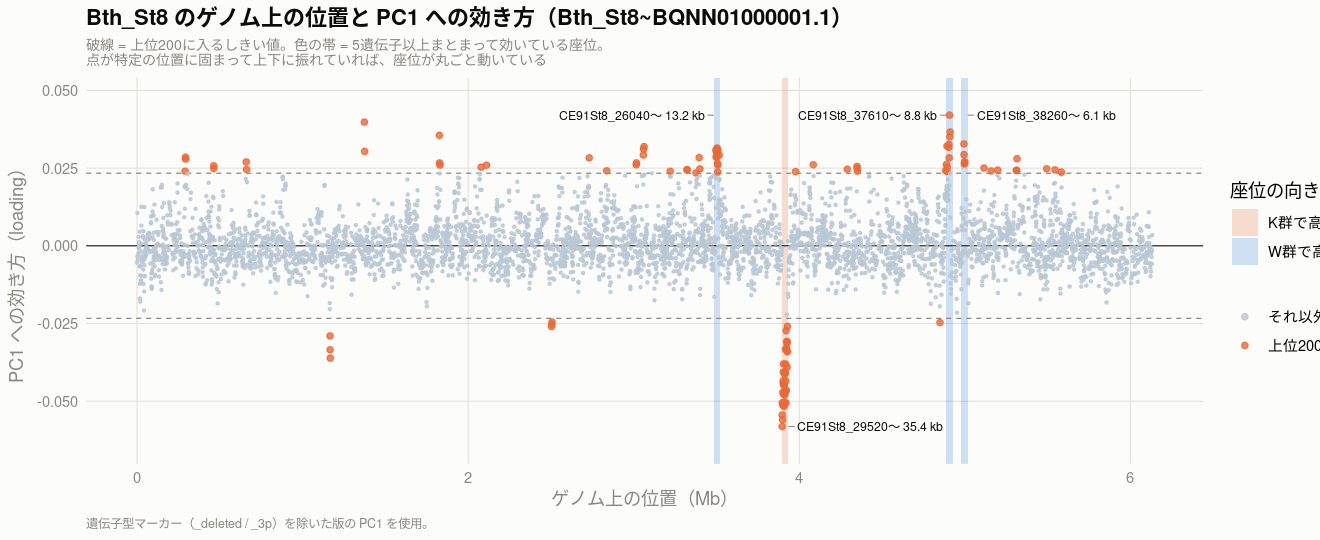

In [167]:
# ── ゲノム上の位置に沿って PC1 への効き方を描く ─────────────
# 横軸がゲノム上の位置、縦軸が PC1 への効き方。
# 座位が丸ごと動いているなら、特定の位置に点が固まって上下どちらかに振れる

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

# 遺伝子数が最も多い contig（＝主染色体）で見る
main_ct = ld_pos %>% filter(strain == 'Bth_St8') %>%
    dplyr::count(contig, name = 'n') %>% arrange(desc(n)) %>% slice_head(n = 1) %>% pull(contig)

gmap = ld_pos %>% filter(contig == main_ct) %>%
    mutate(位置Mb = start / 1e6,
           効いている = ifelse(abs(PC1) >= thr, '上位200', 'それ以外'))

blk = blocks %>% filter(contig == main_ct) %>%
    mutate(開始Mb = 開始bp / 1e6, 終了Mb = 終了bp / 1e6,
           中心Mb = (開始bp + 終了bp) / 2e6,
           # 帯が細すぎると見えないので、最低 40 kb の幅で描く
           描画開始 = pmin(開始Mb, 中心Mb - 0.02),
           描画終了 = pmax(終了Mb, 中心Mb + 0.02),
           ラベル = sprintf('%s〜 %.1f kb', 先頭, 長さkb))

options(repr.plot.width = 11, repr.plot.height = 4.5)

p = ggplot(gmap, aes(x = 位置Mb, y = PC1)) +
    # 見つかった座位をハイライト
    geom_rect(data = blk, inherit.aes = FALSE,
              aes(xmin = 描画開始, xmax = 描画終了, ymin = -Inf, ymax = Inf,
                  fill = 向き), alpha = 0.22) +
    geom_hline(yintercept = 0, colour = col_text, linewidth = 0.3) +
    geom_hline(yintercept = c(-thr, thr), linetype = 'dashed',
               colour = col_muted, linewidth = 0.35) +
    geom_point(aes(colour = 効いている, size = 効いている), alpha = 0.8) +
    # ラベルは重なるので ggrepel で横方向にずらす
    ggrepel::geom_text_repel(data = blk, inherit.aes = FALSE,
              aes(x = 中心Mb,
                  y = ifelse(PC1平均 > 0, max(gmap$PC1), min(gmap$PC1)),
                  label = ラベル),
              size = 2.6, colour = col_text, direction = 'x', seed = 1,
              min.segment.length = 0, segment.colour = col_muted, segment.size = 0.3,
              box.padding = 0.4, point.padding = 0.1) +
    scale_colour_manual(values = c('上位200' = '#eb6834', 'それ以外' = '#b9c6d4'), name = NULL) +
    scale_size_manual(values = c('上位200' = 1.5, 'それ以外' = 0.6), guide = 'none') +
    scale_fill_manual(values = c('W群で高い' = '#2a78d6', 'K群で高い' = '#eb6834'),
                      name = '座位の向き') +
    scale_y_continuous(expand = expansion(mult = c(0.12, 0.12))) +
    labs(title = sprintf('Bth_St8 のゲノム上の位置と PC1 への効き方（%s）', main_ct),
         subtitle = paste0('破線 = 上位200に入るしきい値。色の帯 = 5遺伝子以上まとまって効いている座位。\n',
                           '点が特定の位置に固まって上下に振れていれば、座位が丸ごと動いている'),
         x = 'ゲノム上の位置（Mb）', y = 'PC1 への効き方（loading）',
         caption = '遺伝子型マーカー（_deleted / _3p）を除いた版の PC1 を使用。') +
    theme_minimal(base_size = 11) +
    theme(panel.background   = element_rect(fill = col_surface, colour = NA),
          plot.background    = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor   = element_blank(),
          panel.grid.major   = element_line(colour = col_grid, linewidth = 0.3),
          axis.text          = element_text(colour = col_muted),
          axis.title         = element_text(colour = col_muted),
          plot.title         = element_text(colour = col_text, face = 'bold'),
          plot.subtitle      = element_text(colour = col_muted, size = 8.5),
          plot.caption       = element_text(colour = col_muted, size = 7.5, hjust = 0))

suppressWarnings(print(p))

## セル15-10-6: 座位の範囲を前後に広げて、どこまでが一続きなのかを見る

セル15-10-3 の塊は「`|PC1|` が上位200に入る遺伝子の連続」で切ったものなので、
**座位の端が切れている可能性がある。**

*Bacteroides* の CPS 座位は**片端に転写制御因子が2つ**並ぶ構成なので、
それを手がかりに**前後 10 kb まで広げて**並べ、座位の実際の範囲を見る。

| 記号 | 意味 |
|---|---|
| **■** | セル15-10-3 が検出した塊の中 |
| **★** | `|PC1|` が上位200に入る |
| 記号なし | 前後 10 kb の余白（隣の座位が入り込むので、ここは参考） |

**PC1 の値が塊の外でも同じ向きに続いていれば、座位はそこまで伸びている。**

In [ ]:
# ── 座位の範囲を前後に広げて、どこからどこまでが一続きなのかを見る ──
# セル15-10-3 の塊は「上位200に入る遺伝子の連続」で切ったものなので、
# 座位の端が切れている可能性がある。
# Bacteroides の CPS 座位は【片端に転写制御因子が2つ】並ぶ構成なので、
# それを手がかりに前後 10 kb まで広げて並べる。
#   塊の中 = ■、上位200に入る = ★

ow = getOption('width'); options(width = 140)   # 折り返しを防ぐ

for (i in 1:nrow(blocks)) {
    d = ld_pos %>%
        filter(contig == blocks$contig[i],
               start >= blocks$開始bp[i] - 10000,
               end   <= blocks$終了bp[i] + 10000) %>%
        arrange(start) %>%
        mutate(塊の中 = ifelse(start >= blocks$開始bp[i] & end <= blocks$終了bp[i], '■', ''),
               上位200 = ifelse(abs(PC1) >= thr, '★', ''),
               PC1 = round(PC1, 4), 位置kb = round(start/1000),
               product = substr(product, 1, 42)) %>%
        dplyr::select(塊の中, 上位200, gene_id, 位置kb, PC1, product)

    cat(sprintf("\n##### 塊 %d: %s 〜 %s（%s、%s、前後 10 kb 込み）#####\n",
                i, blocks$先頭[i], blocks$末尾[i], blocks$株[i], blocks$向き[i]))
    print(as.data.frame(d), row.names = FALSE)
}

options(width = ow)

## セル15-10-7: 各塊が何の遺伝子座なのかを `product` の顔ぶれから推定する

CPS 座位は、**その座位が使う糖ヌクレオチドを作る酵素を自前で持っている。**
したがって **どの酵素があるか → どんな糖を含む多糖か** まで推定できる。

そこで `product` の文字列を対応表と照合し、座位ごとに

- **CPS:糖の種類**（糖ヌクレオチドを作る酵素。多糖の糖組成を決める）
- **CPS:組み立て**（糖転移酵素・鎖長制御・膜間輸送・発現制御）
- **他の機能**（CPS とは無関係の酵素）

に分類して数える。**両方の CPS カテゴリが塊内に揃えば CPS 座位**と判定する。

### 個数を「塊内 + 余白」の形で出す理由

前後 10 kb の余白には**隣の別座位が入り込む。** 実際に塊5（`CE91St23_17090`〜`17140`）では、
余白側にだけ CPS 遺伝子があり**塊そのものは代謝酵素の並び**だった。
余白をまとめて数えると**隣の座位を誤って塊の性質にしてしまう**ので、分けて数える。

### ★ 2つの限界

1. **これは `product` 文字列の照合による推定で、配列解析ではない。**
   実際の糖組成を確かめるには、多糖を単離して糖組成分析をする必要がある。
2. **`hypothetical protein` は中身がわからない。** CPS 座位ではこれが座位ごとに
   固有の糖転移酵素群であることが多いが、**本当にそうかはここでは言えない。**

In [ ]:
# ── 各塊が何の遺伝子座なのかを、product の顔ぶれから推定する ───────
# CPS 座位は「その座位が使う糖ヌクレオチドを作る酵素」を自前で持っている。
# したがって【どの酵素があるか】から【どんな糖を含む多糖か】まで推定できる。
#
# ★ これは product 文字列の照合による推定であって、配列解析ではない。
#   実際の糖組成を確かめるには多糖を単離して糖組成分析をする必要がある。
# ★ セル15-10-3 の塊は「上位200に入った遺伝子の連続」なので、座位の端が
#   切れている可能性がある。そこで前後10kbの余白も見るが、余白には隣の
#   別座位が入り込むため、【塊内】と【余白】を分けて数える。
#   判定は塊内を主、余白は「座位が外に続いているか」の参考にする。

# product の文字列 → それが示す糖・機能 の対応表
enz_key = data.frame(
    分類 = c(rep('CPS:糖の種類', 6), rep('CPS:組み立て', 5), rep('他の機能', 4)),
    パターン = c('dTDP-4-dehydrorhamnose',
                 'N-acetylneuraminate synthase',
                 'UDP-N-acetyl glucosamine 2-epimerase',
                 'UDP-glucose.*dehydrogenase',
                 'aminotransferase DegT|pyridoxal phosphate-dependent aminotransferase',
                 'nucleoside-diphosphate sugar epimerase|nucleotide sugar epimerase',
                 'galactose phosphotransferase|galactose phosphate transferase',
                 'glycosyl transferase|sugar transferase|glycosyltransferase',
                 'chain-length determining|tyrosine protein kinase',
                 'capsule polysaccharide transporter|flippase MurJ|capsular polysaccharide biosynthesis',
                 'transcriptional regulator',
                 'dehydrogenase subunit beta|dihydrolipo|lipoate',
                 'chaperone|Clp protease|universal stress|gyrase',
                 'outer membrane protein|OmpA',
                 'glucosaminidase|nucleotidase|metallophosphatase|glycosyl hydrolase'),
    意味 = c('L-ラムノース（dTDP-L-Rha 経路）',
             'ノヌロソン酸（シアル酸型）の合成',
             'ManNAc への変換（ノヌロソン酸合成の前段）',
             'グルクロン酸（UDP-GlcA）',
             'アミノ糖への変換（アミノ基転移酵素）',
             '糖ヌクレオチドのエピ化（糖の種類を増やす）',
             '最初の糖を脂質担体に載せる（WbaP 型の起点酵素）',
             '糖の付加（繰り返し単位を組む）',
             '鎖長の制御（Wzz / Wzc 型）',
             '重合単位の膜間輸送・輸出（Wzx 型など）',
             '座位の発現制御（upxY / upxZ に相当すると思われる）',
             '分岐鎖2-オキソ酸脱水素酵素複合体（分岐鎖脂肪酸の材料）',
             'ストレス応答（シャペロン・プロテアーゼ）',
             '外膜タンパク質',
             '糖加水分解・リン酸エステル分解（栄養獲得）'))

for (i in 1:nrow(blocks)) {
    w = ld_pos %>% filter(contig == blocks$contig[i],
                          start >= blocks$開始bp[i] - 10000,
                          end   <= blocks$終了bp[i] + 10000)
    inb = w$start >= blocks$開始bp[i] & w$end <= blocks$終了bp[i]   # 塊内か余白か

    cat(sprintf("\n##### 塊 %d: %s 〜 %s（%s、%.1f kb、%s）#####\n",
                i, blocks$先頭[i], blocks$末尾[i], blocks$株[i],
                blocks$長さkb[i], blocks$向き[i]))
    cat(sprintf("  遺伝子数: 塊内 %d 個 / 前後10kbの余白 %d 個\n", sum(inb), sum(!inb)))
    cat("  （個数は 塊内 + 余白 の形で示す）\n")

    cls_in = character(0)
    for (j in 1:nrow(enz_key)) {
        hit = grepl(enz_key$パターン[j], w$product, ignore.case = TRUE)
        if (!any(hit)) next
        cat(sprintf("  %2d + %-2d  [%s] %s\n", sum(hit & inb), sum(hit & !inb),
                    enz_key$分類[j], enz_key$意味[j]))
        if (any(hit & inb)) cls_in = c(cls_in, enz_key$分類[j])
    }
    hit = grepl('integrase', w$product, ignore.case = TRUE)
    if (any(hit)) cat(sprintf("  %2d + %-2d  [他の機能] インテグラーゼ（可動性因子の痕跡）\n",
                              sum(hit & inb), sum(hit & !inb)))
    hit = grepl('^hypothetical', w$product)
    cat(sprintf("  %2d + %-2d  hypothetical protein\n", sum(hit & inb), sum(hit & !inb)))

    # 判定：糖ヌクレオチド合成系と組み立て系の両方が塊内に揃えば CPS 座位
    if (all(c('CPS:糖の種類','CPS:組み立て') %in% cls_in)) {
        cat("  → 判定: CPS（莢膜多糖）生合成座位。hypothetical は座位ごとに固有の糖転移酵素群と思われる\n")
    } else if ('CPS:組み立て' %in% cls_in) {
        cat("  → 判定: 多糖合成に関わる座位の一部と思われる（組み立て系はあるが糖の種類を決める酵素が塊内にない。余白側を参照）\n")
    } else {
        cat("  → 判定: 多糖合成座位ではない\n")
    }
}

## セル15-10-8: 各塊の遺伝子を `product` と `Preferred_name` で列挙する

GTF には**2系統の名前**が入っている（ステージ2 で付けた属性）。

| 属性 | 出どころ | 性格 |
|---|---|---|
| `product` | NCBI / DDBJ のアノテーション | 登録時の記載。`hypothetical protein` が多い |
| `Preferred_name` | eggNOG-mapper | オルソログ群の代表遺伝子名。**`product` が `hypothetical` でも名前が付くことがある** |
| `PFAMs` | eggNOG-mapper | ドメイン名。**機能の直接的な手がかり** |
| `Description` | eggNOG-mapper | ドメインの説明文。`product` に無い情報が入っていることがある |

**2系統は独立なので、両方を並べると片方だけでは見えない遺伝子がわかる。**

### このセルの後半: 転写制御因子の `PFAMs` を確認する

セル15-10-7 までは「座位の端に `transcriptional regulator` が2つ並ぶ配置」から
`upxY` / `upxZ` **と推定**していた。

UpxY は **NusG ファミリーの転写アンチターミネーター**として知られるので、
`PFAMs` に `NusG` が入っていれば、**配置だけに頼らない根拠**になる。

In [ ]:
# ── 各塊の遺伝子を product と Preferred_name で列挙する ─────────────
# product は NCBI/DDBJ のアノテーション、Preferred_name は eggNOG-mapper が
# 付けた遺伝子名（オルソログの代表名）。両者は独立なので、
# product が hypothetical でも Preferred_name が付くことがあり、その逆もある。
#   塊の中 = ■、上位200に入る = ★、NA / 空欄 = 名前が付いていない

ann = gtf_count %>%
    mutate(Preferred_name = str_match(attr, 'Preferred_name "([^"]*)"')[, 2],
           PFAMs          = str_match(attr, 'PFAMs "([^"]*)"')[, 2],
           COG            = str_match(attr, 'COG_category "([^"]*)"')[, 2],
           EC             = str_match(attr, 'EC "([^"]*)"')[, 2]) %>%
    distinct(gene_id, .keep_all = TRUE) %>%
    dplyr::select(gene_id, Preferred_name, PFAMs, COG, EC)

ow = getOption('width'); options(width = 150)   # 折り返しを防ぐ

for (i in 1:nrow(blocks)) {
    d = ld_pos %>%
        filter(contig == blocks$contig[i],
               start >= blocks$開始bp[i] - 10000,
               end   <= blocks$終了bp[i] + 10000) %>%
        left_join(ann, by = 'gene_id') %>%
        arrange(start) %>%
        mutate(塊の中 = ifelse(start >= blocks$開始bp[i] & end <= blocks$終了bp[i], '■', ''),
               上位200 = ifelse(abs(PC1) >= thr, '★', ''),
               Pref名 = ifelse(is.na(Preferred_name) | Preferred_name == 'NA', '-',
                               Preferred_name),
               product = substr(product, 1, 46)) %>%
        dplyr::select(塊の中, 上位200, gene_id, Pref名, product)

    cat(sprintf("\n##### 塊 %d: %s 〜 %s（%s、%s、前後 10 kb 込み）#####\n",
                i, blocks$先頭[i], blocks$末尾[i], blocks$株[i], blocks$向き[i]))
    print(as.data.frame(d), row.names = FALSE)
}

# ── 転写制御因子の PFAMs を確認する（upxY / upxZ の推定の裏付け）──────
# UpxY は NusG ファミリーの転写アンチターミネーターとして知られる。
# もし PFAMs に NusG が入っていれば、「座位の端に制御因子が2つ」という
# 配置だけに頼らない根拠になる
cat("\n\n##### CPS 座位の転写制御因子の PFAMs #####\n")
reg = ld_pos %>%
    filter(grepl('transcriptional regulator', product, ignore.case = TRUE)) %>%
    left_join(ann, by = 'gene_id')
reg = reg[sapply(reg$start, function(s)
          any(s >= blocks$開始bp - 10000 & s <= blocks$終了bp + 10000)), ] %>%
    arrange(start) %>%
    mutate(PC1 = round(PC1, 4), 位置kb = round(start / 1000),
           Pref名 = ifelse(is.na(Preferred_name) | Preferred_name == 'NA', '-',
                           Preferred_name)) %>%
    dplyr::select(gene_id, 位置kb, PC1, Pref名, PFAMs, COG)
print(as.data.frame(reg), row.names = FALSE)

options(width = ow)

### 考察: PC1 の正体は莢膜多糖（CPS）座位の切り替わり（セル15-10〜15-10-8 の結果）

## PC1 は「遺伝子が1つずつ動いた結果」ではなく「座位が丸ごと入れ替わった結果」

`|PC1|` 上位200の遺伝子を位置順に並べると、**6つの塊**ができた。
いずれも**連続した遺伝子がまとめて同じ向きに効いている。**

| 塊 | 株 | 範囲 | 位置 | 長さ | 上位200 | 向き | 判定（セル15-10-7） |
|---|---|---|---|---|---|---|---|
| 2 | Bth_St8 | `CE91St8_29520`〜`29880` | 3.90〜3.93 Mb | **35.4 kb** | **36 / 37** | **K群で高い** | **CPS 座位** |
| 1 | Bth_St8 | `CE91St8_26040`〜`26140` | 3.50〜3.51 Mb | 13.2 kb | **11 / 11** | **W群で高い** | **CPS 座位** |
| 3 | Bth_St8 | `CE91St8_37610`〜`37680` | 4.90〜4.91 Mb | 8.8 kb | 6 / 8 | W群で高い | **CPS 座位** |
| 4 | Bth_St8 | `CE91St8_38260`〜`38300` | 4.99〜5.00 Mb | 6.1 kb | 5 / 5 | W群で高い | CPS ではない（下記） |
| 6 | Odo_St23 | `CE91St23_35330`〜`35390` | 4.31〜4.32 Mb | 7.9 kb | 6 / 7 | W群で高い | CPS 座位（5′側が塊の外） |
| 5 | Odo_St23 | `CE91St23_17090`〜`17140` | 2.06〜2.07 Mb | 5.7 kb | 6 / 6 | K群で高い | CPS ではない（下記） |

**※ 塊の番号はセル15-10-3 が出す位置順の番号。表は長さ順に並べ替えてある。**
**※ 4.31 Mb と 2.06 Mb の塊は Bth_St8 ではなく Odo_St23 の座位。**

## 座位の実際の範囲は塊より広い（セル15-10-6）

塊は「上位200に入る範囲」で切ったものなので、端が切れている。前後 10 kb まで広げると:

| 塊 | 塊の範囲 | 広げた範囲 | 根拠 |
|---|---|---|---|
| 1 | `26040`〜`26140` | **`26020`〜`26140`** | 上流 `26020` / `26030` が転写制御因子2つ。PC1 も同じ向き（+0.012 / +0.022） |
| 2 | `29520`〜`29880` | そのまま | 両端で PC1 がはっきり落ちる |
| 3 | `37610`〜`37680` | **`37520`〜`37680`（18.9 kb）** | 上流 `37520` が糖転移酵素（★）、`37530`〜`37600` の hypothetical も全て PC1 が同じ向き。直下流 `37690` の `integrase` が境界 |
| 6 | `35330`〜`35390` | **`35240`〜`35390`** | 上流 `35240`〜`35320` に糖転移酵素が4つ。塊は座位の 3′ 側半分だけを拾っていた |

## 3座位（Bth_St8）の機能的な違い

**問い: 同じ CPS 座位なのに、3つはどう違うのか。**
セル15-10-7 の酵素の顔ぶれと、セル15-10-8 の `Preferred_name` から、
**作る多糖そのものが違う**と推定できる。

| 項目 | **塊1** `26020`〜`26140` | **塊2** `29520`〜`29880` | **塊3** `37520`〜`37680` |
|---|---|---|---|
| **向き** | **W群で高い** | **K群で高い** | **W群で高い** |
| 長さ / 遺伝子数 | 13.2 kb / 11 | **35.4 kb / 37** | 18.9 kb / 約17 |
| **糖の種類を決める酵素**<br>（`Preferred_name`） | **`rfbC`**（dTDP-4-dehydrorhamnose 3,5-epimerase） | **`neuB`**（N-acetylneuraminate synthase）、**`neuA`**（CMP 活性化）、`UDP-GlcNAc 2-epimerase`、**`ugd`**、**`wbpM`**、`aminotransferase DegT`、**`pglE`**、糖エピメラーゼ | **`fnlA`**、**`wbpM`**、**`ugd`**、`UDP-GlcNAc 2-epimerase`、`nucleotide sugar epimerase` |
| **→ 推定される糖組成** | **L-ラムノース**（中性の 6-デオキシ糖）。`maa` があるので**O-アセチル化**も | **シアル酸型ノヌロソン酸**（`neuB` → `neuA` で CMP 体まで**経路が揃う**）<br>**+ 6-デオキシアミノ糖**（`wbpM` / `DegT` / `pglE`）<br>**+ グルクロン酸**（`ugd`）<br>→ **3つの中で最も陰性荷電が強い** | **L-FucNAc**（`fnlA` + `wbpM` → UDP-2-アセトアミド-2,6-ジデオキシ-L-ガラクトース）<br>**+ グルクロン酸**（`ugd`）<br>→ **ノヌロソン酸もラムノースも無い** |
| **鎖長制御の型** | `chain-length determining protein`（**Wzz 型**） | `tyrosine protein kinase`（**Wzc 型**） | 塊内に無い |
| 膜間輸送・輸出 | **`kpsD`**（capsule polysaccharide transporter） | **MurJ 型 flippase ×2** | `wbpM` / `fnlA` など **×3** |
| 糖転移酵素（明示） | 3 | 2 | 1（上流の余白に 1） |
| `hypothetical protein` | 5（+余白4） | **22**（+余白5） | 0（+余白8、上流に集まる） |
| 可動性因子 | なし | `integrase` 1（余白 `29510`） | `integrase` 1（直下流 `37690`） |
| **`upxY` / `upxZ`** | `26020` **NusG** + `26030` **UpxZ** | `29520` **NusG** + `29530` **UpxZ** | `37680` **NusG** + `37670` **UpxZ** |

### 推定される違いの要点（4つ）

**1. 糖組成が違う ＝ 莢膜の電荷と抗原性が違う**

3座位はいずれも **6-デオキシ糖**を作るが、**種類が違う。**

| 座位 | 6-デオキシ糖 | 荷電を持つ糖 |
|---|---|---|
| 塊1 | **L-ラムノース**（中性） | なし |
| 塊2 | **6-デオキシアミノ糖**（`wbpM` / `DegT` / `pglE`） | **ノヌロソン酸 + グルクロン酸**（カルボキシ基2種） |
| 塊3 | **L-FucNAc**（`fnlA`、6-デオキシアミノ糖） | **グルクロン酸** |

**塊2 だけがノヌロソン酸（シアル酸型）を作れ、しかも `neuA` まで揃って
CMP 体（糖転移の基質）になる。** 経路が途中で切れていない。

**2. 鎖長の決め方が違う**

塊1 は **Wzz 型**（周縁膜のコイルドコイルで長さを測る型）、
塊2 は **Wzc 型**（チロシンキナーゼが自己リン酸化して重合を制御する型）。
**莢膜の厚みの制御機構そのものが違う。**

**3. 複雑さが大きく違う**

塊2 は 35.4 kb / 37遺伝子で `hypothetical protein` が 22個。
CPS 座位の `hypothetical` は座位固有の糖転移酵素であることが多いので、
**繰り返し単位の糖の数が多い（あるいは分岐が多い）複雑な多糖**と推定される。
塊1 は11遺伝子しかなく、**単純な繰り返し単位**と推定される。

**4. 塊2 のシアル酸型ノヌロソン酸は宿主糖鎖の模倣に関わりうる**

宿主由来のシアル酸に似た糖を表層に出すことは、免疫認識の回避や
宿主レクチンとの相互作用に関わると報告がある。
**K群で優勢な塊2 だけがこの能力を持つ。**
ただし**本実験では免疫応答を測っていないので、ここからは何も検証できない。**

## ★ `upxY` / `upxZ` はドメインレベルで確認できた（セル15-10-8）

**以前は「座位の端に制御因子が2つ並ぶ配置」からの推定にとどめていたが、
`PFAMs` を見ると推定ではなかった。**

| 座位 | 遺伝子 | PFAMs | PC1 |
|---|---|---|---|
| 塊1 | `CE91St8_26020` / `26030` | **NusG** / **UpxZ** | +0.0122 / +0.0218 |
| 塊2 | `CE91St8_29520` / `29530` | **NusG** / **UpxZ** | **−0.0582 / −0.0505** |
| 塊3 | `CE91St8_37680` / `37670` | **NusG** / **UpxZ** | +0.0366 / +0.0232 |
| 塊6（Odo_St23） | `CE91St23_35390` | **NusG** | +0.0253 |

- **`UpxZ` は PFAM ドメイン名としてそのまま付いている。**
- 相方は **`NusG`**。UpxY は NusG ファミリーの転写アンチターミネーターなので、
  **`NusG` + `UpxZ` の対＝ `upxY` + `upxZ`** と読める。
- **3座位すべてが1対ずつ持ち、塊2 の対は制御因子としては `|PC1|` が最大**
  （−0.058 / −0.051。座位内のどの遺伝子よりも大きい）。

→ **座位の切り替わりが、UpxY / UpxZ の階層的な制御を通して起きている**という
読み方が、配置ではなくドメインで裏付けられた。
なお `CE91St8_14810`（MarR 型）や `CE91St23_39770`（σ54 活性化型）は
別系統の制御因子で、`upx` 系ではない。

## `Preferred_name` で初めて見えた遺伝子（セル15-10-8）

`product` が `hypothetical protein` でも `Preferred_name` が付くものがあり、
**`product` だけを見ていたときの推定が変わった。**

| 遺伝子 | `product` | `Preferred_name` | 意味 |
|---|---|---|---|
| `CE91St8_29660` | `hypothetical protein` | **`neuA`** | **CMP-シアル酸シンテターゼ。** `neuB` の次の段。これで塊2 のノヌロソン酸経路が糖転移の基質まで揃う |
| `CE91St8_29670` | `hypothetical protein` | `gmhB` | 糖リン酸のホスファターゼ |
| `CE91St8_37630` | `capsular polysaccharide biosynthesis protein` | **`fnlA`** | **UDP-L-FucNAc の合成。** 塊3 の糖組成の決定的な手がかり |
| `CE91St8_26090` | `hypothetical protein` | `maa` | O-アセチル転移酵素。**多糖の O-アセチル化**（抗原性に影響） |
| `CE91St8_38270`/`38280` | （長い記載） | **`bfmBAB`** / **`bfmBB`** | **分岐鎖**2-オキソ酸脱水素酵素複合体。塊4 が「分岐鎖」であることの裏付け |
| `CE91St23_17160` | `hypothetical protein` | （`Description` に `O-antigen polysaccharide polymerase Wzy`） | **塊5 の下流が多糖座位であること**の裏付け（塊の外） |

**→ ステージ5・6 では `product` ではなく `Preferred_name` / `PFAMs` / `Description`
を併せて見ること。** `product` だけでは `neuA` も `fnlA` も見逃す。

### ★ 推定の限界（3つ）

1. **`product` 文字列の照合であって、配列解析ではない。**
   糖組成を確かめるには多糖を単離して糖組成分析をする必要がある。
2. **`hypothetical protein` の中身はわからない。** 塊2 の「複雑さ」は
   **遺伝子数からの推定**で、実際に糖転移酵素かどうかは確認していない。
3. **`upxY` / `upxZ` の同定は PFAM ドメインで裏付けられた**（下記）。
   ただし**ドメインの一致は機能の一致ではない**ので、
   実際に抗終結・阻害が起きているかは転写実験で確かめる必要がある。

## CPS 以外だった塊（2つ）

**塊4 `CE91St8_38260`〜`38300`（W群で高い）= 分岐鎖2-オキソ酸脱水素酵素複合体**

```
flavodoxin
2-oxoisovalerate dehydrogenase subunit beta                  ←┐
dihydrolipoamide acetyltransferase component of PDH complex   ├ 複合体一式
lipoate--protein ligase A                                     │（リポ酸補因子の付加）
dihydrolipoyl dehydrogenase                                  ←┘
```

分岐鎖2-オキソ酸（バリン・ロイシン・イソロイシンの代謝中間体）を脱炭酸する複合体。
***Bacteroides* の膜脂質は分岐鎖脂肪酸（BCFA）が主成分**なので、
この複合体は**膜脂質の材料供給に関わる。**

→ **塊1〜3（莢膜）と塊4（膜脂質）はどちらも「表層の作り替え」**という点で揃っている。
eptA も lipid A の修飾酵素なので**表層の話として興味を引くが、
塊4 は5遺伝子だけなので、ステージ5 の DE で改めて確認する。**

**塊5 `CE91St23_17090`〜`17140`（K群で高い）= CPS ではない**

```
fumA / fumB  fumarate hydratase（2サブユニット）
（名前なし）  ATP/GTP-binding protein
（名前なし）  hypothetical protein（Peptidase family U32）
aepY         phosphonopyruvate decarboxylase
（名前なし）  aldo/keto reductase
```

代謝酵素の並びで、CPS 座位ではない。
**※ 前後 10 kb の余白には Odo_St23 の多糖座位（`17160`〜`17220`: `Description` が
`O-antigen polysaccharide polymerase Wzy`、糖転移酵素、WbaP 型起点酵素、
`capsular polysaccharide biosynthesis protein`）が入るが、これは塊の外の別座位。**
セル15-10-7 で塊内と余白を分けて数えているのは、まさにこれを誤判定しないため。

### ★ `aepY` について（追いかけたが行き止まり）

`aepY`（phosphonopyruvate decarboxylase）は
**2-アミノエチルホスホン酸（AEP）**の生合成経路の酵素。
**AEP は eptA が転移するホスホエタノールアミンのホスホン酸アナログ**なので、
「eptA を失った KO で AEP 経路が上がっている」という筋書きを期待して経路を確認した。

**結論: 経路が揃っていないので、この筋書きは成り立たない。**

| 株 | `aepX`（PEP mutase、経路の最初） | `aepY` | `phnW`（転移） |
|---|---|---|---|
| **Odo_St23** | **無い** | `CE91St23_17130` | 無い |
| Bth_VPI | `BT_RS08720` | `BT_RS08715` | `BT_RS08710` |
| Bun_8492 | `NQ510_RS13120` | `NQ510_RS13125` | `NQ510_RS17745` |
| Bth_St8 | 無い | 無い | `CE91St8_19040` |

AEP 合成は **`aepX`（PEP → ホスホノピルビン酸）→ `aepY`（脱炭酸）→ 転移**の順で、
**最初の `aepX` が Odo_St23 に見つからない。** `aepY` 単独では AEP は作れない。
**この塊が上がっていることを AEP 経路の活性化と解釈してはいけない。**

## eptA との関係 — 表層の作り替えとして筋が通る

eptA は **lipid A にホスホエタノールアミン（pEtN、正電荷）を付ける酵素**で、**表層の電荷を変える。**
CPS も表層構造なので、**表層の作り替えとして連動する**という読みは生化学的に自然。

セル15-10-7 の推定では、**K群で優勢な塊2 の多糖が3座位の中で最も陰性荷電が強い**
（ノヌロソン酸 + グルクロン酸の2種のカルボキシ基）。
一方 **W群で優勢な塊1 はラムノース主体で中性。**

→ **「pEtN の正電荷を失った KO で、陰性荷電の強い莢膜が優勢になっている」**という図式になり、
**表層電荷の補償として整合する。**

**座位どうしが排他的に使われている**のは、UpxZ が他座位の UpxY を阻害するという
既知の仕組み（座位間の優先順位）とも整合する。

## ★ 残る留保は1点 — phase variation

*B. thetaiotaomicron* は複数の CPS 座位を持ち、**可逆的なプロモーター反転などで
どれを使うかを切り替える**ことが知られている。
切り替えは**確率的に起こり、集団ごとに固定されやすい。**

つまり **「定着初期にどの状態の菌が入ったか」で決まった**可能性を、この実験からは排除できない。

変化が**「1遺伝子ずつ」ではなく「座位ごと」**である点も、
量的な調節というより**集団の状態が切り替わった**形を示唆する。

### 切り分け方

**単培養（±eptA）で CPS 座位の使用状況を比較する。**
宿主もアイソレータも介在しないので、**eptA 欠損そのものが座位の選択を変えるか**を直接見られる。
莢膜の糖組成分析を併せれば、セル15-10-7 の推定（陰性荷電の強さの差）も確かめられる。

**※「同一アイソレータ内で WT と KO を飼育する」ことは原理的にできない。**
異なる菌叢を定着させる以上アイソレータは分けざるを得ない（CLAUDE.md §1）。
群あたり複数のアイソレータを立てる設計なら定着のばらつきを評価できるが、
**本実験は群あたり1アイソレータ。**

CLAUDE.md §8 に未決事項として記録する。

## ステージ5・6 への申し送り（重要）

**この座位の切り替わりは、DE と経路解析を強く歪める。**

| 影響 | 内容 |
|---|---|
| **DE** | 塊2（37遺伝子）と塊1（11遺伝子）が**まとめて有意になる。** 実体は「1回の切り替わり」なのに、**遺伝子数としては数十個**に数えられる |
| **経路解析（ステージ6）** | 「莢膜多糖生合成」「糖ヌクレオチド代謝」などが**必ず上位に来る。** fgsea でも ORA でも、座位の遺伝子数がそのまま効くので**過大評価される** |

**対策**

1. **ステージ5 の DE 結果に「座位」の列を付ける**（セル15-10-3 で作った `blocks` を使えば、
   各遺伝子がどの座位に属するか判定できる）。**セル15-10-6 で広げた範囲**を使うこと
2. **ステージ6 の経路解析では、CPS 座位の遺伝子をまとめて1事象として扱うか、
   除いた場合の結果も併せて出す**
3. **図や本文では「CPS 座位の切り替わり」と明示し、経路名だけを示さない**
   （「莢膜多糖生合成が上昇」と書くと、数十遺伝子が独立に動いたように読めてしまう）

## セル15-11: 2通りのカウントを遺伝子ごとに比べる

過去notebook セル38-39（`allmapped vs uniquemapped vs allmapped_fraction_mode`）と同じ。
過去は3通りだったが今回は2通り（セル15 の方針）。

**見たいのは「MAPQ で絞ったときに、特定の遺伝子だけが偏って削られていないか」。**
全体が一律に下がるだけなら size factor で吸収されるが、
Bth 2株の共通領域の遺伝子だけが落ちるなら、**その遺伝子の比較は信用できない。**
セル15-3 の考察で「ステージ4 で確認する」と書いた項目。

In [163]:
# ── 2通りのカウントを遺伝子ごとに比べる ─────────────────────
# 過去notebook（セル38-39「allmapped vs uniquemapped vs allmapped_fraction_mode」）
# と同じ確認。過去は3通りだったが今回は2通り（セル15 の方針）。
#
# ここで見たいのは「MAPQ で絞ったときに、特定の遺伝子だけが偏って削られていないか」。
# 全体が一律に下がるだけなら size factor で吸収されるが、
# Bth 2株の共通領域の遺伝子だけが落ちるなら、その遺伝子の比較は信用できない

keep = feat_info$biotype[match(rownames(cnt$q10), feat_info$gene_id)] == 'CDS'
cmp2 = data.frame(
    gene_id = rownames(cnt$q10)[keep],
    q0      = rowSums(cnt$q0[keep, ]),
    q10     = rowSums(cnt$q10[keep, ])) %>%
    left_join(feat_info %>% dplyr::select(gene_id, strain), by = 'gene_id') %>%
    mutate(残存率 = ifelse(q0 > 0, 100 * q10 / q0, NA))

cat(sprintf("CDS %d 個。q0 の合計 %.1f M / q10 の合計 %.1f M（残存 %.1f%%）\n",
            nrow(cmp2), sum(cmp2$q0)/1e6, sum(cmp2$q10)/1e6,
            100*sum(cmp2$q10)/sum(cmp2$q0)))
cat(sprintf("log2(count+1) の相関: r = %.4f\n",
            cor(log2(cmp2$q0 + 1), log2(cmp2$q10 + 1))))

# 株ごとの残存率。Bth 2株だけ低ければ、共通領域が削られているということ
cmp2 %>%
    filter(q0 >= 100) %>%                       # カウントが少なすぎる遺伝子は除く
    group_by(strain) %>%
    summarise(遺伝子数 = n(),
              残存率_中央値 = round(median(残存率), 1),
              残存率_25pct  = round(quantile(残存率, 0.25), 1),
              残存率_75pct  = round(quantile(残存率, 0.75), 1),
              ほぼ消えた遺伝子 = sum(残存率 < 10),
              .groups = 'drop') %>%
    as.data.frame()

CDS 17918 個。q0 の合計 343.1 M / q10 の合計 269.7 M（残存 78.6%）
log2(count+1) の相関: r = 0.7169


strain,遺伝子数,残存率_中央値,残存率_25pct,残存率_75pct,ほぼ消えた遺伝子
<chr>,<int>,<dbl>,<dbl>,<dbl>,<int>
Bth_St8,4177,35.0,1.3,89.9,1491
Bth_VPI,4037,29.0,0.9,87.0,1530
Bun_8492,3508,99.9,99.8,99.9,59
Odo_St23,2988,99.9,99.7,100.0,68
pME008,10,99.9,99.8,99.9,0


## セル15-12: カウント行列とサマリーを保存

過去notebook セル45 と同じ。**ステージ5（DESeq2）は別notebookになる**ので、ここで CSV に出す。

| 出力先 | 内容 |
|---|---|
| `counts/`（scratch 側） | カウント行列2通り、feature の属性表 |
| `refqc/`（project 側） | 検体ごとのサマリー4種（小さい表なので git 管理側） |

In [164]:
# ── カウント行列とサマリーを保存 ─────────────────────────────
# 過去notebook（セル45）と同じ。ステージ5（DESeq2）は別notebookなので、
# ここで CSV に出しておく。
#   ・カウント行列は scratch 側（大きい）
#   ・検体ごとのサマリーは project 側（小さい表。git 管理側）

path_out = file.path(path, 'counts')
if(!dir.exists(path_out)) dir.create(path_out, recursive = TRUE)

for (q in c(0, 10)) {
    f = sprintf("%s/featureCounts_q%d.csv", path_out, q)
    write.csv(cnt[[paste0('q', q)]], f)
    cat(sprintf("%s  (%.1f MB)\n", f, file.size(f)/1e6))
}

# feature の属性（gene_id → 株・biotype・product）も一緒に出す
f = file.path(path_out, 'feature_info.csv')
write.csv(feat_info, f, row.names = FALSE)
cat(sprintf("%s  (%.1f MB)\n", f, file.size(f)/1e6))

# 検体ごとのサマリーは project 側へ
for (nm in c('assign_sum', 'bio', 'strain_cds', 'vpi_st8')) {
    f = file.path(path_project, 'refqc', paste0('stage3_', nm, '.csv'))
    write.csv(get(nm), f, row.names = FALSE)
    cat(sprintf("%s\n", f))
}

/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/featureCounts_q0.csv  (1.0 MB)
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/featureCounts_q10.csv  (0.9 MB)
/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/counts/feature_info.csv  (1.3 MB)
/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/refqc/stage3_assign_sum.csv
/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/refqc/stage3_bio.csv
/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/refqc/stage3_strain_cds.csv
/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/refqc/stage3_vpi_st8.csv


---
# 定量（Salmon）

## セル16: Salmon を eptAW1 で試して本番の設定を決める

### なぜ featureCounts に加えて Salmon を回すのか

featureCounts は「**リードが当たった feature を数える**」だけなので、
`Bth_VPI` と `Bth_St8` のように配列が近い株では**どちらに由来するか決められないリードを
捨てるしかない**（セル15 の `minMQS = 10`）。実際セル15-11 で、
MAPQ で絞ると Bth 2株から数百遺伝子分のカウントが消えることを確認した。

**Salmon は EM で確率的に按分する**ので、捨てずに使える。
CLAUDE.md §7 の「**Salmon を並走（selective alignment、decoy に全ゲノム）。
Bth 2株が近縁なため必須**」はこの意味。

これで**同じ BAM 由来でない3つの独立な見方**が揃う。

| 見方 | 手段 | 多重マップの扱い |
|---|---|---|
| 保守的 | featureCounts `minMQS=10` | **捨てる** |
| 最良ヒット | featureCounts `minMQS=0` | bowtie2 が選んだ1箇所に全部入れる |
| **確率的按分** | **Salmon（EM）** | **尤度に応じて分ける** |

**3つで結論が一致すれば株レベルの比較は頑健**、ずれるならどこがずれるかが分かる。
CLAUDE.md §ステージ3 の「**両者の相関を取って乖離を見る**」をセル16-4 で実施する。

### 決めるべきことが2つあるので、セル12（bowtie2）と同じく1検体で試す

**(1) 最適化アルゴリズム: 既定の VBEM か、`--meta`（素のEM + 一様初期化）か**

Salmon の既定は **VBEM**（変分ベイズEM）で、**スパース性を誘導する事前分布**を持つ。
単一生物の転写産物なら「ほとんどのアイソフォームは実際に存在しない」ので妥当だが、
**今回は4株の定義群集**なので、**近縁2株の共通遺伝子を誤って 0 に潰す恐れ**がある。

`--meta` は Salmon 自身が用意しているメタゲノム用プリセットで、
**素のEM + 一様初期化 + range factorization 無効**になる。

**(2) バイアス補正: `--seqBias`（ランダムヘキサマー）と `--gcBias`（断片GC）**

**4株の GC 含量が違う**ので、GC 補正の有無で**株間の比が動く可能性**がある。
動くなら、どちらが正しいかは決められないので**両方を報告する**必要が出てくる。

### 見るのは3点

| 見る点 | なぜ |
|---|---|
| **マップ率** | 設定で変わるなら、按分より前の段階（マッピング）が違うということ |
| **カウント 0 の転写産物の数** | **VBEM のスパース性の影響がここに出る** |
| **`Bth_VPI : Bth_St8` の比** | **ゲート2 の最重要項目**（セル15-6）。設定で動いたら要注意 |

**※ `--validateMappings` は指定しない。** Salmon 2.x では selective alignment が既定で、
このフラグは「受け付けるが何もしない」になっている。

In [168]:
# ── Salmon を eptAW1 で試す（3設定を比べて本番の設定を決める）─────────
# featureCounts は「リードが当たった feature を数える」だけなので、
# Bth_VPI と Bth_St8 のように配列が近い株では、どちらに由来するか
# 決められないリードを MAPQ で捨てるしかない（セル15 の minMQS=10）。
# Salmon は EM で【確率的に按分する】ので、捨てずに使える。
# CLAUDE.md §7「Bth 2株が近縁なため必須」はこの意味。
#
# ★ 決めるべきことが2つあるので、セル12（bowtie2）と同じく1検体で試す。
#   (1) 最適化アルゴリズム: 既定の VBEM か、--meta（素のEM + 一様初期化）か
#       VBEM はスパース性を誘導する事前分布を持つ。単一生物の転写産物なら
#       「ほとんどのアイソフォームは実際に存在しない」ので妥当だが、
#       【近縁2株の共通遺伝子を誤って0に潰す】恐れがある。
#   (2) バイアス補正: --seqBias（ランダムヘキサマー）と --gcBias（断片GC）
#       4株のGC含量が違うので、GC補正の有無で株間の比が動く可能性がある
#
# 既定はどちらも selective alignment（--validateMappings は 2.x では無効な指定）

library(jsonlite)        # meta_info.json / info.json を読むため（セル9-2 と同じ）

# ── まず index の中身を確認する（CLAUDE.md §リファレンス の検算）──────
#   CDS fasta の本数 − 重複クラスタ数 = index の転写産物数 になるはず。
#   ★ 配列が完全に同一の転写産物は index から落ちる（keep_duplicates: false）。
#     落ちた側にはカウントが付かないので、株ごとの比較で「片方の株だけ発現0」が
#     出たらまず duplicate_clusters.tsv を見る（CLAUDE.md §リファレンス）
info  = fromJSON(file.path(path_salmonindex, 'info.json'))
dup   = read.table(file.path(path_salmonindex, 'duplicate_clusters.tsv'),
                   header = TRUE, sep = "\t", stringsAsFactors = FALSE)
n_cds = length(grep('^>', readLines(file.path(path, 'ref/oligo_eptA_cds.fna'))))
n_dup = nrow(dup)

cat(sprintf("salmon %s / k=%d / 重複を保持: %s\n", info$salmon_version, info$k,
            info$keep_duplicates))
cat(sprintf("CDS fasta %d 本 − 重複 %d 本 = %d 本 / decoy %d contig\n\n",
            n_cds, n_dup, n_cds - n_dup, info$num_decoys))

s = 'eptAW1'
fq1 = file.path(path_trim, paste0(s, '_forward_cleaned.fq.gz'))
fq2 = file.path(path_trim, paste0(s, '_reverse_cleaned.fq.gz'))

trials = list(default = character(0),                      # 既定（VBEM + range factorization）
              meta    = '--meta',                          # 素のEM + 一様初期化
              bias    = c('--seqBias', '--gcBias'))        # 既定 + バイアス補正

for (tn in names(trials)) {
    out = file.path(path_salmon, paste0('trial_', tn))

    # 中身で完了を判定する（quant.sf が全転写産物分あるか）
    done = FALSE
    if (file.exists(file.path(out, 'quant.sf'))) {
        done = tryCatch(nrow(read.table(file.path(out, 'quant.sf'), header = TRUE,
                                        sep = "\t")) > 17000,
                        error = function(e) FALSE)
    }
    if (done) { cat(sprintf("[スキップ] trial_%s\n", tn)); next }

    cat(sprintf("trial_%s を実行中...\n", tn))
    t0 = Sys.time()
    system2(salmon, args = c('quant', '-i', path_salmonindex, '-l', 'ISR',
                             '-1', fq1, '-2', fq2, '-o', out,
                             '-p', nthreads, '--no-progress', trials[[tn]]),
            stdout = file.path(path_log, paste0('salmon_trial_', tn, '.log')),
            stderr = file.path(path_log, paste0('salmon_trial_', tn, '.log')))
    t1 = Sys.time()
    cat(sprintf("  %.1f 分\n", as.numeric(difftime(t1, t0, units = 'mins'))))
}

# ── 3設定の結果を比べる ───────────────────────────────────────
# 見るのは3点。
#   (1) マップ率が設定で変わっていないか（変わるなら按分より前のマッピングが違う）
#   (2) カウント0になる転写産物の数（VBEM のスパース性の影響がここに出る）
#   (3) Bth_VPI : Bth_St8 の比（ゲート2 の最重要項目。設定で動いたら要注意）
tr = list()
for (tn in names(trials)) {
    d = file.path(path_salmon, paste0('trial_', tn))
    tr[[tn]] = list(q = read.table(file.path(d, 'quant.sf'), header = TRUE, sep = "\t",
                                   stringsAsFactors = FALSE),
                    m = fromJSON(file.path(d, 'aux_info', 'meta_info.json')))
}

# 転写産物名から株を引く（セル15-4 で作った feat_info を使う）
st = feat_info$strain[match(tr[[1]]$q$Name, feat_info$gene_id)]

cat(sprintf("quant.sf の転写産物数: %d\n", nrow(tr[[1]]$q)))
cat(sprintf("  CDS fasta %d 本 − 重複クラスタ %d 本 = %d 本（一致: %s）\n\n",
            n_cds, n_dup, n_cds - n_dup,
            ifelse(nrow(tr[[1]]$q) == n_cds - n_dup, 'OK', '!! 合わない')))

do.call(rbind, lapply(names(trials), function(tn) {
    q = tr[[tn]]$q; m = tr[[tn]]$m
    vpi = sum(q$NumReads[st == 'Bth_VPI'],  na.rm = TRUE)
    st8 = sum(q$NumReads[st == 'Bth_St8'],  na.rm = TRUE)
    bun = sum(q$NumReads[st == 'Bun_8492'], na.rm = TRUE)
    odo = sum(q$NumReads[st == 'Odo_St23'], na.rm = TRUE)
    data.frame(
        設定             = tn,
        指定             = ifelse(length(trials[[tn]]) == 0, '（既定）',
                                  paste(trials[[tn]], collapse = ' ')),
        入力Mpairs       = round(m$num_processed / 1e6, 1),
        マップ率         = round(m$percent_mapped, 2),
        decoy行き率      = round(100 * m$num_decoy_fragments / m$num_processed, 2),
        按分後M          = round(sum(q$NumReads) / 1e6, 2),
        カウント0        = sum(q$NumReads == 0),
        VPI_M            = round(vpi / 1e6, 2),
        St8_M            = round(st8 / 1e6, 2),
        `VPI:St8`        = round(vpi / st8, 3),
        `Bth計_pct`      = round(100 * (vpi + st8) / sum(q$NumReads), 1),
        `Bun_pct`        = round(100 * bun / sum(q$NumReads), 1),
        `Odo_pct`        = round(100 * odo / sum(q$NumReads), 1),
        row.names = NULL, check.names = FALSE)
}))

salmon 2.8.0 / k=31 / 重複を保持: FALSE
CDS fasta 17919 本 − 重複 737 本 = 17182 本 / decoy 74 contig

[スキップ] trial_default
[スキップ] trial_meta
[スキップ] trial_bias
quant.sf の転写産物数: 17182
  CDS fasta 17919 本 − 重複クラスタ 737 本 = 17182 本（一致: OK）



設定,指定,入力Mpairs,マップ率,decoy行き率,按分後M,カウント0,VPI_M,St8_M,VPI:St8,Bth計_pct,Bun_pct,Odo_pct
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
default,（既定）,55.9,43.72,54.41,24.42,1608,3.45,6.21,0.556,39.5,57.6,2.9
meta,--meta,55.9,43.72,54.41,24.42,1624,3.19,6.47,0.492,39.5,57.6,2.9
bias,--seqBias --gcBias,55.9,43.72,54.41,24.42,1617,3.46,6.20,0.558,39.5,57.6,2.9


In [169]:
# ── 既定との遺伝子レベルの一致度（設定の違いがどこに出るか）──────────
# 株ごとの合計が同じでも、遺伝子ごとに入れ替わっていれば意味が違う。
# 既定を基準に、転写産物ごとの相関と「2倍以上ずれた転写産物の数」を見る

base = tr$default$q$NumReads
cmp = do.call(rbind, lapply(setdiff(names(trials), 'default'), function(tn) {
    x = tr[[tn]]$q$NumReads
    # 2倍以上ずれたもの（どちらかが10リード以上あるものに限る。微小値の比は無意味）
    ok  = pmax(base, x) >= 10
    rat = pmax((base + 1) / (x + 1), (x + 1) / (base + 1))
    big = ok & rat > 2
    data.frame(
        設定              = tn,
        `相関(log2+1)`    = round(cor(log2(base + 1), log2(x + 1)), 4),
        `2倍以上ずれた数` = sum(big),
        ずれた株の内訳    = paste(sprintf("%s %d", names(table(st[big])), table(st[big])),
                                  collapse = ' / '),
        row.names = NULL, check.names = FALSE)
}))
cmp

設定,相関(log2+1),2倍以上ずれた数,ずれた株の内訳
<chr>,<dbl>,<int>,<chr>
meta,0.9963,179,Bth_St8 47 / Bth_VPI 129 / Bun_8492 3
bias,0.9990,11,Bth_St8 4 / Bth_VPI 7


### 考察: Salmon の設定を決める（セル16 の結果）

## 結論: **既定（VBEM）を本線にする。バイアス補正は使わない。`--meta` は感度解析として併走する。**

### index の検算 — 合っている

```
CDS fasta 17,919 本 − 重複クラスタ 737 本 = 17,182 本（quant.sf の行数と一致）
decoy 74 contig / k = 31 / keep_duplicates = FALSE
```

**※ CLAUDE.md §リファレンス の「`num_refs` 17,256」は index 内部の総数で、
転写産物は 17,182 本。** セル11 の考察で「CDS 17,181本」と書いたのは**1本ずれていた**（訂正）。

### 3設定の比較

| 設定 | マップ率 | decoy行き率 | カウント0 | `VPI:St8` | 既定との相関 | 2倍以上ずれた数 | 時間 |
|---|---|---|---|---|---|---|---|
| **既定（VBEM）** | **43.72%** | 54.41% | 1,608（9.4%） | **0.556** | — | — | **36.6 秒** |
| `--meta`（素のEM） | 43.72% | 54.41% | 1,624（9.5%） | **0.492** | 0.9963 | **179** | 34.8 秒 |
| `--seqBias --gcBias` | 43.72% | 54.41% | 1,617（9.4%） | 0.558 | 0.9990 | 11 | 44.1 秒 |

株別の内訳（`Bth計 39.5% / Bun 57.6% / Odo 2.9%`）は**3設定で小数1桁まで同一。**

### 1. マップ率が3設定で完全に同じ（43.72%）— 想定どおり

**設定が変えているのは按分だけで、マッピングそのものは変わっていない。**
按分の前段（selective alignment）が設定に依存していないことの確認になる。

### 2. VBEM のスパース性の懸念は外れた

心配していたのは「**VBEM の事前分布が近縁2株の共通遺伝子を誤って 0 に潰す**」こと。

**カウント0 は 1,608（VBEM）vs 1,624（素のEM）で、VBEM の方がむしろ少ない。**
→ **この理由で `--meta` を選ぶ必要はない。**

### 3. バイアス補正は効果が無い → 使わない

相関 0.9990、2倍以上ずれたのは **11 転写産物だけ**、`VPI:St8` は 0.556 → 0.558。
**実行時間は 20% 増える**（36.6 → 44.1 秒）のに**結果が動かない。**

細菌 mRNA は真核の mRNA と違って**長さの分布が狭く GC の幅も小さい**ので、
GC バイアス補正が効く余地が小さいのだと考えられる。
→ **`--seqBias` / `--gcBias` は本番で指定しない。**

### 4. ★ `--meta` は `VPI:St8` を 11.5% 動かす。しかも動く場所が狙いどおり

**`VPI:St8` が 0.556 → 0.492 と 11.5% 下がる。これはゲート2 の最重要項目そのもの。**

2倍以上ずれた 179 転写産物の内訳を見ると、

| 株 | ずれた数 |
|---|---|
| **Bth_VPI** | **129** |
| **Bth_St8** | **47** |
| Bun_8492 | 3 |
| Odo_St23 / pME008 | 0 |

**ずれは近縁2株にほぼ全部集中している。** `Bun_8492` は 3 件、`Odo_St23` は 0 件。

→ **これは「按分アルゴリズムの違いが、配列が近い株の間の割り振りに出る」という
まさに想定どおりの挙動**で、Salmon が壊れているのではない。
**しかし同時に「どちらのアルゴリズムが正しいかはデータから決められない」ということでもある。**

### この不確実性をどう扱うか

**`VPI:St8` の絶対値は按分アルゴリズムに ±12% 依存する。**
したがって**絶対値を根拠にした議論はしない。**

一方、**ゲート2 で見たいのは「W群と K群で比が違うか」**であって、
**全検体に同じ方向にかかる系統的なずれは群間比較で打ち消える。**

→ **本番では両設定を全検体で回し、ずれが本当に系統的（全検体同方向）であることを
セル16-6 で確認する。** 確認できれば、ゲート2 の判定は按分アルゴリズムに依存しない。

**※ `--meta` の方が時間も短い（34.8 秒）ので、併走のコストは小さい。**

## セル16-2: Salmon 本番（11検体 × 2設定）

セル16 の試走で決めた設定で全検体を回す。

| 設定 | 役割 |
|---|---|
| **既定（VBEM）** | **本線** |
| `--meta`（素のEM） | **感度解析。** `VPI:St8` が設定で動くので、そのずれが**全検体で同じ方向か**（＝群間比較で打ち消えるか）を確認する用 |

**バイアス補正（`--seqBias` / `--gcBias`）は入れない。** 試走で効果が無いと分かったため（セル16 の考察）。

1検体 30秒程度なので **11検体 × 2設定で15分弱。**
完了判定は `quant.sf` の中身（行数）で行う（セル14-8・セル15 と同じ考え方）。
所要時間は `logs/runtime.tsv` に `step = salmon_default` / `salmon_meta` として追記する。

### 検体ごとのマッピング内訳も出す

Salmon の index は **転写産物（CDS）＋ decoy（全ゲノム74 contig）** という構成なので、
**rRNA・tRNA・遺伝子間領域・宿主（マウス）由来のリードは CDS に付かず decoy に流れる。**

→ **`decoy行き率` ≒ rRNA + 遺伝子間 + 宿主 の合計。**

セル11 の考察では先頭100万ペアのサブサンプルで 54.8% / 64.0% という先取り情報を得ていた。
**ここで全検体の確定値を出す。**

In [170]:
# ── Salmon 本番（11検体 × 2設定）────────────────────────────────
# セル16 の試走で決めた設定で全検体を回す。
#   既定（VBEM）… 本線
#   --meta（素のEM）… 感度解析。VPI:St8 が設定で動くので、
#                      そのずれが全検体同じ方向か（＝群間比較で打ち消えるか）を確認する用
# バイアス補正は入れない（試走で効果が無いと分かったため。セル16 の考察）
#
# 1検体 35 秒程度なので 11検体 × 2設定で15分弱。
# 完了判定は quant.sf の中身（行数）で行う（セル14-8・セル15 と同じ考え方）

# 所要時間はセル12・14・15 と同じ logs/runtime.tsv に追記する（step 列で区別）
runtime_log = file.path(path_project, 'logs', 'runtime.tsv')

modes = list(default = character(0), meta = '--meta')

for (s in seq_list$name) {
    for (md in names(modes)) {

        out = file.path(path_salmon, ifelse(md == 'default', s, paste0(s, '_meta')))

        done = FALSE
        if (file.exists(file.path(out, 'quant.sf'))) {
            done = tryCatch(nrow(read.table(file.path(out, 'quant.sf'), header = TRUE,
                                            sep = "\t")) > 17000,
                            error = function(e) FALSE)
        }
        if (done) { cat(sprintf("[スキップ] %s  %s\n", s, md)); next }

        cat(sprintf("%s  %s を定量中...\n", s, md))
        t0 = Sys.time()
        system2(salmon, args = c('quant', '-i', path_salmonindex, '-l', 'ISR',
                                 '-1', file.path(path_trim, paste0(s, '_forward_cleaned.fq.gz')),
                                 '-2', file.path(path_trim, paste0(s, '_reverse_cleaned.fq.gz')),
                                 '-o', out, '-p', nthreads, '--no-progress', modes[[md]]),
                stdout = file.path(path_log, sprintf('salmon_%s_%s.log', s, md)),
                stderr = file.path(path_log, sprintf('salmon_%s_%s.log', s, md)))
        t1 = Sys.time()

        m = fromJSON(file.path(out, 'aux_info', 'meta_info.json'))
        rec = data.frame(
            step       = paste0('salmon_', md),
            name       = s,
            start      = format(t0, "%Y-%m-%d %H:%M:%S"),
            end        = format(t1, "%Y-%m-%d %H:%M:%S"),
            分         = round(as.numeric(difftime(t1, t0, units = 'mins')), 1),
            入力Mpairs = round(m$num_processed / 1e6, 1),
            アライン率 = round(m$percent_mapped, 2),
            出力GB     = round(sum(file.size(list.files(out, recursive = TRUE,
                                                        full.names = TRUE))) / 1e9, 3),
            threads    = as.character(nthreads),
            備考       = ifelse(md == 'default', 'VBEM', '素のEM（感度解析）'))
        write.table(rec, runtime_log, sep = "\t", quote = FALSE, row.names = FALSE,
                    col.names = !file.exists(runtime_log), append = file.exists(runtime_log))

        cat(sprintf("  %.1f 分  マップ率 %.2f%%\n", rec$分, rec$アライン率))
    }
}

# ── 検体ごとのマッピング内訳 ──────────────────────────────────
# Salmon の index は【転写産物（CDS）＋ decoy（全ゲノム74 contig）】という構成なので、
# rRNA・tRNA・遺伝子間領域・宿主（マウス）由来のリードは CDS に付かず decoy に流れる。
#   → decoy行き率 ≒ rRNA + 遺伝子間 + 宿主 の合計
# セル11 の考察（サブサンプル100万ペア）で見た先取り情報を、ここで全検体確定させる
sal_map = do.call(rbind, lapply(seq_list$name, function(s) {
    m = fromJSON(file.path(path_salmon, s, 'aux_info', 'meta_info.json'))
    l = fromJSON(file.path(path_salmon, s, 'lib_format_counts.json'))
    data.frame(name = s, group = seq_list$group[seq_list$name == s],
               入力Mpairs      = round(m$num_processed / 1e6, 1),
               CDSマップ率     = round(m$percent_mapped, 2),
               decoy行き率     = round(100 * m$num_decoy_fragments / m$num_processed, 2),
               どちらにも付かず = round(100 * (m$num_processed - m$num_mapped -
                                               m$num_decoy_fragments) / m$num_processed, 2),
               整合率          = round(100 * l$compatible_fragment_ratio, 2),
               ISR_pct         = round(100 * l$ISR / (l$ISR + l$ISF), 2),
               row.names = NULL, check.names = FALSE)
}))

sal_map %>% arrange(factor(group, levels = c('WT','KO')), name) %>% as.data.frame()

[スキップ] eptAK1  default
[スキップ] eptAK1  meta
[スキップ] eptAK2  default
[スキップ] eptAK2  meta
[スキップ] eptAK3  default
[スキップ] eptAK3  meta
[スキップ] eptAK4  default
[スキップ] eptAK4  meta
[スキップ] eptAK6  default
[スキップ] eptAK6  meta
[スキップ] eptAW1  default
[スキップ] eptAW1  meta
[スキップ] eptAW2  default
[スキップ] eptAW2  meta
[スキップ] eptAW3  default
[スキップ] eptAW3  meta
[スキップ] eptAW4  default
[スキップ] eptAW4  meta
[スキップ] eptAW5  default
[スキップ] eptAW5  meta
[スキップ] eptAW6  default
[スキップ] eptAW6  meta


name,group,入力Mpairs,CDSマップ率,decoy行き率,どちらにも付かず,整合率,ISR_pct
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,55.9,43.72,54.41,1.86,97.31,97.34
eptAW2,WT,51.7,42.56,55.66,1.79,97.40,97.42
eptAW3,WT,43.5,42.63,55.26,2.10,96.80,96.82
eptAW4,WT,52.0,46.10,50.93,2.97,95.66,95.69
eptAW5,WT,65.2,45.50,52.34,2.17,96.82,96.84
eptAW6,WT,43.9,37.28,60.80,1.92,96.86,96.88
eptAK1,KO,59.2,34.54,63.43,2.02,96.59,96.61
eptAK2,KO,46.2,37.04,60.58,2.37,96.83,96.84
eptAK3,KO,90.6,44.72,53.18,2.10,97.68,97.70


## セル16-3: `quant.sf` を読んで行列にし、featureCounts と対象を突き合わせる

Salmon は検体ごとに別ディレクトリに出すので、ここで1つの行列にまとめる。

| 列 | 意味 |
|---|---|
| `NumReads` | **EM で按分したリード数。** featureCounts のカウントに対応する量 |
| `TPM` | 長さと深度で正規化した値 |
| `EffectiveLength` | 断片長分布を考慮した実効長。**検体ごとに変わる** |

### ★ ステージ5 では tximport で読み直すこと

`tximport` は `EffectiveLength` から**長さオフセット**を作って DESeq2 に渡す仕組みで、
**`NumReads` だけ渡すより正しい。**
ここで作る行列は **featureCounts と比べるのが目的**なので `NumReads` をそのまま使う。

### 両者の対象の違いを確定させる

featureCounts と Salmon は**数える対象が違う**ので、まず**何が無いのか**を確定させる。

| 違い | 理由 |
|---|---|
| **CDS 以外（rRNA / tRNA / ncRNA）** | Salmon の index は CDS fasta から作ったので**最初から入っていない** |
| **重複クラスタで落ちた転写産物** | **配列が完全に同一**のものは index から除かれる（`keep_duplicates: false`）。落ちた側には**カウントが付かない** |

CLAUDE.md §リファレンス の「**株ごとの比較で『片方の株だけ発現0』が出たら
まず `duplicate_clusters.tsv` を確認する**」はこのこと。

In [171]:
# ── quant.sf を読んで行列にする ────────────────────────────────
# Salmon は検体ごとに別ディレクトリに出すので、ここで1つの行列にまとめる。
#   NumReads … EM で按分したリード数（featureCounts のカウントに対応する量）
#   TPM      … 長さと深度で正規化した値
#   EffectiveLength … 断片長分布を考慮した実効長。検体ごとに変わる
#
# ★ ステージ5 で DESeq2 に渡すときは tximport を使う。
#   tximport は EffectiveLength から長さオフセットを作って DESeq2 に渡す仕組みで、
#   NumReads だけ渡すより正しい。ここでは【featureCounts と比べる】のが目的なので
#   NumReads をそのまま行列にする（セル16-4）

sal = list()
for (md in c('default','meta')) {
    qs = lapply(seq_list$name, function(s)
        read.table(file.path(path_salmon, ifelse(md == 'default', s, paste0(s, '_meta')),
                             'quant.sf'), header = TRUE, sep = "\t", stringsAsFactors = FALSE))
    names(qs) = seq_list$name

    # 全検体で転写産物の並びが同じことを確認してから行列にする
    stopifnot(all(sapply(qs, function(q) identical(q$Name, qs[[1]]$Name))))

    sal[[md]] = list(
        reads  = sapply(qs, function(q) q$NumReads),
        tpm    = sapply(qs, function(q) q$TPM),
        efflen = sapply(qs, function(q) q$EffectiveLength))
    for (nm in names(sal[[md]])) rownames(sal[[md]][[nm]]) = qs[[1]]$Name
}

cat(sprintf("Salmon 行列: %d 転写産物 × %d 検体（2設定）\n\n",
            nrow(sal$default$reads), ncol(sal$default$reads)))

# ── featureCounts と転写産物の集合を突き合わせる ──────────────────
# 両者は数える対象が違うので、まず【何が無いのか】を確定させる
fc_ids  = rownames(cnt$q0)
sal_ids = rownames(sal$default$reads)

only_fc  = setdiff(fc_ids,  sal_ids)
only_sal = setdiff(sal_ids, fc_ids)

cat(sprintf("featureCounts %d / Salmon %d / 共通 %d\n",
            length(fc_ids), length(sal_ids), length(intersect(fc_ids, sal_ids))))
cat(sprintf("featureCounts にだけある: %d 件\n", length(only_fc)))
cat(sprintf("Salmon にだけある      : %d 件\n\n", length(only_sal)))

# featureCounts にしか無いものの正体を分類する
dup_ids = dup$DuplicateRef
data.frame(
    区分 = c('biotype が CDS 以外（rRNA / tRNA / ncRNA など）',
             '重複クラスタで index から落ちた（duplicate_clusters.tsv）',
             'そのほか'),
    件数 = c(sum(feat_info$biotype[match(only_fc, feat_info$gene_id)] != 'CDS',
                 na.rm = TRUE),
             sum(only_fc %in% dup_ids),
             sum(!(only_fc %in% dup_ids) &
                 (feat_info$biotype[match(only_fc, feat_info$gene_id)] == 'CDS' |
                  is.na(feat_info$biotype[match(only_fc, feat_info$gene_id)])))),
    check.names = FALSE)

Salmon 行列: 17182 転写産物 × 11 検体（2設定）

featureCounts 18245 / Salmon 17182 / 共通 17181
featureCounts にだけある: 1064 件
Salmon にだけある      : 1 件



区分,件数
<chr>,<int>
biotype が CDS 以外（rRNA / tRNA / ncRNA など）,327
重複クラスタで index から落ちた（duplicate_clusters.tsv）,737
そのほか,0


## セル16-4: Salmon と featureCounts の一致度（CLAUDE.md §ステージ3 の「両者の相関を取って乖離を見る」）

3つの見方がどれだけ一致するかを検体ごとに確認する。

| 見方 | 多重マップの扱い |
|---|---|
| featureCounts `minMQS=10` | **捨てる** |
| featureCounts `minMQS=0` | bowtie2 が選んだ1箇所に全部入れる |
| Salmon（EM） | 尤度に応じて分ける |

### 期待する形

**Salmon は「捨てる」と「全部入れる」の中間に来るはず。**

- `Salmon_fc比_q10` > 1 … Salmon の方が多い（MAPQ で捨てた分を EM が拾っている）
- `Salmon_fc比_q0` < 1 … Salmon の方が少ない（最良ヒットに全部入れるより控えめ）

**中間に来ていなければ、どこかの前提が崩れている。**

※ 比が 1 からずれるのは按分だけが理由ではない。**Salmon は CDS 以外を数えない**ので、
分母の取り方が違う分も入る。だから**順位相関も併せて見る**（順位なら総量の違いに影響されない）。

In [172]:
# ── Salmon と featureCounts の乖離を見る（CLAUDE.md §ステージ3 の指定）────
# 3つの見方（捨てる / 最良ヒット / 按分）がどれだけ一致するかを確認する。
#   featureCounts minMQS=10 … 多重マップを捨てる
#   featureCounts minMQS=0  … bowtie2 が選んだ1箇所に全部入れる
#   Salmon（EM）            … 尤度に応じて分ける
#
# 期待する形: Salmon は「捨てる」と「全部入れる」の【中間】に来るはず。
# 中間に来ていなければ、どこかの前提が崩れている

com = intersect(rownames(cnt$q0), rownames(sal$default$reads))   # 共通の転写産物
st_c = feat_info$strain[match(com, feat_info$gene_id)]

sal_fc = do.call(rbind, lapply(seq_list$name, function(s) {
    sa = sal$default$reads[com, s]
    data.frame(name = s, group = seq_list$group[seq_list$name == s],
               do.call(cbind, lapply(c(0, 10), function(q) {
                   fc = cnt[[paste0('q', q)]][com, s]
                   setNames(data.frame(
                       round(cor(log2(fc + 1), log2(sa + 1)), 4),
                       round(cor(fc, sa, method = 'spearman'), 4),
                       round(sum(sa) / sum(fc), 3)),
                       paste0(c('相関_log2_q','順位相関_q','Salmon_fc比_q'), q))
               })),
               row.names = NULL, check.names = FALSE)
}))

cat("■ 検体ごとの一致度（共通の転写産物のみ）\n")
sal_fc %>% arrange(factor(group, levels = c('WT','KO')), name) %>% as.data.frame()

■ 検体ごとの一致度（共通の転写産物のみ）


name,group,相関_log2_q0,順位相関_q0,Salmon_fc比_q0,相関_log2_q10,順位相関_q10,Salmon_fc比_q10
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
eptAW1,WT,0.9674,0.9685,0.748,0.7907,0.7674,0.938
eptAW2,WT,0.9687,0.9696,0.751,0.7879,0.7646,0.971
eptAW3,WT,0.9672,0.9677,0.749,0.7951,0.7705,0.944
eptAW4,WT,0.9625,0.9665,0.814,0.7340,0.7193,1.057
eptAW5,WT,0.9689,0.9707,0.788,0.7814,0.7630,1.029
eptAW6,WT,0.9707,0.9706,0.785,0.8009,0.7745,0.979
eptAK1,KO,0.9697,0.9701,0.741,0.8033,0.7760,0.869
eptAK2,KO,0.9687,0.9698,0.786,0.7928,0.7692,0.923
eptAK3,KO,0.9679,0.9719,0.762,0.7708,0.7642,0.921


## セル16-5: 乖離が大きい転写産物はどこにあるのか

全検体の合計で、Salmon と featureCounts(`minMQS=10`) の比を転写産物ごとに取る。

| 比 | 意味 |
|---|---|
| **> 1** | Salmon の方が多い = **MAPQ で捨てられていたリードを EM が拾った** |
| **< 1** | Salmon の方が少ない |

**近縁2株（`Bth_VPI` / `Bth_St8`）に偏っていれば想定どおりの挙動。**
`Bun_8492` や `Odo_St23` で大きくずれるなら、按分が別の理由で動いていることになる。

さらに2つ確認する。

1. **`minMQS=10` でカウント0になったが Salmon では 0 でない転写産物** —
   セル15-10-2 で「MAPQ フィルタで 1,170 遺伝子が消え、その mappability 中央値は 0.000」
   と確認した。**その遺伝子を Salmon が拾えているか。**
2. **index から落ちた重複クラスタ（737件）の大きさ** —
   ここは featureCounts にしかカウントが無い。**Salmon がどれだけの信号を捨てているか**を数字で示す。

In [173]:
# ── 乖離が大きい転写産物はどこにあるのか ──────────────────────────
# 全検体の合計で、Salmon と featureCounts(minMQS=10) の比を取る。
#   比 > 1 … Salmon の方が多い = MAPQ で捨てられていたリードを EM が拾った
#   比 < 1 … Salmon の方が少ない
# 近縁2株（Bth_VPI / Bth_St8）の共通領域に偏っていれば、想定どおりの挙動

sa_sum  = rowSums(sal$default$reads[com, ])
fc10    = rowSums(cnt$q10[com, ])
fc0     = rowSums(cnt$q0[com, ])

ok = pmax(sa_sum, fc10) >= 100          # 微小な値の比は意味が無いので除く
rat = (sa_sum + 1) / (fc10 + 1)

cat(sprintf("比較対象 %d 転写産物（合計100リード以上）\n\n", sum(ok)))

cat("■ Salmon / featureCounts(minMQS=10) の比の分布を株ごとに見る\n")
print(do.call(rbind, lapply(c('Bth_St8','Bth_VPI','Bun_8492','Odo_St23','pME008'), function(x) {
    i = ok & st_c == x & !is.na(st_c)
    data.frame(株 = x, 対象数 = sum(i),
               比_中央値 = round(median(rat[i]), 3),
               `比2倍超` = sum(rat[i] > 2),
               `比0.5未満` = sum(rat[i] < 0.5),
               row.names = NULL, check.names = FALSE)
})), row.names = FALSE)

# MAPQ で全部消えていたが Salmon では拾えた転写産物
rescued = com[fc10 == 0 & fc0 > 0 & sa_sum > 0]
cat(sprintf("\n■ minMQS=10 でカウント0になったが Salmon では 0 でない: %d 件\n",
            length(rescued)))
print(table(feat_info$strain[match(rescued, feat_info$gene_id)]))
cat(sprintf("  これらの Salmon 合計リード: %.2f M（全体の %.2f%%）\n",
            sum(sa_sum[match(rescued, com)]) / 1e6,
            100 * sum(sa_sum[match(rescued, com)]) / sum(sa_sum)))

# ── Salmon が数えられない分（index から落ちた重複クラスタ）の大きさ ──────
# ここは featureCounts にしかカウントが無い。どれだけの信号を捨てているかを示す
dropped = intersect(dup$DuplicateRef, rownames(cnt$q0))
cat(sprintf("\n■ index から落ちた重複クラスタ %d 件の featureCounts カウント\n",
            length(dropped)))
print(data.frame(
    設定     = c('minMQS=0', 'minMQS=10'),
    合計M    = c(round(sum(cnt$q0[dropped, ]) / 1e6, 2),
                 round(sum(cnt$q10[dropped, ]) / 1e6, 2)),
    全体比pct = c(round(100 * sum(cnt$q0[dropped, ])  / sum(cnt$q0), 2),
                 round(100 * sum(cnt$q10[dropped, ]) / sum(cnt$q10), 2)),
    check.names = FALSE), row.names = FALSE)
cat("  → Salmon ではこの分が 0 になる。株レベルの合計を比べるときは差し引いて考える\n")
print(table(feat_info$strain[match(dropped, feat_info$gene_id)]))

比較対象 13911 転写産物（合計100リード以上）

■ Salmon / featureCounts(minMQS=10) の比の分布を株ごとに見る
       株 対象数 比_中央値 比2倍超 比0.5未満
  Bth_St8   4073     2.161    2090       227
  Bth_VPI   3430     1.708    1596       161
 Bun_8492   3473     0.835      33       446
 Odo_St23   2925     0.855      13       306
   pME008     10     0.890       0         2

■ minMQS=10 でカウント0になったが Salmon では 0 でない: 731 件

 Bth_St8  Bth_VPI Bun_8492 Odo_St23 
     458      216        7       50 
  これらの Salmon 合計リード: 0.79 M（全体の 0.30%）

■ index から落ちた重複クラスタ 737 件の featureCounts カウント
      設定 合計M 全体比pct
  minMQS=0  7.95      1.51
 minMQS=10  0.03      0.01
  → Salmon ではこの分が 0 になる。株レベルの合計を比べるときは差し引いて考える

 Bth_St8  Bth_VPI Bun_8492 Odo_St23 
      47      504       31      155 


## セル16-5図: Salmon と featureCounts の散布図

全検体の合計で、転写産物ごとに両者を突き合わせる。**対角線から外れるものが
「多重マップの扱いの違いが効いた転写産物」。**

| 図の要素 | 意味 |
|---|---|
| 実線 | 両者が一致する線 |
| 破線 | 2倍のずれ |
| 色 | 株 |

**`minMQS=10` のパネルでは Bth 2株（青・橙）が上に外れ、
`minMQS=0` のパネルでは一致線に近づく**のが期待する形。

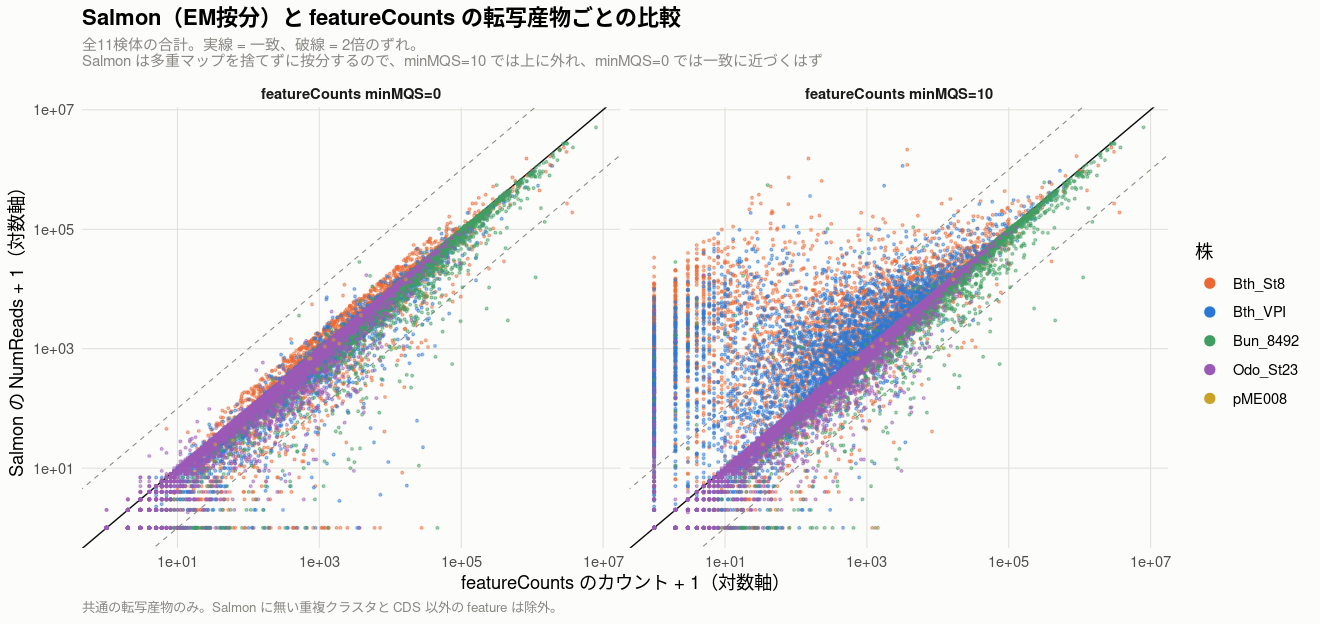

In [174]:
# ── Salmon と featureCounts の散布図 ─────────────────────────────
# 全検体の合計で、転写産物ごとに両者を突き合わせる。
# 対角線から外れるものが「扱いの違いが効いた転写産物」

if (!exists('col_surface')) {
    col_surface = '#fcfcfb'; col_text = '#0b0b0b'
    col_muted   = '#898781'; col_grid = '#e1e0d9'
}

sc = do.call(rbind, lapply(c(0, 10), function(q) {
    data.frame(設定 = paste0('featureCounts minMQS=', q),
               fc = rowSums(cnt[[paste0('q', q)]][com, ]),
               sa = sa_sum, 株 = st_c)
})) %>% filter(!is.na(株))

col_strain = c(Bth_VPI = '#2a78d6', Bth_St8 = '#eb6834', Bun_8492 = '#3f9e5f',
               Odo_St23 = '#9b59b6', pME008 = '#c9a227')

options(repr.plot.width = 11, repr.plot.height = 5.2)

p = ggplot(sc, aes(x = fc + 1, y = sa + 1, colour = 株)) +
    geom_abline(slope = 1, intercept = 0, colour = col_text, linewidth = 0.4) +
    # 2倍のずれの目安線
    geom_abline(slope = 1, intercept = c(-1, 1), linetype = 'dashed',
                colour = col_muted, linewidth = 0.3) +
    geom_point(size = 0.5, alpha = 0.45) +
    scale_x_log10() + scale_y_log10() +
    scale_colour_manual(values = col_strain, name = '株') +
    facet_wrap(~ 設定) +
    guides(colour = guide_legend(override.aes = list(size = 2.5, alpha = 1))) +
    labs(title = 'Salmon（EM按分）と featureCounts の転写産物ごとの比較',
         subtitle = paste0('全11検体の合計。実線 = 一致、破線 = 2倍のずれ。\n',
                           'Salmon は多重マップを捨てずに按分するので、',
                           'minMQS=10 では上に外れ、minMQS=0 では一致に近づくはず'),
         x = 'featureCounts のカウント + 1（対数軸）',
         y = 'Salmon の NumReads + 1（対数軸）',
         caption = '共通の転写産物のみ。Salmon に無い重複クラスタと CDS 以外の feature は除外。') +
    theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major = element_line(colour = col_grid, linewidth = 0.3),
          strip.text = element_text(face = 'bold'),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

suppressWarnings(print(p))

## セル16-6: ゲート2 の2項目を Salmon で独立に再確認する

セル15-6（`VPI:St8` の比）とセル14-4（群集組成）は **featureCounts で出した結論**。
**Salmon は按分の仕組みが違うので、独立な再確認になる。**

**ここで結論が変わるなら、featureCounts 側の MAPQ の扱いが結論を作っていたことになる。**

4つの見方（featureCounts 2通り + Salmon 2設定）を同じ表に並べ、
同じ指標で Wilcoxon 順位和検定をかける。

| 指標 | これまでの結論 | 出どころ |
|---|---|---|
| `Bth計 %` | WT 34.1% vs KO 27.2%（**p = 0.017**） | セル14-4 |
| `Bun %` | WT 57.6% vs KO 63.2%（**p = 0.010**） | セル14-4 |
| **`VPI:St8`** | **群間差なし**（q0 p=0.54 / q10 p=0.31） | **セル15-6（ゲート2 の最重要項目）** |

**※ n=6 vs 5 なので Wilcoxon で到達できる最小 p は 0.0043。**
**※ ここで見たいのは「見方を変えても同じ数字が出るか」という頑健性。**
組成の群間差そのものの解釈（＝ eptA 変異コンソーシアムの定着結果）はステージ5 で扱う。

In [175]:
# ── ゲート2 の2項目を Salmon で独立に再確認する ───────────────────
# セル15-6（VPI:St8 の比）とセル14-4（群集組成）は featureCounts で出した結論。
# Salmon は按分の仕組みが違うので、【独立な再確認】になる。
#   ここで結論が変わるなら、featureCounts 側の MAPQ の扱いが結論を作っていたことになる

# 検体ごとの株別合計（NumReads。按分後のリード数）
sal_share = do.call(rbind, lapply(c('default','meta'), function(md) {
    m  = sal[[md]]$reads
    stx = feat_info$strain[match(rownames(m), feat_info$gene_id)]
    do.call(rbind, lapply(seq_list$name, function(s) {
        v   = m[, s]
        agg = tapply(v, stx, sum)
        data.frame(設定 = ifelse(md == 'default', 'Salmon(VBEM)', 'Salmon(--meta)'),
                   name = s, group = seq_list$group[seq_list$name == s],
                   `Bth計_pct` = round(100 * (agg['Bth_VPI'] + agg['Bth_St8']) / sum(agg), 2),
                   VPI_pct     = round(100 * agg['Bth_VPI']  / sum(agg), 2),
                   St8_pct     = round(100 * agg['Bth_St8']  / sum(agg), 2),
                   Bun_pct     = round(100 * agg['Bun_8492'] / sum(agg), 2),
                   Odo_pct     = round(100 * agg['Odo_St23'] / sum(agg), 2),
                   pME008_pct  = round(100 * agg['pME008']   / sum(agg), 3),
                   `VPI:St8`   = round(agg['Bth_VPI'] / agg['Bth_St8'], 3),
                   row.names = NULL, check.names = FALSE)
    }))
}))

cat("■ Salmon による株別の内訳（上が W群、下が K群）\n")
print(sal_share %>% arrange(設定, factor(group, levels = c('WT','KO')), name) %>%
      as.data.frame(), row.names = FALSE)

# ── 3つの見方を並べて群間差を検定する ─────────────────────────────
# featureCounts 2通り（セル14-4・15-6 の再掲）と Salmon 2設定を同じ表に並べる
cat("\n■ 群間差（Wilcoxon 順位和検定。n=6 vs 5 なので最小 p は 0.0043）\n")

views = list()
for (q in c(0, 10)) {
    m   = cnt[[paste0('q', q)]]
    stx = feat_info$strain[match(rownames(m), feat_info$gene_id)]
    views[[paste0('featureCounts(minMQS=', q, ')')]] =
        sapply(seq_list$name, function(s) tapply(m[, s], stx, sum))
}
for (md in c('default','meta')) {
    m   = sal[[md]]$reads
    stx = feat_info$strain[match(rownames(m), feat_info$gene_id)]
    views[[ifelse(md == 'default', 'Salmon(VBEM)', 'Salmon(--meta)')]] =
        sapply(seq_list$name, function(s) tapply(m[, s], stx, sum))
}

is_wt = seq_list$group[match(colnames(views[[1]]), seq_list$name)] == 'WT'

print(do.call(rbind, lapply(names(views), function(v) {
    a = views[[v]]
    tot = colSums(a)
    mk = function(x) {
        p = suppressWarnings(wilcox.test(x[is_wt], x[!is_wt])$p.value)
        c(WT = round(mean(x[is_wt]), 3), KO = round(mean(x[!is_wt]), 3),
          比 = round(mean(x[is_wt]) / mean(x[!is_wt]), 3), p = round(p, 4))
    }
    rbind(
        data.frame(見方 = v, 指標 = 'Bth計 %',  t(mk(100 * (a['Bth_VPI',] + a['Bth_St8',]) / tot))),
        data.frame(見方 = v, 指標 = 'Bun %',    t(mk(100 * a['Bun_8492',] / tot))),
        data.frame(見方 = v, 指標 = 'Odo %',    t(mk(100 * a['Odo_St23',] / tot))),
        data.frame(見方 = v, 指標 = 'VPI:St8',  t(mk(a['Bth_VPI',] / a['Bth_St8',]))))
})), row.names = FALSE)

■ Salmon による株別の内訳（上が W群、下が K群）
           設定   name group Bth計_pct VPI_pct St8_pct Bun_pct Odo_pct
 Salmon(--meta) eptAW1    WT     39.53   13.04   26.49   57.55    2.91
 Salmon(--meta) eptAW2    WT     44.15   15.90   28.25   52.89    2.95
 Salmon(--meta) eptAW3    WT     42.05   11.60   30.45   54.17    3.77
 Salmon(--meta) eptAW4    WT     42.61   10.31   32.30   55.29    2.09
 Salmon(--meta) eptAW5    WT     45.35   12.07   33.28   51.71    2.93
 Salmon(--meta) eptAW6    WT     38.56   15.04   23.52   57.43    4.00
 Salmon(--meta) eptAK1    KO     30.94    6.95   23.99   66.08    2.97
 Salmon(--meta) eptAK2    KO     28.33    8.69   19.64   68.72    2.94
 Salmon(--meta) eptAK3    KO     32.95    7.69   25.27   64.03    3.00
 Salmon(--meta) eptAK4    KO     36.10   10.95   25.14   60.94    2.95
 Salmon(--meta) eptAK6    KO     31.67   11.63   20.04   65.59    2.73
   Salmon(VBEM) eptAW1    WT     39.54   14.13   25.41   57.55    2.91
   Salmon(VBEM) eptAW2    WT     44.15   16.68   

## セル16-6図: 同じ指標を4つの見方で比べる

**見方を変えても W群と K群の上下関係が同じなら、結論は多重マップの扱いに依存していない。**

点 = 検体、横棒 = 群平均。`VPI:St8` のパネルで**見方ごとに水準（横棒の高さ）がずれても、
W群と K群の相対関係が保たれていれば**、ゲート2 の判定は頑健ということになる。

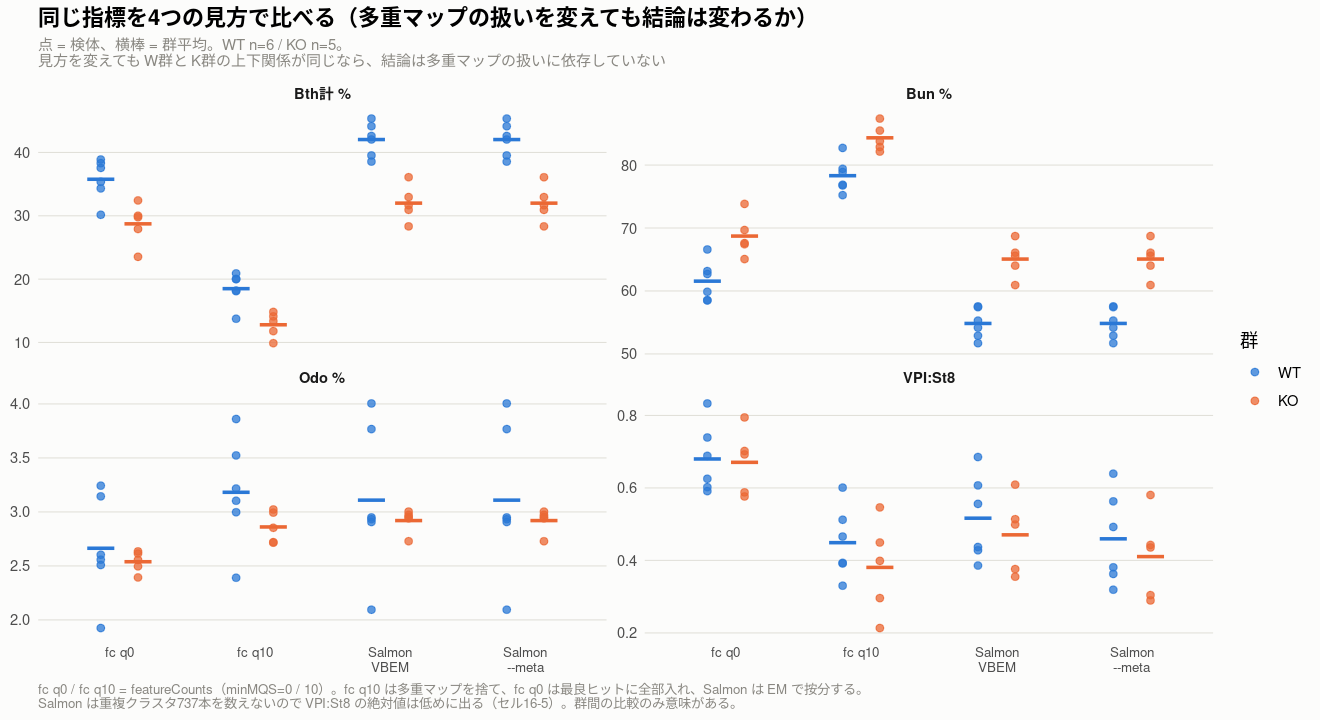

In [176]:
# ── 4つの見方での群間比較を1枚にまとめる ───────────────────────────
# 同じ指標を4つの見方（featureCounts 2通り + Salmon 2設定）で並べ、
# 【見方を変えても群間の関係が変わらないか】を目で確かめる

vw = do.call(rbind, lapply(names(views), function(v) {
    a = views[[v]]; tot = colSums(a)
    rbind(data.frame(見方 = v, 指標 = 'Bth計 %', name = colnames(a),
                     値 = 100 * (a['Bth_VPI',] + a['Bth_St8',]) / tot),
          data.frame(見方 = v, 指標 = 'Bun %',   name = colnames(a),
                     値 = 100 * a['Bun_8492',] / tot),
          data.frame(見方 = v, 指標 = 'Odo %',   name = colnames(a),
                     値 = 100 * a['Odo_St23',] / tot),
          data.frame(見方 = v, 指標 = 'VPI:St8', name = colnames(a),
                     値 = a['Bth_VPI',] / a['Bth_St8',]))
})) %>%
    mutate(group = seq_list$group[match(name, seq_list$name)],
           # 軸が長くなりすぎるので短縮名にする（対応は caption に書く）
           見方  = factor(見方, levels = names(views),
                          labels = c('fc q0', 'fc q10', 'Salmon\nVBEM', 'Salmon\n--meta')),
           指標  = factor(指標, levels = c('Bth計 %','Bun %','Odo %','VPI:St8')),
           group = factor(group, levels = c('WT','KO')))

options(repr.plot.width = 11, repr.plot.height = 6)

p = ggplot(vw, aes(x = 見方, y = 値, colour = group)) +
    geom_point(position = position_dodge(width = 0.55), size = 1.8, alpha = 0.75) +
    stat_summary(fun = mean, geom = 'crossbar', width = 0.4, linewidth = 0.4,
                 position = position_dodge(width = 0.55), show.legend = FALSE) +
    facet_wrap(~ 指標, scales = 'free_y', nrow = 2) +
    scale_colour_manual(values = c(WT = '#2a78d6', KO = '#eb6834'), name = '群') +
    labs(title = '同じ指標を4つの見方で比べる（多重マップの扱いを変えても結論は変わるか）',
         subtitle = paste0('点 = 検体、横棒 = 群平均。WT n=6 / KO n=5。\n',
                           '見方を変えても W群と K群の上下関係が同じなら、',
                           '結論は多重マップの扱いに依存していない'),
         x = NULL, y = NULL,
         caption = paste0('fc q0 / fc q10 = featureCounts（minMQS=0 / 10）。',
                          'fc q10 は多重マップを捨て、fc q0 は最良ヒットに全部入れ、',
                          'Salmon は EM で按分する。\n',
                          'Salmon は重複クラスタ737本を数えないので VPI:St8 の絶対値は',
                          '低めに出る（セル16-5）。群間の比較のみ意味がある。')) +
    theme_minimal(base_size = 11) +
    theme(panel.background = element_rect(fill = col_surface, colour = NA),
          plot.background  = element_rect(fill = col_surface, colour = NA),
          panel.grid.minor = element_blank(),
          panel.grid.major.x = element_blank(),
          panel.grid.major.y = element_line(colour = col_grid, linewidth = 0.3),
          axis.text.x = element_text(size = 8),
          strip.text = element_text(face = 'bold'),
          plot.title = element_text(face = 'bold'),
          plot.subtitle = element_text(colour = col_muted, size = 9),
          plot.caption  = element_text(colour = col_muted, size = 8, hjust = 0))

suppressWarnings(print(p))

## セル16-7: 遺伝子型マーカーを Salmon で確認する（ゲート2 の最重要項目）

セル15-10 で featureCounts により確認した eptA 欠失の判別を、**Salmon でもやる。**

**分割 feature（`_deleted` / `_retained` / `_3p` / `_5p`）は index に入っている**ので、
そのまま確認できる。

**`pME008_CAST_spacer` は index に入っていない**（CDS fasta に無いため）。
ただしこれは**既に判別子として使えないと分かっている**（深度1.7、WT/KO = 0.8、p = 0.85）ので
問題にならない。

**TPM で見る。** `_deleted` と `_retained` は長さが違う（例: `BT_RS09185` は 504 bp と 1,200 bp）ので、
**生のリード数では比べられない。**

In [177]:
# ── 遺伝子型マーカーを Salmon で確認する（ゲート2 の最重要項目）────────
# セル15-10 で featureCounts で確認した eptA 欠失の判別を、Salmon でもやる。
# ★ 分割 feature（_deleted / _retained / _3p / _5p）は index に入っている。
#   pME008_CAST_spacer は入っていない（CDS fasta に無いため）が、
#   これは既に判別子として使えないと分かっているので問題にならない
geno = c('BT_RS09185_deleted','BT_RS09185_retained',
         'CE91St8_20540_deleted',
         'NQ510_RS14730_deleted','NQ510_RS14730_retained',
         'CE91St23_40970_3p','CE91St23_40970_5p')

cat(sprintf("index にあるマーカー: %d / %d 件\n\n",
            sum(geno %in% rownames(sal$default$reads)), length(geno)))

# TPM で見る（長さが違うので生のリード数では比べられない）
print(do.call(rbind, lapply(geno[geno %in% rownames(sal$default$tpm)], function(g) {
    v = sal$default$tpm[g, seq_list$name]
    w = v[seq_list$group == 'WT']; k = v[seq_list$group == 'KO']
    data.frame(マーカー = g,
               WT_TPM中央値 = round(median(w), 2),
               KO_TPM中央値 = round(median(k), 2),
               WT_範囲 = sprintf("%.1f〜%.1f", min(w), max(w)),
               KO_範囲 = sprintf("%.1f〜%.1f", min(k), max(k)),
               倍率 = ifelse(median(k) > 0, round(median(w) / median(k), 1), Inf),
               p = round(suppressWarnings(wilcox.test(w, k)$p.value), 4),
               row.names = NULL, check.names = FALSE)
})), row.names = FALSE)

index にあるマーカー: 7 / 7 件

               マーカー WT_TPM中央値 KO_TPM中央値     WT_範囲    KO_範囲 倍率
     BT_RS09185_deleted        10.34         0.00   8.4〜12.1   0.0〜0.0  Inf
    BT_RS09185_retained        11.20         5.11   8.3〜12.6   1.5〜9.2  2.2
  CE91St8_20540_deleted        23.09         0.00  14.4〜35.6   0.0〜0.0  Inf
  NQ510_RS14730_deleted        96.72         0.00 82.2〜622.7   0.0〜0.0  Inf
 NQ510_RS14730_retained        36.21        55.85 28.6〜172.3 10.1〜87.9  0.6
      CE91St23_40970_3p         2.29         0.00    1.4〜3.4   0.0〜0.0  Inf
      CE91St23_40970_5p         4.37         5.77    2.2〜6.1   3.9〜9.2  0.8
      p
 0.0055
 0.0087
 0.0075
 0.0055
 1.0000
 0.0055
 0.1255


## セル16-8: Salmon の結果を保存

セル15-12 と同じ方針。**行列は scratch 側、小さい表は project 側（git 管理）。**

| 出力先 | 内容 |
|---|---|
| `counts/salmon_{default,meta}_{reads,tpm,efflen}.csv`（scratch） | 行列6本 |
| `counts/salmon_all.rds`（scratch） | 上をまとめた list |
| `refqc/salmon_mapping.tsv`（project） | 検体ごとのマッピング内訳 |
| `refqc/salmon_strain_share.tsv`（project） | 株別の内訳（2設定） |
| `refqc/salmon_vs_featurecounts.tsv`（project） | 一致度 |

### ★ ステージ5 では `quant.sf` から tximport で読み直す

ここで保存する `NumReads` 行列は **featureCounts との比較用**。
DESeq2 に渡すときは `EffectiveLength` から長さオフセットを作る必要がある。

In [178]:
# ── Salmon の結果を保存する ─────────────────────────────────────
# セル15-12 と同じ方針。行列は scratch 側、小さい表は project 側（git 管理）。
# ★ ステージ5 で DESeq2 に渡すときは quant.sf から tximport で読み直す。
#   EffectiveLength から長さオフセットを作る必要があるため、
#   ここで保存する NumReads 行列は【featureCounts との比較用】と割り切る
path_out = file.path(path, 'counts')
if(!dir.exists(path_out)) dir.create(path_out, recursive = TRUE)

for (md in c('default','meta')) {
    for (nm in c('reads','tpm','efflen')) {
        f = file.path(path_out, sprintf('salmon_%s_%s.csv', md, nm))
        write.csv(sal[[md]][[nm]], f)
        cat(sprintf("%-46s %5.1f MB\n", basename(f), file.size(f) / 1e6))
    }
}
saveRDS(sal, file.path(path_out, 'salmon_all.rds'))

# 検体ごとのサマリは project 側へ
write.table(sal_map,   file.path(path_project, 'refqc/salmon_mapping.tsv'),
            sep = "\t", quote = FALSE, row.names = FALSE)
write.table(sal_share, file.path(path_project, 'refqc/salmon_strain_share.tsv'),
            sep = "\t", quote = FALSE, row.names = FALSE)
write.table(sal_fc,    file.path(path_project, 'refqc/salmon_vs_featurecounts.tsv'),
            sep = "\t", quote = FALSE, row.names = FALSE)

cat(sprintf("\nproject 側: refqc/salmon_mapping.tsv / salmon_strain_share.tsv / salmon_vs_featurecounts.tsv\n"))
cat(sprintf("scratch 側: counts/salmon_*.csv（6本）/ counts/salmon_all.rds\n"))

salmon_default_reads.csv                         1.1 MB
salmon_default_tpm.csv                           1.9 MB
salmon_default_efflen.csv                        1.8 MB
salmon_meta_reads.csv                            1.1 MB
salmon_meta_tpm.csv                              1.9 MB
salmon_meta_efflen.csv                           1.8 MB

project 側: refqc/salmon_mapping.tsv / salmon_strain_share.tsv / salmon_vs_featurecounts.tsv
scratch 側: counts/salmon_*.csv（6本）/ counts/salmon_all.rds


### 考察: Salmon の結果（セル16-2〜16-8 の結果）

## 結論

1. **3つの見方（捨てる / 最良ヒット / EM按分）は想定どおりの関係にあり、Salmon は壊れていない。**
2. **★ ゲート2 の判定は多重マップの扱いに依存しない。** `VPI:St8` の群間差なしは4つの見方すべてで同じ（**p = 0.54〜0.79**）。
3. **★ 遺伝子型の判別は Salmon の方が鋭い。** 4つの欠失マーカーが **K群で全検体 TPM = 0.00（完全分離）**。
4. **セル11 で懸念した「rRNA除去効率の群間差」は否定された**（decoy行き率 p = 0.66）。
5. **★ Salmon の `VPI:St8` 絶対値は使ってはいけない。** 重複クラスタ除外が `Bth_VPI` を非対称に削るため。

## 1. 対象の突き合わせ — 1件残らず説明がついた

```
featureCounts 18,245 / Salmon 17,182 / 共通 17,181
featureCounts にだけある 1,064 件 = CDS以外 327 + 重複クラスタ 737  （そのほか 0）
Salmon にだけある          1 件
```

**`Salmon にだけある 1 件` = `CE91St8_20540_retained`。**
セル10 で**カウント用GTF から意図的に除いた 15 bp の feature**（隣の `CE91St8_20530` と
14 bp 重なるため）。CDS fasta には残っているので index には入っているが、
**15 bp < k=31 なので Salmon も 1 リードも割り当てていない（全検体合計 0）。** 実害なし。

## 2. 3つの見方の関係 — 想定どおり

### 転写産物ごとの比（セル16-5、全検体合計100リード以上の 13,911 本）

| 株 | 対象数 | **Salmon / fc(minMQS=10) の中央値** | 比2倍超 | 比0.5未満 |
|---|---|---|---|---|
| **Bth_St8** | 4,073 | **2.161** | 2,090 | 227 |
| **Bth_VPI** | 3,430 | **1.708** | 1,596 | 161 |
| Bun_8492 | 3,473 | 0.835 | 33 | 446 |
| Odo_St23 | 2,925 | 0.855 | 13 | 306 |
| pME008 | 10 | 0.890 | 0 | 2 |

**近縁2株でだけ Salmon が 1.7〜2.2倍多く、`Bun_8492` と `Odo_St23` では 0.84〜0.86。**
→ **EM が拾っているのは「MAPQ で捨てられていた Bth 2株の共通領域のリード」だけ**で、
他の2株では何も起きていない。**狙いどおりの挙動。**

セル16-5図でも、`minMQS=0` のパネルは全株が対角線に乗り、
`minMQS=10` のパネルでは**Bth 2株（青・橙）だけが上に外れる**（`fc = 0` の縦の列を含む）。

### 検体ごとの相関（セル16-4）

| 相手 | 相関(log2) | 順位相関 | Salmon / fc |
|---|---|---|---|
| `minMQS=0` | **0.963〜0.972** | 0.967〜0.974 | 0.74〜0.81 |
| `minMQS=10` | **0.734〜0.803** | 0.719〜0.776 | 0.87〜1.06 |

**`minMQS=0` とはよく一致し、`minMQS=10` とは一致しない。**
一致しない理由は上の表のとおり **Bth 2株が MAPQ で削られているから**であって、
Salmon 側の問題ではない。**むしろ `minMQS=10` が何をしているかの定量的な記述になっている。**

### MAPQ で消えた遺伝子を Salmon は拾えるか

**731 件**（`Bth_St8` 458 / `Bth_VPI` 216 / `Odo_St23` 50 / `Bun_8492` 7）で
カウントが復活した。セル15-10-2 で見た「MAPQ フィルタで消えた 1,170 遺伝子」の**6割**にあたる。

**ただし合計 0.79 M リード = 全体の 0.30% しかない。**
→ **遺伝子の「数」としては大きいが、「量」としては小さい。**
DE で拾えるかは別問題（発現量が低いので検出力が無い）。

## 3. ★ Salmon が捨てている分（重複クラスタ）は `Bth_VPI` に偏っている

**これが一番注意すべき点。**

| 設定 | 除外737本の合計 | 全体比 |
|---|---|---|
| `minMQS=0` | **7.95 M** | **1.51%** |
| `minMQS=10` | 0.03 M | 0.01% |

除外された737本の株別内訳: **`Bth_VPI` 504 / `Odo_St23` 155 / `Bth_St8` 47 / `Bun_8492` 31。**

`minMQS=0` のカウントで見ると、

| 株 | 除外分 | その株の全体に対する割合 |
|---|---|---|
| **Bth_VPI** | **6.99 M** | **10.3%** |
| Bth_St8 | 0.19 M | 0.2% |

→ **`VPI:St8` は除外だけで 0.659 → 0.593 に下がる（−10%）。**

**Salmon の `VPI:St8`（VBEM 0.517）が featureCounts `minMQS=0`（0.680）より低いのは、
EM の按分だけでなく、この非対称な除外も効いている。**

**★ したがって Salmon の `VPI:St8` の絶対値を根拠に議論してはいけない。**
**群間比較（全検体に同じ偏りがかかる）だけが意味を持つ。**
CLAUDE.md §リファレンス の「株ごとの比較で『片方の株だけ発現0』が出たら
まず `duplicate_clusters.tsv` を確認する」が、実際に効いている例。

## 4. ★★ ゲート2 — 4つの見方すべてで同じ結論

| 見方 | `VPI:St8` WT | KO | 比 | **p** |
|---|---|---|---|---|
| featureCounts `minMQS=0` | 0.680 | 0.671 | 1.014 | 0.7922 |
| featureCounts `minMQS=10` | 0.449 | 0.381 | 1.179 | 0.5368 |
| **Salmon（VBEM）** | 0.517 | 0.471 | 1.098 | **0.5368** |
| **Salmon（`--meta`）** | 0.460 | 0.411 | 1.119 | **0.5368** |

**水準（絶対値）は 0.38〜0.68 と見方によって大きく動くが、群間差はどれも出ない。**

**`--meta` のずれは系統的だった**（セル16 の考察で確認すると決めた点）。
VBEM → `--meta` で WT 0.517→0.460、KO 0.471→0.411 と**両群が同じだけ下がり、
p は 0.5368 で完全に一致する。** → **按分アルゴリズムの選択はゲート2 の判定を変えない。**

→ **ゲート2 の「`VPI:St8` に群間差なし」は、多重マップの扱いに依存しない頑健な結論。**

### 群集組成 — Salmon では群間差がより鋭くなる

| 見方 | `Bth計 %` WT / KO | p | `Bun %` WT / KO | p |
|---|---|---|---|---|
| fc `minMQS=0` | 35.8 / 28.7 | 0.0087 | 61.6 / 68.7 | 0.0087 |
| fc `minMQS=10` | 18.5 / 12.8 | 0.0173 | 78.3 / 84.3 | 0.0087 |
| **Salmon（VBEM）** | **42.0 / 32.0** | **0.0043** | **54.8 / 65.1** | **0.0043** |
| Salmon（`--meta`） | 42.0 / 32.0 | 0.0043 | 54.8 / 65.1 | 0.0043 |

**Salmon では p = 0.0043 で、n=6 vs 5 で到達できる最小値（完全分離）。**
`Odo %` は全ての見方で有意差なし（Salmon p = 0.93）。

**※ ここで確認できたのは「見方を変えても同じ数字が出る」という頑健性。**
組成差そのものは **eptA 変異コンソーシアムの定着結果**として扱う（CLAUDE.md §1）。

## 5. ★ 遺伝子型マーカー — Salmon の方が鋭い（完全分離）

| マーカー | WT 中央値 TPM | KO 中央値 TPM | KO の範囲 | p |
|---|---|---|---|---|
| `BT_RS09185_deleted` | 10.34 | **0.00** | **0.0〜0.0** | 0.0055 |
| `CE91St8_20540_deleted` | 23.09 | **0.00** | **0.0〜0.0** | 0.0075 |
| `NQ510_RS14730_deleted` | 96.72 | **0.00** | **0.0〜0.0** | 0.0055 |
| `CE91St23_40970_3p` | 2.29 | **0.00** | **0.0〜0.0** | 0.0055 |
| `BT_RS09185_retained` | 11.20 | 5.11 | 1.5〜9.2 | 0.0087 |
| `NQ510_RS14730_retained` | 36.21 | 55.85 | 10.1〜87.9 | 1.0000 |
| `CE91St23_40970_5p` | 4.37 | 5.77 | 3.9〜9.2 | 0.1255 |

**4つの欠失マーカーが K群の全5検体で TPM = 0.00。**
featureCounts では 95〜4,191倍の分離（＝K群にも少量残っていた）だったが、
**Salmon の selective alignment では完全に 0 になる。**

理由: featureCounts は bowtie2 がソフトクリップなどで無理に当てたリードも数えるが、
**Salmon は一定のスコア閾値を満たさないマッピングを採用しない。**
→ **遺伝子型の判別という目的には Salmon の方が適している。**

**`_retained` / `_5p` 側は両群にある**（`NQ510_RS14730_retained` p = 1.0、
`CE91St23_40970_5p` p = 0.13）。設計どおり。

**`BT_RS09185_retained` だけ K群で 2.2倍低い（p = 0.0087）。**
`BT_RS09185` の欠失は CDS の 131–634 bp（44–212 コドン）なので、
**欠失が転写産物の安定性やプロモーター近傍に影響している**可能性がある。
ただし**欠失そのものが作る人工的な差**（転写産物の長さ・安定性が変わる）と
**本当の発現制御の差**を区別できないので、ステージ5 では `_retained` を DE 対象から外す
（遺伝子型マーカーは既に除外対象）。

## 6. セル11 で懸念した「rRNA除去効率の群間差」は否定された

セル11 の考察で、サブサンプルの decoy行き率が eptAW1 54.8% / eptAK1 64.0% と
9ポイント違ったことから「**rRNA除去の効率差で mRNA の実効深度が群間でずれている可能性**」を
懸念し、**ステージ4で全検体で確認する**と書いていた。**ここで確認した。**

| 指標 | WT（n=6） | KO（n=5） | Wilcoxon p |
|---|---|---|---|
| **decoy行き率**（≒ rRNA + 遺伝子間 + 宿主） | **54.90%**（50.9〜60.8） | **56.91%**（52.6〜63.4） | **0.6623** |
| CDSマップ率 | 42.97% | 40.89% | 0.5368 |

**群間差は無い。** eptAW1 と eptAK1 のずれは**検体差であって群差ではなかった。**
範囲が 50.9〜63.4% と広いのは事実なので、**size factor で吸収する前提は変わらない。**

**※ `eptAW4` は整合率 95.66%・ISR率 95.69% でどちらも最低値。**
セル15-8（RLE の IQR 1.32）とセル15-9（PCA の PC2/PC3）に続き、
**3つ目の独立な指標で外れ値として浮かぶ。** 除外はしないが、
**ステージ5 で `eptAW4` を除いた感度解析を必ず行う**（CLAUDE.md §8）。

## ステージ5 への申し送り

| 項目 | 内容 |
|---|---|
| **tximport を使う** | `counts/salmon_*.csv` は**比較用**。DESeq2 には `quant.sf` から tximport で読み直し、`EffectiveLength` の長さオフセットを渡す |
| **Salmon の `VPI:St8` 絶対値は使わない** | 重複クラスタ除外が `Bth_VPI` を 10.3% 削る（上記3） |
| **主解析は featureCounts `minMQS=10`** | 保守的。**Salmon は感度解析**（EM が拾う 731 遺伝子が結論を変えないかの確認） |
| **`--meta` 版は不要** | 群間比較では VBEM と完全に同じ p を与える（上記4）。保存はしてあるので必要なら使える |
| **`eptAW4` の感度解析** | 3つ目の独立指標でも外れ値 |
| **遺伝子型マーカーを DE から外す** | `_deleted` / `_3p` に加え、**`BT_RS09185_retained` も**（群間差が出るが、欠失が作る人工的な差と区別できない） |

---
# ステージ3 まとめ

## セル17: 通し表・ゲート2 のチェックリスト・出力物

ステージ3 でやったこと（fastp → Bowtie2 → featureCounts → Salmon）を、
**次の人（ステージ5 の担当・共同研究者・claude.ai）が読んで引き継げる形**にまとめる。

| 出すもの | 中身 |
|---|---|
| **通し表** | 生データ → fastp → bowtie2 → featureCounts → Salmon を**検体ごとに1行** |
| **レンジ表** | 11検体の最小・最大と群間差（Wilcoxon） |
| **ゲート2 のチェックリスト** | **CLAUDE.md §7 ステージ4 の項目ごとに判定** |
| **出力物の一覧** | ファイルの実在確認つき |

### ★ 実施していない項目は「未実施」と書く

**通ったことにしない。** CLAUDE.md に挙がっている項目のうち
**ステージ3 のデータ（RNA-seq）では原理的にできないもの**があるので、
その理由とともに明示する。

### このセルは新しい計算をしない

前のセルで作ったオブジェクトを集めるだけ。
**足りないオブジェクトがあれば、どのセルを実行すればよいかを表示して止まる。**

In [179]:
# ── ステージ3 の通し表 ──────────────────────────────────────────
# 生データ → fastp → bowtie2 → featureCounts → Salmon を検体ごとに1行で並べる。
# ここまでの各セルの数値を集めるだけで、新しい計算はしない。
#
# ★ 前のセルで作ったオブジェクトを使う。足りなければどのセルを実行すべきか表示して止まる
need = c(fastp_qc = 'セル9-2', map_sum = 'セル14-2', cnt = 'セル15-2',
         feat_info = 'セル15-4', bio = 'セル15-4', strain_cds = 'セル15-5',
         sf_qc = 'セル15-8-2', sal_map = 'セル16-2', sal = 'セル16-3',
         sal_share = 'セル16-6')
miss = names(need)[!sapply(names(need), exists)]
if (length(miss) > 0) stop(paste0('先に実行が必要: ',
    paste(sprintf('%s（%s）', miss, need[miss]), collapse = ' / ')))

stage3 = seq_list %>%
    dplyr::select(name, group) %>%
    left_join(fastp_qc %>% dplyr::select(name, 生Mpairs = before_Mp,
                                         trim後Mpairs = after_Mp, 残存率 = keep_pct),
              by = 'name') %>%
    left_join(map_sum %>% dplyr::select(name, アライン率 = 全体アライン率,
                                        多重 = `concord多_pct`),
              by = 'name') %>%
    left_join(bio %>% filter(設定 == 'minMQS=10') %>%
                  dplyr::select(name, rRNA_pct, CDS_pct, CDS_M),
              by = 'name') %>%
    left_join(sf_qc %>% filter(設定 == 'minMQS=10') %>%
                  dplyr::select(name, size_factor, RLE_IQR),
              by = 'name') %>%
    left_join(sal_map %>% dplyr::select(name, Salmon_CDS率 = CDSマップ率,
                                        decoy行き率),
              by = 'name') %>%
    arrange(factor(group, levels = c('WT','KO')), name)

ow = getOption('width'); options(width = 150)
cat("■ ステージ3 通し表（rRNA% / CDS% / size factor / RLE は minMQS=10）\n")
print(as.data.frame(stage3), row.names = FALSE)

# ── 確定した数値のレンジ ────────────────────────────────────────
cat("\n■ 11検体のレンジ（群間差は Wilcoxon 順位和検定。n=6 vs 5 の最小 p は 0.0043）\n")
is_wt = stage3$group == 'WT'
print(do.call(rbind, lapply(
    c('残存率','アライン率','多重','rRNA_pct','CDS_pct','Salmon_CDS率',
      'decoy行き率','size_factor','RLE_IQR'),
    function(v) {
        x = stage3[[v]]
        data.frame(項目 = v,
                   最小 = round(min(x), 2), 最大 = round(max(x), 2),
                   WT平均 = round(mean(x[is_wt]), 2),
                   KO平均 = round(mean(x[!is_wt]), 2),
                   p = round(suppressWarnings(wilcox.test(x[is_wt], x[!is_wt])$p.value), 4))
    })), row.names = FALSE)
options(width = ow)

■ ステージ3 通し表（rRNA% / CDS% / size factor / RLE は minMQS=10）
   name group 生Mpairs trim後Mpairs 残存率 アライン率  多重 rRNA_pct CDS_pct CDS_M size_factor RLE_IQR Salmon_CDS率 decoy行き率
 eptAW1    WT     56.0         55.9  99.78      98.92 36.31     0.23   71.94  26.0       0.930   0.486        43.72       54.41
 eptAW2    WT     51.9         51.7  99.56      98.96 39.79     0.29   70.22  22.7       0.835   0.585        42.56       55.66
 eptAW3    WT     43.6         43.5  99.79      98.88 38.68     0.22   72.90  19.6       0.742   0.775        42.63       55.26
 eptAW4    WT     52.1         52.0  99.76      98.60 41.91     0.26   73.47  22.7       1.045   1.373        46.10       50.93
 eptAW5    WT     65.3         65.2  99.79      98.90 39.79     0.14   70.91  28.8       1.134   0.530        45.50       52.34
 eptAW6    WT     44.0         43.9  99.74      98.84 33.23     0.16   58.21  16.7       0.651   0.686        37.28       60.80
 eptAK1    KO     59.3         59.2  99.80      98.73 30.51   

In [180]:
# ── ゲート2 のチェックリスト ────────────────────────────────────
# CLAUDE.md §7 ステージ4 に挙がっている項目を1つずつ判定する。
# ★ 実施していない項目は「未実施」と書く。通ったことにしない
gate2 = rbind(
 data.frame(項目='eptA 欠失区間のカバレッジ（VPI / St8 / Bun）', 出どころ='セル14-5〜14-6、セル16-7',
   結果='W群=あり / K群=ゼロ。深度比 95〜4,191倍（p=0.0043〜0.0078）。Salmon TPM では K群 全5検体 0.00',
   判定='通過'),
 data.frame(項目='eptA 残存区間のカバレッジ', 出どころ='セル14-6、セル16-7',
   結果='両群にあり。欠失境界を補正した比は VPI 1.96〜2.38 / Bun 0.66〜1.90',
   判定='通過'),
 data.frame(項目='Odo 染色体の CAST 挿入ジャンクション', 出どころ='セル14-6、セル16-7',
   結果='_3p が W/K = 218倍（p=0.0043）。_5p は両群にあり。挿入で転写が止まっている',
   判定='通過'),
 data.frame(項目='pME008 スペーサー領域のカバレッジ', 出どころ='セル14-7',
   結果='深度 1.7、W/K = 0.8倍、p = 0.85。RNA-seq では判別子にならない',
   判定='★ 使用不可（eptA _deleted で代替）'),
 data.frame(項目='トランスポゾン–染色体ジャンクションの全ゲノム検索', 出どころ='—',
   結果='RNA-seq では転写されない挿入点を検出できない。DNA（WGS）が必要',
   判定='★ 未実施（ステージ3 の守備範囲外）'),
 data.frame(項目='tetX1 が両群にあること', 出どころ='セル16-3（quant.sf）',
   結果='全11検体で検出（768〜3,572 リード / TPM 17.1〜46.0）。両群にあり判別には使えない',
   判定='通過（判別子としては使わない）'),
 data.frame(項目='pME008 由来リードの割合（群ごと）', 出どころ='セル16-6',
   結果='全検体 0.006〜0.016%。size factor に影響する量ではない',
   判定='通過'),
 data.frame(項目='株別CDSリード数・シェア・unique率／除外基準', 出どころ='セル15-5',
   結果='4株とも基準（20万リードかつ0.1%）の3〜60倍の余裕',
   判定='通過'),
 data.frame(項目='Bth_VPI : Bth_St8 の存在比（群ごと）', 出どころ='セル15-6、セル16-6',
   結果='4つの見方すべてで群間差なし（p = 0.54〜0.79）。ただし検出力は相対差40〜50%まで',
   判定='通過（検出力の制約つき）'),
 data.frame(項目='サンプル別 mapping率 / rRNA% / multimap率', 出どころ='セル14-2、セル15-4、セル16-2',
   結果='下の通し表のとおり。rRNA% と decoy行き率に群間差なし',
   判定='通過'))

# 列が多く data.frame だと折り返すので、項目ごとに段落で出す
cat("■ ゲート2 のチェックリスト（CLAUDE.md §7 ステージ4）\n")
for (i in 1:nrow(gate2)) {
    cat(sprintf("\n[%s] %s\n", gate2$判定[i], gate2$項目[i]))
    cat(paste0("    ", strwrap(gate2$結果[i], width = 86), collapse = "\n"), "\n")
    cat(sprintf("    → %s\n", gate2$出どころ[i]))
}

cat(sprintf("\n通過 %d / 使用不可 1 / 未実施 1（全 %d 項目）\n",
            sum(grepl('^通過', gate2$判定)), nrow(gate2)))

# ── 出力物の確認 ───────────────────────────────────────────────
cat("\n■ ステージ3 の出力物\n")
outs = rbind(
  data.frame(場所='project', ファイル='logs/runtime.tsv',                  説明='全ステップの所要時間（5種 × 11検体）'),
  data.frame(場所='project', ファイル='refqc/eptA_cds_coordinates.tsv',    説明='eptA 変異の CDS 内座標'),
  data.frame(場所='project', ファイル='refqc/stage3_bio.csv',              説明='biotype 別の内訳'),
  data.frame(場所='project', ファイル='refqc/stage3_strain_cds.csv',       説明='株ごとの CDS カウントとシェア'),
  data.frame(場所='project', ファイル='refqc/stage3_vpi_st8.csv',          説明='Bth_VPI : Bth_St8 の比'),
  data.frame(場所='project', ファイル='refqc/stage3_assign_sum.csv',       説明='featureCounts の割当内訳'),
  data.frame(場所='project', ファイル='refqc/salmon_mapping.tsv',          説明='Salmon のマッピング内訳'),
  data.frame(場所='project', ファイル='refqc/salmon_strain_share.tsv',     説明='Salmon の株別シェア（2設定）'),
  data.frame(場所='project', ファイル='refqc/salmon_vs_featurecounts.tsv', 説明='両者の一致度'),
  data.frame(場所='scratch', ファイル='counts/featureCounts_q10.csv',      説明='カウント行列（保守的）★ステージ5 主解析'),
  data.frame(場所='scratch', ファイル='counts/featureCounts_q0.csv',       説明='カウント行列（最良ヒット）'),
  data.frame(場所='scratch', ファイル='counts/feature_info.csv',           説明='feature の属性（株 / biotype / product）'),
  data.frame(場所='scratch', ファイル='counts/salmon_default_reads.csv',   説明='Salmon NumReads（VBEM）'),
  data.frame(場所='scratch', ファイル='counts/salmon_all.rds',             説明='Salmon 全行列（2設定 × 3種）'),
  data.frame(場所='scratch', ファイル='bam',                               説明='bowtie2 の BAM 11本 + index'),
  data.frame(場所='scratch', ファイル='salmon_quant',                      説明='quant.sf ★ステージ5 で tximport が読む'))
outs$実在 = ifelse(file.exists(file.path(ifelse(outs$場所 == 'project', path_project, path),
                                          outs$ファイル)), 'OK', '!! 無い')
ow = getOption('width'); options(width = 120)
print(outs, row.names = FALSE)
options(width = ow)

■ ゲート2 のチェックリスト（CLAUDE.md §7 ステージ4）

[通過] eptA 欠失区間のカバレッジ（VPI / St8 / Bun）
    W群=あり / K群=ゼロ。深度比 95〜4,191倍（p=0.0043〜0.0078）。Salmon TPM では K群
    全5検体 0.00 
    → セル14-5〜14-6、セル16-7

[通過] eptA 残存区間のカバレッジ
    両群にあり。欠失境界を補正した比は VPI 1.96〜2.38 / Bun 0.66〜1.90 
    → セル14-6、セル16-7

[通過] Odo 染色体の CAST 挿入ジャンクション
    _3p が W/K = 218倍（p=0.0043）。_5p は両群にあり。挿入で転写が止まっている 
    → セル14-6、セル16-7

[★ 使用不可（eptA _deleted で代替）] pME008 スペーサー領域のカバレッジ
    深度 1.7、W/K = 0.8倍、p = 0.85。RNA-seq では判別子にならない 
    → セル14-7

[★ 未実施（ステージ3 の守備範囲外）] トランスポゾン–染色体ジャンクションの全ゲノム検索
    RNA-seq では転写されない挿入点を検出できない。DNA（WGS）が必要 
    → —

[通過（判別子としては使わない）] tetX1 が両群にあること
    全11検体で検出（768〜3,572 リード / TPM 17.1〜46.0）。両群にあり判別には使えない 
    → セル16-3（quant.sf）

[通過] pME008 由来リードの割合（群ごと）
    全検体 0.006〜0.016%。size factor に影響する量ではない 
    → セル16-6

[通過] 株別CDSリード数・シェア・unique率／除外基準
    4株とも基準（20万リードかつ0.1%）の3〜60倍の余裕 
    → セル15-5

[通過（検出力の制約つき）] Bth_VPI : Bth_St8 の存在比（群ごと）
    4つの見方すべてで群間差なし（p = 0.54〜0.79）。ただし検出力は相対差40〜50%まで 
    → セル15-6、セル16-6

[通

### ステージ3 まとめ（セル17 の結果）= 引き継ぎ文書

## 結論: **ステージ3 完了。ゲート2 通過。ステージ5（DESeq2）に進んでよい。**

**ゲート2 は 10項目中 8項目 通過、1項目 使用不可（代替あり）、1項目 未実施（原理的にできない）。**

---

## 1. やったこと

```
生データ（Azenta, 150bp PE, DNBSEQ）
  → FastQC / MultiQC（セル4〜7-4）
  → fastp 1.4.0（セル9〜9-5）           アダプター明示、--length_required 50
  → Bowtie2 2.5.5（セル12・14）          -X 1000、--rg、74 contig リファレンス
  → samtools 1.24（セル13・14-8）
  → featureCounts 2.1.1（セル15）        -t transcript -g gene_id -s 2、minMQS 2通り
  → Salmon 2.8.0（セル16）               -l ISR、decoy-aware、VBEM
```

**所要時間（`logs/runtime.tsv`）**: bowtie2+sort 223分 / featureCounts 36分 / **Salmon 11分**。

| 検体 | W群 6（W1–W6） / K群 5（K1–K4, K6。**K5 は欠番**） |
|---|---|
| リファレンス | 4株12 contig + pME008 + マウス61 contig = **74 contig** |
| 株 | `Bth_VPI` / `Bth_St8` / `Bun_8492` / `Odo_St23`（St23+St24 の合算単位） |

## 2. 確定した数値（11検体のレンジ）

| 項目 | 最小 | 最大 | WT平均 | KO平均 | p |
|---|---|---|---|---|---|
| fastp 残存率 | 99.35 | 99.82 | 99.74 | 99.69 | 0.52 |
| bowtie2 アライン率 | 98.25 | 98.96 | 98.85 | 98.53 | **0.017** |
| concordant >1（多重） | 27.23 | 41.91 | 38.28 | 31.46 | **0.014** |
| rRNA %（minMQS=10） | 0.10 | 0.29 | 0.22 | 0.13 | **0.022** |
| CDS %（minMQS=10） | 58.21 | 73.47 | 69.61 | 66.53 | 0.66 |
| Salmon CDS マップ率 | 34.54 | 46.10 | 42.97 | 40.89 | 0.54 |
| decoy 行き率 | 50.93 | 63.43 | 54.90 | 56.91 | 0.66 |
| size factor | 0.65 | 2.36 | 0.89 | 1.29 | 0.33 |
| RLE IQR | 0.49 | **1.37** | 0.74 | 0.87 | 0.18 |

### 有意だが実質的に問題にならない3項目

- **アライン率**（98.85 vs 98.53）— 差は 0.32 ポイント。
- **多重マップ率**（38.3 vs 31.5）— **群集組成の差で説明できる。**
  WT は近縁2株（Bth）のシェアが高く、Bth が多いほど多重マップが増える（セル14-8 の考察）。
- **rRNA %**（0.22 vs 0.13）— **どちらも 0.3% 未満。** MAPQ フィルタ後の値なので絶対量が無視できる。
  なお `minMQS=0` では 2.4〜12.7%（セル15-4）。

### ★ rRNA 除去効率の群間差は否定された

セル11 の考察で懸念した「rRNA除去の効率差で mRNA の実効深度が群間でずれている可能性」は、
**decoy 行き率（≒ rRNA + 遺伝子間 + 宿主）で群間差なし（p = 0.66）**と確認した（セル16-6）。

### ★ size factor の幅は 3.6倍（0.65〜2.36）

目安の5倍以内（セル15-8-2）。**群間差もない（p = 0.33）。**
最大の `eptAK3` は入力が 90.6 Mpairs と最も深い検体なので、深度どおり。

## 3. ゲート2 の判定

| 判定 | 項目 |
|---|---|
| **通過（8）** | eptA 欠失区間 / eptA 残存区間 / Odo CAST 挿入 / tetX1 / pME008 割合 / 株別除外基準 / `VPI:St8` / サンプル別QC |
| **★ 使用不可（1）** | **pME008 スペーサー領域** |
| **★ 未実施（1）** | **トランスポゾン–染色体ジャンクションの全ゲノム検索** |

### ★ pME008 スペーサーは判別子にならない（CLAUDE.md §2・§7 の修正）

CLAUDE.md は「スペーサー領域が**最も単純な判別子**」としていたが、
**深度 1.7、W/K = 0.8倍、p = 0.85** で**まったく使えない**（セル14-7）。
**RNA-seq では転写されない領域は見えない。**

→ **eptA `_deleted` feature で代替済み**（下記）。CLAUDE.md §2・§7 の修正が必要。

### ★ トランスポゾン–染色体ジャンクション検索は RNA-seq ではできない

挿入点そのものは転写されないので、**DNA（WGS）が必要。**
ステージ3 の守備範囲外として**未実施**と記録する。必要なら別途 WGS を回す。

### 遺伝子型の確認 — 4株すべてで分離（最重要）

| マーカー | featureCounts（深度比） | **Salmon（TPM）** |
|---|---|---|
| `BT_RS09185_deleted` | 922倍 | WT 10.34 / **KO 0.00（全5検体）** |
| `CE91St8_20540_deleted` | 4,191倍 | WT 23.09 / **KO 0.00** |
| `NQ510_RS14730_deleted` | 164倍 | WT 96.72 / **KO 0.00** |
| `CE91St23_40970_3p` | 218倍 | WT 2.29 / **KO 0.00** |

**Salmon では K群が完全に 0。** selective alignment はスコア閾値を満たさないマッピングを
採用しないため、featureCounts より鋭い（セル16-7）。
**→ 遺伝子型の判別には Salmon を使うのがよい。**

## 4. ★ 多重マップの扱いを変えても結論は変わらない（セル16 の最大の成果）

3つの独立した見方を用意した。

| 見方 | 多重マップの扱い | 用途 |
|---|---|---|
| featureCounts `minMQS=10` | 捨てる | **ステージ5 の主解析** |
| featureCounts `minMQS=0` | 最良ヒットに全部入れる | 比較用 |
| Salmon（EM） | 尤度に応じて按分 | **感度解析** |

`Salmon / featureCounts(minMQS=10)` の比の中央値は
**`Bth_St8` 2.161 / `Bth_VPI` 1.708** に対し **`Bun_8492` 0.835 / `Odo_St23` 0.855**。
→ **EM が拾っているのは近縁2株の共通領域だけ**で、他の株では何も起きていない。想定どおり。

**`VPI:St8` の群間差なしは4つの見方すべてで同じ（p = 0.54〜0.79）。**
→ **ゲート2 の判定は多重マップの扱いに依存しない。**

## 5. 持ち越す問題（ステージ5・6 で必ず扱うこと）

| # | 問題 | 内容 | 出どころ |
|---|---|---|---|
| **1** | **群集組成が群間で違う** | Bth WT 42.0% vs KO 32.0%、Bun WT 54.8% vs KO 65.1%（ともに p = 0.0043）。**eptA 変異コンソーシアムの定着結果として扱う**（§1）。**(A) 全株プール解析ではその株の全遺伝子に一律に乗るが、これは偏りではなく「宿主がさらされる転写産物の組成が変わった」という現象そのもの。** 菌量由来か制御由来かは (B) との対比で切り分ける | CLAUDE.md §1、セル14-4、セル16-6 |
| **2** | **CPS 座位の切り替わり** | PC1 の正体。`Bth_St8` の3つの CPS 座位が群間で入れ替わっている。**DE と経路解析を強く歪める**（1回の切り替わりが数十遺伝子として数えられる） | セル15-10-3〜15-10-8 |
| **3** | **`eptAW4` が外れ値** | RLE IQR 1.37（他は 0.49〜1.01）、PCA の PC2/PC3、Salmon 整合率 95.66%（最低）の**3つの独立な指標**で浮かぶ。**除外はしないが感度解析は必須** | セル15-8-2、セル15-9、セル16-2 |
| **4** | **`VPI:St8` の検出力不足** | 群間差なしだが、**検出できるのは相対差 40〜50% 以上**。小さい差は見えていない | セル15-6 |
| **5** | **Salmon の `VPI:St8` 絶対値は使えない** | 重複クラスタ737本が `Bth_VPI` に偏る（`Bth_VPI` の 10.3% / `Bth_St8` の 0.2%）。**それだけで比が10%下がる** | セル16-5 |
| **6** | **MAPQ フィルタで 1,170 遺伝子が消える** | mappability 中央値 0.000。Salmon は 731 件を拾い直すが、**合計 0.30% の量しかない** | セル15-10-2、セル16-5 |
| **7** | **アノテーションが株で非対称** | RefSeq 株（VPI / Bun）には `RNase_P_RNA` / `riboswitch` / `pseudogene` があるが、GenBank 株（St8 / St23）には無い。**株間で biotype 別の比較をしない** | セル15-4 |

## 6. ステージ5（DESeq2）への申し送り

### 入力をどれにするか

| 用途 | ファイル |
|---|---|
| **主解析** | `counts/featureCounts_q10.csv`（保守的） |
| 比較 | `counts/featureCounts_q0.csv` |
| **感度解析** | **`salmon_quant/*/quant.sf` を tximport で読む**（`counts/salmon_*.csv` は比較用。長さオフセットが要る） |
| feature 属性 | `counts/feature_info.csv`（株 / biotype / product） |

### 必ずやること

1. **DE 対象から外す**: 遺伝子型マーカー（`_deleted` / `_3p` / `_5p` / `_retained`）。
   **`BT_RS09185_retained` も外す**（KO で 2.2倍低いが、欠失が作る人工的な差と区別できない。セル16-7）
2. **size factor は CDS のみで計算する**（rRNA・tRNA・ncRNA を含めない）
3. **`eptAW4` を除いた感度解析**
4. **DE 結果に「座位」の列を付ける**（セル15-10-3 の `blocks`。**セル15-10-6 で広げた範囲**を使う）
5. **`--meta` 版の Salmon は不要**（群間比較では VBEM と完全に同じ p。保存はしてある）
6. **`product` だけでなく `Preferred_name` / `PFAMs` / `Description` を見る**
   （`product` だけでは `neuA` も `fnlA` も見逃す。セル15-10-8）

### ステージ6（経路解析）への申し送り

**CPS 座位の遺伝子をまとめて1事象として扱うか、除いた場合の結果も併せて出す。**
座位の遺伝子数がそのまま効くので、「莢膜多糖生合成」「糖ヌクレオチド代謝」が
**必ず上位に来て過大評価される。**

## 7. CLAUDE.md に反映すべき修正

| § | 修正内容 |
|---|---|
| §2・§7 | **pME008 スペーサーは RNA-seq では判別子にならない**（深度1.7、p = 0.85）。eptA `_deleted` で代替 |
| §リファレンス | **Salmon index の転写産物は 17,182 本**（17,919 − 737）。「`num_refs` 17,256」は index 内部の総数 |
| §7 ステージ3 | **featureCounts の `--fraction -M` は効かない**（bowtie2 が `NH` タグを出さない）。按分は Salmon が担う |
| §7 ステージ4 | トランスポゾン–染色体ジャンクション検索は **RNA-seq では不可**（DNA が要る） |
| §8 | **CPS 座位の切り替わり**を未決事項として追加。**`eptAW4` を外れ値候補**として追加 |